# Chart Champ · Corporate Travel Reliability
**Decision:** Which feasible flight choices should a corporate travel manager offer to reduce disruption exposure?

**Read the main story:** data and outcome → departure-time pattern → comparable early/late flights → arrival allowance → recommendations. Three main charts; supporting EDA, models, weather and records are in the appendix.

**Scope:** one scheduled flight leg, selected operating carriers, 2025. A flight outcome is not a passenger itinerary or meeting outcome. Fares, actual alternatives, meeting deadlines and recovery costs are absent.

**Execution:** run sections sequentially and inspect their checks. The Drive loader is retained. `raw` stays unchanged; all sections use one prepared `flights` dataset. The population calculation may take several minutes. Model and weather sections are supporting research, not prerequisites for the three main charts.

Saved outputs were validated section by section against the local, checksum-verified source copies. This is not a fresh execution in your Colab runtime; rerunning the notebook uses the same code with the Drive loader.

<details><summary>Agreed ten-stage working plan</summary>

1. Frame the business problem — decision, unit and success criteria.
2. Inventory and understand data — provenance, coverage and dictionary.
3. Audit quality — missingness, duplicates, times and issue records.
4. Explore distributions and relationships — supported comparisons and uncertainty.
5. Prepare the analytical dataset — justified transformations; preserve raw sources.
6. Assess enrichment and joins — purpose, keys, grain and information availability.
7. Design the modeling study — target, features, splits, baseline and metrics.
8. Build and compare models — complexity only when useful.
9. Validate and challenge findings — temporal/subgroup stability, leakage and limitations.
10. Translate findings into decisions — feasibility, recommendations and pilot measurement.

The sections below follow the reading order of the business story. They do not replace these methodological stages. Issue, decision, experiment and validation records remain in Appendix E.
</details>

**Flight-search MVP extension:** read the model guide and randomized schedule study in Appendix F, supporting unsupervised experiments in G, and Boston → Chicago replay architecture/weather gates in H. F/G have executed outputs; H explicitly marks pending work. The original ten-stage plan and three-chart business story remain.

**Weather study completed:** Appendix I contains audited destination dates, both-endpoint weather joins, purged comparisons and a results walkthrough. Appendix J now compares calibration: neither sigmoid nor isotonic earned inclusion. Appendix K now validates Boston → Chicago transfer, technical robustness and model-choice evidence. The private replay interface remains next.


## 1 · Setup and verified Drive sources
Run imports, then mount your BU account. The loader verifies the 20 manifest files and reads the 200,000-row student sample. The 12 monthly files contain the sample; never append them as independent observations.


In [ ]:
import os, sys, json, hashlib, calendar
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

SEED = 64
MAJOR_DELAY_MINUTES = 60
MIN_GROUP_N = 100
MIN_MATCHED_PER_WINDOW = 20
OUTPUT_DIR = Path(os.environ.get("CHART_CHAMP_OUTPUT_DIR", "chart_champ_outputs/curated"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS = {}
BLUE, INK, MUTED, GRID = "#416D85", "#26323A", "#66737C", "#E6EBEE"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "figure.dpi": 120,
    "figure.facecolor": "white", "axes.facecolor": "white", "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "svg.fonttype": "none", "savefig.facecolor": "white",
})
pd.set_option("display.max_columns", 20)

def chart_frame(title, subtitle, footer, figsize=(12, 6.6), rect=(.09, .23, .85, .53)):
    fig = plt.figure(figsize=figsize)
    ax = fig.add_axes(rect)
    fig.text(.065, .94, title, fontsize=20, weight="bold", va="top")
    fig.text(.065, .875, subtitle, fontsize=10.5, color=MUTED, va="top")
    fig.text(.065, .105, footer, fontsize=9, color=MUTED, va="top", linespacing=1.5)
    ax.tick_params(axis="both", length=0, pad=8)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=.8)
    return fig, ax

def save_chart(fig, name):
    for ext in ["png", "svg"]:
        p = OUTPUT_DIR / f"{name}.{ext}"
        fig.savefig(p, dpi=220)
        ARTIFACTS[p.name] = p
    plt.show()
    plt.close(fig)

def save_table(table, name, index=False):
    p = OUTPUT_DIR / f"{name}.csv"
    table.to_csv(p, index=index)
    ARTIFACTS[p.name] = p

def wilson_interval(events, n, z=1.96):
    p = events / n
    center = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return center-half, center+half

def reliability_table(data, group):
    t = data.groupby(group, observed=True).major_disruption.agg(n="size", events="sum")
    t["risk"] = t.events/t.n
    t["lower"], t["upper"] = wilson_interval(t.events, t.n)
    return t

validation_records = []
def check(name, condition, detail=""):
    passed = bool(condition)
    validation_records.append({"check": name, "passed": passed, "detail": detail})
    assert passed, f"{name}: {detail}"

print("Environment:", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)


Environment: 3.13.18 | pandas 2.2.3 | numpy 2.4.6


In [ ]:
# Load from the BU project folder. Run setup first, then this cell.
from pathlib import Path
import os
import json
import hashlib
import pandas as pd
from IPython.display import display

VERIFY_CONTENT = True  # Checks all source bytes; may take a few minutes on Drive.

# Local override is only for testing this same cell outside Colab.
if os.environ.get("CHART_CHAMP_DATA_DIR"):
    DATA_DIR = Path(os.environ["CHART_CHAMP_DATA_DIR"])
else:
    from google.colab import drive
    drive.mount("/content/drive")  # Choose ataseven@bu.edu when prompted.
    # Resolve the data folder on ANY team account: the folder is owned by one
    # member and shared with the rest, so it is not always under MyDrive.
    def _find_data_dir():
        candidates = [
            Path("/content/drive/MyDrive/Chart Champ Datathon/Data"),
            Path("/content/drive/.shortcut-targets-by-id/12jG60ySMCD1Y0hWJEuk0eLPCxk6tMjVH/Data"),
            Path("/content/drive/MyDrive/ChartChampDatathon/Data"),
        ]
        for c in candidates:
            if (c / "source_manifest.json").exists():
                return c
        for hit in Path("/content/drive").rglob("source_manifest.json"):
            if hit.parent.name == "Data":
                return hit.parent
        return candidates[0]

    DATA_DIR = _find_data_dir()

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR}. Mount your BU account and check the folder name.")

manifest_path = DATA_DIR / "source_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError("source_manifest.json is missing from the Data folder.")
manifest = json.loads(manifest_path.read_text())
checks = []
for name, expected in manifest.items():
    path = DATA_DIR / name
    status = "MISSING"
    if path.is_file():
        status = "SIZE OK" if path.stat().st_size == expected["bytes"] else "SIZE MISMATCH"
        if VERIFY_CONTENT:
            digest = hashlib.sha256()
            with path.open("rb") as handle:
                for chunk in iter(lambda: handle.read(8 * 1024 * 1024), b""):
                    digest.update(chunk)
            status = "VERIFIED" if digest.hexdigest() == expected["sha256"] else "CONTENT MISMATCH"
    checks.append({"file": name, "status": status})
inventory = pd.DataFrame(checks)
print(inventory.status.value_counts().to_string())
if not inventory.status.isin(["VERIFIED", "SIZE OK"]).all():
    raise ValueError("Source-file verification failed. Review the inventory above before proceeding.")

csv_path = DATA_DIR / "questrom_flights_2025_student.csv"
raw = pd.read_csv(csv_path, low_memory=False)
data_dictionary = pd.read_csv(DATA_DIR / "data_dictionary.csv")
validation_report = json.loads((DATA_DIR / "validation_report.json").read_text())
monthly_paths = [DATA_DIR / f"2025_{month:02d}.csv" for month in range(1, 13)]
assert len(raw) == validation_report["student_records"], "Unexpected sample row count"
print(f"Source checks passed for {len(inventory)} files.")
print(f"Loaded student sample: {len(raw):,} rows x {raw.shape[1]} columns.")
print("Dictionary and validation report loaded; 12 monthly paths ready (not loaded into memory).")
check("20 source files verified", len(inventory) == 20 and inventory.status.eq("VERIFIED").all())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
status
VERIFIED    20
Source checks passed for 20 files.
Loaded student sample: 200,000 rows x 37 columns.
Dictionary and validation report loaded; 12 monthly paths ready (not loaded into memory).


## 2 · Quality gates and one analytical dataset
**Primary outcome:** cancellation, diversion, or arrival delay **≥60 minutes**, divided by all scheduled flights. Preserve cancellations/diversions, negative delays, extreme delays and structural missing values. Four source timing inconsistencies remain flagged, not corrected.

Scheduled hours are local airport clocks. Actual times and delay causes are descriptive outcomes and are excluded from schedule-based predictors. The detailed inventory, time exceptions and original column-learning cells are in Appendix A.


In [ ]:
check("Student dimensions", raw.shape == (200000, 37))
flight_key = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
check("No duplicate rows or tested keys", not raw.duplicated().any() and not raw.duplicated(flight_key).any())
flights = raw.copy(deep=True)
flights["date"] = pd.to_datetime(raw.FL_DATE, errors="raise")
check("All 365 dates represented", flights.date.nunique() == 365)
for name, expected in {"YEAR": flights.date.dt.year, "QUARTER": flights.date.dt.quarter,
                       "MONTH": flights.date.dt.month, "DAY_OF_MONTH": flights.date.dt.day,
                       "DAY_OF_WEEK": flights.date.dt.dayofweek + 1}.items():
    check(f"Calendar agreement: {name}", raw[name].eq(expected).all())
for flag in ["CANCELLED", "DIVERTED"]:
    check(f"Binary flag: {flag}", raw[flag].isin([0, 1]).all())
ordinary = raw.CANCELLED.eq(0) & raw.DIVERTED.eq(0)
check("Structural arrival missingness", raw.ARR_DELAY.isna().eq(~ordinary).all())
check("Cancellation/diversion counts", raw.CANCELLED.sum() == 2907 and raw.DIVERTED.sum() == 570)
check("No overlapping cancellation/diversion flags", not (raw.CANCELLED.eq(1) & raw.DIVERTED.eq(1)).any())

def parse_hhmm(series):
    observed = series.dropna()
    valid = (observed.between(0, 2359) & observed.mod(100).lt(60) & observed.mod(1).eq(0)) | observed.eq(2400)
    check(f"Valid HHMM: {series.name}", valid.all())
    return ((series // 100)*60 + series % 100).where(series.ne(2400), 0), series.eq(2400)

for column, prefix in [("CRS_DEP_TIME", "departure"), ("CRS_ARR_TIME", "arrival"),
                       ("DEP_TIME", "actual_departure"), ("ARR_TIME", "actual_arrival")]:
    minutes, midnight = parse_hhmm(raw[column])
    flights[prefix + "_minutes"] = minutes
    flights[prefix + "_midnight_2400"] = midnight
    if not prefix.startswith("actual"):
        flights[prefix + "_hour"] = (minutes // 60).astype(int)
        flights[prefix + "_sin"] = np.sin(2*np.pi*minutes/1440)
        flights[prefix + "_cos"] = np.cos(2*np.pi*minutes/1440)
flights["route"] = raw.ORIGIN + " → " + raw.DEST
flights["departure_window"] = pd.cut(flights.departure_hour, [-1,5,8,11,14,17,20,23],
    labels=["00–05", "06–08", "09–11", "12–14", "15–17", "18–20", "21–23"])
flights["window"] = np.select([flights.departure_hour.between(6,8), flights.departure_hour.between(15,20)], ["early", "late"], default="other")
for threshold in [15, 30, 60, 120]:
    flights[f"disruption_{threshold}"] = (~ordinary | raw.ARR_DELAY.ge(threshold)).astype(int)
flights["major_disruption"] = flights[f"disruption_{MAJOR_DELAY_MINUTES}"]
flights["year_sin"] = np.sin(2*np.pi*(flights.date.dt.dayofyear-1)/365)
flights["year_cos"] = np.cos(2*np.pi*(flights.date.dt.dayofyear-1)/365)
residual = (raw.ARR_DELAY - raw.DEP_DELAY) - (raw.ACTUAL_ELAPSED_TIME - raw.CRS_ELAPSED_TIME)
flights["timing_issue"] = residual.notna() & residual.ne(0)
check("Four source timing cases retained", flights.timing_issue.sum() == 4)
cause_cols = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]
cause_present = raw[cause_cols].notna().all(axis=1)
check("Delay causes preserve conditional missingness", cause_present.eq(raw.ARR_DELAY.ge(15)).all() and raw[cause_cols].notna().any(axis=1).eq(cause_present).all())
check("Cause minutes reconcile", raw.loc[cause_present, cause_cols].sum(axis=1).eq(raw.loc[cause_present, "ARR_DELAY"]).all())
check("All raw columns and rows preserved", flights[raw.columns].equals(raw))
check("Primary outcome reconciles", flights.major_disruption.sum() == 19484)
raw_fingerprint = hashlib.sha256(pd.util.hash_pandas_object(raw, index=True).values.tobytes()).hexdigest()
print(f"PASS: {len(validation_records)} checks. All {len(flights):,} rows retained; four timing cases flagged.")


PASS: 23 checks. All 200,000 rows retained; four timing cases flagged.


In [ ]:
context = pd.DataFrame([
    ["Scheduled flights", f"{len(flights):,}", "200,000-row student sample"],
    ["Major disruption", f"{flights.major_disruption.mean():.2%}", "Cancelled, diverted, or ≥60 min late; all flights"],
    ["Cancellation / diversion", f"{raw.CANCELLED.mean():.2%} / {raw.DIVERTED.mean():.2%}", "All scheduled flights"],
    ["Median arrival delay", f"{raw.ARR_DELAY.median():.0f} min", "196,523 ordinary arrivals; negative means early"],
    ["95th percentile arrival delay", f"{raw.ARR_DELAY.quantile(.95):.0f} min", "196,523 ordinary arrivals"],
], columns=["Measure", "Value", "Denominator / meaning"])
display(context.style.hide(axis="index"))
save_table(context, "sample_context")


Measure,Value,Denominator / meaning
Scheduled flights,"200,000","200,000-row student sample"
Major disruption,9.74%,"Cancelled, diverted, or ≥60 min late; all flights"
Cancellation / diversion,1.45% / 0.29%,All scheduled flights
Median arrival delay,-6 min,"196,523 ordinary arrivals; negative means early"
95th percentile arrival delay,90 min,"196,523 ordinary arrivals"


## 3 · When is disruption exposure higher?
The first chart describes the sample before adjustment. Route mix, carrier mix and operating conditions can differ across departure hours.


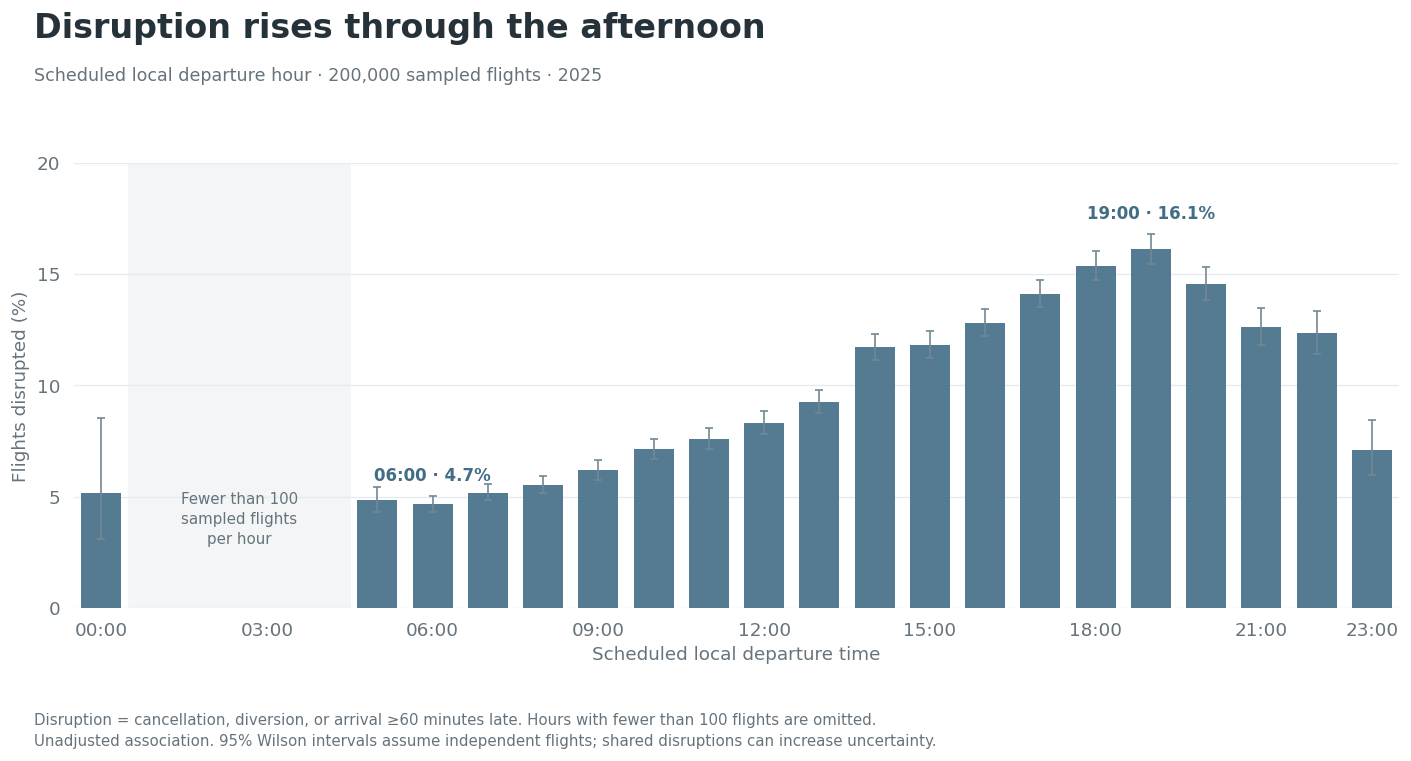

In [ ]:
hourly = reliability_table(flights, "departure_hour").reindex(range(24))
supported = hourly.n.ge(MIN_GROUP_N)
shown = hourly.loc[supported]

fig, ax = chart_frame(
    "Disruption rises through the afternoon",
    "Scheduled local departure hour · 200,000 sampled flights · 2025",
    "Disruption = cancellation, diversion, or arrival ≥60 minutes late. Hours with fewer than 100 flights are omitted.\n"
    "Unadjusted association. 95% Wilson intervals assume independent flights; shared disruptions can increase uncertainty.",
    figsize=(13, 7))

# Plot only supported hours. Gaps represent insufficient data, not zero risk.
ax.bar(shown.index, shown.risk * 100, width=0.72,
       color=BLUE, alpha=0.9, edgecolor="none", zorder=3)
ax.errorbar(
    shown.index, shown.risk * 100,
    yerr=np.vstack([(shown.risk - shown.lower) * 100,
                   (shown.upper - shown.risk) * 100]),
    fmt="none", ecolor="#738894", elinewidth=1,
    capsize=2.5, capthick=1, zorder=4)

# Explain the omitted overnight hours directly inside the gap.
if (~supported.loc[1:4]).all():
    ax.axvspan(0.5, 4.5, color="#F3F5F6", zorder=0)
    ax.text(2.5, 0.20,
            f"Fewer than {MIN_GROUP_N:,}\nsampled flights\nper hour",
            transform=ax.get_xaxis_transform(), ha="center", va="center",
            fontsize=9, color=MUTED, linespacing=1.4)

ax.grid(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set(xlim=(-0.5, 23.5), ylim=(0, 20),
       xlabel="Scheduled local departure time", ylabel="Flights disrupted (%)")
ax.set_yticks([0, 5, 10, 15, 20])
ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21, 23],
              ["00:00", "03:00", "06:00", "09:00", "12:00",
               "15:00", "18:00", "21:00", "23:00"])

for hour in [6, 19]:
    if supported.loc[hour]:
        ax.annotate(
            f"{hour:02d}:00 · {hourly.loc[hour, 'risk']:.1%}",
            (hour, hourly.loc[hour, "upper"] * 100),
            xytext=(0, 9), textcoords="offset points", ha="center",
            color=BLUE, fontsize=10, weight="bold")

save_chart(fig, "01_departure_hour")
save_table(hourly.rename_axis("local_departure_hour").reset_index(), "departure_hour")


**Interpretation:** disruption is lower in the early morning and rises into the evening, then falls at the latest hours. This is not a universal rule that every later flight is worse. The next comparison checks whether an early/late difference remains within comparable groups.


## 4 · Does the pattern remain among comparable flights?
Use the supplied monthly population. Compare **06:00–08:59** with **15:00–20:59** within directional route, operating carrier and month, requiring at least 20 flights in each window. Weight both window rates by the same combined flight count in each group.

The population includes the student sample. This expands coverage; it is not an independent holdout or a causal policy evaluation.


In [ ]:
# Validated appendix B: full-population comparison (chunked, may take minutes)
# Population contains sample. This is NOT an independent holdout.
assert "flights" in globals(), "Run preparation first"
population_parts = []
population_count = 0
population_carriers = {}
sample_flight_hashes = set(pd.util.hash_pandas_object(raw[flight_key], index=False))
found_sample_hashes = set()
for monthly_path in monthly_paths:
    for chunk in pd.read_csv(monthly_path, chunksize=200000, low_memory=False):
        population_count += len(chunk)
        for carrier, count in chunk.OP_UNIQUE_CARRIER.value_counts().items():
            population_carriers[carrier] = population_carriers.get(carrier, 0) + int(count)
        found_sample_hashes.update(set(pd.util.hash_pandas_object(chunk[flight_key], index=False)) & sample_flight_hashes)
        observed_times = chunk.CRS_DEP_TIME
        assert observed_times.notna().all() and (((observed_times.between(0,2359)) & observed_times.mod(100).lt(60) & observed_times.mod(1).eq(0)) | observed_times.eq(2400)).all()
        hour = (((chunk.CRS_DEP_TIME // 100)*60 + chunk.CRS_DEP_TIME % 100).where(chunk.CRS_DEP_TIME.ne(2400), 0) // 60).astype(int)
        chunk["window"] = np.select([hour.between(6, 8), hour.between(15, 20)], ["early", "late"], default="other")
        chunk["disruption"] = (chunk.CANCELLED.eq(1) | chunk.DIVERTED.eq(1) | chunk.ARR_DELAY.ge(MAJOR_DELAY_MINUTES)).astype(int)
        eligible = chunk[chunk.window.ne("other")]
        population_parts.append(eligible.groupby(["ORIGIN", "DEST", "OP_UNIQUE_CARRIER", "MONTH", "DAY_OF_WEEK", "window"]).disruption.agg(["size", "sum"]))

assert population_count == validation_report["population_records"]
assert population_carriers == validation_report["population_carriers"]
assert len(found_sample_hashes) == len(raw)
population_cells = pd.concat(population_parts).groupby(level=list(range(6))).sum()
population_comparisons = []
for label, levels, minimum in [("route/carrier", [0,1,2,5], 20), ("route/carrier/month", [0,1,2,3,5], 20), ("route/carrier/month/weekday", [0,1,2,3,4,5], 5)]:
    cells = population_cells.groupby(level=levels).sum().unstack("window").dropna()
    cells = cells[(cells["size"]["early"] >= minimum) & (cells["size"]["late"] >= minimum)]
    weights = cells["size"].sum(axis=1)
    early = np.average(cells["sum"]["early"] / cells["size"]["early"], weights=weights)
    late = np.average(cells["sum"]["late"] / cells["size"]["late"], weights=weights)
    population_comparisons.append({"adjustment": label, "strata": len(cells), "flights": int(weights.sum()), "coverage": weights.sum()/population_cells["size"].sum(), "early_risk": early, "late_risk": late, "gap_pp": 100*(late-early)})
validated_population_results = pd.DataFrame(population_comparisons)
primary_comparison = validated_population_results.loc[validated_population_results.adjustment.eq("route/carrier/month")].iloc[0]
check("Population control and sample membership", population_count == 6398056 and len(found_sample_hashes) == 200000)
check("Primary supported comparison reconciles", int(primary_comparison.flights) == 2227943 and np.isclose(primary_comparison.early_risk, .04936327813266333) and np.isclose(primary_comparison.late_risk, .14483519179775065))
save_table(validated_population_results, "population_comparisons")
print("PASS: population controls and sample membership screening. Descriptive standardized association, not causal switching benefit.")


PASS: population controls and sample membership screening. Descriptive standardized association, not causal switching benefit.


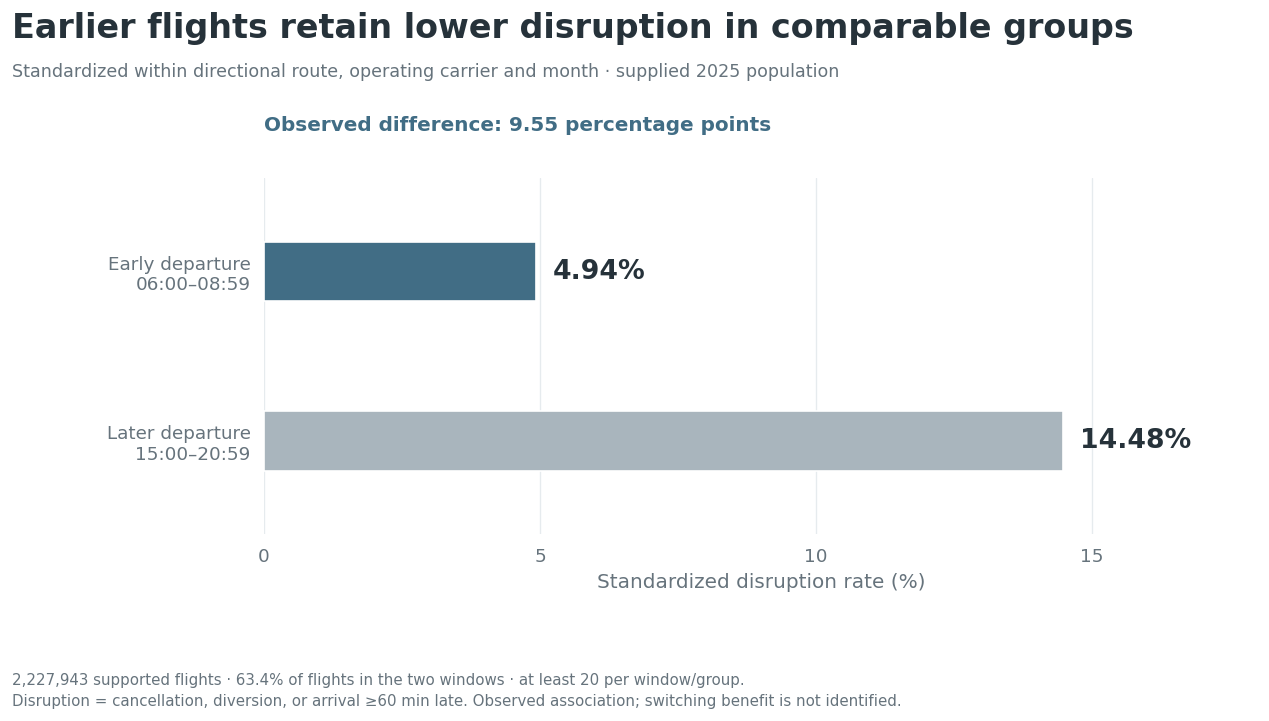

In [ ]:
p = primary_comparison
fig, ax = chart_frame(
    "Earlier flights retain lower disruption in comparable groups",
    "Standardized within directional route, operating carrier and month · supplied 2025 population",
    f"{int(p.flights):,} supported flights · {p.coverage:.1%} of flights in the two windows · at least 20 per window/group.\n"
    "Disruption = cancellation, diversion, or arrival ≥60 min late. Observed association; switching benefit is not identified.",
    rect=(.24,.28,.69,.45))
rates = np.array([p.early_risk, p.late_risk])*100
ax.grid(False); ax.grid(axis="x", color=GRID, linewidth=.8)
ax.barh([1,0], rates, height=.35, color=[BLUE,"#A9B5BD"])
ax.set_yticks([1,0], ["Early departure\n06:00–08:59", "Later departure\n15:00–20:59"])
ax.set(xlim=(0,18), ylim=(-.55,1.55), xlabel="Standardized disruption rate (%)")
ax.set_xticks([0,5,10,15])
for y, rate in zip([1,0], rates):
    ax.text(rate+.3, y, f"{rate:.2f}%", va="center", fontsize=16, weight="bold", color=INK)
fig.text(.24,.79,f"Observed difference: {p.gap_pp:.2f} percentage points", fontsize=12, color=BLUE, weight="bold")
save_chart(fig, "02_comparable_departures")


**Interpretation:** the lower early-flight rate remains after matching route, carrier and month composition. Adding weekday controls retains the direction (Appendix B), although the supported population changes. This supports offering earlier **feasible** options; it does not establish a guaranteed reduction for a particular booking. The unsupported 36.6% of early/late flights should not inherit the comparison automatically.


## 5 · How much delay exposure remains at different arrival allowances?
For each allowance, count cancellations, diversions, and arrivals **strictly more than** that many minutes late. The denominator stays all 200,000 scheduled flights. This is an observed delay-threshold curve, not a model of meeting attendance.


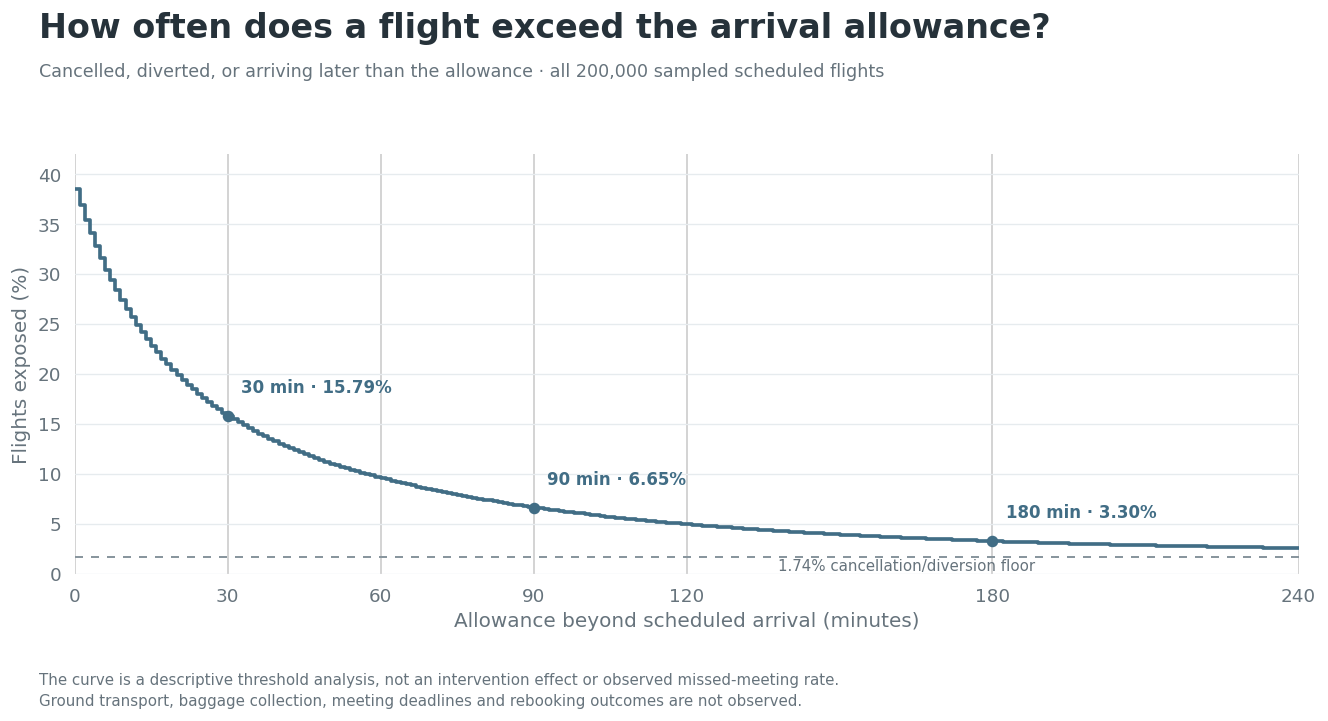

In [ ]:
buffers = np.arange(0,241)
buffer_risk = pd.DataFrame({"buffer_minutes": buffers, "risk": [(~ordinary | raw.ARR_DELAY.gt(b)).mean() for b in buffers]})
floor = (~ordinary).mean()
check("Buffer exposure decreases and retains exceptional flights", buffer_risk.risk.diff().dropna().le(0).all() and buffer_risk.risk.ge(floor).all())
check("Buffer reference rates reconcile", np.allclose(buffer_risk.set_index("buffer_minutes").loc[[30,90,180],"risk"], [.157855,.0665,.032965]))
fig, ax = chart_frame(
    "How often does a flight exceed the arrival allowance?",
    "Cancelled, diverted, or arriving later than the allowance · all 200,000 sampled scheduled flights",
    "The curve is a descriptive threshold analysis, not an intervention effect or observed missed-meeting rate.\n"
    "Ground transport, baggage collection, meeting deadlines and rebooking outcomes are not observed.")
ax.step(buffer_risk.buffer_minutes, buffer_risk.risk*100, where="post", color=BLUE, linewidth=2.2)
ax.axhline(floor*100, color="#89969E", linewidth=1.2, linestyle=(0,(4,4)))
ax.set(xlim=(0,240), ylim=(0,42), xlabel="Allowance beyond scheduled arrival (minutes)", ylabel="Flights exposed (%)")
ax.set_xticks([0,30,60,90,120,180,240])
for b in [30,90,180]:
    rate=buffer_risk.loc[buffer_risk.buffer_minutes.eq(b),"risk"].iloc[0]*100
    ax.scatter([b],[rate],color=BLUE,s=35,zorder=3)
    ax.annotate(f"{b} min · {rate:.2f}%", (b,rate), xytext=(8,14), textcoords="offset points", fontsize=10, color=BLUE, weight="bold")
ax.text(138,.35,f"{floor:.2%} cancellation/diversion floor",fontsize=9,color=MUTED)
save_chart(fig, "03_arrival_allowance")
save_table(buffer_risk, "arrival_allowance")


**Interpretation:** exposure is **15.79% at 30 minutes**, **6.65% at 90 minutes**, and **3.30% at 180 minutes**. Increasing the threshold mechanically includes fewer delayed arrivals; the shape shows diminishing reductions in this descriptive exposure measure.

The **1.74% cancellation/diversion floor** remains at every threshold because those flights are always counted. It is not an irreducible real-world meeting-failure rate: rebooking or recovery could change a traveler's outcome, and those outcomes are absent.

**Business use:** discuss arrival timing alongside meeting importance and ground-transfer requirements. These thresholds are reference points, not optimized buffer tiers. A 60-minute buffer counts delays **>60**, while the primary disruption outcome counts delays **≥60**; the rates therefore differ slightly by design.


## 6 · What the models add
Appendix F explains and evaluates the schedule-only models; Appendix G tests supporting K-means/Isolation Forest signals, which did not earn inclusion in the risk score. Appendix C preserves the earlier chronological study.

**Appendix I now evaluates observed weather on matched, weather-key-separated data.** Both-weather boosting was selected on development Brier. Its assessment Brier is **0.07917**, versus **0.08473** for the paired schedule-only boosting comparator; whole-week sensitivity retains the gain. These results use a different cohort from F/G.

The weather model is a candidate for the historical replay. Appendix J completed development-only calibration: unchanged probabilities had the lowest development and assessment Brier (0.07917 assessment), so neither sigmoid nor isotonic is adopted. Appendix K completes the Boston → Chicago transfer and technical audit. Prediction/ranking screens pass for historical replay; calibration and exact-score stability remain limitations. The private interface remains pending. Daily observed weather is not a booking-time forecast; no live-flight readiness, causal switching benefit or financial saving is established. Appendix H tracks the MVP architecture, and I gives the source-backed results.


## 7 · Business recommendations supported by the data

The results support the following priorities for a corporate travel manager. These are proposals to test against actual booking constraints. Observed flight associations do not establish the benefit of switching an individual booking or the financial return from a policy.

### 1. Offer earlier departures when suitable options exist

- **Evidence:** in the supplied population, disruption was **4.94% for 06:00–08:59 departures** versus **14.48% for 15:00–20:59 departures**, standardized within directional route, operating carrier and month. The comparison covers **2,227,943 flights**, or **63.4% of flights in those two windows**, with at least 20 flights in each window per group. Adding weekday controls retains the direction of the association. See **Section 4 and Appendix B**.
- **Proposed action:** make earlier departures visible among feasible options on supported routes, while respecting arrival deadlines, fares, traveler schedules and overnight requirements.
- **Limit:** the 9.55-percentage-point difference is an observed association. It is not a guaranteed reduction from changing a booking; actual alternative availability and all sources of confounding are not observed.

### 2. Use delay exposure to inform arrival-buffer discussions

- **Evidence:** among all **200,000 sampled scheduled flights**, **15.79%** were cancelled, diverted, or arrived more than **30 minutes** late. At a **90-minute** threshold, the share was **6.65%**; at **180 minutes**, **3.30%**. These are observed outcome frequencies at selected thresholds. See the **arrival-buffer chart and its interpretation** above.
- **Proposed action:** consider the consequences of a late arrival when choosing flight timing for a time-sensitive meeting. Include ground-transfer time and baggage collection in the actual itinerary plan.
- **Limit:** the data does not identify an optimal buffer or the probability of missing a meeting. Cancellations and diversions remain counted at every threshold; recovery and rebooking are not modeled.

### 3. Measure feasibility and outcomes before adopting a client policy

- **Evidence:** the dataset records flight performance but does not contain actual booking alternatives, client meeting deadlines, fares, or disruption costs. The predictive model also has calibration and subgroup limitations, documented in **Appendix C**.
- **Proposed action:** pilot the earlier-option and buffer approach on a defined set of client routes. Record which trips have feasible alternatives, which offers travelers accept, and whether travelers reach their actual meeting deadlines.
- **Measure:** eligible trips, offer acceptance, flight disruption, arrival before the meeting deadline, actual incremental airfare/hotel costs, rebooking expense, and traveler satisfaction. Use a predefined comparison design before attributing changes to the policy.
- **Limit:** the current evidence does not establish dollar savings, a justified fare premium, or readiness for automated booking decisions.

**Decision:** prioritize feasible scheduling choices and measurement of actual travel outcomes. Any financial assessment requires observed client costs and a defensible estimate of the policy's effect.

*Definitions and scope: the early/late comparison uses cancellation, diversion, or arrival delay ≥60 minutes. The buffer analysis uses arrival delay strictly greater than each buffer, plus cancellations and diversions. The supplied population covers selected 2025 operating carriers and includes the student sample; it is not an independent holdout.*


# Supporting appendix
Keep this evidence for review and reproducibility. The three main charts and recommendations above form the business narrative. Run the appendix sections individually when inspecting their supporting questions.


## Appendix A · Inventory, dictionary and quality details
The source-file checks and essential preparation gates ran before the main analysis. This section retains the column-learning work and detailed exceptions. Negative delays, extreme delays and structural nulls are preserved. The four timing cases remain unresolved source issues.


In [ ]:
display(inventory)
column_inventory = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(), "distinct": raw.nunique()}).rename_axis("column")
display(column_inventory)
display(data_dictionary)
display(raw.loc[flights.timing_issue, flight_key + ["DEP_DELAY","ARR_DELAY","CRS_ELAPSED_TIME","ACTUAL_ELAPSED_TIME"]])
save_table(column_inventory.reset_index(), "column_inventory")
save_table(raw.loc[flights.timing_issue], "timing_cases")


,file,status
0,CLAUDE.md,VERIFIED
1,Flight Connection Assumptions.html,VERIFIED
2,Questrom_Chart_Champs_Revised_Brief.pdf,VERIFIED
3,README.txt,VERIFIED
4,data_dictionary.csv,VERIFIED
5,2025_01.csv,VERIFIED
6,2025_02.csv,VERIFIED
7,2025_03.csv,VERIFIED
8,2025_04.csv,VERIFIED
9,2025_05.csv,VERIFIED


,dtype,missing,distinct
column,,,
YEAR,int64,0,1
QUARTER,int64,0,4
MONTH,int64,0,12
DAY_OF_MONTH,int64,0,31
DAY_OF_WEEK,int64,0,7
FL_DATE,object,0,365
OP_UNIQUE_CARRIER,object,0,10
OP_CARRIER,object,0,10
OP_CARRIER_FL_NUM,int64,0,6398


,column,description
0,YEAR,Year
1,QUARTER,Quarter
2,MONTH,Month
3,DAY_OF_MONTH,Day Of Month
4,DAY_OF_WEEK,Day Of Week
5,FL_DATE,Fl Date
6,OP_UNIQUE_CARRIER,Op Unique Carrier
7,OP_CARRIER,Op Carrier
8,OP_CARRIER_FL_NUM,Op Carrier Fl Num
9,TAIL_NUM,Tail Num


,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,ARR_DELAY,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME
32128,2025-03-08,DL,872,LGA,MIA,1805,-3.0,-32.0,265.0,176.0
111816,2025-09-16,YX,5628,LGA,PIT,1630,12.0,-59.0,99.0,78.0
135019,2025-09-25,YX,5750,MEM,LGA,1109,406.0,333.0,165.0,163.0
175830,2025-05-06,DL,798,JFK,PHX,1615,247.0,204.0,352.0,307.0


In [ ]:
# Step 1: Understand the calendar columns (read-only inspection)
# One row is one scheduled flight leg on a particular date.
# DAY_OF_WEEK: Monday = 1, ..., Sunday = 7.

calendar_columns = [
    "FL_DATE", "YEAR", "QUARTER",
    "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK"
]

display(raw[calendar_columns].head(10))

print("How pandas currently stores these columns:")
display(raw[calendar_columns].dtypes.to_frame("dtype"))

print("Distinct values in the calendar fields:")
for column in calendar_columns[1:]:
    print(column, sorted(raw[column].dropna().unique().tolist()))


,FL_DATE,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK
0,2025-02-25,2025,1,2,25,2
1,2025-08-20,2025,3,8,20,3
2,2025-11-24,2025,4,11,24,1
3,2025-10-07,2025,4,10,7,2
4,2025-08-27,2025,3,8,27,3
5,2025-06-28,2025,2,6,28,6
6,2025-03-29,2025,1,3,29,6
7,2025-06-01,2025,2,6,1,7
8,2025-06-12,2025,2,6,12,4
9,2025-01-06,2025,1,1,6,1


How pandas currently stores these columns:


,dtype
FL_DATE,object
YEAR,int64
QUARTER,int64
MONTH,int64
DAY_OF_MONTH,int64
DAY_OF_WEEK,int64


Distinct values in the calendar fields:
YEAR [2025]
QUARTER [1, 2, 3, 4]
MONTH [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
DAY_OF_MONTH [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]
DAY_OF_WEEK [1, 2, 3, 4, 5, 6, 7]


In [ ]:
# Stage 2: Airline, flight number, and aircraft identifiers
# Question: which entity does each code identify? No raw values are changed.
identifier_columns = ["OP_UNIQUE_CARRIER", "OP_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM"]
print("Source dictionary labels (brief labels, not complete definitions):")
display(data_dictionary.loc[data_dictionary["column"].isin(identifier_columns)])
print("Examples: one row is a scheduled flight leg on a date")
display(raw[["FL_DATE"] + identifier_columns].head(10))
identifier_summary = pd.DataFrame({
    "dtype": raw[identifier_columns].dtypes.astype(str),
    "distinct_nonmissing": raw[identifier_columns].nunique(),
    "missing_rows": raw[identifier_columns].isna().sum(),
    "missing_pct": raw[identifier_columns].isna().mean().mul(100).round(3)
})
print("Column inventory:")
print(identifier_summary.to_string())
print("\nObserved carrier-code pairs:")
print(raw.groupby(["OP_UNIQUE_CARRIER", "OP_CARRIER"], dropna=False).size().rename("sample_flights").to_string())
print("\nTail-number missingness by cancellation flag (counts only):")
print(pd.crosstab(raw["CANCELLED"], raw["TAIL_NUM"].isna(), dropna=False).rename(columns={False: "tail_present", True: "tail_missing"}).to_string())
print("\nInterpretation checkpoint:")
print("Carrier codes identify airlines; flight numbers are labels, not measured quantities.")
print("A tail number identifies an aircraft, which can operate many flights.")
print("Do not drop missing tails or treat a flight number as a unique flight key.")
print("Review these results together before the next column group.")


Source dictionary labels (brief labels, not complete definitions):


,column,description
6,OP_UNIQUE_CARRIER,Op Unique Carrier
7,OP_CARRIER,Op Carrier
8,OP_CARRIER_FL_NUM,Op Carrier Fl Num
9,TAIL_NUM,Tail Num


Examples: one row is a scheduled flight leg on a date


,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER,OP_CARRIER_FL_NUM,TAIL_NUM
0,2025-02-25,UA,UA,648,N14118
1,2025-08-20,AA,AA,2257,N845NN
2,2025-11-24,DL,DL,1052,N321DH
3,2025-10-07,MQ,MQ,3907,N217NN
4,2025-08-27,OH,OH,5555,N703PS
5,2025-06-28,UA,UA,491,N27519
6,2025-03-29,WN,WN,1851,N232WN
7,2025-06-01,AA,AA,677,N771XF
8,2025-06-12,AA,AA,3104,N914UY
9,2025-01-06,AA,AA,2840,N673AW


Column inventory:
                    dtype  distinct_nonmissing  missing_rows  missing_pct
OP_UNIQUE_CARRIER  object                   10             0        0.000
OP_CARRIER         object                   10             0        0.000
OP_CARRIER_FL_NUM   int64                 6398             0        0.000
TAIL_NUM           object                 5412           248        0.124

Observed carrier-code pairs:
OP_UNIQUE_CARRIER  OP_CARRIER
AA                 AA            30271
AS                 AS             7717
B6                 B6             7333
DL                 DL            32059
MQ                 MQ             9384
OH                 OH             7890
OO                 OO            26102
UA                 UA            24950
WN                 WN            43668
YX                 YX            10626

Tail-number missingness by cancellation flag (counts only):
TAIL_NUM   tail_present  tail_missing
CANCELLED                            
0.0              197093  

In [ ]:
origin_mapping = raw[["ORIGIN","ORIGIN_CITY_NAME","ORIGIN_STATE_ABR"]].rename(columns={"ORIGIN":"airport_code","ORIGIN_CITY_NAME":"city","ORIGIN_STATE_ABR":"state"})
dest_mapping = raw[["DEST","DEST_CITY_NAME","DEST_STATE_ABR"]].rename(columns={"DEST":"airport_code","DEST_CITY_NAME":"city","DEST_STATE_ABR":"state"})
airports_df = pd.concat([origin_mapping,dest_mapping]).drop_duplicates().sort_values("airport_code")
check("Airport registry is unambiguous", airports_df.airport_code.is_unique and len(airports_df)==327)
print(f"{len(airports_df)} airports; full registry exported. First ten shown.")
display(airports_df.head(10))
save_table(airports_df, "airport_registry")


327 airports; full registry exported. First ten shown.


,airport_code,city,state
2483,ABE,"Allentown/Bethlehem/Easton, PA",PA
2639,ABI,"Abilene, TX",TX
403,ABQ,"Albuquerque, NM",NM
1927,ABR,"Aberdeen, SD",SD
7891,ABY,"Albany, GA",GA
498,ACK,"Nantucket, MA",MA
3019,ACT,"Waco, TX",TX
12108,ACV,"Arcata/Eureka, CA",CA
110327,ADK,"Adak Island, AK",AK
444,ADQ,"Kodiak, AK",AK


## Appendix B · Supporting EDA and robustness
**Working note retained: “Early is less risky.”** The evidence supports a lower observed rate in the supported early window; it does not establish a causal switching benefit.

The heatmap describes variation within 2025. The carrier chart is unadjusted and cannot justify switching carriers. The robustness table shows how results and coverage change with comparison support and adjustment.


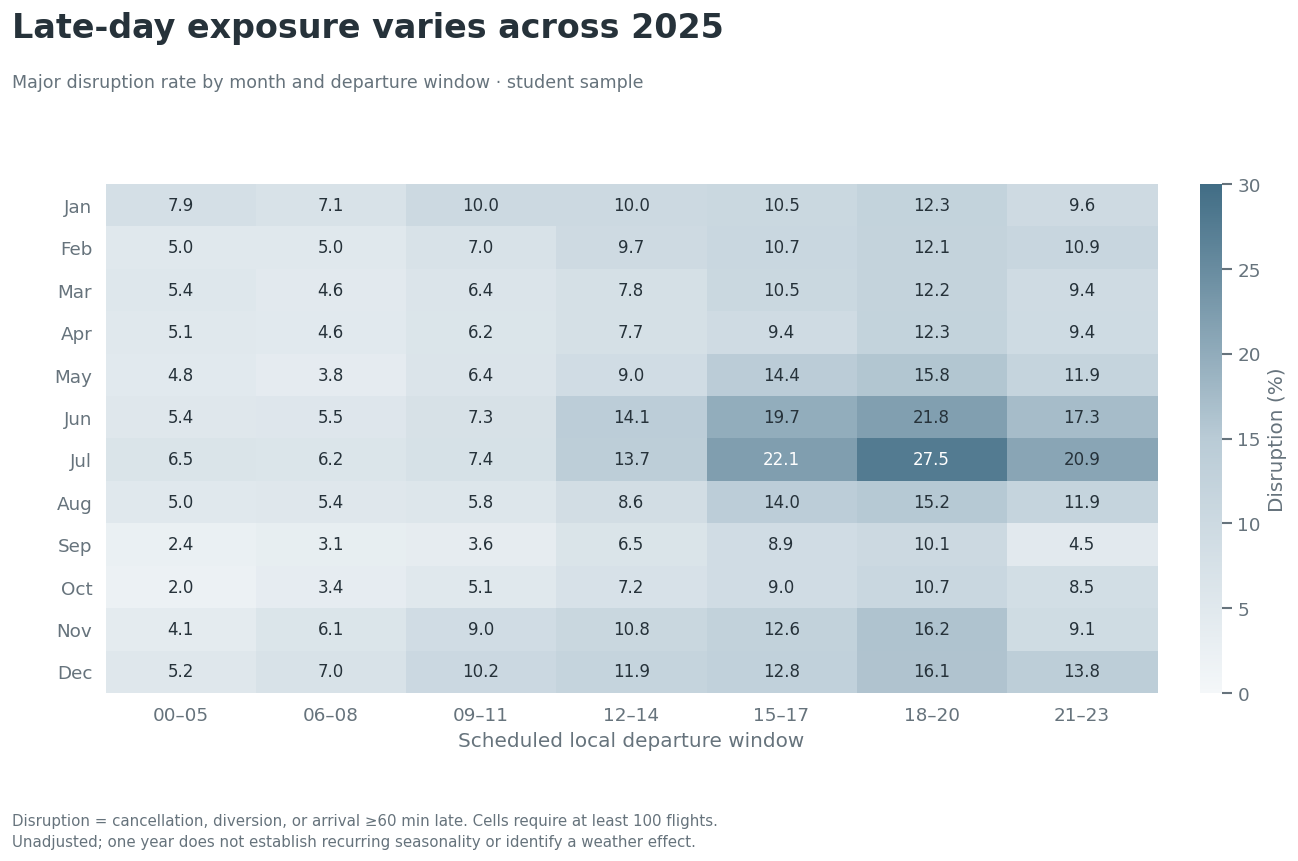

In [ ]:
heat = flights.groupby(["MONTH","departure_window"],observed=True).major_disruption.agg(n="size",risk="mean")
rates = heat.risk.where(heat.n.ge(MIN_GROUP_N)).unstack()*100
fig, ax = chart_frame("Late-day exposure varies across 2025",
    "Major disruption rate by month and departure window · student sample",
    "Disruption = cancellation, diversion, or arrival ≥60 min late. Cells require at least 100 flights.\n"
    "Unadjusted; one year does not establish recurring seasonality or identify a weather effect.",
    figsize=(12,8),rect=(.13,.23,.73,.53))
cmap=LinearSegmentedColormap.from_list("restrained_blue",["#F4F7F9","#B9CBD6","#416D85"])
im=ax.imshow(rates.to_numpy(),cmap=cmap,vmin=0,vmax=30,aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(rates.columns)),rates.columns)
ax.set_yticks(range(12),[calendar.month_abbr[m] for m in rates.index])
ax.set_xlabel("Scheduled local departure window")
for r in range(rates.shape[0]):
    for c in range(rates.shape[1]):
        value=rates.iloc[r,c]
        if pd.notna(value): ax.text(c,r,f"{value:.1f}",ha="center",va="center",fontsize=10,color="white" if value>=22 else INK)
cax=fig.add_axes([.89,.23,.015,.53]); cb=fig.colorbar(im,cax=cax);cb.set_label("Disruption (%)");cb.outline.set_visible(False)
save_chart(fig,"appendix_month_time")
save_table(heat.reset_index(),"month_time")


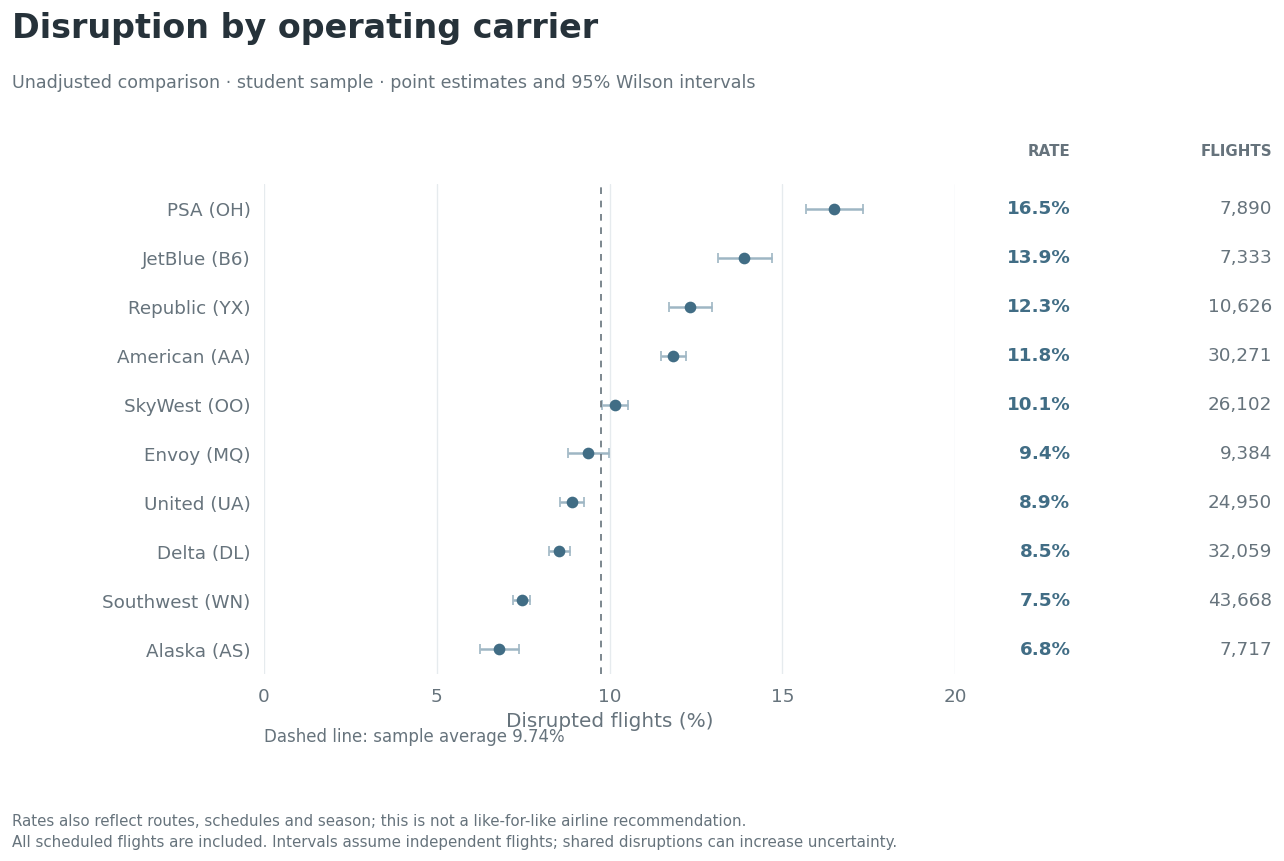

In [ ]:
carrier_names = {"AA":"American","AS":"Alaska","B6":"JetBlue","DL":"Delta","MQ":"Envoy",
                 "OH":"PSA","OO":"SkyWest","UA":"United","WN":"Southwest","YX":"Republic"}
carriers = reliability_table(flights,"OP_UNIQUE_CARRIER").sort_values("risk",ascending=False)
fig, ax = chart_frame("Disruption by operating carrier",
    "Unadjusted comparison · student sample · point estimates and 95% Wilson intervals",
    "Rates also reflect routes, schedules and season; this is not a like-for-like airline recommendation.\n"
    "All scheduled flights are included. Intervals assume independent flights; shared disruptions can increase uncertainty.",
    figsize=(12,8),rect=(.24,.25,.48,.51))
ax.grid(False);ax.grid(axis="x",color=GRID,linewidth=.8)
rows=np.arange(len(carriers))
ax.errorbar(carriers.risk*100,rows,xerr=np.vstack([(carriers.risk-carriers.lower)*100,(carriers.upper-carriers.risk)*100]),
    fmt="o",color=BLUE,ecolor="#9EB6C4",capsize=3,markersize=6)
ax.axvline(flights.major_disruption.mean()*100,color=MUTED,linestyle=(0,(4,4)),linewidth=1)
ax.set_yticks(rows,[f"{carrier_names.get(k,k)} ({k})" for k in carriers.index])
ax.set(xlim=(0,20),ylim=(len(carriers)-.5,-.5),xlabel="Disrupted flights (%)")
ax.set_xticks([0,5,10,15,20])
fig.text(.80,.79,"RATE",color=MUTED,fontsize=9,ha="right",weight="bold")
fig.text(.94,.79,"FLIGHTS",color=MUTED,fontsize=9,ha="right",weight="bold")
for j,(_,row) in enumerate(carriers.iterrows()):
    yy=.25+.51*(1-(j+.5)/len(carriers))
    fig.text(.80,yy,f"{row.risk:.1%}",ha="right",va="center",color=BLUE,weight="bold")
    fig.text(.94,yy,f"{int(row.n):,}",ha="right",va="center",color=MUTED)
fig.text(.24,.18,f"Dashed line: sample average {flights.major_disruption.mean():.2%}",fontsize=10,color=MUTED)
save_chart(fig,"appendix_carriers")
save_table(carriers.reset_index(),"carrier_summary")


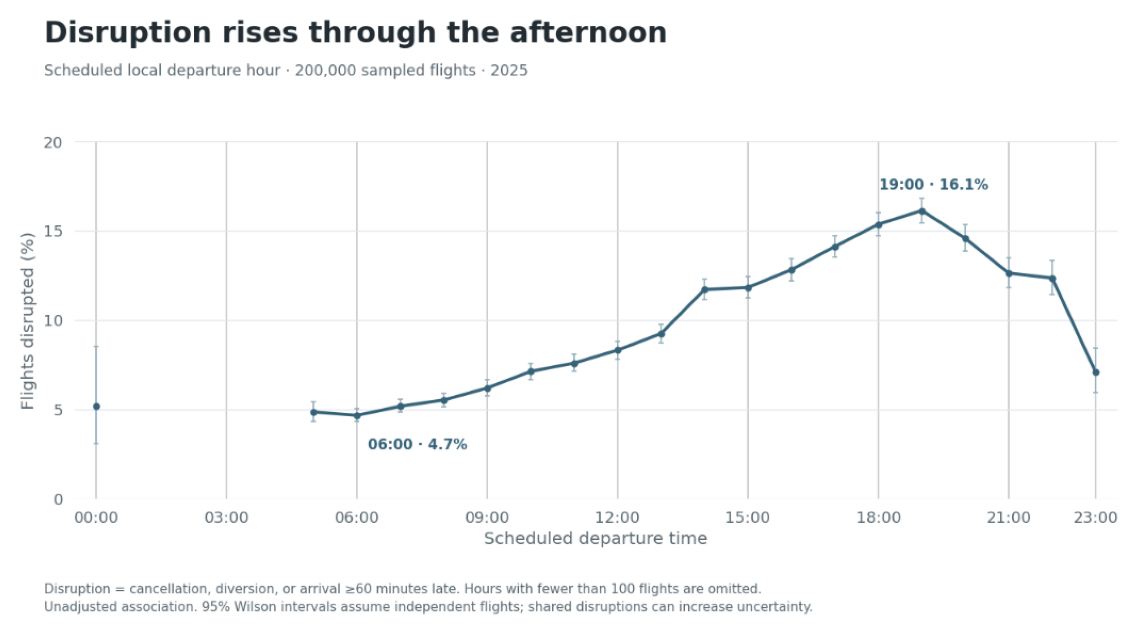

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Load and display the user's selected screenshot
img_path = '/content/Screenshot 2026-11-06 at 10.40.37 PM.png'
try:
    img = Image.open(img_path)
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
except Exception as e:
    print(f"Error displaying image: {e}")

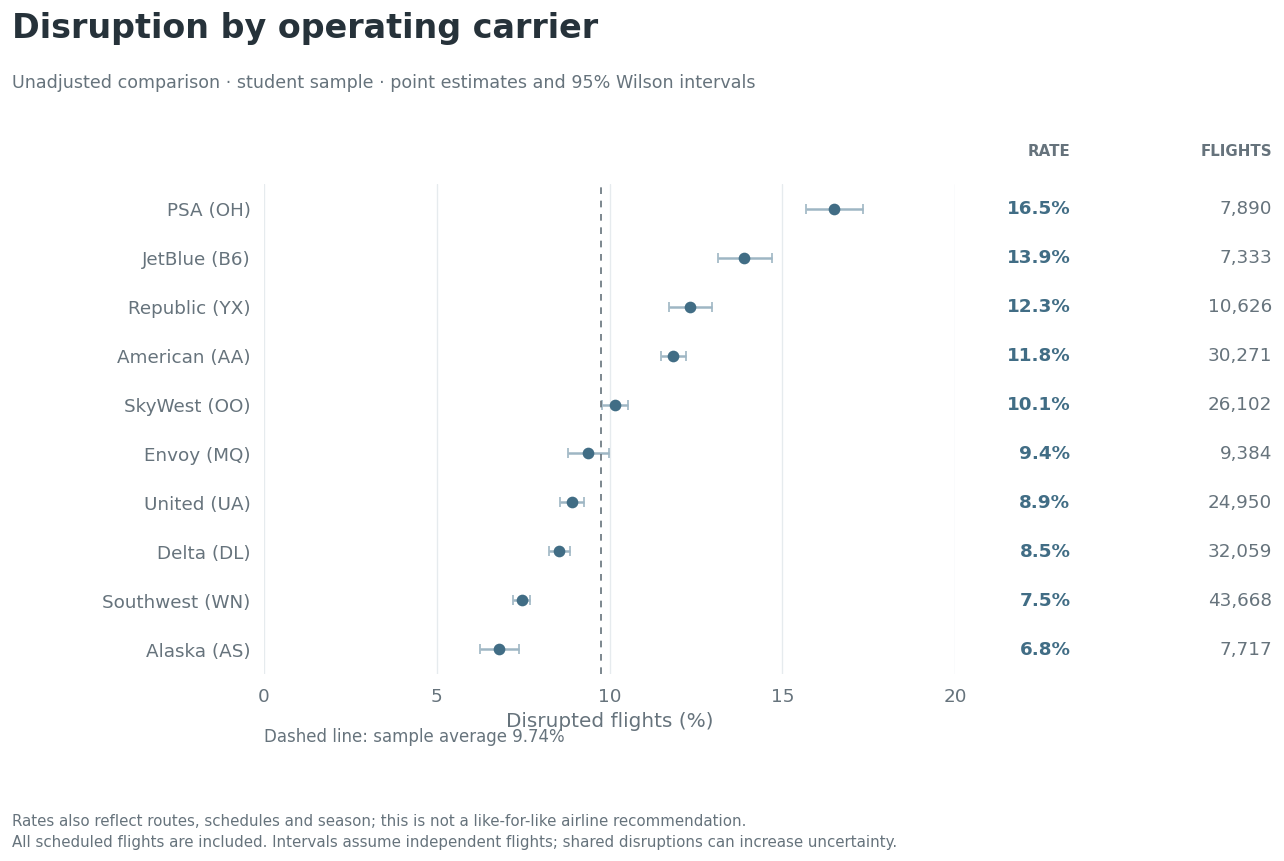

In [ ]:
# Disruption by operating carrier horizontal error-bar chart
carriers = reliability_table(flights, "OP_UNIQUE_CARRIER").sort_values("risk", ascending=False)
fig, ax = chart_frame(
    "Disruption by operating carrier",
    "Unadjusted comparison · student sample · point estimates and 95% Wilson intervals",
    "Rates also reflect routes, schedules and season; this is not a like-for-like airline recommendation.\n"
    "All scheduled flights are included. Intervals assume independent flights; shared disruptions can increase uncertainty.",
    figsize=(12, 8),
    rect=(0.24, 0.25, 0.48, 0.51)
)

ax.grid(False)
ax.grid(axis="x", color=GRID, linewidth=0.8)
rows = np.arange(len(carriers))

ax.errorbar(
    carriers.risk * 100,
    rows,
    xerr=np.vstack([(carriers.risk - carriers.lower) * 100, (carriers.upper - carriers.risk) * 100]),
    fmt="o",
    color=BLUE,
    ecolor="#9EB6C4",
    capsize=3,
    markersize=6
)

ax.axvline(flights.major_disruption.mean() * 100, color=MUTED, linestyle=(0, (4, 4)), linewidth=1)
ax.set_yticks(rows, [f"{carrier_names.get(k, k)} ({k})" for k in carriers.index])
ax.set(xlim=(0, 20), ylim=(len(carriers) - 0.5, -0.5), xlabel="Disrupted flights (%)")
ax.set_xticks([0, 5, 10, 15, 20])

fig.text(0.80, 0.79, "RATE", color=MUTED, fontsize=9, ha="right", weight="bold")
fig.text(0.94, 0.79, "FLIGHTS", color=MUTED, fontsize=9, ha="right", weight="bold")

for j, (_, row) in enumerate(carriers.iterrows()):
    yy = 0.25 + 0.51 * (1 - (j + 0.5) / len(carriers))
    fig.text(0.80, yy, f"{row.risk:.1%}", ha="right", va="center", color=BLUE, weight="bold")
    fig.text(0.94, yy, f"{int(row.n):,}", ha="right", va="center", color=MUTED)

fig.text(0.24, 0.18, f"Dashed line: sample average {flights.major_disruption.mean():.2%}", fontsize=10, color=MUTED)

save_chart(fig, "appendix_carriers")
save_table(carriers.reset_index(), "carrier_summary")

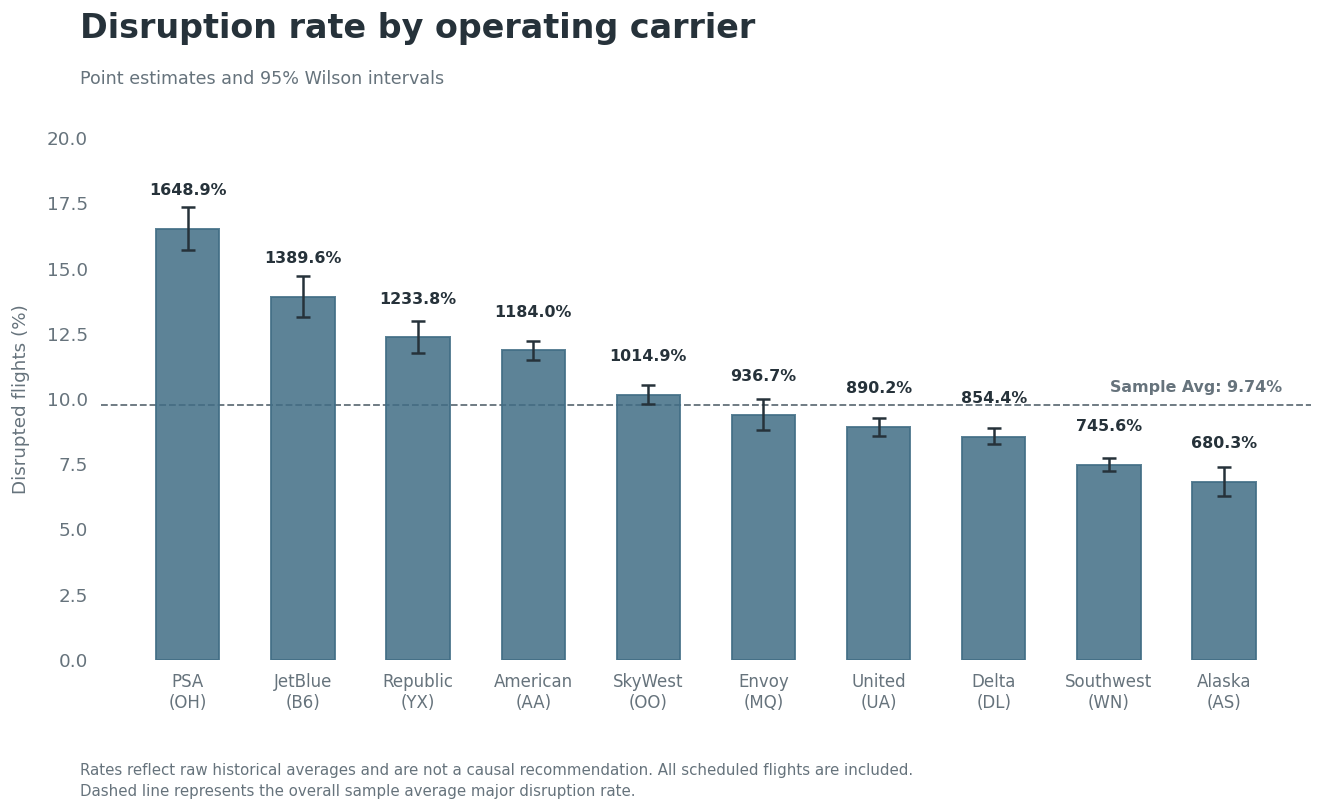

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Re-extract carrier metrics sorted by risk rate
carriers_df = reliability_table(flights, "OP_UNIQUE_CARRIER").sort_values("risk", ascending=False)

# Set up the custom figure structure
fig, ax = chart_frame(
    "Disruption rate by operating carrier",
    "Point estimates and 95% Wilson intervals",
    "Rates reflect raw historical averages and are not a causal recommendation. All scheduled flights are included.\nDashed line represents the overall sample average major disruption rate.",
    figsize=(12, 7.5),
    rect=(0.08, 0.22, 0.84, 0.58)
)

# Remove all background grid lines
ax.grid(False)

# Calculate error parameters for vertical bars
x_positions = np.arange(len(carriers_df))
y_values = carriers_df.risk * 100
y_errors = np.vstack([
    (carriers_df.risk - carriers_df.lower) * 100,
    (carriers_df.upper - carriers_df.risk) * 100
])

# Draw bars and overlay Wilson interval error caps
ax.bar(x_positions, y_values, color=BLUE, alpha=0.85, width=0.55, edgecolor=BLUE, linewidth=1.2, zorder=2)
ax.errorbar(
    x_positions, y_values, yerr=y_errors,
    fmt="none", ecolor=INK, elinewidth=1.5, capsize=4, capthick=1.5, zorder=3
)

# Draw sample average horizontal reference line
sample_avg = flights.major_disruption.mean() * 100
ax.axhline(sample_avg, color=MUTED, linestyle="--", linewidth=1.1, zorder=1)

# Set labels, ticks and titles
ax.set_xticks(x_positions)
ax.set_xticklabels([f"{carrier_names.get(k, k)}\n({k})" for k in carriers_df.index], fontsize=10)
ax.set_ylabel("Disrupted flights (%)", fontsize=11, labelpad=10)
ax.set_ylim(0, 20)

# Annotate the rates on top of each bar
for idx, rate in enumerate(y_values):
    ax.text(idx, rate + 1.2, f"{rate:.1%}", ha="center", va="bottom", color=INK, weight="bold", fontsize=9.5)

# Add annotation for sample average reference line
ax.text(len(carriers_df) - 0.5, sample_avg + 0.4, f"Sample Avg: {flights.major_disruption.mean():.2%}",
        color=MUTED, ha="right", va="bottom", fontsize=9.5, weight="bold")

save_chart(fig, "carrier_disruption_vertical_bars")
save_table(carriers_df.reset_index(), "carrier_disruption_bars")

In [ ]:
eligible = flights[flights.window.ne("other")]
matched = eligible.groupby(["route","OP_UNIQUE_CARRIER","window"]).major_disruption.agg(["mean","size"]).unstack("window").dropna()
matched = matched[(matched["size"]["early"]>=20)&(matched["size"]["late"]>=20)]
weights=matched["size"].sum(axis=1)
sample_early=np.average(matched["mean"]["early"],weights=weights)
sample_late=np.average(matched["mean"]["late"],weights=weights)
sample_comparison=pd.DataFrame([{"adjustment":"Sample route/carrier", "flights":int(weights.sum()),
    "coverage":weights.sum()/len(eligible),"early_risk":sample_early,"late_risk":sample_late,"gap_pp":100*(sample_late-sample_early)}])
display(sample_comparison.round(4))
display(validated_population_results.round(4))
sensitivity=[]
for threshold in [15,30,60,120]:
    for quarter in [1,2,3,4]:
        sub=flights[flights.QUARTER.eq(quarter)&flights.window.ne("other")]
        means=sub.groupby("window")[f"disruption_{threshold}"].mean()
        sensitivity.append({"threshold_minutes":threshold,"quarter":quarter,"early":means["early"],"late":means["late"]})
sensitivity=pd.DataFrame(sensitivity)
check("Early/late direction across thresholds and quarters", sensitivity.early.lt(sensitivity.late).all())
without_timing=flights[~flights.timing_issue & flights.window.ne("other")].groupby("window").major_disruption.mean()
check("Timing-case exclusion retains raw comparison direction", without_timing["early"]<without_timing["late"])
display(sensitivity.round(4))
print("Threshold/quarter checks are unadjusted. Population adjustment rows cover different supported groups.")
save_table(sample_comparison,"sample_matched_comparison")
save_table(sensitivity,"threshold_quarter_sensitivity")


,adjustment,flights,coverage,early_risk,late_risk,gap_pp
0,Sample route/carrier,14140,0.1286,0.0513,0.1563,10.4967


,adjustment,strata,flights,coverage,early_risk,late_risk,gap_pp
0,route/carrier,4458,2954665,0.8409,0.0506,0.1429,9.2289
1,route/carrier/month,25761,2227943,0.6340,0.0494,0.1448,9.5472
2,route/carrier/month/weekday,75169,1231579,0.3505,0.0489,0.1492,10.0260


,threshold_minutes,quarter,early,late
0,15,1,0.1488,0.2678
1,15,2,0.1258,0.3511
2,15,3,0.1190,0.3626
3,15,4,0.1403,0.3097
4,30,1,0.0936,0.1897
5,30,2,0.0778,0.2555
6,30,3,0.0749,0.2617
7,30,4,0.0878,0.2138
8,60,1,0.0555,0.1134
9,60,2,0.0464,0.1559


Threshold/quarter checks are unadjusted. Population adjustment rows cover different supported groups.


## Appendix C · Logistic regression and model comparison
**Question:** can scheduled information help prioritize review? Train January–August, select on September Brier score, then evaluate Q4 retrospectively. Preprocessing is fitted on training rows only. Q4 was already explored and is not untouched.

Compare a prevalence baseline, logistic schedule model, logistic model with year cycles, and bounded random forest. This preserves the earlier chronological study; the earlier categorical-hour logistic demonstration is archived in the pre-cleanup notebook backup.

**Allowed inputs:** operating carrier, origin, destination, weekday, distance, scheduled elapsed time, and scheduled clock cycles. Year cycles are tested only in the named candidate. Exclude actual times/durations, delays, outcomes, causes, aircraft assignment, missing-tail flags, timing-quality flags and observed weather. Recorded schedules remain availability proxies, not verified booking-time snapshots. No model is a causal switching simulator.


In [ ]:
# Validated appendix C: predeclared model comparison, not production scoring
# Select on September Brier; Q4 is retrospective because already explored.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score
assert "flights" in globals()
vcategorical = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "DAY_OF_WEEK"]
vnumeric = ["DISTANCE", "CRS_ELAPSED_TIME", "departure_sin", "departure_cos", "arrival_sin", "arrival_cos"]
vtrain = flights.date.lt("2025-09-01")
vselection = flights.date.between("2025-09-01", "2025-09-30")
vtest = flights.date.ge("2025-10-01")
assert ((vtrain.astype(int) + vselection + vtest) == 1).all()
vmodels, vmetrics = {}, []
def vscore(name, split, y, probability):
    return {"model": name, "split": split, "n": len(y), "prevalence": y.mean(), "Brier": brier_score_loss(y, probability), "AP": average_precision_score(y, probability), "ROC_AUC": roc_auc_score(y, probability)}
for name, seasonal, forest in [("logistic_schedule", False, False), ("logistic_cyclical", True, False), ("forest_schedule", False, True)]:
    numeric = vnumeric + (["year_sin", "year_cos"] if seasonal else [])
    features = vcategorical + numeric
    forbidden = {"ARR_DELAY", "ARR_DELAY_NEW", "DEP_DELAY", "DEP_DELAY_NEW", "CANCELLED", "DIVERTED", "CANCELLATION_CODE", "TAIL_NUM", "DEP_TIME", "ARR_TIME", "ACTUAL_ELAPSED_TIME", "AIR_TIME", "major_disruption", "timing_issue", *cause_cols}
    assert not set(features) & forbidden and not any(f.startswith(("disruption_", "actual_", "snow", "precip", "weather")) for f in features)
    pre = ColumnTransformer([("categorical", OneHotEncoder(handle_unknown="ignore"), vcategorical), ("numeric", StandardScaler(), numeric)])
    estimator = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50, n_jobs=2, random_state=64) if forest else LogisticRegression(C=1, max_iter=700, solver="lbfgs")
    fitted = Pipeline([("prepare", pre), ("model", estimator)])
    fitted.fit(flights.loc[vtrain, features], flights.loc[vtrain, "disruption_60"])
    if not forest:
        assert fitted.named_steps["model"].n_iter_.max() < 700
    probability = fitted.predict_proba(flights.loc[vselection, features])[:, 1]
    vmetrics.append(vscore(name, "September selection", flights.loc[vselection, "disruption_60"], probability))
    vmodels[name] = (fitted, features)
    print("Completed", name)
vprior = flights.loc[vtrain, "disruption_60"].mean()
vmetrics.append(vscore("prevalence_baseline", "September selection", flights.loc[vselection, "disruption_60"], np.full(vselection.sum(), vprior)))
vwinner = min(vmetrics, key=lambda row: row["Brier"])["model"]
if vwinner == "prevalence_baseline":
    vprobability = np.full(vtest.sum(), vprior)
else:
    chosen, features = vmodels[vwinner]
    vprobability = chosen.predict_proba(flights.loc[vtest, features])[:, 1]
assert np.isfinite(vprobability).all()
vmetrics.append(vscore(vwinner, "Q4 retrospective", flights.loc[vtest, "disruption_60"], vprobability))
vmetrics.append(vscore("prevalence_baseline", "Q4 retrospective", flights.loc[vtest, "disruption_60"], np.full(vtest.sum(), vprior)))
model_results = pd.DataFrame(vmetrics)
print(model_results.to_string(index=False))
vtest_rows = flights.loc[vtest].copy()
vtest_rows["risk_score"] = vprobability
vsubgroups = []
for field in ["MONTH", "OP_UNIQUE_CARRIER"]:
    for value, group in vtest_rows.groupby(field):
        vsubgroups.append({"group": field, "value": value, "n": len(group), "observed": group.disruption_60.mean(), "predicted": group.risk_score.mean(), "Brier": brier_score_loss(group.disruption_60, group.risk_score), "baseline_Brier": brier_score_loss(group.disruption_60, np.full(len(group), vprior))})
print(pd.DataFrame(vsubgroups).to_string(index=False))
print("Research prototype only: check calibration and subgroup failures. No untouched holdout or booking-time schedule snapshots.")

model_subgroups = pd.DataFrame(vsubgroups)
check("Model predictions finite and bounded", np.isfinite(vprobability).all() and ((vprobability>=0)&(vprobability<=1)).all())
check("Chronological split counts", (int(vtrain.sum()),int(vselection.sum()),int(vtest.sum())) == (133048,16071,50881))
check("Model comparison agrees with saved study", vwinner == "forest_schedule" and np.isclose(brier_score_loss(flights.loc[vtest,"disruption_60"],vprobability),.08374251761001147,atol=1e-7))
save_table(model_results,"model_comparison")
save_table(model_subgroups,"model_subgroups")


Completed logistic_schedule
Completed logistic_cyclical
Completed forest_schedule
              model               split     n  prevalence    Brier       AP  ROC_AUC
  logistic_schedule September selection 16071    0.060170 0.057870 0.114043 0.665069
  logistic_cyclical September selection 16071    0.060170 0.060598 0.114904 0.666564
    forest_schedule September selection 16071    0.060170 0.057271 0.105729 0.662924
prevalence_baseline September selection 16071    0.060170 0.058402 0.060170 0.500000
    forest_schedule    Q4 retrospective 50881    0.094043 0.083743 0.150156 0.633794
prevalence_baseline    Q4 retrospective 50881    0.094043 0.085283 0.094043 0.500000
            group value     n  observed  predicted    Brier  baseline_Brier
            MONTH    10 17714  0.067743   0.102304 0.063364        0.064412
            MONTH    11 16469  0.103346   0.102982 0.090895        0.092665
            MONTH    12 16698  0.112768   0.102638 0.098307        0.100143
OP_UNIQUE_CARRIER  

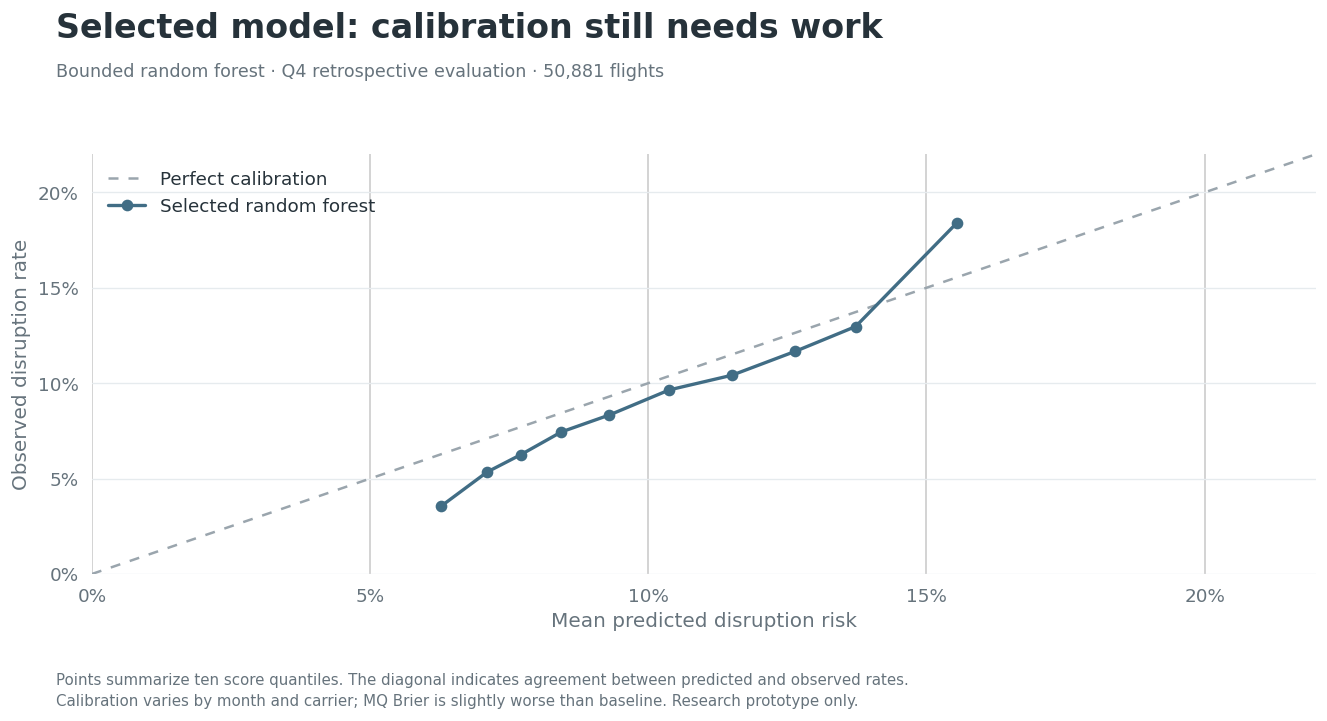

In [ ]:
from sklearn.calibration import calibration_curve
observed,predicted=calibration_curve(flights.loc[vtest,"disruption_60"],vprobability,n_bins=10,strategy="quantile")
fig,ax=chart_frame("Selected model: calibration still needs work",
    "Bounded random forest · Q4 retrospective evaluation · 50,881 flights",
    "Points summarize ten score quantiles. The diagonal indicates agreement between predicted and observed rates.\n"
    "Calibration varies by month and carrier; MQ Brier is slightly worse than baseline. Research prototype only.")
limit=max(.22,float(max(observed.max(),predicted.max()))*1.15)
ax.plot([0,limit],[0,limit],linestyle=(0,(4,4)),color="#9AA5AD",label="Perfect calibration")
ax.plot(predicted,observed,"o-",color=BLUE,linewidth=2,label="Selected random forest")
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel="Mean predicted disruption risk",ylabel="Observed disruption rate")
ax.set_xticks(np.arange(0,limit+.001,.05)); ax.set_yticks(np.arange(0,limit+.001,.05))
ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0));ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
ax.legend(frameon=False,loc="upper left")
save_chart(fig,"appendix_selected_model_calibration")


## Appendix D · Weather data join and retrospective evidence
Daily airport weather is explanatory context only. A full day's observations include information unavailable at departure and at booking. Full-year 2025 airport/month summaries are **retrospective frequencies**, not prior climatology or booking-time predictors.

Use the verified `flights` dataset. Join origin airport + flight date with **many-to-one validation**, checking uniqueness, match coverage and row preservation. Unknown snowfall stays unknown; trace snowfall is reported separately from zero and measurable snowfall. Daily precipitation is not automatically rain.

Destination-day comparisons are withheld: `FL_DATE` is the origin flight date and can differ from the destination's local arrival date. A defensible destination join needs that date. Weather is not added to the model.

Source: the repository's airport daily-weather file, attributed there to NOAA GHCN-Daily. Retain the station and its distance; a nearby station's daily reading is not necessarily the weather encountered by each flight. No weather chart is added to the main story.

This appendix preserves the earlier origin-weather description. Appendix I adds audited destination dates, both-endpoint joins and a paired weather-model comparison.


In [ ]:
import urllib.request
WEATHER_URL = "https://raw.githubusercontent.com/MikaIsmayilov/Chart_Champ_Datathon/refs/heads/main/extra_data/Weather%20Data/airport_weather_2025.csv"
WEATHER_SHA256 = "c41e15635d39f83e4c57759a5ca139cef6750ab6297058e1942c67cadf0ed741"
weather_candidates = [Path(os.environ["CHART_CHAMP_WEATHER_PATH"])] if os.environ.get("CHART_CHAMP_WEATHER_PATH") else []
weather_candidates += [DATA_DIR/"airport_weather_2025.csv", DATA_DIR/"Weather Data"/"airport_weather_2025.csv"]
weather_path = next((p for p in weather_candidates if p.is_file()), None)
if weather_path is None:
    weather_path = OUTPUT_DIR/"source_cache"/"airport_weather_2025.csv"
    if not weather_path.is_file():
        weather_bytes = urllib.request.urlopen(WEATHER_URL,timeout=60).read()
        assert hashlib.sha256(weather_bytes).hexdigest() == WEATHER_SHA256, "Weather source changed: review before use."
        weather_path.parent.mkdir(exist_ok=True)
        weather_path.write_bytes(weather_bytes)
check("Weather source checksum", hashlib.sha256(weather_path.read_bytes()).hexdigest()==WEATHER_SHA256)
weather = pd.read_csv(weather_path,parse_dates=["date"])
check("Weather airport/day keys unique", not weather.duplicated(["airport_code","date"]).any())
check("Weather keys observed", weather[["airport_code","date"]].notna().all().all())
check("Weather 2025 coverage", len(weather)==327*365 and weather.airport_code.nunique()==327 and weather.date.dt.year.eq(2025).all() and weather.groupby("airport_code").date.nunique().eq(365).all())
check("Weather snow values valid", weather.snowfall_in.dropna().ge(0).all())
check("Weather trace encoding", set(weather.snow_trace.dropna().unique()).issubset({"Y"}))
weather["snow_trace_flag"] = weather.snow_trace.eq("Y")
weather["snow_observed"] = weather.snowfall_in.notna()
weather["snow_category"] = np.select([
    weather.snowfall_in.isna(),
    weather.snowfall_in.eq(0)&weather.snow_trace_flag,
    weather.snowfall_in.eq(0)&~weather.snow_trace_flag,
    weather.snowfall_in.gt(0)&weather.snowfall_in.lt(1),
    weather.snowfall_in.ge(1)&weather.snowfall_in.lt(3),
    weather.snowfall_in.ge(3)],
    ["Unknown snowfall","Trace snowfall","Zero reported; no trace","Measurable <1 in","1 to <3 in","≥3 in"], default="REVIEW")
check("Weather categories exhaustive", weather.snow_category.ne("REVIEW").all())
wx_columns=["airport_code","date","station_id","station_distance_km","snowfall_in","precip_in","min_temp_f","max_temp_f","snow_trace_flag","snow_category"]
wx = flights.merge(weather[wx_columns],left_on=["ORIGIN","date"],right_on=["airport_code","date"],how="left",validate="many_to_one",indicator="weather_match",sort=False)
check("Weather join preserves all flight rows", len(wx)==len(flights) and wx[flight_key].equals(flights[flight_key]))
check("Weather keys match", wx.weather_match.eq("both").all())
check("Weather join preserves raw values", wx[raw.columns].equals(raw))
weather_coverage = pd.DataFrame([
    ["Origin airport-date matched",wx.weather_match.eq("both").sum(),len(wx)],
    ["Origin snowfall reported",wx.snowfall_in.notna().sum(),len(wx)],
    ["Origin precipitation reported",wx.precip_in.notna().sum(),len(wx)],
    ["Origin maximum temperature reported",wx.max_temp_f.notna().sum(),len(wx)]],columns=["Coverage","Flights","Total"])
weather_coverage["Share"]=weather_coverage.Flights/weather_coverage.Total
display(weather_coverage.style.hide(axis="index").format({"Flights":"{:,.0f}","Total":"{:,.0f}","Share":"{:.1%}"}))
print("Flight dates are origin dates. No destination weather join or model feature was created.")
save_table(weather_coverage,"weather_coverage")


Coverage,Flights,Total,Share
Origin airport-date matched,"200,000","200,000",100.0%
Origin snowfall reported,"169,092","200,000",84.5%
Origin precipitation reported,"198,591","200,000",99.3%
Origin maximum temperature reported,"199,117","200,000",99.6%


Flight dates are origin dates. No destination weather join or model feature was created.


In [ ]:
category_order=["Zero reported; no trace","Trace snowfall","Measurable <1 in","1 to <3 in","≥3 in","Unknown snowfall"]
weather_conditions=wx.groupby("snow_category",observed=True).agg(flights=("major_disruption","size"),events=("major_disruption","sum"),cancellations=("CANCELLED","sum"))
airport_days=wx[["snow_category","ORIGIN","date"]].drop_duplicates().groupby("snow_category").size()
stations_days=wx[["snow_category","station_id","date"]].drop_duplicates().groupby("snow_category").size()
weather_conditions["airport_days"]=airport_days
weather_conditions["station_days"]=stations_days
weather_conditions["disruption_rate"]=weather_conditions.events/weather_conditions.flights
weather_conditions=weather_conditions.reindex(category_order)
check("Weather groups partition all flights", weather_conditions.flights.sum()==len(wx))
check("Unknown snow is retained", weather_conditions.loc["Unknown snowfall","flights"]==wx.snowfall_in.isna().sum())
display(weather_conditions.style.format({"flights":"{:,.0f}","events":"{:,.0f}","cancellations":"{:,.0f}","airport_days":"{:,.0f}","station_days":"{:,.0f}","disruption_rate":"{:.2%}"}))
# Explicit observed zero excludes both unknown snowfall and trace snowfall.
precip_mask=wx.precip_in.ge(.5)&wx.snowfall_in.notna()&wx.snowfall_in.eq(0)&~wx.snow_trace_flag
precip_summary=pd.DataFrame([{
    "condition":"Precipitation ≥0.5 in; reported zero snowfall, no trace",
    "flights":int(precip_mask.sum()),
    "airport_days":len(wx.loc[precip_mask,["ORIGIN","date"]].drop_duplicates()),
    "disruption_rate":wx.loc[precip_mask,"major_disruption"].mean()}])
check("No unknown snow in precipitation comparison", wx.loc[precip_mask,"snowfall_in"].notna().all())
display(precip_summary)
print("Descriptive associations only. Flight counts are not independent weather events; no causal weather effect is estimated.")
save_table(weather_conditions.reset_index(),"weather_snow_categories")
save_table(precip_summary,"weather_precipitation_condition")


,flights,events,cancellations,airport_days,station_days,disruption_rate
snow_category,,,,,,
Zero reported; no trace,"159,049","15,223","2,117","32,518","32,518",9.57%
Trace snowfall,"4,904",567,98,"1,198","1,198",11.56%
Measurable <1 in,"3,093",620,132,785,785,20.05%
1 to <3 in,"1,496",517,168,406,406,34.56%
≥3 in,550,248,84,185,185,45.09%
Unknown snowfall,"30,908","2,309",308,"9,674","9,674",7.47%


,condition,flights,airport_days,disruption_rate
0,"Precipitation ≥0.5 in; reported zero snowfall,...",9351,1957,0.217624


Descriptive associations only. Flight counts are not independent weather events; no causal weather effect is estimated.


In [ ]:
# No pooled claim that weather controls all early/late confounding.
wx_windows=wx[wx.window.ne("other")]
weather_windows=wx_windows.groupby(["snow_category","window"]).major_disruption.agg(flights="size",events="sum")
weather_windows["disruption_rate"]=weather_windows.events/weather_windows.flights
weather_windows["airport_days"]=wx_windows[["snow_category","window","ORIGIN","date"]].drop_duplicates().groupby(["snow_category","window"]).size()
display(weather_windows.round(4))
print("These early/late rates remain unadjusted within weather categories; route, month and airport mix can differ.")

weather_monthly_source=weather.assign(month=weather.date.dt.month)
weather_monthly_source["measurable_snow_day"]=weather.snowfall_in.gt(0).astype(float).where(weather.snow_observed)
weather_monthly_source["any_snow_day"]=(weather.snowfall_in.gt(0)|weather.snow_trace_flag).astype(float).where(weather.snow_observed)
weather_monthly=weather_monthly_source.groupby(["airport_code","month"]).agg(
    calendar_days=("date","size"), reported_snow_days=("snow_observed","sum"),
    measurable_snow_share=("measurable_snow_day","mean"),any_snow_including_trace_share=("any_snow_day","mean"))
weather_monthly["reporting_coverage"]=weather_monthly.reported_snow_days/weather_monthly.calendar_days
no_reports=weather_monthly.reported_snow_days.eq(0)
check("All-missing airport-months remain unknown", weather_monthly.loc[no_reports,["measurable_snow_share","any_snow_including_trace_share"]].isna().all().all())
print(f"Retrospective 2025 summaries: {int(no_reports.sum()):,} airport-months have no snow reports; shares remain missing.")
print("Alphabetical preview, not a risk ranking. Fractions use reported days as the denominator; coverage is separate.")
display(weather_monthly.reset_index().head(12).round(3))
save_table(weather_windows.reset_index(),"weather_early_late_descriptive")
save_table(weather_monthly.reset_index(),"weather_2025_retrospective_monthly")


flights  events  disruption_rate  airport_days
snow_category           window                                                
1 to <3 in              early       338      80           0.2367           202
                        late        525     222           0.4229           212
Measurable <1 in        early       648      81           0.1250           379
                        late       1093     266           0.2434           405
Trace snowfall          early      1109      76           0.0685           630
                        late       1682     243           0.1445           667
Unknown snowfall        early      6765     334           0.0494          4214
                        late       9279     896           0.0966          5108
Zero reported; no trace early     33283    1550           0.0466         17607
                        late      54977    7851           0.1428         19761
≥3 in                   early       126      48           0.3810            81
                        late        166      84           0.5060            89

These early/late rates remain unadjusted within weather categories; route, month and airport mix can differ.
Retrospective 2025 summaries: 1,011 airport-months have no snow reports; shares remain missing.
Alphabetical preview, not a risk ranking. Fractions use reported days as the denominator; coverage is separate.


,airport_code,month,calendar_days,reported_snow_days,measurable_snow_share,any_snow_including_trace_share,reporting_coverage
0,ABE,1,31,31,0.129,0.258,1.0
1,ABE,2,28,28,0.250,0.357,1.0
2,ABE,3,31,31,0.000,0.000,1.0
3,ABE,4,30,30,0.000,0.000,1.0
4,ABE,5,31,31,0.000,0.000,1.0
5,ABE,6,30,30,0.000,0.000,1.0
6,ABE,7,31,31,0.000,0.000,1.0
7,ABE,8,31,31,0.000,0.000,1.0
8,ABE,9,30,30,0.000,0.000,1.0
9,ABE,10,31,31,0.000,0.000,1.0


**Interpretation and limits:** heavier reported snowfall is associated with higher disruption in these descriptive groups. Airport, route, season, schedules and reporting coverage differ. Unknown and trace observations have separate categories; precipitation is labeled as precipitation. These comparisons do not estimate how much weather caused a delay or how much earlier departure would help under the same storm.

The monthly summaries describe **observed 2025 weather among reporting days**. Prior-year weather history or forecasts available as of the decision would be needed for a future booking study. Small airport/station-day support, nearby station representation and daily observation timing remain limitations. No new weather recommendation or predictive claim is added to the main story.


## Appendix E · Issues, decisions, experiments and validation
The cleanup was authorized by Burak on November 6, 2026. It reorganizes the existing evidence and fixes the weather section; it does not claim that historical work was personally reviewed or approved. Raw source data, notebook identity and the agreed ten-stage method are preserved.

| Issue | Evidence / treatment | Residual limitation |
|---|---|---|
| Four timing inconsistencies | Retained and flagged; source cases reproduce in monthly files | Source cause unresolved |
| Structural nulls and extreme delays | Preserved; conditional causes are not imputed | Delay-only summaries exclude cancelled/diverted flights |
| Duplicate preparation and model narratives | One `flights` pipeline; one current model study | Historical versions retained in backup |
| Weather missingness / trace | Unknown stays unknown; trace has its own category | Reported zero is not proof of no weather exposure |
| Weather join | Unique origin/date keys, many-to-one join, row and raw-value checks | Destination date unresolved; destination comparison withheld |
| Weather look-ahead | 2025 summaries labeled retrospective; excluded from predictors | Prior history/forecast archive needed for booking use |
| Model reliability | Modest improvement; calibration and MQ weakness visible | No deployment, causal benefit or untouched holdout |

| Decision | Reason |
|---|---|
| Three main charts | Each answers a distinct decision question: timing pattern, comparable flights, arrival allowance |
| Keep carrier and month/time charts in appendix | Descriptive context without procurement or causal claims |
| Remove financial scenarios | No measured client fares, costs or causal policy effect |
| No extra regression or clustering | No additional decision capability required for the chosen story |
| Pilot before policy adoption | Need feasible alternatives and actual traveler/meeting outcomes |

**Experiment record:** Appendix B reports support and threshold/quarter checks; Appendix C retains all four model candidates and the fixed chronological evaluation. Appendix D documents corrected weather summaries. Research results and unresolved issues remain visible.


In [ ]:
check("Raw fingerprint unchanged at end", hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==raw_fingerprint)
check("Prepared dataset still preserves sources", flights[raw.columns].equals(raw))
validation_table=pd.DataFrame(validation_records)
display(validation_table)
save_table(validation_table,"validation_checks")
print(f"{validation_table.passed.sum()} checks passed. Four source timing cases and model limitations remain explicitly documented.")


,check,passed,detail
0,20 source files verified,True,
1,Student dimensions,True,
2,No duplicate rows or tested keys,True,
3,All 365 dates represented,True,
4,Calendar agreement: YEAR,True,
5,Calendar agreement: QUARTER,True,
6,Calendar agreement: MONTH,True,
7,Calendar agreement: DAY_OF_MONTH,True,
8,Calendar agreement: DAY_OF_WEEK,True,
9,Binary flag: CANCELLED,True,


49 checks passed. Four source timing cases and model limitations remain explicitly documented.


## Export · Curated outputs only
The export includes artifacts generated by this notebook run: three main charts, supporting figures, compact evidence tables and validation records. PNG and editable SVG figures share the same values. An explicit file list prevents old financial charts or unrelated files from entering the ZIP. Raw flights and the weather-enriched row-level dataset are not included.


In [ ]:
import zipfile
parameters={"delay_threshold_minutes":MAJOR_DELAY_MINUTES,"min_group_n":MIN_GROUP_N,"seed":SEED,
    "sample_rows":len(flights),"population_rows":population_count,"source":"20 manifest-verified project files",
    "weather_sha256":globals().get("WEATHER_SHA256"),"main_chart_count":3,
    "model_status":"research prototype; Q4 retrospective, no untouched holdout",
    "weather_status":"origin daily observations and 2025 summaries; retrospective only",
    "execution_note":"Saved outputs validated locally against source copies; rerun sequentially with Drive in Colab."}
parameters_path=OUTPUT_DIR/"analysis_parameters.json"
parameters_path.write_text(json.dumps(parameters,indent=2)); ARTIFACTS[parameters_path.name]=parameters_path
archive=OUTPUT_DIR.parent/"chart_champ_curated_outputs.zip"
with zipfile.ZipFile(archive,"w",zipfile.ZIP_DEFLATED) as z:
    for name,path in sorted(ARTIFACTS.items()):
        assert path.is_file(),name
        z.write(path,arcname=name)
print(f"Exported {len(ARTIFACTS)} current artifacts to {archive}")
# To download after reviewing the export:
# from google.colab import files
# files.download(str(archive))


Exported 32 current artifacts to chart_champ_outputs/chart_champ_curated_outputs.zip


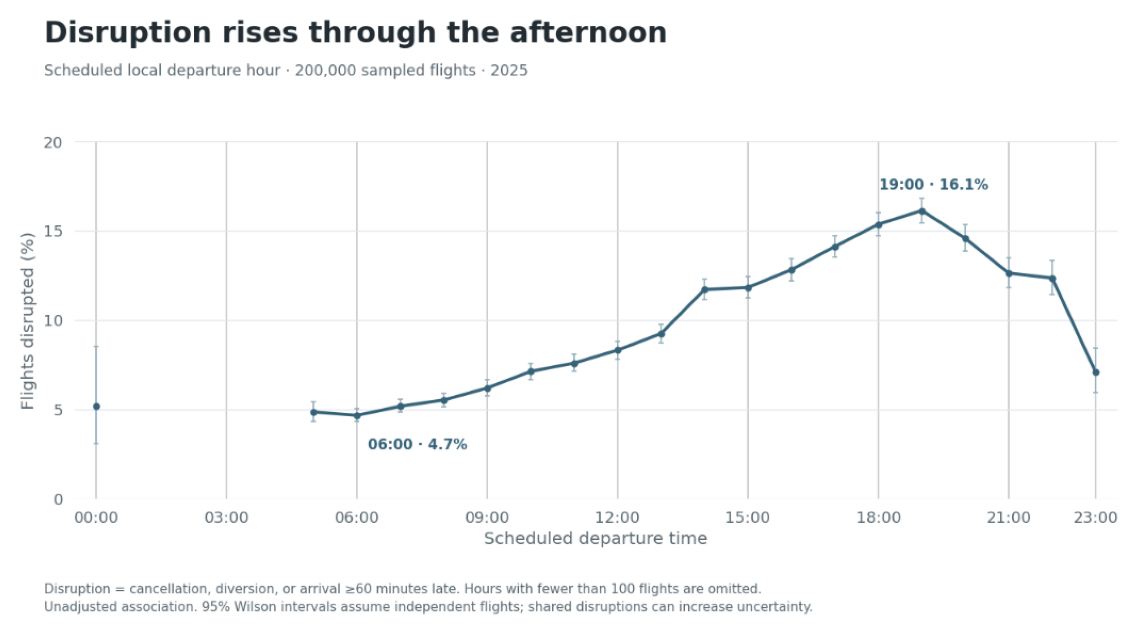

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# Load and display the user's selected screenshot
img_path = '/content/Screenshot 2026-11-06 at 10.40.37 PM.png'
try:
    img = Image.open(img_path)
    plt.figure(figsize=(12, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.show()
except Exception as e:
    print(f"Error displaying image: {e}")

## Sources and interpretation notes
- [Project repository](https://github.com/MikaIsmayilov/Chart_Champ_Datathon) — dataset and challenge materials.
- `Questrom_Chart_Champs_Revised_Brief.pdf` — corporate travel RFP, evaluation criteria, deliverables.
- `questrom_student_package_2025/README.txt`, `validation_report.json`, `data_dictionary.csv` — sample provenance, controls, column list.
- `questrom_flights_2025_student.csv` — 200,000-flight uniform random reservoir sample from 6,398,056 selected-carrier flights; constant weight 31.99028; sample seed 20261103.
- [BTS delay-cause definitions](https://www.bts.gov/explore-topics-and-geography/topics/airline-time-performance-and-causes-flight-delays).

Scope: selected 2025 domestic operating carriers, not all airlines or all corporate travelers. No fares, passenger loads, trip purpose, itineraries, meeting outcomes, or observed recovery costs. Sparse groups and one-year coverage constrain inference. Late-aircraft and weather attribution are descriptive, not causal identification. A proposed policy requires pilot validation.

Weather source: repository `extra_data/Weather Data/airport_weather_2025.csv`; exact SHA256 is checked in Appendix D. Daily origin observations are retrospective explanatory context.


# Appendix F · Schedule-only classification: randomized, grouped evaluation
**Client decision:** prioritize review among feasible flight choices. Predict cancellation, diversion, or arrival delay **≥60 minutes**, using scheduled information only. No weather inputs, observed operating outcomes, flight-history target averages, or aircraft-assignment proxies enter the model.

**Run order:** original imports → verified Drive loader → original preparation (Sections 1–2), then F1–F7 below, one section at a time. Earlier population, model and weather cells are not prerequisites. Existing evidence remains intact. Appendix C is the earlier chronological study; its scores use different assessment rows and should not be compared directly with this randomized study.

**Study scope:** the frozen seed-64 assignment uses whole dates, randomized within months. Five development folds each cover all 12 months. The reserved assessment dates were excluded from fitting and candidate selection here, but the year was already explored in EDA, so this is not a historically untouched test. Recorded schedules are booking-information proxies; historical schedule snapshots and actual client alternatives are unavailable.

**Execution provenance:** saved study outputs were executed section by section locally on the checksum-verified source copies, then saved to this notebook. Rerun the same cells in Colab for a fresh runtime execution. This first study ends before adding weather.


## Model guide · Read this before the code
**Business question:** among feasible flight options, which deserve closer review for disruption? One observation is one scheduled flight leg. The target is **1 if cancelled, diverted, or at least 60 minutes late on arrival; 0 otherwise**. The 60-minute cutoff is our declared business definition, not a threshold discovered by a model.

**Predictors** are information given to a model. **The target** is what it learns to predict. **A prediction** is a model estimate, not an observed outcome or a guarantee.

| Model | Why we use it | Predictors / what it learns | Output and interpretation |
| --- | --- | --- | --- |
| Prevalence baseline | Check whether ML adds value over knowing the overall disruption rate. | Training outcomes only; no flight-specific predictors. | The same training disruption probability for every flight. |
| Logistic regression | Provide a relatively simple, interpretable supervised benchmark. | Carrier, origin, destination, month, weekday, distance, scheduled duration, and departure/arrival/year cycles. Learns additive relationships in log-odds. | A disruption probability for each flight. Associations are not causal effects. |
| Gradient boosting | Test whether nonlinear relationships and combinations of predictors improve risk estimates. | The same scheduled inputs as logistic regression. Small decision trees learn successive corrections. | A disruption probability. Extra complexity is justified only by evaluation. |
| MiniBatch K-means | Discover common schedule patterns without using disruption labels. | Log-distance, departure-clock cycles, annual cycles and weekday cycles. Groups similar standardized schedules. | A group and distances to its eight centers. A group number is **not** a risk level. Test distances as extra supervised predictors. |
| Isolation Forest | Identify schedules that look unusual relative to training data. | The same seven schedule-pattern features as clustering, without outcomes. | A continuous anomaly score. Unusual does **not** mean disrupted or unsafe. Test the score as an extra predictor; do not convert it directly into a risk percentage. |

Clock/calendar cycles use sine and cosine so the end and beginning of a day/year stay close. The schedule classifier has 13 encoded-input columns before categorical expansion; the underlying feature list is displayed in F1. F and G remain schedule-only. Weather-aware models and their actual inputs/results are in Appendix I. Actual delay, cancellation/diversion flags and delay causes are used to define/check outcomes, never as predictors.

**How to read the study:** F1 checks data and sampling → F2 chooses settings using development folds → F3 evaluates reserved dates → F4 checks uncertainty and weak groups → F5 tests harder sampling/time conditions → F6 shows one diagnostic figure → F7 records findings. G then asks whether unsupervised signals add anything to the same classifier.

**Metrics in plain language:** Brier score measures squared probability error (lower is better; it is not accuracy). Average precision measures how well disruptions rise toward the top of the ranking (higher is better). ROC AUC measures ranking discrimination. Precision among reviewed flights is the fraction that actually disrupted; recall is the fraction of all disruptions captured. Calibration asks whether predicted probabilities agree with observed rates across comparable groups. Good ranking alone does not guarantee accurate probabilities.

Numbers of clusters/trees and model settings are declared design choices. Performance values below are computed from the current data; no simulated performance, assumed savings, or manually weighted risk points are used.


## F1 · Freeze the protocol, dates and eligible features
The configuration below is declared before fitting. Candidate selection uses **out-of-fold Brier score** (lower is better); average precision, log loss, calibration and review-capacity results are secondary. The assessment set never chooses a parameter, calibration method or threshold.

Logistic regression tests C=0.1 and C=1. Gradient boosting tests 15 and 31 terminal leaves with the other settings fixed. Boosting's internal row-random early stopping is disabled. Categorical airport codes are treated as categories, not numeric quantities. Preprocessing is fitted inside each training fold. Probability calibration is evaluated in this round; there is no assessment-driven recalibration.


In [ ]:
import os, json, hashlib, calendar, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, log_loss, average_precision_score, roc_auc_score
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import sklearn

assert 'raw' in globals() and 'flights' in globals(), 'Run the Drive loader and preparation first.'
assert raw.shape==(200000,37) and flights[raw.columns].equals(raw)
assert MAJOR_DELAY_MINUTES==60
ML_DIR=Path(os.environ.get('CHART_CHAMP_ML_OUTPUT_DIR',str(OUTPUT_DIR/'schedule_ml')))
ML_DIR.mkdir(parents=True,exist_ok=True)
ml_files={}
ml_checks=[]
def ml_check(name,condition,detail=''):
    passed=bool(condition);ml_checks.append({'check':name,'passed':passed,'detail':detail})
    assert passed, f'{name}: {detail}'
def ml_save(table,name,index=False):
    p=ML_DIR/f'{name}.csv';table.to_csv(p,index=index);ml_files[p.name]=p

ML_SEED=64
ml_candidates={
    'baseline':{'family':'Baseline'},
    'logistic_C0.1':{'family':'Logistic regression','C':.1},
    'logistic_C1':{'family':'Logistic regression','C':1.0},
    'boost_leaves15':{'family':'Gradient boosting','leaves':15},
    'boost_leaves31':{'family':'Gradient boosting','leaves':31},
}
ml_protocol={
    'seed':ML_SEED,'target':'cancelled OR diverted OR arrival delay >=60',
    'selection':'pooled out-of-fold Brier on five grouped development folds',
    'candidates':ml_candidates,
    'boosting_fixed':{'max_iter':150,'learning_rate':.08,'min_samples_leaf':100,'l2_regularization':10,'early_stopping':False},
    'assessment_use':'one frozen comparison; no assessment-driven tuning or recalibration',
    'robustness_fixed_candidates':['baseline','logistic_C1','boost_leaves31'],
    'robustness_design':'whole-week random holdout and expanding quarter benchmarks; settings fixed before primary fitting',
    'capacities':[.05,.10,.20],
    'capacity_meaning':'ranking diagnostics, not an approved operational policy',
    'weather_features':[],
}
(ML_DIR/'protocol.json').write_text(json.dumps(ml_protocol,indent=2));ml_files['protocol.json']=ML_DIR/'protocol.json'
ml_raw_hash=hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()
ml_environment={'python':sys.version.split()[0],'sklearn':sklearn.__version__,'pandas':pd.__version__,'numpy':np.__version__}
print('Protocol fixed before fitting. Environment:',ml_environment)


Protocol fixed before fitting. Environment: {'python': '3.9.6', 'sklearn': '1.6.1', 'pandas': '2.3.3', 'numpy': '2.0.2'}


In [ ]:
ml_days=flights[['date','MONTH']].drop_duplicates().sort_values('date').reset_index(drop=True)
ml_dev_days,ml_test_days=train_test_split(ml_days,test_size=.20,stratify=ml_days.MONTH,random_state=ML_SEED)
ml_dev_days=ml_dev_days.sort_values('date').reset_index(drop=True)
ml_dev_days['partition']='development';ml_dev_days['cv_fold']=-1
for fold,(_,valid) in enumerate(StratifiedKFold(n_splits=5,shuffle=True,random_state=ML_SEED).split(ml_dev_days,ml_dev_days.MONTH)):
    ml_dev_days.loc[valid,'cv_fold']=fold
ml_test_days=ml_test_days.assign(partition='assessment',cv_fold=-1)
ml_dates=pd.concat([ml_dev_days,ml_test_days]).sort_values('date').reset_index(drop=True)
ml_date_hash=hashlib.sha256(ml_dates.to_csv(index=False).encode()).hexdigest()
ml_check('Frozen date assignment reproduced',ml_date_hash=='4cab72942ad64fd14881bbe55a6b3d5a3586ff690c7e91dbcca3db491362c77c')
ml_data=flights.merge(ml_dates[['date','partition','cv_fold']],on='date',validate='many_to_one',sort=False)
ml_check('Source rows preserved',ml_data[raw.columns].equals(raw))
ml_check('No date crosses partitions or folds',ml_data.groupby('date').partition.nunique().eq(1).all() and ml_data.groupby('date').cv_fold.nunique().eq(1).all())
ml_check('No airport/date overlap',all(ml_data.groupby([a,'date']).partition.nunique().eq(1).all() for a in ['ORIGIN','DEST']))
ml_dev=ml_data.partition.eq('development').to_numpy();ml_test=~ml_dev
ml_check('Frozen sample sizes',ml_dev.sum()==160350 and ml_test.sum()==39650)
ml_check('All months in both partitions',ml_data.groupby('partition').MONTH.nunique().eq(12).all())
ml_check('All months in each development fold',ml_data[ml_dev].groupby('cv_fold').MONTH.nunique().eq(12).all())
ml_y=ml_data.major_disruption.to_numpy(dtype=int)
ml_check('Target reconciliation',ml_y.sum()==19484 and set(np.unique(ml_y))=={0,1})
ml_summary=ml_data.groupby('partition').agg(flights=('major_disruption','size'),dates=('date','nunique'),months=('MONTH','nunique'),events=('major_disruption','sum'),event_rate=('major_disruption','mean'))
ml_folds=ml_data[ml_dev].groupby('cv_fold').agg(flights=('major_disruption','size'),dates=('date','nunique'),months=('MONTH','nunique'),event_rate=('major_disruption','mean'))
display(ml_summary);display(ml_folds)
ml_save(ml_dates,'date_assignments');ml_save(ml_summary.reset_index(),'sampling_summary');ml_save(ml_folds.reset_index(),'fold_audit')


,flights,dates,months,events,event_rate
partition,,,,,
assessment,39650,73,12,3958,0.099823
development,160350,292,12,15526,0.096826


,flights,dates,months,event_rate
cv_fold,,,,
0,32306,59,12,0.098743
1,32120,59,12,0.086675
2,32059,58,12,0.104464
3,31932,58,12,0.103501
4,31933,58,12,0.090753


In [ ]:
ml_categorical=['OP_UNIQUE_CARRIER','ORIGIN','DEST','MONTH','DAY_OF_WEEK']
ml_numeric=['DISTANCE','CRS_ELAPSED_TIME','departure_sin','departure_cos','arrival_sin','arrival_cos','year_sin','year_cos']
ml_features=ml_categorical+ml_numeric
ml_forbidden={'ARR_DELAY','ARR_DELAY_NEW','DEP_DELAY','DEP_DELAY_NEW','CANCELLED','DIVERTED','CANCELLATION_CODE','TAIL_NUM','DEP_TIME','ARR_TIME','ACTUAL_ELAPSED_TIME','AIR_TIME','major_disruption','timing_issue',*cause_cols}
ml_check('Schedule-only explicit feature allowlist',not set(ml_features)&ml_forbidden and not any(any(t in f.lower() for t in ['snow','weather','precip','actual','disruption']) for f in ml_features))
ml_X=ml_data[ml_features].copy()
ml_X[ml_categorical]=ml_X[ml_categorical].astype(str)
ml_check('Numeric predictors finite or missing',not np.isinf(ml_X[ml_numeric].to_numpy()).any())
ml_registry=pd.DataFrame([
    {'feature':f,'role':'categorical schedule/calendar' if f in ml_categorical else 'numeric schedule/calendar',
     'transformation':'fold-fitted encoding' if f in ml_categorical else 'raw measurement or deterministic clock/calendar cycle',
     'availability':'schedule snapshot proxy; calendar/deterministic transform known'} for f in ml_features])
display(ml_registry);ml_save(ml_registry,'feature_registry')

def ml_make_model(candidate):
    cfg=ml_candidates[candidate]
    if cfg['family']=='Baseline':return None
    if cfg['family']=='Logistic regression':
        pre=ColumnTransformer([
            ('categories',OneHotEncoder(handle_unknown='ignore',min_frequency=20),ml_categorical),
            ('numbers',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),ml_numeric)])
        estimator=LogisticRegression(C=cfg['C'],max_iter=1500,solver='lbfgs',random_state=ML_SEED)
    else:
        # Native categorical splits; codes are not used as continuous numbers.
        # Rare category pooling is learned on training rows only (<=128 levels per field).
        pre=ColumnTransformer([
            ('categories',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan,max_categories=128),ml_categorical),
            ('numbers',SimpleImputer(strategy='median',add_indicator=True),ml_numeric)])
        estimator=HistGradientBoostingClassifier(max_iter=150,learning_rate=.08,max_leaf_nodes=cfg['leaves'],
            min_samples_leaf=100,l2_regularization=10,early_stopping=False,
            categorical_features=list(range(len(ml_categorical))),random_state=ML_SEED)
    return Pipeline([('preprocess',pre),('classifier',estimator)])

def ml_fit_predict(candidate,train_indices,score_indices):
    if candidate=='baseline':
        return None,np.full(len(score_indices),ml_y[train_indices].mean())
    fitted=ml_make_model(candidate)
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        fitted.fit(ml_X.iloc[train_indices],ml_y[train_indices])
        probability=fitted.predict_proba(ml_X.iloc[score_indices])[:,1]
    assert np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all()
    return fitted,probability

def ml_score(y,p):
    return {'n':len(y),'events':int(np.sum(y)),'event_rate':float(np.mean(y)),
            'mean_prediction':float(np.mean(p)),'Brier':brier_score_loss(y,p),
            'log_loss':log_loss(y,p,labels=[0,1]),'AP':average_precision_score(y,p),
            'ROC_AUC':roc_auc_score(y,p)}

ml_check('No validation rows in training folds',all(not set(ml_data.loc[ml_dev&(ml_data.cv_fold!=f),'date'])&set(ml_data.loc[ml_dev&(ml_data.cv_fold==f),'date']) for f in range(5)))
print('Feature and sampling gates passed. Ready for development-only fitting.')


,feature,role,transformation,availability
0,OP_UNIQUE_CARRIER,categorical schedule/calendar,fold-fitted encoding,schedule snapshot proxy; calendar/deterministi...
1,ORIGIN,categorical schedule/calendar,fold-fitted encoding,schedule snapshot proxy; calendar/deterministi...
2,DEST,categorical schedule/calendar,fold-fitted encoding,schedule snapshot proxy; calendar/deterministi...
3,MONTH,categorical schedule/calendar,fold-fitted encoding,schedule snapshot proxy; calendar/deterministi...
4,DAY_OF_WEEK,categorical schedule/calendar,fold-fitted encoding,schedule snapshot proxy; calendar/deterministi...
5,DISTANCE,numeric schedule/calendar,raw measurement or deterministic clock/calenda...,schedule snapshot proxy; calendar/deterministi...
6,CRS_ELAPSED_TIME,numeric schedule/calendar,raw measurement or deterministic clock/calenda...,schedule snapshot proxy; calendar/deterministi...
7,departure_sin,numeric schedule/calendar,raw measurement or deterministic clock/calenda...,schedule snapshot proxy; calendar/deterministi...
8,departure_cos,numeric schedule/calendar,raw measurement or deterministic clock/calenda...,schedule snapshot proxy; calendar/deterministi...
9,arrival_sin,numeric schedule/calendar,raw measurement or deterministic clock/calenda...,schedule snapshot proxy; calendar/deterministi...


Feature and sampling gates passed. Ready for development-only fitting.


## F2 · Compare candidates using development data only
The prevalence baseline learns one probability from each training fold. Logistic regression models additive relationships; boosting can learn nonlinearities and interactions. No class oversampling or class weighting is used: probabilities and assessment prevalence should retain their natural meaning.

The table below is **development cross-validation**, not final assessment. Brier is the average squared probability error. Average precision summarizes how well the ranking concentrates disruptions; its baseline is related to event prevalence. Lower Brier/log loss and higher average precision are preferred. Fold variability reflects different held-out dates and is not a confidence interval.


In [ ]:
ml_oof={};ml_cv_rows=[]
for candidate in ml_candidates:
    prediction=np.full(len(ml_data),np.nan)
    for fold in range(5):
        fit_idx=np.flatnonzero(ml_dev&(ml_data.cv_fold.to_numpy()!=fold))
        val_idx=np.flatnonzero(ml_dev&(ml_data.cv_fold.to_numpy()==fold))
        _,p=ml_fit_predict(candidate,fit_idx,val_idx)
        prediction[val_idx]=p
        ml_cv_rows.append({'candidate':candidate,'fold':fold,**ml_score(ml_y[val_idx],p)})
        print(f'{candidate}: fold {fold+1}/5 complete',flush=True)
    assert np.isfinite(prediction[ml_dev]).all() and np.isnan(prediction[ml_test]).all()
    ml_oof[candidate]=prediction
ml_cv_folds=pd.DataFrame(ml_cv_rows)
ml_cv_summary=pd.DataFrame([{'candidate':c,'family':ml_candidates[c]['family'],**ml_score(ml_y[ml_dev],p[ml_dev])} for c,p in ml_oof.items()])
ml_cv_summary['fold_Brier_SD']=ml_cv_summary.candidate.map(ml_cv_folds.groupby('candidate').Brier.std())
ml_family_winners={family:g.sort_values(['Brier','candidate']).iloc[0].candidate for family,g in ml_cv_summary.groupby('family')}
ml_selected=ml_cv_summary.sort_values(['Brier','candidate']).iloc[0].candidate
ml_check('Assessment excluded from development predictions',all(np.isnan(p[ml_test]).all() for p in ml_oof.values()))
display(ml_cv_summary[['candidate','family','Brier','AP','ROC_AUC','log_loss','fold_Brier_SD']].sort_values('Brier').round(6))
print('Family settings frozen:',ml_family_winners,'| Overall selection:',ml_selected)
(ML_DIR/'selection.json').write_text(json.dumps({'selected':ml_selected,'family_winners':ml_family_winners,'selected_by':'development pooled OOF Brier','assessment_evaluated':False},indent=2))
ml_files['selection.json']=ML_DIR/'selection.json'
ml_save(ml_cv_folds,'development_fold_metrics');ml_save(ml_cv_summary,'development_summary')


baseline: fold 1/5 complete


baseline: fold 2/5 complete


baseline: fold 3/5 complete


baseline: fold 4/5 complete


baseline: fold 5/5 complete


logistic_C0.1: fold 1/5 complete


... (17 outputs left out)

boost_leaves31: fold 4/5 complete


boost_leaves31: fold 5/5 complete


,candidate,family,Brier,AP,ROC_AUC,log_loss,fold_Brier_SD
3,boost_leaves15,Gradient boosting,0.084205,0.190599,0.679231,0.301051,0.005652
1,logistic_C0.1,Logistic regression,0.084359,0.182629,0.666721,0.302416,0.005768
2,logistic_C1,Logistic regression,0.084531,0.179512,0.665030,0.303190,0.005709
4,boost_leaves31,Gradient boosting,0.084584,0.190019,0.674940,0.303416,0.005903
0,baseline,Baseline,0.087478,0.092107,0.477902,0.318210,0.006321


Family settings frozen: {'Baseline': 'baseline', 'Gradient boosting': 'boost_leaves15', 'Logistic regression': 'logistic_C0.1'} | Overall selection: boost_leaves15


## F3 · One frozen assessment comparison
Refit the selected settings for each family on all development rows. Evaluate the reserved 73 dates once, retaining every model's result. The winner was selected above, before this assessment. No tuning or recalibration follows from the assessment scores.

Review-capacity metrics use the highest-scored 5%, 10% or 20% of assessment flights. These are retrospective ranking diagnostics, not a fixed probability threshold or a client-approved capacity. For a constant baseline, unranked review has expected precision equal to prevalence and expected recall equal to the review fraction. Ties for fitted models use a fixed seed independent of outcomes.


In [ ]:
ml_train_idx=np.flatnonzero(ml_dev);ml_test_idx=np.flatnonzero(ml_test)
ml_models={};ml_test_predictions={};ml_assessment_rows=[]
ml_compare_order=['Baseline','Logistic regression','Gradient boosting']
for family in ml_compare_order:
    candidate=ml_family_winners[family]
    fitted,p=ml_fit_predict(candidate,ml_train_idx,ml_test_idx)
    ml_models[candidate]=fitted;ml_test_predictions[candidate]=p
    ml_assessment_rows.append({'family':family,'candidate':candidate,**ml_score(ml_y[ml_test],p)})
ml_assessment=pd.DataFrame(ml_assessment_rows)
ml_check('Assessment outcomes reconcile',ml_assessment.n.eq(39650).all() and ml_assessment.events.eq(3958).all())
display(ml_assessment[['family','candidate','Brier','AP','ROC_AUC','log_loss','mean_prediction']].round(6))
ml_ties=np.random.default_rng(ML_SEED).random(ml_test.sum())
ml_capacity_rows=[]
for candidate,p in ml_test_predictions.items():
    order=np.lexsort((ml_ties,-p))
    for capacity in [.05,.10,.20]:
        count=int(np.ceil(capacity*len(p)))
        if candidate=='baseline':
            precision=ml_y[ml_test].mean();recall=count/len(p);events=precision*count
            meaning='Unranked-review expectation'
        else:
            events=int(ml_y[ml_test][order[:count]].sum());precision=events/count;recall=events/ml_y[ml_test].sum()
            meaning='Observed score ranking'
        ml_capacity_rows.append({'candidate':candidate,'family':ml_candidates[candidate]['family'],'capacity':capacity,
            'reviewed':count,'events_in_review':events,'precision':precision,'recall':recall,
            'lift':precision/ml_y[ml_test].mean(),'meaning':meaning})
ml_capacity=pd.DataFrame(ml_capacity_rows)
display(ml_capacity.loc[ml_capacity.capacity.eq(.10),['family','reviewed','events_in_review','precision','recall','lift','meaning']].round(4))
ml_save(ml_assessment,'assessment_metrics');ml_save(ml_capacity,'review_capacity')
ml_assessment_predictions=pd.DataFrame({'date':ml_data.loc[ml_test,'date'].to_numpy(),'outcome':ml_y[ml_test],**ml_test_predictions})
# Prediction rows are kept in session for diagnostics, not added to the exported evidence ZIP.
print('Assessment complete. Settings remain frozen; weather is absent.')


,family,candidate,Brier,AP,ROC_AUC,log_loss,mean_prediction
0,Baseline,baseline,0.089868,0.099823,0.500000,0.324746,0.096826
1,Logistic regression,logistic_C0.1,0.085340,0.213922,0.687248,0.303467,0.096237
2,Gradient boosting,boost_leaves15,0.084615,0.225948,0.707729,0.299417,0.090720


,family,reviewed,events_in_review,precision,recall,lift,meaning
1,Baseline,3965,395.8,0.0998,0.1000,1.0000,Unranked-review expectation
4,Logistic regression,3965,1040.0,0.2623,0.2628,2.6276,Observed score ranking
7,Gradient boosting,3965,1045.0,0.2636,0.2640,2.6402,Observed score ranking


Assessment complete. Settings remain frozen; weather is absent.


## F4 · Quantify uncertainty and inspect subgroup weaknesses
Bootstrap **whole date groups**, then calendar-week groups of assessment dates, to compare paired Brier losses. Positive improvement means lower error than the comparator. These intervals are conditional on the fitted models and selected assessment dates; they do not include model-selection uncertainty or establish future-year performance. Week grouping partially addresses dependence across adjacent dates.

Subgroup tables report month and operating carrier, with counts and event rates. They are diagnostic descriptions, not independently confirmed claims of superiority for every group.


In [ ]:
ml_ci_rows=[]
ml_test_y=ml_y[ml_test];ml_test_dates=ml_data.loc[ml_test,'date'].reset_index(drop=True)
ml_lr=ml_family_winners['Logistic regression'];ml_gb=ml_family_winners['Gradient boosting']
for block_name,groups in [('date',ml_test_dates),('calendar_week',ml_test_dates-pd.to_timedelta(ml_test_dates.dt.dayofweek,unit='D'))]:
    for candidate,comparator in [(ml_lr,'baseline'),(ml_gb,'baseline'),(ml_gb,ml_lr)]:
        difference=(ml_test_y-ml_test_predictions[comparator])**2-(ml_test_y-ml_test_predictions[candidate])**2
        aggregated=pd.DataFrame({'group':groups,'improvement':difference}).groupby('group').improvement.agg(['sum','size'])
        rng=np.random.default_rng(ML_SEED)
        draws=rng.integers(0,len(aggregated),size=(2000,len(aggregated)))
        bootstrap=aggregated['sum'].to_numpy()[draws].sum(axis=1)/aggregated['size'].to_numpy()[draws].sum(axis=1)
        low,high=np.quantile(bootstrap,[.025,.975])
        ml_ci_rows.append({'candidate':candidate,'comparator':comparator,'resampling_unit':block_name,'groups':len(aggregated),
            'Brier_improvement':difference.mean(),'lower_95':low,'upper_95':high})
ml_ci=pd.DataFrame(ml_ci_rows);display(ml_ci.round(6));ml_save(ml_ci,'paired_brier_intervals')

ml_subgroup_rows=[]
for field in ['MONTH','OP_UNIQUE_CARRIER']:
    values=ml_data.loc[ml_test,field].reset_index(drop=True)
    for value in sorted(values.unique()):
        mask=values.eq(value).to_numpy()
        base_brier=brier_score_loss(ml_test_y[mask],ml_test_predictions['baseline'][mask])
        for candidate in [ml_lr,ml_gb]:
            p=ml_test_predictions[candidate][mask];y=ml_test_y[mask]
            ml_subgroup_rows.append({'group':field,'value':str(value),'candidate':candidate,'n':int(mask.sum()),'events':int(y.sum()),
                'event_rate':y.mean(),'mean_prediction':p.mean(),'Brier':brier_score_loss(y,p),'baseline_Brier':base_brier,
                'Brier_improvement':base_brier-brier_score_loss(y,p)})
ml_subgroups=pd.DataFrame(ml_subgroup_rows)
print('Lowest subgroup Brier improvements for the CV-selected candidate:')
display(ml_subgroups[ml_subgroups.candidate.eq(ml_selected)].sort_values('Brier_improvement').head(8).round(5))
ml_save(ml_subgroups,'subgroup_metrics')
ml_categories=[]
for field in ['OP_UNIQUE_CARRIER','ORIGIN','DEST']:
    unseen=~ml_data.loc[ml_test,field].isin(ml_data.loc[ml_dev,field])
    ml_categories.append({'field':field,'unseen_assessment_rows':int(unseen.sum()),'share':unseen.mean()})
display(pd.DataFrame(ml_categories));ml_save(pd.DataFrame(ml_categories),'unseen_categories')


,candidate,comparator,resampling_unit,groups,Brier_improvement,lower_95,upper_95
0,logistic_C0.1,baseline,date,73,0.004527,0.002432,0.007025
1,boost_leaves15,baseline,date,73,0.005252,0.003056,0.007805
2,boost_leaves15,logistic_C0.1,date,73,0.000725,-0.000299,0.001811
3,logistic_C0.1,baseline,calendar_week,42,0.004527,0.002356,0.007114
4,boost_leaves15,baseline,calendar_week,42,0.005252,0.002970,0.007874
5,boost_leaves15,logistic_C0.1,calendar_week,42,0.000725,-0.000276,0.001791


Lowest subgroup Brier improvements for the CV-selected candidate:


,group,value,candidate,n,events,event_rate,mean_prediction,Brier,baseline_Brier,Brier_improvement
1,MONTH,1,boost_leaves15,2900,315,0.10862,0.09713,0.09747,0.09696,-0.00051
21,MONTH,11,boost_leaves15,3368,303,0.08996,0.09900,0.08220,0.08192,-0.00028
5,MONTH,3,boost_leaves15,3192,333,0.10432,0.07929,0.09262,0.09350,0.00088
27,OP_UNIQUE_CARRIER,AS,boost_leaves15,1528,123,0.08050,0.06208,0.07274,0.07428,0.00155
33,OP_UNIQUE_CARRIER,MQ,boost_leaves15,1856,176,0.09483,0.09137,0.08357,0.08584,0.00227
7,MONTH,4,boost_leaves15,3314,266,0.08027,0.08039,0.07103,0.07410,0.00307
31,OP_UNIQUE_CARRIER,DL,boost_leaves15,6488,605,0.09325,0.07725,0.08123,0.08457,0.00334
17,MONTH,9,boost_leaves15,3404,219,0.06434,0.06264,0.05778,0.06125,0.00347


,field,unseen_assessment_rows,share
0,OP_UNIQUE_CARRIER,0,0.000000
1,ORIGIN,1,0.000025
2,DEST,2,0.000050


## F5 · Harder checks: whole weeks and future quarters
The following are **separate fixed-setting benchmarks** using C=1 logistic regression and 31-leaf boosting, declared before primary fitting. They do not borrow the primary study's selected settings or use their assessment outcomes to tune. Sample membership and training sizes differ, so differences between designs are not attributable exclusively to dependence or seasonality.

The week split keeps calendar weeks together and represents all 12 months. A pre-fit validation gate caught an error in the earlier sampling audit: its midpoint date depended on source row order. Sorting dates within each week fixes this. The corrected assignment was frozen before weekly benchmark fitting: 147,384 training and 52,616 assessment flights; eight weeks changed partition. The primary date assignment and main results are unchanged. Expanding-quarter benchmarks train through March, June or September and assess the following quarter. Every preprocessing step is refitted using only the earlier training rows. With only 2025 available, future quarters contain unseen month categories; this exposes the limits of one-year seasonal extrapolation. These are retrospective benchmarks, not an untouched future-year evaluation.


In [ ]:
ml_robust_rows=[]
ml_week_dates=ml_data[['date']].drop_duplicates().copy()
ml_week_dates['week_start']=ml_week_dates.date-pd.to_timedelta(ml_week_dates.date.dt.dayofweek,unit='D')
ml_week_table=ml_week_dates.groupby('week_start').date.agg(lambda s:s.sort_values().iloc[len(s)//2]).reset_index(name='mid_date')
ml_week_table['month']=ml_week_table.mid_date.dt.month
ml_week_train,ml_week_test=train_test_split(ml_week_table,test_size=.25,stratify=ml_week_table.month,random_state=ML_SEED)
ml_row_week=ml_data.date-pd.to_timedelta(ml_data.date.dt.dayofweek,unit='D')
ml_week_fit=ml_row_week.isin(ml_week_train.week_start).to_numpy()
ml_check('Week sensitivity groups do not overlap',not set(ml_week_train.week_start)&set(ml_week_test.week_start))
ml_check('Week sensitivity reproduces sample sizes',ml_week_fit.sum()==147384 and (~ml_week_fit).sum()==52616)
ml_check('All months in each week partition',ml_data.loc[ml_week_fit,'MONTH'].nunique()==12 and ml_data.loc[~ml_week_fit,'MONTH'].nunique()==12)
ml_week_assignment=pd.concat([ml_week_train.assign(partition='development'),ml_week_test.assign(partition='assessment')]).sort_values('week_start')
ml_check('Corrected frozen week assignment reproduced',hashlib.sha256(ml_week_assignment.to_csv(index=False).encode()).hexdigest()=='3756a2f1bfc9cbc74e235869f6e954526723e6ad6b8531ffe4c114f3a3279503')
ml_save(ml_week_assignment,'week_assignments')
ml_designs=[('whole_week_random',np.flatnonzero(ml_week_fit),np.flatnonzero(~ml_week_fit))]
for end_month in [3,6,9]:
    fit_idx=np.flatnonzero(ml_data.MONTH.le(end_month).to_numpy())
    eval_idx=np.flatnonzero(ml_data.MONTH.between(end_month+1,end_month+3).to_numpy())
    ml_check(f'Temporal ordering through month {end_month}',ml_data.iloc[fit_idx].date.max()<ml_data.iloc[eval_idx].date.min())
    ml_designs.append((f'forward_Q{end_month//3+1}',fit_idx,eval_idx))
for design,fit_idx,eval_idx in ml_designs:
    for candidate in ['baseline','logistic_C1','boost_leaves31']:
        _,p=ml_fit_predict(candidate,fit_idx,eval_idx)
        ml_robust_rows.append({'design':design,'candidate':candidate,'train_n':len(fit_idx),
            'assessment_dates':ml_data.iloc[eval_idx].date.nunique(),**ml_score(ml_y[eval_idx],p)})
        print(design,candidate,'complete',flush=True)
ml_robustness=pd.DataFrame(ml_robust_rows)
display(ml_robustness[['design','candidate','train_n','n','event_rate','Brier','AP','ROC_AUC']].round(5))
ml_save(ml_robustness,'validation_design_benchmarks')


whole_week_random baseline complete


whole_week_random logistic_C1 complete


whole_week_random boost_leaves31 complete


forward_Q2 baseline complete


forward_Q2 logistic_C1 complete


forward_Q2 boost_leaves31 complete


... (3 outputs left out)

forward_Q4 baseline complete


forward_Q4 logistic_C1 complete


forward_Q4 boost_leaves31 complete


,design,candidate,train_n,n,event_rate,Brier,AP,ROC_AUC
0,whole_week_random,baseline,147384,52616,0.10421,0.09343,0.10421,0.50000
1,whole_week_random,logistic_C1,147384,52616,0.10421,0.08939,0.20125,0.67967
2,whole_week_random,boost_leaves31,147384,52616,0.10421,0.09027,0.19877,0.68298
3,forward_Q2,baseline,46810,51251,0.10300,0.09261,0.10300,0.50000
4,forward_Q2,logistic_C1,46810,51251,0.10300,0.25226,0.18044,0.62331
5,forward_Q2,boost_leaves31,46810,51251,0.10300,0.09416,0.15471,0.62119
6,forward_Q3,baseline,98061,51058,0.10343,0.09279,0.10343,0.50000
7,forward_Q3,logistic_C1,98061,51058,0.10343,0.13051,0.13255,0.59226
8,forward_Q3,boost_leaves31,98061,51058,0.10343,0.08959,0.21152,0.67734
9,forward_Q4,baseline,149119,50881,0.09404,0.08522,0.09404,0.50000


## F6 · Read the probabilities and review-capacity trade-off
The left panel shows how concentrated disruptions are among the highest-scored flights. The right panel compares predicted risk with observed event rates in score quantiles. Good ranking can coexist with imperfect probability estimates; neither chart establishes a causal benefit from switching flights.


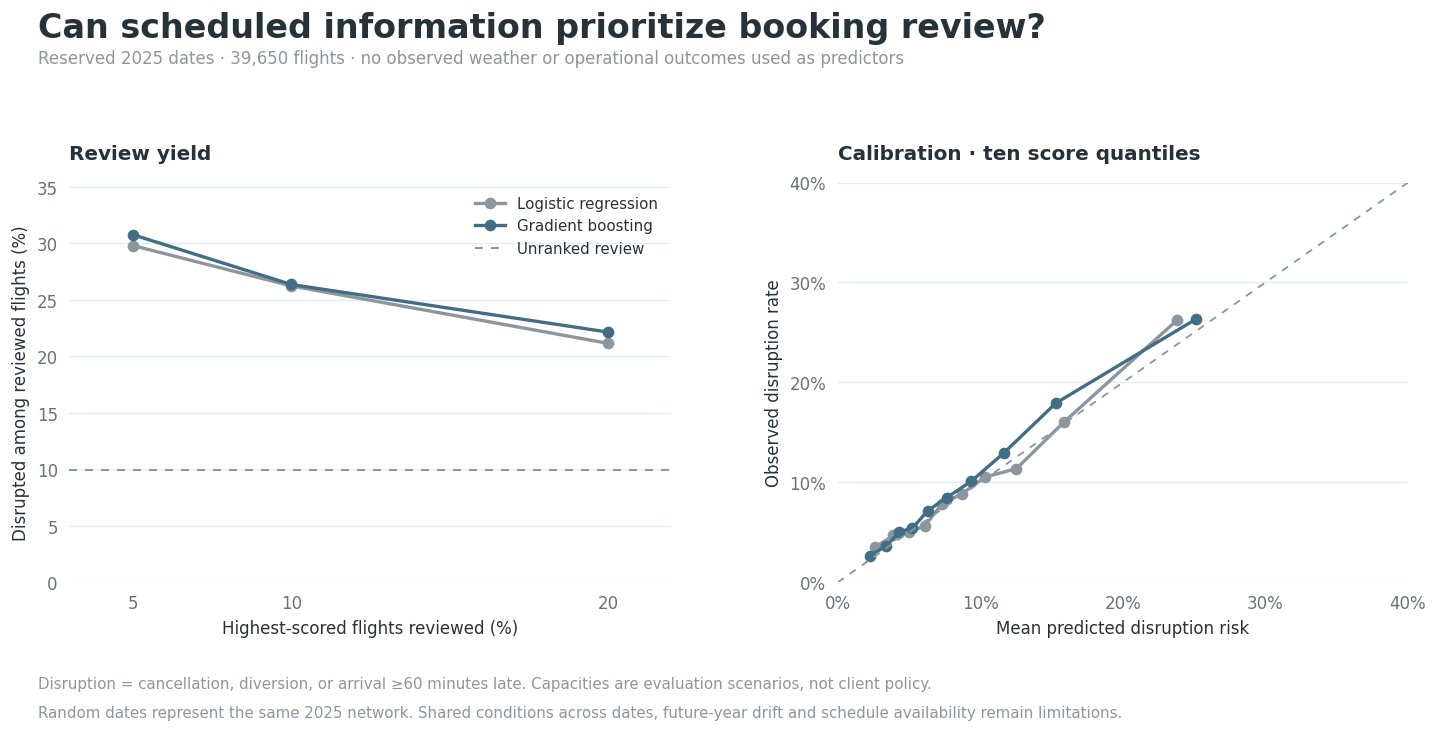

In [ ]:
ml_blue,ml_gray,ml_ink,ml_grid='#416D85','#8B969E','#26323A','#E6EBEE'
with plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'figure.facecolor':'white','axes.facecolor':'white','text.color':ml_ink,'axes.labelcolor':ml_ink,'svg.fonttype':'none'}):
    fig=plt.figure(figsize=(13.2,6.8))
    fig.text(.065,.95,'Can scheduled information prioritize booking review?',fontsize=20,weight='bold',va='top')
    fig.text(.065,.886,'Reserved 2025 dates · 39,650 flights · no observed weather or operational outcomes used as predictors',fontsize=10,color=ml_gray)
    ax1=fig.add_axes([.085,.25,.38,.49]);ax2=fig.add_axes([.57,.25,.36,.49])
    for ax in [ax1,ax2]:
        for spine in ax.spines.values():spine.set_visible(False)
        ax.tick_params(length=0,pad=7);ax.grid(axis='y',color=ml_grid,linewidth=.8);ax.set_axisbelow(True)
    for candidate,color,label in [(ml_lr,ml_gray,'Logistic regression'),(ml_gb,ml_blue,'Gradient boosting')]:
        cap=ml_capacity[ml_capacity.candidate.eq(candidate)]
        ax1.plot(cap.capacity*100,cap.precision*100,'o-',color=color,lw=2,label=label)
        observed,predicted=calibration_curve(ml_test_y,ml_test_predictions[candidate],n_bins=10,strategy='quantile')
        ax2.plot(predicted,observed,'o-',color=color,lw=2,label=label)
    ax1.axhline(ml_test_y.mean()*100,color=ml_gray,lw=1.2,ls=(0,(4,4)),label='Unranked review')
    ax1.set(xlabel='Highest-scored flights reviewed (%)',ylabel='Disrupted among reviewed flights (%)',xlim=(3,22),ylim=(0,max(35,ml_capacity.precision.max()*115)))
    ax1.set_xticks([5,10,20]);ax1.set_title('Review yield',loc='left',fontsize=12,weight='bold',pad=14)
    ax1.legend(frameon=False,fontsize=9,loc='upper right')
    ax2.plot([0,.4],[0,.4],color=ml_gray,lw=1.1,ls=(0,(4,4)))
    ax2.set(xlim=(0,.4),ylim=(0,.4),xlabel='Mean predicted disruption risk',ylabel='Observed disruption rate')
    ax2.set_xticks([0,.1,.2,.3,.4]);ax2.set_yticks([0,.1,.2,.3,.4])
    ax2.xaxis.set_major_formatter(PercentFormatter(1,decimals=0));ax2.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
    ax2.set_title('Calibration · ten score quantiles',loc='left',fontsize=12,weight='bold',pad=14)
    fig.text(.065,.12,'Disruption = cancellation, diversion, or arrival ≥60 minutes late. Capacities are evaluation scenarios, not client policy.',fontsize=9,color=ml_gray)
    fig.text(.065,.085,'Random dates represent the same 2025 network. Shared conditions across dates, future-year drift and schedule availability remain limitations.',fontsize=9,color=ml_gray)
    for ext in ['png','svg']:
        path=ML_DIR/f'schedule_model_review.{ext}';fig.savefig(path,dpi=220);ml_files[path.name]=path
    plt.show();plt.close(fig)


## F7 · Interpretation checkpoint and evidence export
Review the results below before considering weather. The schedule-only model is a risk-ranking research tool; fares, actual alternative availability, meeting outcomes and the benefit of changing a booking are not measured. No automated booking policy or financial saving is inferred.


In [ ]:
ml_selected_row=ml_assessment.set_index('candidate').loc[ml_selected]
ml_baseline_row=ml_assessment.set_index('candidate').loc['baseline']
ml_top10=ml_capacity[(ml_capacity.candidate==ml_selected)&ml_capacity.capacity.eq(.10)].iloc[0]
print('CV-selected candidate:',ml_selected)
print(f"Assessment Brier: {ml_selected_row.Brier:.5f}; baseline {ml_baseline_row.Brier:.5f}; relative error reduction {(1-ml_selected_row.Brier/ml_baseline_row.Brier):.1%}.")
print(f"Reviewing the highest-scored 10%: {ml_top10.precision:.1%} disruption among reviewed flights, {ml_top10.recall:.1%} of disruptions captured, lift {ml_top10.lift:.2f}×.")
print('Most reviewed flights still do not disrupt. A high score is a review flag, not a prediction of certain failure.')
print('The forward-quarter benchmarks are a separate test of seasonal extrapolation; compare each against its own baseline.')
ml_check('Raw data fingerprint unchanged',hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==ml_raw_hash)
ml_check('Original preparation still preserves raw data',flights[raw.columns].equals(raw))
ml_check('Every intended comparison completed',len(ml_cv_rows)==25 and len(ml_assessment)==3 and len(ml_robustness)==12)
ml_check('All predictions finite',all(np.isfinite(p).all() for p in ml_test_predictions.values()))
ml_check('No weather features',ml_features==ml_categorical+ml_numeric and all('weather' not in f.lower() for f in ml_features))
ml_validation_history=pd.DataFrame(ml_checks);ml_save(ml_validation_history,'validation_history')
ml_validation=ml_validation_history.drop_duplicates('check',keep='last').reset_index(drop=True)
assert ml_validation.passed.all(), 'An unresolved validation failure remains'
display(ml_validation);ml_save(ml_validation,'validation_checks')
ml_record={'selected':ml_selected,'family_winners':ml_family_winners,'feature_names':ml_features,'date_assignment_sha256':ml_date_hash,
           'assessment_status':'reserved from this study selection, not historically untouched','environment':ml_environment,
           'passed_checks':int(ml_validation.passed.sum()),'weather_added':False,
           'next_action':'Review schedule-only results with Burak before adding weather','execution':'sequential local validation; saved notebook outputs'}
(ML_DIR/'study_record.json').write_text(json.dumps(ml_record,indent=2));ml_files['study_record.json']=ML_DIR/'study_record.json'
import zipfile
ml_archive=ML_DIR/'schedule_classification_evidence.zip'
with zipfile.ZipFile(ml_archive,'w',zipfile.ZIP_DEFLATED) as z:
    for name,path in sorted(ml_files.items()):z.write(path,arcname=name)
print('Evidence ZIP:',ml_archive)
# Internal continuation checkpoint; excluded from the evidence ZIP.
import joblib
joblib.dump({k:globals()[k] for k in ['ml_oof','ml_family_winners','ml_selected','ml_test_predictions','ml_assessment','ml_capacity','ml_models']},ML_DIR/'runtime_checkpoint.joblib')
# Optional in Colab after reviewing this section:
# from google.colab import files
# files.download(str(ml_archive))


CV-selected candidate: boost_leaves15
Assessment Brier: 0.08462; baseline 0.08987; relative error reduction 5.8%.
Reviewing the highest-scored 10%: 26.4% disruption among reviewed flights, 26.4% of disruptions captured, lift 2.64×.
Most reviewed flights still do not disrupt. A high score is a review flag, not a prediction of certain failure.
The forward-quarter benchmarks are a separate test of seasonal extrapolation; compare each against its own baseline.


,check,passed,detail
0,Frozen date assignment reproduced,True,
1,Source rows preserved,True,
2,No date crosses partitions or folds,True,
3,No airport/date overlap,True,
4,Frozen sample sizes,True,
5,All months in both partitions,True,
6,All months in each development fold,True,
7,Target reconciliation,True,
8,Schedule-only explicit feature allowlist,True,
9,Numeric predictors finite or missing,True,


Evidence ZIP: /Users/burakataseven/Documents/ChatGPT/Chart_Champ_Datathon/analysis/ml_extension_2026-11-06/classification/outputs/schedule_classification_evidence.zip


['/Users/burakataseven/Documents/ChatGPT/Chart_Champ_Datathon/analysis/ml_extension_2026-11-06/classification/outputs/runtime_checkpoint.joblib']

### Results walkthrough · Schedule-only study
**What we tested:** 39,650 flights on 73 reserved dates across all 12 months; 3,958 disruptions (9.98%). Each date stayed entirely within its partition. Settings were selected on separate grouped development predictions.

| Model | Brier ↓ | Average precision ↑ | ROC AUC ↑ |
| --- | --- | --- | --- |
| Baseline | 0.08987 | 0.09982 | 0.50000 |
| Logistic regression | 0.08534 | 0.21392 | 0.68725 |
| Gradient boosting | 0.08462 | 0.22595 | 0.70773 |

**What it means:** development Brier selected 15-leaf boosting. Its assessment probability error is 5.8% lower than the constant baseline. The date-bootstrap Brier improvement over logistic regression is 0.000725, with a 95% interval of [-0.000299, 0.001811]. That interval includes zero: we cannot claim a reliable advantage over logistic regression from this comparison alone.

**Client use:** reviewing the highest-scored 3,965 flights (10%) finds 1,045 disruptions. That is 26.4% disruption among reviewed flights and 26.4% of all assessment disruptions, versus 10.0% expected under unranked review. Most flagged flights still operate without the defined disruption; most disruptions are outside this small review group. These are evaluation scenarios, not an approved review capacity or switching benefit.

**Probability caution:** boosting predicts an average 9.07%, while 9.98% disrupted. January and November subgroup Brier are slightly worse than their respective constant-baseline scores. Calibration has not been refitted using assessment outcomes.

**Harder checks:** whole-week fixed-setting Brier is 0.08939 for logistic regression and 0.09027 for boosting, versus 0.09343 baseline. In forward Q2/Q3/Q4, fixed-setting logistic Brier is 0.25226/0.13051/0.08763; boosting is 0.09416/0.08959/0.08534; the corresponding baselines are 0.09261/0.09279/0.08522. These use different settings and rows from the main comparison. They show poor seasonal extrapolation, especially for logistic regression, and no consistent superiority of boosting across future quarters. One year does not establish a reusable seasonal pattern. **Do not present these as validated live-flight probabilities.**

**Decision:** use this as the measured baseline for a historical replay and further experiments. The year was already explored, so this is not a historically untouched test. A later no-seasonality ablation and development-only calibration are separate planned experiments; they have not been performed here. The cross-validation baseline's pooled AUC may differ from 0.5 because each fold learns a different prevalence; this does not imply flight-specific predictive skill.


# Appendix G · Do unsupervised signals improve the risk model?
**Purpose:** test useful supporting methods rather than manufacture a composite score. K-means groups similar schedules; Isolation Forest measures unusual schedules. Neither algorithm learns disruption labels or directly returns a disruption probability. A cluster or anomaly score may enter the supervised classifier only if its incremental value is supported.

This is a new, exploratory extension after inspecting Appendix F. The same assessment dates are reused for a paired comparison, so they are **not a fresh confirmation set**. Freeze the following protocol before running G1. No weather is used here; schedule/weather regimes remain a later experiment after the weather join passes validation.

**Fixed design choices, not observed findings:** eight MiniBatch K-means clusters (random initialization, ten restarts), 200 Isolation Forest trees, seed 64. Inputs are log-distance, departure-clock cycles, annual cycles and weekday cycles. This defines broad schedule patterns, not airport weather or operational reliability groups. All imputation, scaling and unsupervised fitting happen inside each development training fold, without outcomes. The supervised learner uses Appendix F's selected boosting settings, unchanged. Compare schedule-only, +cluster distances, +anomaly score, and +both. No tuning follows from assessment results.

**Adoption rule:** an addition must improve pooled development Brier, then have a positive lower bound for paired assessment Brier improvement under both date and week bootstraps. Use 98.33% intervals for three additions (Bonferroni family-wise 95% across additions, conditional on fitted models). Passing this screen is only provisional: temporal robustness and calibration still need validation before deployment. Otherwise retain the simpler schedule score; keep unsupervised findings as diagnostics. Anomalies never receive hand-assigned risk points.


In [ ]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.stats import spearmanr

support_protocol={
    'purpose':'incremental value of target-free schedule representations',
    'cluster_k':8,'cluster_initialization':'random, 10 restarts','isolation_trees':200,'seed':ML_SEED,
    'variants':['schedule_only','cluster_distances','anomaly_score','both'],
    'selection':'development pooled Brier, then guarded paired assessment screen',
    'assessment':'reused after baseline results; exploratory, not fresh confirmation',
    'interval_level':1-.05/3,'weather_used':False,
    'adoption':'positive development improvement AND positive lower bound under date and week blocks; provisional only',
}
support_dir=ML_DIR/'unsupervised_support';support_dir.mkdir(exist_ok=True)
(support_dir/'protocol.json').write_text(json.dumps(support_protocol,indent=2))
support_Z=ml_data[['departure_sin','departure_cos','year_sin','year_cos']].copy()
support_Z['log_distance']=np.log1p(ml_data.DISTANCE)
support_Z['weekday_sin']=np.sin(2*np.pi*(ml_data.DAY_OF_WEEK-1)/7)
support_Z['weekday_cos']=np.cos(2*np.pi*(ml_data.DAY_OF_WEEK-1)/7)
assert np.isfinite(support_Z.to_numpy()).all()
assert not set(support_Z.columns)&ml_forbidden
support_base=ml_family_winners['Gradient boosting']
support_variants=['cluster_distances','anomaly_score','both']
support_cluster_cols=[f'cluster_distance_{i}' for i in range(8)]
support_names={
    'cluster_distances':support_cluster_cols,
    'anomaly_score':['schedule_anomaly'],
    'both':support_cluster_cols+['schedule_anomaly'],
}

def support_fit_representations(train_idx,seed=ML_SEED):
    transform=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
    z=transform.fit_transform(support_Z.iloc[train_idx])
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning)
        km=MiniBatchKMeans(n_clusters=8,init='random',n_init=10,batch_size=4096,random_state=seed).fit(z)
        iso=IsolationForest(n_estimators=200,max_samples=256,contamination='auto',random_state=seed,n_jobs=2).fit(z)
    assert np.isfinite(z).all() and np.isfinite(km.cluster_centers_).all()
    return transform,km,iso

def support_distances(a,b):
    # Explicit Euclidean distance avoids local BLAS matmul warning behavior.
    # Bounded chunks preserve the same geometry without a large 3D allocation.
    return np.concatenate([np.sqrt(np.square(a[i:i+256,None,:]-b[None,:,:]).sum(axis=2)) for i in range(0,len(a),256)],axis=0)

def support_transform(representations,indices):
    transform,km,iso=representations
    z=transform.transform(support_Z.iloc[indices])
    with threadpool_limits(limits=2):
        distances=support_distances(z,km.cluster_centers_)
        assert np.isfinite(distances).all()
        anomaly=-iso.score_samples(z)
    return pd.DataFrame(np.column_stack([distances,anomaly]),columns=support_cluster_cols+['schedule_anomaly'],index=indices)

def support_fit_predict(variant,train_idx,eval_idx,train_extra,eval_extra):
    extra=support_names[variant]
    train=ml_X.iloc[train_idx].copy();test=ml_X.iloc[eval_idx].copy()
    train[extra]=train_extra[extra].to_numpy();test[extra]=eval_extra[extra].to_numpy()
    model=ml_make_model(support_base)
    pre=model.named_steps['preprocess']
    pre.transformers=[(name,trans,ml_numeric+extra if name=='numbers' else cols) for name,trans,cols in pre.transformers]
    with threadpool_limits(limits=2):
        model.fit(train,ml_y[train_idx]);p=model.predict_proba(test)[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return model,p

print('Protocol frozen. Unsupervised inputs:',support_Z.columns.tolist())
print('Supervised comparator:',support_base,'; assessment reuse explicitly recorded.')


Protocol frozen. Unsupervised inputs: ['departure_sin', 'departure_cos', 'year_sin', 'year_cos', 'log_distance', 'weekday_sin', 'weekday_cos']
Supervised comparator: boost_leaves15 ; assessment reuse explicitly recorded.


## G1 · Compare representations inside grouped development folds
Cluster distances use all centroids rather than treating cluster IDs as ordered numbers. The anomaly score is continuous; no arbitrary contamination threshold becomes a disruption flag. No assessment features participate in representation fitting. A local numerical warning in K-means++ initialization and matrix distance calculations was investigated before support-model assessment. The implementation now uses random initialization and explicit chunked Euclidean distances, with finite-value checks; the development comparison was rerun under this corrected frozen configuration.


In [ ]:
support_oof={'schedule_only':ml_oof[support_base].copy()}
support_oof.update({v:np.full(len(ml_data),np.nan) for v in support_variants})
support_fit_log=[]
for fold in range(5):
    train_idx=np.flatnonzero(ml_dev&(ml_data.cv_fold.to_numpy()!=fold))
    val_idx=np.flatnonzero(ml_dev&(ml_data.cv_fold.to_numpy()==fold))
    assert not set(ml_data.iloc[train_idx].date)&set(ml_data.iloc[val_idx].date)
    reps=support_fit_representations(train_idx)
    train_extra=support_transform(reps,train_idx);val_extra=support_transform(reps,val_idx)
    for variant in support_variants:
        _,p=support_fit_predict(variant,train_idx,val_idx,train_extra,val_extra)
        support_oof[variant][val_idx]=p
        support_fit_log.append({'fold':fold,'variant':variant,'training_dates':ml_data.iloc[train_idx].date.nunique(),'validation_dates':ml_data.iloc[val_idx].date.nunique()})
    print(f'Support representations: fold {fold+1}/5 complete',flush=True)
assert all(np.isfinite(p[ml_dev]).all() and np.isnan(p[ml_test]).all() for p in support_oof.values())
support_cv=pd.DataFrame([{'variant':v,**ml_score(ml_y[ml_dev],p[ml_dev])} for v,p in support_oof.items()])
support_cv['Brier_improvement']=support_cv.set_index('variant').loc['schedule_only','Brier']-support_cv.Brier
support_selected=support_cv.sort_values(['Brier','variant']).iloc[0].variant
support_cv.to_csv(support_dir/'development_metrics.csv',index=False)
pd.DataFrame(support_fit_log).to_csv(support_dir/'fold_fit_log.csv',index=False)
(support_dir/'selection.json').write_text(json.dumps({'selected':support_selected,'assessment_evaluated':False},indent=2))
display(support_cv[['variant','Brier','Brier_improvement','AP','ROC_AUC']].round(6))
print('Development choice frozen:',support_selected)


Support representations: fold 1/5 complete


Support representations: fold 2/5 complete


Support representations: fold 3/5 complete


Support representations: fold 4/5 complete


Support representations: fold 5/5 complete


,variant,Brier,Brier_improvement,AP,ROC_AUC
0,schedule_only,0.084205,0.000000,0.190599,0.679231
1,cluster_distances,0.084166,0.000039,0.190770,0.678854
2,anomaly_score,0.084223,-0.000018,0.190248,0.679062
3,both,0.084170,0.000035,0.190665,0.678155


Development choice frozen: cluster_distances


## G2 · Assess incremental value and retain negative results
Compare every fixed addition on exactly the same assessment flights. These are paired differences from the schedule-only boosting model, not comparisons against different train/test splits. Show negative and inconclusive results as well as improvements.


In [ ]:
support_train_idx=np.flatnonzero(ml_dev);support_test_idx=np.flatnonzero(ml_test)
support_reps=support_fit_representations(support_train_idx)
support_train_extra=support_transform(support_reps,support_train_idx)
support_test_extra=support_transform(support_reps,support_test_idx)
support_predictions={'schedule_only':ml_test_predictions[support_base]}
support_models={}
for variant in support_variants:
    model,p=support_fit_predict(variant,support_train_idx,support_test_idx,support_train_extra,support_test_extra)
    support_models[variant]=model;support_predictions[variant]=p
support_test=pd.DataFrame([{'variant':v,**ml_score(ml_y[ml_test],p)} for v,p in support_predictions.items()])
support_test['Brier_improvement']=support_test.set_index('variant').loc['schedule_only','Brier']-support_test.Brier
support_ci_rows=[]
support_dates=ml_data.loc[ml_test,'date'].reset_index(drop=True)
for unit,groups in [('date',support_dates),('calendar_week',support_dates-pd.to_timedelta(support_dates.dt.dayofweek,unit='D'))]:
    for variant in support_variants:
        delta=(ml_y[ml_test]-support_predictions['schedule_only'])**2-(ml_y[ml_test]-support_predictions[variant])**2
        blocks=pd.DataFrame({'group':groups,'delta':delta}).groupby('group').delta.agg(['sum','size'])
        draws=np.random.default_rng(ML_SEED).integers(0,len(blocks),size=(4000,len(blocks)))
        values=blocks['sum'].to_numpy()[draws].sum(1)/blocks['size'].to_numpy()[draws].sum(1)
        lo,hi=np.quantile(values,[.05/6,1-.05/6])
        support_ci_rows.append({'variant':variant,'unit':unit,'groups':len(blocks),'Brier_improvement':delta.mean(),'lower_98_33':lo,'upper_98_33':hi})
support_ci=pd.DataFrame(support_ci_rows)
support_gate=[]
for variant in support_variants:
    gain=float(support_cv.set_index('variant').loc[variant,'Brier_improvement'])
    supported=bool(support_ci[support_ci.variant.eq(variant)].lower_98_33.gt(0).all())
    support_gate.append({'variant':variant,'development_improves':gain>0,'assessment_intervals_positive':supported,'passes_incremental_screen':gain>0 and supported,
                         'status':'provisional; temporal/calibration validation required' if gain>0 and supported else 'do not add to current risk score'})
support_gate=pd.DataFrame(support_gate)
display(support_test[['variant','Brier','Brier_improvement','AP','ROC_AUC']].round(6))
display(support_ci.round(6));display(support_gate)
for name,table in [('assessment_metrics',support_test),('paired_intervals',support_ci),('adoption_screen',support_gate)]:table.to_csv(support_dir/f'{name}.csv',index=False)


,variant,Brier,Brier_improvement,AP,ROC_AUC
0,schedule_only,0.084615,0.000000,0.225948,0.707729
1,cluster_distances,0.084223,0.000392,0.233487,0.711140
2,anomaly_score,0.084530,0.000085,0.227563,0.708594
3,both,0.084233,0.000382,0.233301,0.711078


,variant,unit,groups,Brier_improvement,lower_98_33,upper_98_33
0,cluster_distances,date,73,0.000392,-0.000082,0.000854
1,anomaly_score,date,73,0.000085,-0.000000,0.000189
2,both,date,73,0.000382,-0.000095,0.000843
3,cluster_distances,calendar_week,42,0.000392,-0.000141,0.000879
4,anomaly_score,calendar_week,42,0.000085,-0.000010,0.000201
5,both,calendar_week,42,0.000382,-0.000152,0.000866


,variant,development_improves,assessment_intervals_positive,passes_incremental_screen,status
0,cluster_distances,True,False,False,do not add to current risk score
1,anomaly_score,False,False,False,do not add to current risk score
2,both,True,False,False,do not add to current risk score


## G3 · Check whether the unsupervised structure is reproducible
Silhouette describes geometric separation, not flight reliability. Adjusted Rand index compares cluster assignments across date-bootstrap refits; Spearman correlation compares anomaly rankings. Both use a fixed development anchor sample. These diagnostics do not establish calibrated uncertainty or a probability of disruption. We report their actual values rather than invent meaningful cluster labels or a minimum passing score after seeing the results.


In [ ]:
support_rng=np.random.default_rng(ML_SEED)
support_anchor=support_rng.choice(support_train_idx,size=min(3000,len(support_train_idx)),replace=False)
support_scale,support_km,support_iso=support_reps
support_anchor_z=support_scale.transform(support_Z.iloc[support_anchor])
with threadpool_limits(limits=2):
    support_anchor_labels=support_km.predict(support_anchor_z)
    support_anchor_anomaly=-support_iso.score_samples(support_anchor_z)
    support_silhouette=silhouette_score(support_distances(support_anchor_z,support_anchor_z),support_anchor_labels,metric='precomputed')
support_date_rows={d:np.flatnonzero(ml_dev&ml_data.date.eq(d).to_numpy()) for d in sorted(ml_data.loc[ml_dev,'date'].unique())}
support_dates_available=list(support_date_rows)
support_stability=[]
for repetition in range(3):
    dates=support_rng.choice(support_dates_available,size=len(support_dates_available),replace=True)
    train_idx=np.concatenate([support_date_rows[d] for d in dates])
    scale,km,iso=support_fit_representations(train_idx,ML_SEED+repetition+1)
    z=scale.transform(support_Z.iloc[support_anchor])
    with threadpool_limits(limits=2):
        ari=adjusted_rand_score(support_anchor_labels,km.predict(z))
        corr=spearmanr(support_anchor_anomaly,-iso.score_samples(z)).statistic
    support_stability.append({'bootstrap_refit':repetition+1,'cluster_ARI':ari,'anomaly_rank_Spearman':corr})
support_stability=pd.DataFrame(support_stability)
with threadpool_limits(limits=2):
    support_all_labels=support_km.predict(support_scale.transform(support_Z))
support_profiles=ml_data[['partition','DISTANCE','departure_hour','major_disruption']].copy()
support_profiles['cluster']=support_all_labels
support_profiles=support_profiles.groupby(['cluster','partition']).agg(flights=('major_disruption','size'),mean_distance_miles=('DISTANCE','mean'),mean_departure_hour=('departure_hour','mean'),observed_disruption=('major_disruption','mean')).reset_index()
print('Development anchor silhouette:',round(support_silhouette,4))
display(support_stability.round(4));display(support_profiles.round(4))
print('Outcome rates describe the discovered groups; no outcomes were inputs to clustering.')
support_stability.to_csv(support_dir/'stability.csv',index=False);support_profiles.to_csv(support_dir/'cluster_profiles.csv',index=False)
assert len(support_fit_log)==15 and len(support_test)==4
assert all(np.isfinite(p).all() for p in support_predictions.values())
assert hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==ml_raw_hash
support_record={'silhouette':float(support_silhouette),'selected_by_development':support_selected,
                'adoption_screen':support_gate.to_dict('records'),'weather_used':False,
                'raw_unchanged':True,'all_fold_preprocessing_training_only':True,
                'assessment_reuse':'exploratory paired comparison; not new confirmation data'}
(support_dir/'study_record.json').write_text(json.dumps(support_record,indent=2))
print('Support experiment complete; no automatic modification of the score or baseline model.')


Development anchor silhouette: 0.1209


,bootstrap_refit,cluster_ARI,anomaly_rank_Spearman
0,1,0.3205,0.7807
1,2,0.2905,0.8532
2,3,0.3927,0.8345


,cluster,partition,flights,mean_distance_miles,mean_departure_hour,observed_disruption
0,0,assessment,6519,846.1427,18.9590,0.1557
1,0,development,24952,848.2203,18.9659,0.1247
2,1,assessment,4163,854.0399,11.2897,0.0855
3,1,development,20373,846.9943,10.9696,0.0841
4,2,assessment,5142,857.0825,18.5541,0.1402
5,2,development,22132,848.5100,18.6650,0.1548
6,3,assessment,4675,689.5155,12.5345,0.1040
7,3,development,19671,742.0344,11.8790,0.0956
8,4,assessment,5125,939.3112,8.4730,0.0484
9,4,development,16831,944.6200,8.5722,0.0475


Outcome rates describe the discovered groups; no outcomes were inputs to clustering.
Support experiment complete; no automatic modification of the score or baseline model.


### Results walkthrough · Unsupervised support
**Question:** does learning schedule patterns without outcome labels improve the supervised disruption classifier?

| Added information | Assessment Brier ↓ | Improvement over schedule only | Average precision ↑ |
| --- | --- | --- | --- |
| schedule_only | 0.084615 | 0.000000 | 0.225948 |
| cluster_distances | 0.084223 | 0.000392 | 0.233487 |
| anomaly_score | 0.084530 | 0.000085 | 0.227563 |
| both | 0.084233 | 0.000382 | 0.233301 |

**Selection and evidence:** development Brier selected `cluster_distances`. The paired interval table above uses wider 98.33% intervals to account for testing three additions. Positive improvement means lower probability error. Reused assessment dates make this an exploratory extension, not independent confirmation.

**Structure quality:** the development-anchor silhouette is 0.121. Across three whole-date bootstrap refits, cluster ARI ranges from 0.291 to 0.393, and anomaly-rank correlation from 0.781 to 0.853. The low separation and modest cluster agreement do not support treating these eight groups as stable operational types. These measures describe geometric stability, not the probability of disruption. Cluster outcome rates are displayed only after fitting and never fed into the unsupervised algorithms.

**Decision:** No addition passes the declared incremental-value screen. Keep the schedule-only score; retain clustering and anomaly detection as research diagnostics. Neither cluster membership nor an anomaly flag receives a hand-assigned risk weight. Negative findings are retained because they prevent unnecessary complexity.


# Appendix H · MVP framework and next analytical gates
**User-selected scope:** a clearly labeled **2025 historical replay, Boston → Chicago**. Search BOS → ORD or MDW and list recorded scheduled flights. These are not live tickets or a complete inventory of every airline. No fares or availability are invented.

**Verified catalog:** the 12 monthly source files contain 8,594 BOS → ORD/MDW flights. The reserved dates have 16–30 options per day. The proposed initial replay date is **2025-11-04**, the first reserved November date, selected without looking at prediction quality or outcomes; it has 22 options (20 ORD, 2 MDW). These catalog counts were independently extracted from the verified monthly sources; extraction evidence is in `analysis/ml_extension_2026-11-06/mvp/`. The student sample overlaps the population and must not be appended to it.

**Data flow:** verified flight sources → audited schedule/weather features → grouped model comparison → frozen model and evidence → cached scores for reserved-date flight options → local search interface. Keep actual outcomes in a separate field, hidden until the demo's optional outcome reveal. The interface has not been built yet.

| Component | Purpose and valid reason | Current status / acceptance gate |
| --- | --- | --- |
| Schedule classification | Predict cancellation, diversion or arrival ≥60 minutes late; compare prevalence, logistic and boosting. | Executed in F; useful within-year ranking, temporal limitations retained. |
| Schedule clustering and anomaly detection | Test target-free context features and identify unfamiliar schedules. | Executed in G; adoption governed by measured incremental value, not a need to display more algorithms. |
| Destination and origin weather joins | Align airport weather with scheduled local arrival/departure dates. | Completed in I1–I4: nine schedule discrepancies excluded from this study; missing weather retained; shared station-days purged from training. |
| Weather classifier comparison | Test retrospective value of origin/destination daily measurements. | Executed in Appendix I on identical eligible rows/folds. Both-weather boosting selected; Appendix J retains its original probabilities after testing calibration. Replay transfer is evaluated in K, with calibration/stability limits retained. |
| Weather regimes and novelty | Test whether weather-context clusters/anomaly scores add value. | Not fitted. Schedule-only unsupervised additions failed their inclusion screen; any weather-context extension must independently justify itself. |
| Calibration and seasonal sensitivity | Evaluate the probability scale and investigate forward-quarter failures. | **Calibration completed in J:** neither sigmoid nor isotonic improves the current model; retain original probabilities and report residual understatement. K investigates calendar extrapolation with a fixed ablation and forward-quarter stress. Future-year/as-of forecast validation remains unavailable. |
| Conditional quantile regression | Estimate typical and tail arrival delay for completed, non-diverted flights if a buffer recommendation is needed. | **Deferred.** Does not cover cancellation/diversion; do not substitute its output for all-flight disruption risk. |
| Airport-profile clustering / ensembles | Optional portfolio interpretation or combination of complementary models. | **Deferred unless useful.** Outcome-based profiles need fold/past-only construction; ensembles require measured incremental gain, not invented weights. |
| Replay interface | Show local times, airport, carrier, probability, source coverage and observed-weather context; sort feasible options. | **Interface not built.** K validates the reserved-date population score cache, separation, feature parity and technical risks. Build the private display under its score contract; preserve coverage/uncertainty labels. |

**Weather limitations:** available weather is daily observed station data, not a forecast issued before booking or conditions at the exact arrival minute. A weather-assisted replay is retrospective even if labels are held out. Show the observation date, station distance and missingness; preserve trace/unknown distinctions. Origin `FL_DATE` alone does not establish destination local arrival date. Weather may span adjacent dates, so audit destination-weather keys across folds and group/purge overlaps before comparing models. The 2025 record is not multiyear climatology. Live use would require archived forecasts/as-of features and prospective validation, neither of which is currently available.

**Score policy:** one estimated probability from the validated supervised model. Do not add arbitrary airline, snow, cluster or anomaly points. Keep unfamiliarity/data coverage separate from disruption probability. Model explanations describe associations, not causal explanations of why a flight will fail. Any future historic delay-rate feature must use only eligible training history with support counts and appropriate availability timing.

**Next step:** build the private historical replay interface using K’s validated score cache and display contract. I establishes the weather model; J rejects extra calibration; K documents model choices, transfer and technical robustness with residual risks. Preserve the three main charts; add analysis only when it resolves a decision.

Methods: [scikit-learn grouped evaluation](https://scikit-learn.org/stable/modules/cross_validation.html), [probability calibration](https://scikit-learn.org/stable/modules/calibration.html), [clustering](https://scikit-learn.org/stable/modules/clustering.html), [anomaly detection](https://scikit-learn.org/stable/modules/outlier_detection.html), [Python time-zone handling](https://docs.python.org/3/library/zoneinfo.html).


# Appendix I · Does observed weather improve retrospective flight-risk estimates?
Run original imports, Drive loader and preparation, then I1–I8 sequentially. This study uses observed daily station weather, not booking-time forecasts. Earlier model results remain intact.


## I1 · Audit source versions and weather meaning
**Why:** ensure the enrichment is what we think it is before using it. **Inputs:** verified 2025 weather and a pinned end-of-2025 airport-reference snapshot. **Output:** source checks and an airport/time-zone lookup. The current airport reference missed PBI; the historical snapshot covers all source codes without guessing an alias.

Weather has daily minimum/maximum temperature (°F), precipitation, snowfall and snow depth (inches), plus trace indicators. Its average temperature is a derived min/max midpoint, so it is omitted as redundant. Wind, visibility and forecasts are absent. Reporting gaps stay unknown.

Airport source: [pinned airportsdata CSV](https://github.com/mborsetti/airportsdata/blob/ff0a52a77b715214bca5341a85b63f36a6d28937/airportsdata/airports.csv). Weather provenance: [repository methods](https://github.com/MikaIsmayilov/Chart_Champ_Datathon/blob/main/extra_data/Weather%20Data/README_weather.md). These are reference data, not instructions. The airport database is community maintained; the next step checks its consistency with scheduled clocks.


In [ ]:
import os, sys, json, hashlib, warnings, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
from zoneinfo import ZoneInfo

assert 'raw' in globals() and 'flights' in globals(), 'Run original imports, Drive loader and preparation first.'
WEATHER_STUDY_DIR=Path(os.environ.get('CHART_CHAMP_WEATHER_STUDY_DIR',str(OUTPUT_DIR/'weather_study')))
WEATHER_STUDY_DIR.mkdir(parents=True,exist_ok=True)
wt_checks=[]
def wt_check(name,passed,detail=''):
    wt_checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    assert passed,f'{name}: {detail}'
def wt_save(frame,name):frame.to_csv(WEATHER_STUDY_DIR/f'{name}.csv',index=False)
def wt_source(env_name,filename,url,checksum):
    candidates=[Path(os.environ[env_name])] if os.environ.get(env_name) else []
    candidates += [DATA_DIR/filename,WEATHER_STUDY_DIR/'source_cache'/filename]
    path=next((p for p in candidates if p.is_file()),candidates[-1])
    if not path.is_file():
        data=urllib.request.urlopen(url,timeout=60).read()
        assert hashlib.sha256(data).hexdigest()==checksum,'Source changed; review before use.'
        path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(data)
    wt_check(f'Checksum: {filename}',hashlib.sha256(path.read_bytes()).hexdigest()==checksum)
    return path
wt_airport_url='https://raw.githubusercontent.com/mborsetti/airportsdata/ff0a52a77b715214bca5341a85b63f36a6d28937/airportsdata/airports.csv'
wt_airport_path=wt_source('CHART_CHAMP_AIRPORT_PATH','airports_2025.csv',wt_airport_url,'f9b3efdbd6193e7c30bc908db828be7f8bd1fcda4408b46db1f71ff487d8fd87')
wt_weather_path=wt_source('CHART_CHAMP_WEATHER_PATH','airport_weather_2025.csv',
    'https://raw.githubusercontent.com/MikaIsmayilov/Chart_Champ_Datathon/refs/heads/main/extra_data/Weather%20Data/airport_weather_2025.csv',
    'c41e15635d39f83e4c57759a5ca139cef6750ab6297058e1942c67cadf0ed741')
wt_airports=pd.read_csv(wt_airport_path)
wt_codes=set(raw.ORIGIN)|set(raw.DEST)
wt_airports=wt_airports[wt_airports.iata.isin(wt_codes)].copy()
wt_check('All 327 airport codes mapped uniquely',set(wt_airports.iata)==wt_codes and wt_airports.iata.is_unique)
wt_check('All mapped time zones valid',all(ZoneInfo(z) for z in wt_airports.tz.unique()))
wt_tz=wt_airports.set_index('iata').tz.to_dict()
wt_weather=pd.read_csv(wt_weather_path,parse_dates=['date'])
wt_weather_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(wt_weather,index=True).values.tobytes()).hexdigest()
wt_raw_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()
wt_check('Weather keys unique and present',not wt_weather.duplicated(['airport_code','date']).any() and wt_weather[['airport_code','date','station_id']].notna().all().all())
wt_check('Weather source dimensions',len(wt_weather)==327*365 and wt_weather.airport_code.nunique()==327 and wt_weather.groupby('airport_code').date.nunique().eq(365).all())
wt_check('One station per airport',wt_weather.groupby('airport_code').station_id.nunique().eq(1).all())
wt_check('Daily min/max temperature order',not wt_weather.min_temp_f.gt(wt_weather.max_temp_f).any())
wt_check('Weather measurements nonnegative',all(wt_weather[c].dropna().ge(0).all() for c in ['precip_in','snowfall_in','snow_depth_in']))
wt_check('Trace encoding recognized',all(set(wt_weather[c].dropna().unique()).issubset({'Y'}) for c in ['precip_trace','snow_trace']))
wt_check('Trace values are recorded as zero',all(wt_weather.loc[wt_weather[t].eq('Y'),v].eq(0).all() for t,v in [('precip_trace','precip_in'),('snow_trace','snowfall_in')]))
wt_midpoint=(wt_weather.min_temp_f+wt_weather.max_temp_f)/2
wt_midpoint_error=(wt_weather.avg_temp_f-wt_midpoint).abs()
wt_check('Derived average agrees with rounded min/max midpoint',wt_midpoint_error.dropna().le(.11).all())
wt_save(wt_airports[['iata','icao','name','tz','country']],'airport_timezone_reference')
print(f'Airport codes mapped: {len(wt_airports)}. Weather rows: {len(wt_weather):,}.')
print('Average temperature is derived, so the model will use min/max and omit the redundant average.')
print('Daily observations remain retrospective context; source observation-time/quality flags are not retained in this extract.')


Airport codes mapped: 327. Weather rows: 119,355.
Average temperature is derived, so the model will use min/max and omit the redundant average.
Daily observations remain retrospective context; source observation-time/quality flags are not retained in this extract.


## I2 · Derive scheduled local arrival dates
**Why:** the flight date describes departure at the origin; arrival can be on another local date. Joining destination weather to the departure date can select the wrong record.

**Method:** scheduled departure date/time → origin time zone → UTC → add scheduled duration → destination time zone. Compare the derived arrival clock with the recorded scheduled arrival clock. No actual departure/arrival times or delays enter this derivation. Handle 2400 explicitly; flag ambiguous/nonexistent daylight-saving clock times rather than guess.

**Decision:** nine clock/duration discrepancies were independently confirmed in the monthly population files. Three coincide with the previously flagged timing cases; five concern dates adjacent to daylight-saving changes. Their causes are unresolved. Preserve all source rows; exclude unresolved schedules from this paired weather study. A discrepancy is not a reason to edit the original record.


In [ ]:
wt=flights.copy(deep=True)
wt['source_row']=np.arange(len(wt))
wt['origin_tz']=wt.ORIGIN.map(wt_tz);wt['destination_tz']=wt.DEST.map(wt_tz)
wt['scheduled_departure_local']=wt.date+pd.to_timedelta(wt.departure_minutes,unit='m')+pd.to_timedelta(wt.departure_midnight_2400.astype(int),unit='D')
wt['scheduled_departure_utc']=pd.Series(pd.NaT,index=wt.index,dtype='datetime64[ns, UTC]')
for zone,idx in wt.groupby('origin_tz').groups.items():
    # Ambiguous/nonexistent DST clock times are flagged, never silently guessed.
    local=wt.loc[idx,'scheduled_departure_local'].dt.tz_localize(zone,ambiguous='NaT',nonexistent='NaT')
    wt.loc[idx,'scheduled_departure_utc']=local.dt.tz_convert('UTC')
wt['scheduled_arrival_utc']=wt.scheduled_departure_utc+pd.to_timedelta(wt.CRS_ELAPSED_TIME,unit='m')
wt['scheduled_arrival_local']=pd.NaT
for zone,idx in wt.groupby('destination_tz').groups.items():
    wt.loc[idx,'scheduled_arrival_local']=wt.loc[idx,'scheduled_arrival_utc'].dt.tz_convert(zone).dt.tz_localize(None)
wt['origin_weather_date']=wt.scheduled_departure_local.dt.normalize()
wt['destination_weather_date']=wt.scheduled_arrival_local.dt.normalize()
wt['derived_arrival_minutes']=wt.scheduled_arrival_local.dt.hour*60+wt.scheduled_arrival_local.dt.minute
wt['clock_difference_minutes']=((wt.derived_arrival_minutes-wt.arrival_minutes+720)%1440)-720
wt['schedule_join_valid']=wt.scheduled_departure_utc.notna()&wt.CRS_ELAPSED_TIME.gt(0)&wt.clock_difference_minutes.eq(0)
wt['arrival_day_offset']=(wt.destination_weather_date-wt.date).dt.days
wt['schedule_date_issue']=np.select([
    wt.scheduled_departure_utc.isna(),wt.CRS_ELAPSED_TIME.isna()|wt.CRS_ELAPSED_TIME.le(0),~wt.clock_difference_minutes.eq(0)],
    ['ambiguous/nonexistent scheduled departure','missing/nonpositive scheduled duration','scheduled arrival clock disagrees'],default='none')
wt_date_summary=wt.groupby('schedule_date_issue',dropna=False).agg(flights=('source_row','size'),disruptions=('major_disruption','sum')).reset_index()
wt_offsets=wt[wt.schedule_join_valid].groupby('arrival_day_offset').size().rename('flights').reset_index()
wt_save(wt_date_summary,'scheduled_date_audit');wt_save(wt_offsets,'scheduled_arrival_day_offsets')
wt_date_issues=wt.loc[~wt.schedule_join_valid,['source_row']+flight_key+['CRS_ARR_TIME','CRS_ELAPSED_TIME','origin_tz','destination_tz','clock_difference_minutes','schedule_date_issue']]
wt_save(wt_date_issues,'scheduled_date_issues')
wt_check('Schedule date derivation preserves source rows',len(wt)==len(raw) and wt[raw.columns].equals(raw))
wt_check('No actual times or delays in arrival-date derivation',wt.loc[wt.schedule_join_valid,'scheduled_arrival_local'].notna().all())
display(wt_date_summary);display(wt_offsets)
print('Inspect flagged rows before advancing; all raw rows remain in the master table.')
display(wt_date_issues.head(12))


,schedule_date_issue,flights,disruptions
0,none,199991,19482
1,scheduled arrival clock disagrees,9,2


,arrival_day_offset,flights
0,-1,12
1,0,193773
2,1,6206


Inspect flagged rows before advancing; all raw rows remain in the master table.


,source_row,FL_DATE,OP_UNIQUE_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,CRS_ELAPSED_TIME,origin_tz,destination_tz,clock_difference_minutes,schedule_date_issue
11992,11992,2025-11-01,WN,4451,SFO,BWI,2105,415,250.0,America/Los_Angeles,America/New_York,-60,scheduled arrival clock disagrees
30185,30185,2025-11-01,WN,1288,LAX,BWI,2100,400,240.0,America/Los_Angeles,America/New_York,-60,scheduled arrival clock disagrees
32128,32128,2025-03-08,DL,872,LGA,MIA,1805,2130,265.0,America/New_York,America/New_York,60,scheduled arrival clock disagrees
48169,48169,2025-02-16,DL,2312,ATL,EWR,1459,1652,123.0,America/New_York,America/New_York,10,scheduled arrival clock disagrees
111816,111816,2025-09-16,YX,5628,LGA,PIT,1630,1859,99.0,America/New_York,America/New_York,-50,scheduled arrival clock disagrees
120568,120568,2025-11-01,WN,5360,SMF,MCO,2255,555,240.0,America/Los_Angeles,America/New_York,-60,scheduled arrival clock disagrees
126800,126800,2025-11-01,WN,6069,LAX,MCO,2230,515,225.0,America/Los_Angeles,America/New_York,-60,scheduled arrival clock disagrees
135019,135019,2025-09-25,YX,5750,MEM,LGA,1109,1605,165.0,America/Chicago,America/New_York,-71,scheduled arrival clock disagrees
171370,171370,2025-04-03,DL,2426,MSP,JAX,1351,1739,166.0,America/Chicago,America/New_York,-2,scheduled arrival clock disagrees


## I3 · Join origin and destination weather
**Why:** attach daily weather to each flight without duplicating flights or confusing missing measurements with clear conditions.

**Keys:** origin airport + scheduled local departure date; destination airport + derived scheduled local arrival date. Each is a many-to-one join. Temperature, precipitation and snow are numeric measurements; trace flags distinguish a measured trace from a reported zero. Missing snow remains unknown. Missing weather alone does not remove a flight.

**Interpretation:** this attaches a *daily station observation*, not the weather at the exact flight minute. Source reporting-day windows can vary and observation-time flags are absent here. Even correctly aligned daily weather can include conditions occurring after the flight. Thus it is retrospective information, not an available booking-time predictor. See [NOAA daily-data definitions](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt).


In [ ]:
wt_measurements=['min_temp_f','max_temp_f','precip_in','snowfall_in','snow_depth_in']
wt_weather_work=wt_weather.copy()
for name,value in [('precip_trace_flag','precip_in'),('snow_trace_flag','snowfall_in')]:
    original='precip_trace' if name.startswith('precip') else 'snow_trace'
    wt_weather_work[name]=wt_weather_work[original].eq('Y').astype(float).where(wt_weather_work[value].notna())
wt_inputs=wt_measurements+['precip_trace_flag','snow_trace_flag']
wt_join_columns=['airport_code','date','station_id','station_distance_km']+wt_inputs
for endpoint,airport,date_col in [('origin','ORIGIN','origin_weather_date'),('destination','DEST','destination_weather_date')]:
    renamed=wt_weather_work[wt_join_columns].rename(columns={c:f'{endpoint}_{c}' for c in wt_join_columns})
    wt=wt.merge(renamed,left_on=[airport,date_col],right_on=[f'{endpoint}_airport_code',f'{endpoint}_date'],how='left',validate='many_to_one',sort=False)
    wt_check(f'{endpoint} join preserves rows and ordering',len(wt)==200000 and wt.source_row.eq(np.arange(200000)).all())
    # Exclude unreliable destination-key assignments, but retain their raw master rows.
    if endpoint=='destination':wt.loc[~wt.schedule_join_valid,[f'{endpoint}_{c}' for c in wt_inputs]]=np.nan
wt['weather_study_eligible']=wt.schedule_join_valid
wt_coverage=[]
for endpoint in ['origin','destination']:
    e=wt[wt.weather_study_eligible]
    for field in ['station_id']+wt_measurements:
        wt_coverage.append({'endpoint':endpoint,'field':field,'flights':len(e),'reported':int(e[f'{endpoint}_{field}'].notna().sum()),'coverage':e[f'{endpoint}_{field}'].notna().mean()})
wt_coverage=pd.DataFrame(wt_coverage);wt_save(wt_coverage,'weather_join_coverage')
wt_check('All raw values preserved after both joins',wt[raw.columns].equals(raw))
wt_check('Missing snowfall remains missing',all(wt[f'{p}_snow_trace_flag'].isna().eq(wt[f'{p}_snowfall_in'].isna()).all() for p in ['origin','destination']))
wt_check('No duplicated flight keys after joins',not wt.duplicated(flight_key).any())
wt_missing=wt.loc[wt.weather_study_eligible&wt.destination_station_id.isna(),['source_row']+flight_key+['destination_weather_date']]
wt_save(wt_missing,'unmatched_destination_weather')
display(wt_coverage.round(4))
print('Unmatched destination weather dates:',wt_missing.destination_weather_date.value_counts().to_dict())
print('Incomplete weather measurements stay missing. No weather-based row deletion or zero-filling is applied.')


,endpoint,field,flights,reported,coverage
0,origin,station_id,199991,199991,1.0000
1,origin,min_temp_f,199991,199040,0.9952
2,origin,max_temp_f,199991,199108,0.9956
3,origin,precip_in,199991,198582,0.9930
4,origin,snowfall_in,199991,169087,0.8455
5,origin,snow_depth_in,199991,157165,0.7859
6,destination,station_id,199991,199977,0.9999
7,destination,min_temp_f,199991,199064,0.9954
8,destination,max_temp_f,199991,199095,0.9955
9,destination,precip_in,199991,198590,0.9930


Unmatched destination weather dates: {Timestamp('2026-01-01 00:00:00'): 14}
Incomplete weather measurements stay missing. No weather-based row deletion or zero-filling is applied.


## I4 · Prevent shared weather records across partitions
**Why:** two flights can share one weather observation despite having different departure dates. Overnight flights can therefore create dependence across the earlier date-based split.

**Method:** reproduce the original seed-64, month-stratified date assignment. Remove development rows sharing *either endpoint's station/date* with assessment rows. Repeat that removal inside every development fold. This uses keys, not outcomes. Confirm that all months and both classes remain represented. The original master data stays intact.

**Fair comparison:** refit every schedule and weather candidate on identical eligible training rows and evaluate identical flights. Do not subtract an Appendix F score from an Appendix I score and call the difference a weather benefit. Calendar-date and weather-key separation do not remove all multi-day storm dependence; the whole-week sensitivity checks a harder grouping.


In [ ]:
from sklearn.model_selection import train_test_split,StratifiedKFold
WT_SEED=64
wt_days=wt[['date','MONTH']].drop_duplicates().sort_values('date').reset_index(drop=True)
wt_dev_dates,wt_test_dates=train_test_split(wt_days,test_size=.20,stratify=wt_days.MONTH,random_state=WT_SEED)
wt_dev_dates=wt_dev_dates.sort_values('date').reset_index(drop=True)
wt_dev_dates['partition']='development';wt_dev_dates['cv_fold']=-1
for fold,(_,valid) in enumerate(StratifiedKFold(n_splits=5,shuffle=True,random_state=WT_SEED).split(wt_dev_dates,wt_dev_dates.MONTH)):
    wt_dev_dates.loc[valid,'cv_fold']=fold
wt_test_dates=wt_test_dates.assign(partition='assessment',cv_fold=-1)
wt_date_assignment=pd.concat([wt_dev_dates,wt_test_dates]).sort_values('date').reset_index(drop=True)
wt_check('Original frozen date assignment reproduced',hashlib.sha256(wt_date_assignment.to_csv(index=False).encode()).hexdigest()=='4cab72942ad64fd14881bbe55a6b3d5a3586ff690c7e91dbcca3db491362c77c')
wt=wt.merge(wt_date_assignment[['date','partition','cv_fold']],on='date',validate='many_to_one',sort=False)
wt_station=wt_weather[['airport_code','station_id']].drop_duplicates().set_index('airport_code').station_id
for endpoint,airport in [('origin','ORIGIN'),('destination','DEST')]:
    wt[f'{endpoint}_weather_key']=wt[airport].map(wt_station)+'|'+wt[f'{endpoint}_weather_date'].dt.strftime('%Y-%m-%d')
wt_key_columns=['origin_weather_key','destination_weather_key']
def wt_key_set(indices):return set(wt.iloc[indices][wt_key_columns].to_numpy().ravel())
def wt_purge(train_indices,assessment_indices):
    forbidden=wt_key_set(assessment_indices)
    overlap=wt.iloc[train_indices][wt_key_columns].isin(forbidden).any(axis=1).to_numpy()
    kept=train_indices[~overlap]
    assert not wt_key_set(kept)&forbidden
    return kept,int(overlap.sum())
wt_eligible=wt.weather_study_eligible.to_numpy()
wt_test_idx=np.flatnonzero(wt_eligible&wt.partition.eq('assessment').to_numpy())
wt_pre_dev_idx=np.flatnonzero(wt_eligible&wt.partition.eq('development').to_numpy())
wt_dev_idx,wt_removed=wt_purge(wt_pre_dev_idx,wt_test_idx)
wt_dev_mask=np.zeros(len(wt),dtype=bool);wt_dev_mask[wt_dev_idx]=True
wt_y=wt.major_disruption.to_numpy(dtype=int)
wt_split_rows=[{'split':'primary development','before_purge':len(wt_pre_dev_idx),'purged':wt_removed,'used':len(wt_dev_idx),'dates':wt.iloc[wt_dev_idx].date.nunique(),'months':wt.iloc[wt_dev_idx].MONTH.nunique(),'events':int(wt_y[wt_dev_idx].sum())},
               {'split':'primary assessment','before_purge':len(wt_test_idx),'purged':0,'used':len(wt_test_idx),'dates':wt.iloc[wt_test_idx].date.nunique(),'months':wt.iloc[wt_test_idx].MONTH.nunique(),'events':int(wt_y[wt_test_idx].sum())}]
wt_folds=[]
for fold in range(5):
    val_idx=np.flatnonzero(wt_dev_mask&wt.cv_fold.eq(fold).to_numpy())
    candidate_idx=np.flatnonzero(wt_dev_mask&wt.cv_fold.ne(fold).to_numpy())
    fit_idx,purged=wt_purge(candidate_idx,val_idx)
    wt_check(f'Fold {fold+1}: no shared station/day or flight date',not wt_key_set(fit_idx)&wt_key_set(val_idx) and not set(wt.iloc[fit_idx].date)&set(wt.iloc[val_idx].date))
    wt_check(f'Fold {fold+1}: all months and both classes',wt.iloc[fit_idx].MONTH.nunique()==12 and wt.iloc[val_idx].MONTH.nunique()==12 and len(np.unique(wt_y[fit_idx]))==2 and len(np.unique(wt_y[val_idx]))==2)
    wt_folds.append((fit_idx,val_idx))
    wt_split_rows.append({'split':f'CV {fold+1} training','before_purge':len(candidate_idx),'purged':purged,'used':len(fit_idx),'dates':wt.iloc[fit_idx].date.nunique(),'months':wt.iloc[fit_idx].MONTH.nunique(),'events':int(wt_y[fit_idx].sum())})
wt_check('Primary assessment is weather-key independent',not wt_key_set(wt_dev_idx)&wt_key_set(wt_test_idx))
wt_check('Raw rows still unchanged',wt[raw.columns].equals(raw))
wt_sampling=pd.DataFrame(wt_split_rows);wt_save(wt_sampling,'purged_sampling_audit');wt_save(wt_date_assignment,'date_assignments')
wt_index_hashes={'development':hashlib.sha256(wt_dev_idx.tobytes()).hexdigest(),'assessment':hashlib.sha256(wt_test_idx.tobytes()).hexdigest()}
wt_protocol={
    'target':'cancelled OR diverted OR arrival delay >=60 minutes',
    'prediction_context':'retrospective observed-weather replay; not booking-time forecasting',
    'seed':WT_SEED,'primary_split':'original month-stratified random whole dates; purge training rows sharing any origin/destination station-day with assessment',
    'cv':'five original development date folds; purge shared station-days within every fold',
    'model_families':{'prevalence':{},'logistic':{'C':.1,'max_iter':2000},'boosting':{'leaves':15,'iterations':150,'learning_rate':.08,'min_samples_leaf':100,'l2':10,'early_stopping':False}},
    'weather_variants':['schedule','origin','destination','both'],
    'weather_measurements':wt_inputs,'average_temperature':'omitted; derived min/max midpoint',
    'preprocessing':'training-only category encoding, numeric median imputation plus missing indicators; logistic scaling',
    'selection':'pooled development Brier; no assessment tuning',
    'incremental_screen':'development Brier improvement over family schedule comparator and positive paired date/week lower bounds; six additions, Bonferroni intervals',
    'assessment':'reuses previously explored 2025 dates; new paired research experiment, not untouched validation',
    'week_sensitivity':'corrected whole-week split; same fixed model configurations and weather-key purge; compare each with its own paired comparator',
    'index_hashes':wt_index_hashes,'weather_added_to_active_score':False,
}
(WEATHER_STUDY_DIR/'protocol.json').write_text(json.dumps(wt_protocol,indent=2))
display(wt_sampling)
print('The schedule comparator will be refitted on these exact same rows. Earlier F/G scores are not a paired weather comparison.')


,split,before_purge,purged,used,dates,months,events
0,primary development,160342,15885,144457,292,12,13836
1,primary assessment,39649,0,39649,73,12,3957
2,CV 1 training,115358,9563,105795,233,12,9893
3,CV 2 training,116834,9682,107152,233,12,10592
4,CV 3 training,114118,9074,105044,234,12,9762
5,CV 4 training,116047,10122,105925,234,12,10056
6,CV 5 training,115471,9813,105658,234,12,10287


The schedule comparator will be refitted on these exact same rows. Earlier F/G scores are not a paired weather comparison.


## I5 · Compare fixed model and weather variants
**Why these models:** logistic regression tests relatively simple associations; gradient boosting can learn nonlinear weather relationships and interactions. Both predict the same cancellation/diversion/≥60-minute-arrival-delay outcome. Settings remain fixed at the previously selected C=0.1 and 15-leaf boosting configuration, so this is a feature comparison rather than a new parameter search.

**Four variants per model:** scheduled information alone; schedule + origin weather; schedule + destination weather; schedule + both. Weather inputs are min/max temperature, precipitation, snowfall, snow depth and two trace indicators for each included endpoint. Median imputation and missing indicators are learned only on the training fold; logistic regression also scales numbers. Neither model receives actual operating outcomes, delay-cause fields, station IDs, station distances, or full-year delay-rate aggregates.

**Read the table:** lower Brier/log loss and higher average precision are preferred. Select using pooled development Brier before opening the assessment comparison. No oversampling, assumed weather risk weights, or assessment-driven tuning is used. The constant baseline's pooled OOF ranking metrics can differ from chance because each fold estimates a different prevalence; it has no flight-specific ranking skill.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss,average_precision_score,roc_auc_score,log_loss
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import sklearn

wt_categories=['OP_UNIQUE_CARRIER','ORIGIN','DEST','MONTH','DAY_OF_WEEK']
wt_schedule_numeric=['DISTANCE','CRS_ELAPSED_TIME','departure_sin','departure_cos','arrival_sin','arrival_cos','year_sin','year_cos']
wt_variant_weather={'schedule':[],'origin':[f'origin_{x}' for x in wt_inputs],
                    'destination':[f'destination_{x}' for x in wt_inputs],
                    'both':[f'{p}_{x}' for p in ['origin','destination'] for x in wt_inputs]}
wt_candidates={'baseline':{'family':'Baseline','variant':'schedule'}}
for family in ['logistic','boosting']:
    for variant in wt_variant_weather:wt_candidates[f'{family}_{variant}']={'family':family,'variant':variant}
wt_feature_registry=[]
for field in wt_categories+wt_schedule_numeric:
    wt_feature_registry.append({'feature':field,'role':'schedule','availability':'recorded schedule proxy','treatment':'training-fold encoding or imputation/scaling'})
for field in wt_variant_weather['both']:
    wt_feature_registry.append({'feature':field,'role':'observed daily weather','availability':'retrospective; not booking forecast','treatment':'preserve nulls; fold median imputation plus missing indicators'})
wt_X=wt[wt_categories+wt_schedule_numeric+wt_variant_weather['both']].copy()
wt_X[wt_categories]=wt_X[wt_categories].astype(str)
wt_forbidden=set(cause_cols+['ARR_DELAY','ARR_DELAY_NEW','DEP_DELAY','DEP_DELAY_NEW','DEP_TIME','ARR_TIME','ACTUAL_ELAPSED_TIME','AIR_TIME','CANCELLED','DIVERTED','CANCELLATION_CODE','TAIL_NUM','major_disruption','timing_issue','schedule_join_valid'])
wt_check('No outcome/actual-operation features',not set(wt_X.columns)&wt_forbidden)
wt_check('Predictors finite or missing',not np.isinf(wt_X.drop(columns=wt_categories).to_numpy()).any())
wt_save(pd.DataFrame(wt_feature_registry),'weather_feature_registry')

def wt_make_model(candidate):
    config=wt_candidates[candidate]
    if config['family']=='Baseline':return None
    numeric=wt_schedule_numeric+wt_variant_weather[config['variant']]
    if config['family']=='logistic':
        pre=ColumnTransformer([
            ('categories',OneHotEncoder(handle_unknown='ignore',min_frequency=20),wt_categories),
            ('numbers',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler())]),numeric)])
        model=LogisticRegression(C=.1,max_iter=2000,random_state=WT_SEED,solver='lbfgs')
    else:
        pre=ColumnTransformer([
            ('categories',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=np.nan,max_categories=128),wt_categories),
            ('numbers',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True),numeric)])
        model=HistGradientBoostingClassifier(max_iter=150,learning_rate=.08,max_leaf_nodes=15,min_samples_leaf=100,l2_regularization=10,
            early_stopping=False,categorical_features=list(range(len(wt_categories))),random_state=WT_SEED)
    return Pipeline([('preprocess',pre),('classifier',model)])

def wt_fit_predict(candidate,train_idx,score_idx):
    if candidate=='baseline':return None,np.full(len(score_idx),wt_y[train_idx].mean())
    model=wt_make_model(candidate)
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(wt_X.iloc[train_idx],wt_y[train_idx]);p=model.predict_proba(wt_X.iloc[score_idx])[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return model,p

def wt_metrics(y,p):
    return {'n':len(y),'events':int(y.sum()),'event_rate':y.mean(),'mean_prediction':p.mean(),
            'Brier':brier_score_loss(y,p),'AP':average_precision_score(y,p),'ROC_AUC':roc_auc_score(y,p),'log_loss':log_loss(y,p,labels=[0,1])}

wt_oof={};wt_cv_folds=[]
for candidate in wt_candidates:
    p=np.full(len(wt),np.nan)
    for fold,(fit_idx,val_idx) in enumerate(wt_folds):
        _,pred=wt_fit_predict(candidate,fit_idx,val_idx);p[val_idx]=pred
        wt_cv_folds.append({'candidate':candidate,'fold':fold,**wt_metrics(wt_y[val_idx],pred)})
    wt_check(f'{candidate}: complete OOF, no assessment predictions',np.isfinite(p[wt_dev_idx]).all() and np.isnan(p[wt_test_idx]).all())
    wt_oof[candidate]=p
    print(candidate,'development folds completed',flush=True)
wt_cv=pd.DataFrame([{'candidate':c,**wt_candidates[c],**wt_metrics(wt_y[wt_dev_idx],p[wt_dev_idx])} for c,p in wt_oof.items()])
wt_selected=wt_cv.sort_values(['Brier','candidate']).iloc[0].candidate
wt_cv_best_schedule=wt_cv[wt_cv.variant.eq('schedule')].sort_values(['Brier','candidate']).iloc[0].candidate
wt_save(wt_cv,'development_metrics');wt_save(pd.DataFrame(wt_cv_folds),'development_fold_metrics')
(WEATHER_STUDY_DIR/'selection.json').write_text(json.dumps({'selected':wt_selected,'best_schedule':wt_cv_best_schedule,'selected_by':'development pooled Brier','assessment_evaluated':False},indent=2))
display(wt_cv[['candidate','Brier','AP','ROC_AUC','mean_prediction']].sort_values('Brier').round(6))
print('Selection frozen before assessment:',wt_selected,'; best schedule comparator:',wt_cv_best_schedule)


baseline development folds completed


logistic_schedule development folds completed


logistic_origin development folds completed


logistic_destination development folds completed


logistic_both development folds completed


boosting_schedule development folds completed


boosting_origin development folds completed


boosting_destination development folds completed


boosting_both development folds completed


,candidate,Brier,AP,ROC_AUC,mean_prediction
8,boosting_both,0.078905,0.271747,0.729204,0.091479
4,logistic_both,0.080530,0.245297,0.708725,0.095314
6,boosting_origin,0.080598,0.242491,0.709560,0.091335
7,boosting_destination,0.081475,0.226335,0.702496,0.092126
2,logistic_origin,0.081712,0.223400,0.693060,0.095505
3,logistic_destination,0.082160,0.212634,0.687270,0.095466
1,logistic_schedule,0.083614,0.180636,0.665187,0.095783
5,boosting_schedule,0.083665,0.185691,0.675603,0.092341
0,baseline,0.086642,0.091012,0.478117,0.095463


Selection frozen before assessment: boosting_both ; best schedule comparator: logistic_schedule


## I6 · Evaluate reserved dates and incremental value
**Why:** determine whether weather adds measured predictive value beyond the schedule, while retaining all candidate results.

Compare each weather addition with its own model family's schedule-only version. Positive Brier improvement means lower probability error. Resample whole dates and calendar weeks; intervals are widened to 99.17% for six additions (Bonferroni adjustment). They are conditional on these fitted models/dates and exclude model-selection uncertainty. The assessment dates were previously explored: this is a paired retrospective experiment, not untouched confirmation.

Top-10% review precision is the fraction of flagged flights that actually disrupted; recall is the fraction of all disruptions captured. These are review-capacity scenarios, not an approved operating threshold. Calibration bins compare predicted and observed risk. No calibrator is fitted on assessment outcomes. Raw coefficients or model associations do not establish a weather cause or a causal benefit from switching flights.


In [ ]:
wt_models={};wt_predictions={};wt_test_rows=[]
for candidate in wt_candidates:
    model,p=wt_fit_predict(candidate,wt_dev_idx,wt_test_idx)
    wt_models[candidate]=model;wt_predictions[candidate]=p
    wt_test_rows.append({'candidate':candidate,**wt_candidates[candidate],**wt_metrics(wt_y[wt_test_idx],p)})
wt_assessment=pd.DataFrame(wt_test_rows);wt_save(wt_assessment,'assessment_metrics')
wt_check('All variants use exactly the same assessment cohort',wt_assessment.n.eq(len(wt_test_idx)).all() and wt_assessment.events.eq(wt_y[wt_test_idx].sum()).all())
wt_pairs=[(f'{family}_{variant}',f'{family}_schedule') for family in ['logistic','boosting'] for variant in ['origin','destination','both']]
wt_ci_rows=[]
wt_test_dates=wt.iloc[wt_test_idx].date.reset_index(drop=True)
for unit,groups in [('date',wt_test_dates),('calendar_week',wt_test_dates-pd.to_timedelta(wt_test_dates.dt.dayofweek,unit='D'))]:
    for candidate,comparator in wt_pairs:
        delta=(wt_y[wt_test_idx]-wt_predictions[comparator])**2-(wt_y[wt_test_idx]-wt_predictions[candidate])**2
        blocks=pd.DataFrame({'group':groups,'delta':delta}).groupby('group').delta.agg(['sum','size'])
        draws=np.random.default_rng(WT_SEED).integers(0,len(blocks),size=(5000,len(blocks)))
        sample=blocks['sum'].to_numpy()[draws].sum(1)/blocks['size'].to_numpy()[draws].sum(1)
        lo,hi=np.quantile(sample,[.05/(2*len(wt_pairs)),1-.05/(2*len(wt_pairs))])
        wt_ci_rows.append({'candidate':candidate,'comparator':comparator,'unit':unit,'groups':len(blocks),'Brier_improvement':delta.mean(),'lower_99_17':lo,'upper_99_17':hi})
wt_ci=pd.DataFrame(wt_ci_rows);wt_save(wt_ci,'paired_weather_intervals')
wt_screen=[]
for candidate,comparator in wt_pairs:
    cv_gain=wt_cv.set_index('candidate').loc[comparator,'Brier']-wt_cv.set_index('candidate').loc[candidate,'Brier']
    supported=wt_ci[wt_ci.candidate.eq(candidate)].lower_99_17.gt(0).all()
    wt_screen.append({'candidate':candidate,'development_Brier_improvement':cv_gain,'assessment_intervals_positive':bool(supported),
                      'passes_incremental_screen':bool(cv_gain>0 and supported),'scope':'retrospective only; calibration/robustness still required'})
wt_screen=pd.DataFrame(wt_screen);wt_save(wt_screen,'incremental_screen')
wt_capacity=[];wt_ties=np.random.default_rng(WT_SEED).random(len(wt_test_idx))
for candidate,p in wt_predictions.items():
    ranking=np.lexsort((wt_ties,-p))
    for capacity in [.05,.10,.20]:
        n=int(np.ceil(len(p)*capacity))
        events=wt_y[wt_test_idx].mean()*n if candidate=='baseline' else int(wt_y[wt_test_idx][ranking[:n]].sum())
        wt_capacity.append({'candidate':candidate,'capacity':capacity,'reviewed':n,'events':events,'precision':events/n,'recall':events/wt_y[wt_test_idx].sum(),'lift':(events/n)/wt_y[wt_test_idx].mean(),'meaning':'random-review expectation' if candidate=='baseline' else 'observed ranking'})
wt_capacity=pd.DataFrame(wt_capacity);wt_save(wt_capacity,'review_capacity')
# Calibration is evaluated, not fit or corrected using assessment outcomes.
wt_calibration=[]
for candidate in dict.fromkeys([wt_selected,wt_cv_best_schedule]):
    bins=pd.qcut(wt_predictions[candidate],10,duplicates='drop')
    b=pd.DataFrame({'bin':bins,'p':wt_predictions[candidate],'y':wt_y[wt_test_idx]}).groupby('bin',observed=True).agg(n=('y','size'),predicted=('p','mean'),observed=('y','mean')).reset_index()
    b['candidate']=candidate;wt_calibration.append(b)
wt_calibration=pd.concat(wt_calibration,ignore_index=True);wt_save(wt_calibration,'calibration_bins')
wt_subgroups=[]
for field in ['MONTH','OP_UNIQUE_CARRIER']:
    for value,indices in wt.iloc[wt_test_idx].groupby(field).groups.items():
        mask=np.isin(wt_test_idx,indices)
        for candidate in dict.fromkeys([wt_selected,wt_cv_best_schedule]):
            p=wt_predictions[candidate][mask];y=wt_y[wt_test_idx][mask]
            wt_subgroups.append({'field':field,'value':value,'candidate':candidate,'n':len(y),'event_rate':y.mean(),'mean_prediction':p.mean(),'Brier':brier_score_loss(y,p)})
wt_subgroups=pd.DataFrame(wt_subgroups);wt_save(wt_subgroups,'subgroup_metrics')
display(wt_assessment[['candidate','Brier','AP','ROC_AUC','mean_prediction']].round(6))
display(wt_ci.round(6));display(wt_screen)
display(wt_capacity[wt_capacity.capacity.eq(.10)][['candidate','reviewed','events','precision','recall','lift']].round(4))
display(wt_calibration.round(4))
print('No tuning or calibration follows from these assessment outcomes. These are retrospective probabilities conditional on observed daily weather.')


,candidate,Brier,AP,ROC_AUC,mean_prediction
0,baseline,0.089857,0.099801,0.500000,0.095779
1,logistic_schedule,0.085473,0.210571,0.684977,0.095652
2,logistic_origin,0.083207,0.254039,0.713587,0.096631
3,logistic_destination,0.084135,0.235117,0.705667,0.096049
4,logistic_both,0.082206,0.270131,0.727559,0.096862
5,boosting_schedule,0.084725,0.225558,0.701367,0.090329
6,boosting_origin,0.081059,0.294379,0.736025,0.092756
7,boosting_destination,0.081949,0.280196,0.728701,0.091655
8,boosting_both,0.079168,0.323277,0.751261,0.093450


,candidate,comparator,unit,groups,Brier_improvement,lower_99_17,upper_99_17
0,logistic_origin,logistic_schedule,date,73,0.002266,0.001019,0.004155
1,logistic_destination,logistic_schedule,date,73,0.001339,0.000361,0.002610
2,logistic_both,logistic_schedule,date,73,0.003268,0.001352,0.006097
3,boosting_origin,boosting_schedule,date,73,0.003666,0.001855,0.006092
4,boosting_destination,boosting_schedule,date,73,0.002776,0.001167,0.004697
5,boosting_both,boosting_schedule,date,73,0.005557,0.002804,0.009054
6,logistic_origin,logistic_schedule,calendar_week,42,0.002266,0.000971,0.004132
7,logistic_destination,logistic_schedule,calendar_week,42,0.001339,0.000289,0.002668
8,logistic_both,logistic_schedule,calendar_week,42,0.003268,0.001342,0.006078
9,boosting_origin,boosting_schedule,calendar_week,42,0.003666,0.001663,0.006341


,candidate,development_Brier_improvement,assessment_intervals_positive,passes_incremental_screen,scope
0,logistic_origin,0.001902,True,True,retrospective only; calibration/robustness sti...
1,logistic_destination,0.001454,True,True,retrospective only; calibration/robustness sti...
2,logistic_both,0.003084,True,True,retrospective only; calibration/robustness sti...
3,boosting_origin,0.003067,True,True,retrospective only; calibration/robustness sti...
4,boosting_destination,0.002191,True,True,retrospective only; calibration/robustness sti...
5,boosting_both,0.004760,True,True,retrospective only; calibration/robustness sti...


,candidate,reviewed,events,precision,recall,lift
1,baseline,3965,395.71,0.0998,0.1000,1.0000
4,logistic_schedule,3965,1016.00,0.2562,0.2568,2.5675
7,logistic_origin,3965,1173.00,0.2958,0.2964,2.9643
10,logistic_destination,3965,1102.00,0.2779,0.2785,2.7849
13,logistic_both,3965,1260.00,0.3178,0.3184,3.1842
16,boosting_schedule,3965,1054.00,0.2658,0.2664,2.6636
19,boosting_origin,3965,1268.00,0.3198,0.3204,3.2044
22,boosting_destination,3965,1232.00,0.3107,0.3113,3.1134
25,boosting_both,3965,1405.00,0.3544,0.3551,3.5506


,bin,n,predicted,observed,candidate
0,"(0.00558, 0.0256]",3965,0.0201,0.0245,boosting_both
1,"(0.0256, 0.0336]",3965,0.0296,0.0333,boosting_both
2,"(0.0336, 0.0416]",3965,0.0375,0.0373,boosting_both
3,"(0.0416, 0.0507]",3965,0.0460,0.0459,boosting_both
4,"(0.0507, 0.0617]",3965,0.0560,0.0671,boosting_both
5,"(0.0617, 0.076]",3964,0.0686,0.0661,boosting_both
6,"(0.076, 0.0962]",3965,0.0853,0.0880,boosting_both
7,"(0.0962, 0.129]",3965,0.1109,0.1203,boosting_both
8,"(0.129, 0.201]",3965,0.1596,0.1612,boosting_both
9,"(0.201, 0.861]",3965,0.3208,0.3544,boosting_both


No tuning or calibration follows from these assessment outcomes. These are retrospective probabilities conditional on observed daily weather.


## I7 · Check a whole-week split
**Why:** a storm or operating disruption can last several days. Keeping whole weeks together tests a more difficult form of separation.

Reproduce the corrected frozen week assignment, then remove training flights sharing station-days with the assessment weeks. Refit all nine fixed candidates. This is a sensitivity analysis on overlapping source data; it does not constitute a separate independent replication or a future-year forecast test. Compare each weather candidate with its schedule comparator within this design.


In [ ]:
wt_week_dates=wt[['date']].drop_duplicates().copy()
wt_week_dates['week_start']=wt_week_dates.date-pd.to_timedelta(wt_week_dates.date.dt.dayofweek,unit='D')
wt_weeks=wt_week_dates.groupby('week_start').date.agg(lambda s:s.sort_values().iloc[len(s)//2]).reset_index(name='mid_date')
wt_weeks['month']=wt_weeks.mid_date.dt.month
wt_week_train,wt_week_test=train_test_split(wt_weeks,test_size=.25,stratify=wt_weeks.month,random_state=WT_SEED)
wt_week_assignment=pd.concat([wt_week_train.assign(partition='development'),wt_week_test.assign(partition='assessment')]).sort_values('week_start')
wt_check('Corrected frozen week assignment reproduced',hashlib.sha256(wt_week_assignment.to_csv(index=False).encode()).hexdigest()=='3756a2f1bfc9cbc74e235869f6e954526723e6ad6b8531ffe4c114f3a3279503')
wt_row_week=wt.date-pd.to_timedelta(wt.date.dt.dayofweek,unit='D')
wt_week_fit_before=np.flatnonzero(wt_eligible&wt_row_week.isin(wt_week_train.week_start).to_numpy())
wt_week_eval=np.flatnonzero(wt_eligible&wt_row_week.isin(wt_week_test.week_start).to_numpy())
wt_week_fit,wt_week_removed=wt_purge(wt_week_fit_before,wt_week_eval)
wt_check('Whole-week sensitivity has no shared station-days or weeks',not wt_key_set(wt_week_fit)&wt_key_set(wt_week_eval) and not set(wt_row_week.iloc[wt_week_fit])&set(wt_row_week.iloc[wt_week_eval]))
wt_check('Whole-week sensitivity covers all months',wt.iloc[wt_week_fit].MONTH.nunique()==12 and wt.iloc[wt_week_eval].MONTH.nunique()==12)
wt_week_rows=[]
for candidate in wt_candidates:
    _,p=wt_fit_predict(candidate,wt_week_fit,wt_week_eval)
    wt_week_rows.append({'candidate':candidate,'train_n':len(wt_week_fit),'purged_training_rows':wt_week_removed,**wt_metrics(wt_y[wt_week_eval],p)})
    print(candidate,'whole-week benchmark complete',flush=True)
wt_week_metrics=pd.DataFrame(wt_week_rows);wt_save(wt_week_metrics,'whole_week_metrics');wt_save(wt_week_assignment,'week_assignments')
wt_week_gain={}
for candidate,comparator in wt_pairs:
    wt_week_gain[candidate]=float(wt_week_metrics.set_index('candidate').loc[comparator,'Brier']-wt_week_metrics.set_index('candidate').loc[candidate,'Brier'])
wt_screen['week_Brier_improvement']=wt_screen.candidate.map(wt_week_gain)
wt_screen['supports_replay_followup']=wt_screen.passes_incremental_screen&wt_screen.week_Brier_improvement.gt(0)
wt_save(wt_screen,'incremental_screen')
display(wt_week_metrics[['candidate','train_n','n','Brier','AP','ROC_AUC']].round(6));display(wt_screen)
print('Whole-week evaluation is a sensitivity analysis using overlapping source data, not independent confirmation or future-year validation.')


baseline whole-week benchmark complete


logistic_schedule whole-week benchmark complete


logistic_origin whole-week benchmark complete


logistic_destination whole-week benchmark complete


logistic_both whole-week benchmark complete


boosting_schedule whole-week benchmark complete


... (2 outputs left out)

boosting_both whole-week benchmark complete


,candidate,train_n,n,Brier,AP,ROC_AUC
0,baseline,143448,52611,0.093451,0.104218,0.500000
1,logistic_schedule,143448,52611,0.089078,0.207675,0.684337
2,logistic_origin,143448,52611,0.087345,0.244838,0.707921
3,logistic_destination,143448,52611,0.087515,0.239068,0.703449
4,logistic_both,143448,52611,0.086086,0.266572,0.722143
5,boosting_schedule,143448,52611,0.090323,0.193931,0.677248
6,boosting_origin,143448,52611,0.085652,0.273356,0.717912
7,boosting_destination,143448,52611,0.087002,0.250283,0.708739
8,boosting_both,143448,52611,0.083962,0.300183,0.735670


,candidate,development_Brier_improvement,assessment_intervals_positive,passes_incremental_screen,scope,week_Brier_improvement,supports_replay_followup
0,logistic_origin,0.001902,True,True,retrospective only; calibration/robustness sti...,0.001734,True
1,logistic_destination,0.001454,True,True,retrospective only; calibration/robustness sti...,0.001563,True
2,logistic_both,0.003084,True,True,retrospective only; calibration/robustness sti...,0.002992,True
3,boosting_origin,0.003067,True,True,retrospective only; calibration/robustness sti...,0.004671,True
4,boosting_destination,0.002191,True,True,retrospective only; calibration/robustness sti...,0.003321,True
5,boosting_both,0.004760,True,True,retrospective only; calibration/robustness sti...,0.006362,True


Whole-week evaluation is a sensitivity analysis using overlapping source data, not independent confirmation or future-year validation.


## I8 · Record results, limitations and evidence
**Why:** leave an auditable trail of the data, comparisons, exceptions and decisions. The saved evidence contains tables, feature definitions, split assignments and validation records. Raw/enriched flight rows and internal model checkpoints are excluded from the aggregate ZIP.

Saved outputs were executed sequentially in a local kernel on verified source copies and then saved to this notebook. They are not a fresh execution in the user's Colab runtime. Run the listed sections sequentially to reproduce them with Drive sources. The existing main charts and earlier studies are preserved.


In [ ]:
import joblib,zipfile
wt_check('Raw fingerprint unchanged',hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==wt_raw_fingerprint)
wt_check('Weather source dataframe unchanged',hashlib.sha256(pd.util.hash_pandas_object(wt_weather,index=True).values.tobytes()).hexdigest()==wt_weather_fingerprint)
wt_check('Schedule-based UTC duration identity',((wt.scheduled_arrival_utc-wt.scheduled_departure_utc).dt.total_seconds()/60).eq(wt.CRS_ELAPSED_TIME).all())
wt_check('All planned model comparisons completed',len(wt_cv_folds)==45 and len(wt_assessment)==9 and len(wt_week_metrics)==9)
wt_check('No observed-weather source data in original flights',flights[raw.columns].equals(raw) and not any(c.startswith('origin_min_temp') for c in flights.columns))
wt_validation=pd.DataFrame(wt_checks).drop_duplicates('check',keep='last').reset_index(drop=True)
assert wt_validation.passed.all()
wt_save(wt_validation,'validation_checks')
wt_record={
    'selected_by_development':wt_selected,'best_schedule':wt_cv_best_schedule,
    'eligible_rows':int(wt_eligible.sum()),'excluded_scheduled_date_rows':int((~wt_eligible).sum()),
    'development_rows':len(wt_dev_idx),'assessment_rows':len(wt_test_idx),'purged_primary_development_rows':wt_removed,
    'validation_checks_passed':int(wt_validation.passed.sum()),'incremental_screen':wt_screen.to_dict('records'),
    'environment':{'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},
    'context':'retrospective observed daily weather; forecasts and future-year validity unavailable',
    'status':'research comparison completed; active score unchanged pending calibration and replay-specific checks',
    'next':'development-only calibration and sample-to-replay transfer validation; weather regimes conditional on value',
    'executed':'sequential local notebook validation; saved outputs, not fresh Colab execution',
}
(WEATHER_STUDY_DIR/'study_record.json').write_text(json.dumps(wt_record,indent=2))
wt_issues=pd.DataFrame([
    ['WX01','resolved','Current reference missed PBI; historical 2025 airport snapshot covers all 327 codes.','Use pinned historical snapshot and hash, with scheduled-time reconciliation.'],
    ['WX02','mitigated','Nine scheduled clock/duration discrepancies; all confirmed in monthly source files.','Retain master rows; exclude from paired weather study; do not guess corrections.'],
    ['WX03','mitigated','Fourteen arrivals on 2026-01-01 lack weather in the 2025 extract.','Keep missing and retain in study; training-only imputation plus indicators.'],
    ['WX04','mitigated','Overnight flights share some weather station-days across original partitions.','Purge training rows against assessment/validation keys for every comparison.'],
    ['WX05','open','Daily observed weather, incomplete reporting and nearby stations are imperfect exposure measures.','Retrospective claims only; preserve unknown/trace and report coverage.'],
    ['WX06','open','Previously explored dates and overlapping sensitivity samples; no future forecasts.','No untouched-test or live booking accuracy claims.'],
],columns=['id','status','evidence','treatment']);wt_save(wt_issues,'issue_log')
wt_decisions=pd.DataFrame([
    ['WX-D1','Use identical eligible/purged rows for every candidate','Isolate weather feature contribution from sample changes.'],
    ['WX-D2','Reuse fixed C=0.1 logistic and 15-leaf boosting settings','No assessment-driven hyperparameter tuning.'],
    ['WX-D3','Exclude derived average temperature and station identifiers/distances from predictors','Avoid redundant temperature input and undocumented geographic/reporting shortcuts.'],
    ['WX-D4','Retain schedule score while evaluating weather candidate','Evidence of retrospective gain does not automatically validate probabilities or deployment.'],
],columns=['id','decision','reason']);wt_save(wt_decisions,'decision_log')
wt_save(pd.DataFrame([
    ['WX-E1','complete','Five-fold purged comparison: baseline, two model families, four weather variants'],
    ['WX-E2','complete','Paired reserved-date metrics, capacity, calibration and grouped intervals'],
    ['WX-E3','complete','Whole-week weather-key-purged sensitivity'],
    ['WX-E4','not run','Weather-context clustering/anomaly additions; first establish useful calibrated supervised baseline'],
    ['WX-E5','not run','Development-only calibration and replay transfer validation'],
],columns=['id','status','experiment']),'experiment_log')
# Internal model checkpoint is deliberately excluded from aggregate evidence export.
joblib.dump({'model':wt_models[wt_selected],'candidate':wt_selected,'features':wt_categories+wt_schedule_numeric+wt_variant_weather[wt_candidates[wt_selected]['variant']],
             'development_indices':wt_dev_idx,'assessment_indices':wt_test_idx,'oof':wt_oof,'assessment_predictions':wt_predictions,'protocol':wt_protocol},WEATHER_STUDY_DIR/'internal_model_checkpoint.joblib')
wt_artifacts=['airport_timezone_reference','scheduled_date_audit','scheduled_arrival_day_offsets','weather_join_coverage','purged_sampling_audit','date_assignments','weather_feature_registry','development_metrics','development_fold_metrics','assessment_metrics','paired_weather_intervals','incremental_screen','review_capacity','calibration_bins','subgroup_metrics','whole_week_metrics','week_assignments','validation_checks','issue_log','decision_log','experiment_log']
wt_archive=WEATHER_STUDY_DIR/'weather_study_evidence.zip'
with zipfile.ZipFile(wt_archive,'w',zipfile.ZIP_DEFLATED) as z:
    for name in wt_artifacts:z.write(WEATHER_STUDY_DIR/f'{name}.csv',arcname=f'{name}.csv')
    for name in ['protocol','selection','study_record']:z.write(WEATHER_STUDY_DIR/f'{name}.json',arcname=f'{name}.json')
display(wt_validation);display(wt_issues)
print('Weather study complete:',wt_selected,'selected on development predictions.')
print('Aggregate evidence export:',wt_archive)
print('No model score or UI was automatically deployed. Weather regime models and calibration remain unrun.')


,check,passed,detail
0,Checksum: airports_2025.csv,True,
1,Checksum: airport_weather_2025.csv,True,
2,All 327 airport codes mapped uniquely,True,
3,All mapped time zones valid,True,
4,Weather keys unique and present,True,
5,Weather source dimensions,True,
6,One station per airport,True,
7,Daily min/max temperature order,True,
8,Weather measurements nonnegative,True,
9,Trace encoding recognized,True,


,id,status,evidence,treatment
0,WX01,resolved,Current reference missed PBI; historical 2025 ...,"Use pinned historical snapshot and hash, with ..."
1,WX02,mitigated,Nine scheduled clock/duration discrepancies; a...,Retain master rows; exclude from paired weathe...
2,WX03,mitigated,Fourteen arrivals on 2026-01-01 lack weather i...,Keep missing and retain in study; training-onl...
3,WX04,mitigated,Overnight flights share some weather station-d...,Purge training rows against assessment/validat...
4,WX05,open,"Daily observed weather, incomplete reporting a...",Retrospective claims only; preserve unknown/tr...
5,WX06,open,Previously explored dates and overlapping sens...,No untouched-test or live booking accuracy cla...


Weather study complete: boosting_both selected on development predictions.
Aggregate evidence export: /Users/burakataseven/Documents/ChatGPT/Chart_Champ_Datathon/analysis/weather_extension_2026-11-06/outputs/weather_study_evidence.zip
No model score or UI was automatically deployed. Weather regime models and calibration remain unrun.


### Weather results · What changed, and why it matters
**Question:** does observed origin/destination weather help distinguish disrupted flights beyond their schedule? The outcome remains cancellation, diversion, or arrival at least 60 minutes late.

**Data gate:** all 327 airport codes map through the pinned historical reference. Scheduled arrival clocks reconcile for 199,991 flights; nine conflicting records remain unchanged in the master and are excluded from this experiment. Of reconciled schedules, 6,206 arrive on the next local date and 12 on the previous local date. Fourteen arrivals on 2026-01-01 have no weather record; their measurements stay missing and those flights remain eligible. Temperature/precipitation coverage is high, but origin/destination snowfall is reported for approximately 84.5% of eligible flights. Unknown snowfall is never interpreted as zero.

**Dependence gate:** the original random date split allowed some shared station-days through overnight flights. Exclude 15,885 development rows sharing either endpoint's station/day with assessment rows; repeat inside CV. All candidates use the same 144,457 development flights and 39,649 assessment flights. The latter contain 3,957 disruptions (9.98%). Every partition/fold retains all months. Earlier Appendix F/G scores use different rows and are not the weather comparator.

| Model | Weather included | Brier ↓ | Average precision ↑ | ROC AUC ↑ | Disrupted among top 10% reviewed |
| --- | --- | --- | --- | --- | --- |
| Logistic | schedule | 0.08547 | 0.211 | 0.685 | 25.6% |
| Logistic | origin | 0.08321 | 0.254 | 0.714 | 29.6% |
| Logistic | destination | 0.08413 | 0.235 | 0.706 | 27.8% |
| Logistic | both | 0.08221 | 0.270 | 0.728 | 31.8% |
| Boosting | schedule | 0.08473 | 0.226 | 0.701 | 26.6% |
| Boosting | origin | 0.08106 | 0.294 | 0.736 | 32.0% |
| Boosting | destination | 0.08195 | 0.280 | 0.729 | 31.1% |
| Boosting | both | 0.07917 | 0.323 | 0.751 | 35.4% |

The constant baseline Brier is 0.08986; unranked review has expected precision 10.0%. The table's schedule rows use no weather. Origin/destination/both rows add the corresponding daily measurements to the same scheduled predictors.

**Selection:** development Brier selected **boosting with both endpoints' weather**, before assessment. Within boosting, adding both endpoints reduces assessment Brier from 0.08473 to 0.07917, a 6.6% relative reduction. The paired date-bootstrap improvement is 0.005557, with the multiplicity-adjusted 99.17% interval [0.002804, 0.009054]. The week-block interval is also positive. All six weather additions pass their incremental screens against their own schedule comparator; this supports useful retrospective signal, not causation.

**Booking-review interpretation:** at the same 10% review capacity (3,965 flights), the weather model captures 1,405 disruptions versus 1,054 for schedule-only boosting. Review precision rises from 26.6% to 35.4%; recall rises from 26.6% to 35.5%. Most flagged flights still do not disrupt, and many disruptions remain outside that review group. No switching benefit, saved money or automated booking policy is measured.

**Harder grouping:** whole-week Brier for schedule-only/both-weather boosting is 0.09032/0.08396, with 143,448 training and 52,611 assessment flights after purging. All six weather additions retain a positive point improvement. This sensitivity uses overlapping source data and is not an independent replication or prospective test.

**What still needs work:** the selected model predicts 9.34% on average versus 9.98% observed. Its highest-risk bin averages 32.1% predicted versus 35.4% observed risk. Ranking improved, but calibration is imperfect. No calibrator was fitted on assessment outcomes. Daily station observations are not forecasts or exact arrival-minute conditions, and 2025 does not establish future-year reliability.

**Decision and next gate:** the both-weather boosting candidate was carried forward to development-only calibration, now completed in Appendix J. Neither calibration method earned adoption; retain the original probabilities for **Boston → Chicago replay checks**. Keep its research status explicit. Weather-regime clustering/anomaly additions remain unrun; the earlier schedule-only unsupervised study did not justify adding scores. Do not invent a weather/airline/anomaly weighted formula. The interface is not yet built and no model was deployed.

**Reproducibility:** 52 recorded checks pass. Raw flights and weather data remain unchanged. All model outputs above were executed locally section by section and saved here; rerun I1–I8 sequentially for a fresh Colab execution. Issue, decision, experiment and validation tables plus aggregate results are exported by I8.


# Appendix J · Can we trust the probability values?

**Business question:** when a flight receives a disruption probability, does that number match the disruption frequency among comparable scores? Calibration adjusts the probability scale; it does not add weather features or identify new causes of delay.

**Target and predictors stay fixed:** cancellation, diversion, or arrival at least 60 minutes late; the Appendix I gradient-boosting model uses schedule information and origin/destination daily weather. Each calibrator receives only that model’s score, and learns against the observed disruption outcome on development data.

| Alternative | Why compare it? | What it learns | Main limitation |
|---|---|---|---|
| Current model, unchanged | Honest comparator; calibration is optional | No additional parameters | Existing probability errors may remain |
| Sigmoid calibration | A simple smooth adjustment | An intercept and slope on the raw score’s log-odds | A simple curve may miss irregular errors |
| Isotonic calibration | A flexible monotonic adjustment | A nondecreasing piecewise mapping | Can overfit and create tied scores |

**Execution order:** complete Appendix I, then run J1 → J2 (each fold in order) → J3 → J4 → J5 → J6. Inspect each output before continuing. Saved results below were executed sequentially in a local notebook kernel and written to this Colab notebook.

Both calibration methods use development data only. Assessment dates have already been examined in earlier work, so this remains an **exploratory retrospective study**, not untouched validation. No MVP probabilities are activated here.

Method reference: [scikit-learn probability calibration](https://scikit-learn.org/stable/modules/calibration.html). Our sigmoid is logistic recalibration on log-odds, without Platt label smoothing. A stable elementwise SciPy objective avoids numerical warnings from the local matrix-gradient backend; optimizer convergence and gradients are checked. Brier score measures overall probability accuracy, not calibration alone.

## J1 · Freeze the comparison and prevent leakage

We retain the same 144,457 development flights and 39,649 assessment flights. Dates are randomly assigned within months, keeping all seasons represented. Flights sharing either endpoint’s weather station-day are removed from training when that key occurs in evaluation.

Five **outer** folds evaluate calibration. Inside each outer training pool, three **inner** folds produce scores for flights the inner model never trained on. The calibrator learns from those inner scores, then faces the outer validation flights. This extra layer prevents validation outcomes from slipping into calibration through other fitted models.

The existing weather model was selected earlier; this nesting evaluates calibration conditional on that model, not the entire original model-selection process. The checks below must pass before fitting.

In [ ]:
# Run Appendix I through its fitted weather-model checkpoint first.
from sklearn.isotonic import IsotonicRegression
from scipy.special import logit, expit
from scipy.optimize import minimize
import joblib, zipfile, warnings
CAL_DIR=Path(os.environ.get('CHART_CHAMP_CALIBRATION_DIR',str(OUTPUT_DIR/'calibration_study')))
CAL_DIR.mkdir(parents=True,exist_ok=True)
cal_checks=[]
def cal_check(name,passed,detail=''):
    cal_checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    assert passed,f'{name}: {detail}'
def cal_save(frame,name):frame.to_csv(CAL_DIR/f'{name}.csv',index=False)
cal_check('Weather candidate is the frozen both-endpoint boosting model',wt_selected=='boosting_both')
cal_check('Weather development and assessment indices reproduce',
    hashlib.sha256(wt_dev_idx.tobytes()).hexdigest()==wt_protocol['index_hashes']['development'] and
    hashlib.sha256(wt_test_idx.tobytes()).hexdigest()==wt_protocol['index_hashes']['assessment'])
cal_check('All development OOF scores present; assessment absent',
    np.isfinite(wt_oof[wt_selected][wt_dev_idx]).all() and np.isnan(wt_oof[wt_selected][wt_test_idx]).all())
cal_check('Development and assessment station-days disjoint',not wt_key_set(wt_dev_idx)&wt_key_set(wt_test_idx))
cal_raw_oof=wt_oof[wt_selected].copy()
cal_raw_test=wt_predictions[wt_selected].copy()
cal_check('Current model reproduces saved assessment scores',
    np.allclose(wt_models[wt_selected].predict_proba(wt_X.iloc[wt_test_idx])[:,1],cal_raw_test,rtol=0,atol=1e-14))
cal_methods=['raw','sigmoid','isotonic']
cal_protocol={
    'base_model':'Appendix I selected boosting_both; all features/hyperparameters/rows unchanged',
    'target':'cancellation OR diversion OR arrival delay >=60 minutes',
    'context':'historical replay with observed daily weather; NOT a future booking forecast',
    'development_rows':len(wt_dev_idx),'assessment_rows':len(wt_test_idx),
    'outer_cv':'same five month-stratified whole-date folds, with both-endpoint station-day purge',
    'inner_cv':'three month-stratified whole-date folds inside each outer training pool; seed 6400+outer_fold; station-day purge repeated',
    'reuse':'Reuse exact original outer OOF predictions and frozen final model; fit 15 new inner base models for honest calibration evaluation.',
    'sigmoid':'unpenalized logistic regression on logit(raw probability clipped to [1e-6,1-1e-6]); positive slope required; no class weighting or label smoothing',
    'sigmoid_numerics':'SciPy L-BFGS-B on stable elementwise mean logistic loss and analytic gradient; verify optimizer convergence and gradient norm <1e-7. Same unpenalized logistic objective.',
    'isotonic':'nondecreasing least-squares fit; bounds [0,1]; out-of-range scores clipped to fitted domain',
    'selection':'lowest pooled outer-development Brier; exact tie preference raw, sigmoid, isotonic; no assessment selection',
    'final_fit':'fit calibration maps to existing five-fold development OOF predictions; apply to unchanged full-development weather model',
    'screen':'Development-selected addition must improve development Brier, have positive paired assessment Brier lower bounds under date AND week bootstrap, and not worsen assessment log loss. Otherwise retain raw scores; never switch to runner-up using assessment.',
    'intervals':'5000 paired block draws, seed 64; two additions, each 97.5% interval (Bonferroni within each grouping); both grouping screens required',
    'review_ranking':'calibrated score descending, original score descending for isotonic ties, fixed seed-64 tie break; no outcomes in ranking',
    'calibration_bins':'10 common bins defined by raw DEVELOPMENT OOF quantiles; same assessment flights per bin for every method',
    'limitations':['assessment dates already inspected/reused: exploratory, not fresh confirmation',
                   'base hyperparameters/weather variant previously selected on these development folds; nested comparison holds that base fixed, not nested model selection',
                   'OOF base models use fewer training rows than final model; calibration transfer can shift',
                   'one year, correlated flights and uncertain station exposure; bootstrap conditional on fitted models, excludes training/selection uncertainty'],
    'no_mvp_scoring':True,
}
(CAL_DIR/'protocol.json').write_text(json.dumps(cal_protocol,indent=2))
cal_oof={m:np.full(len(wt),np.nan) for m in cal_methods};cal_oof['raw']=cal_raw_oof.copy()
cal_outer_done=[];cal_nested_rows=[];cal_fold_metrics=[];cal_parameters=[];cal_nested_models={}

def cal_fit_maps(p,y):
    # Elementwise reductions avoid the local BLAS warnings seen in sklearn's matrix gradient.
    x=logit(np.clip(p,1e-6,1-1e-6));y=np.asarray(y,dtype=float)
    def objective(theta):
        eta=theta[0]+theta[1]*x
        residual=expit(eta)-y
        loss=np.mean(np.logaddexp(0,eta)-y*eta)
        gradient=np.array([np.mean(residual),np.mean(residual*x)])
        return loss,gradient
    with warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning)
        result=minimize(objective,np.array([0.,1.]),jac=True,method='L-BFGS-B',
                        options={'ftol':1e-14,'gtol':1e-10,'maxiter':2000,'maxls':50})
    loss,gradient=objective(result.x)
    assert result.success and np.isfinite(result.x).all() and np.max(np.abs(gradient))<1e-7, result.message
    sig={'intercept':float(result.x[0]),'slope':float(result.x[1]),'gradient_max':float(np.max(np.abs(gradient))),
         'iterations':int(result.nit),'loss':float(loss)}
    assert sig['slope']>0,'Negative calibration slope would reverse the ranking; investigate.'
    iso=IsotonicRegression(y_min=0,y_max=1,increasing=True,out_of_bounds='clip').fit(p,y)
    return {'sigmoid':sig,'isotonic':iso}

def cal_apply(method,maps,p):
    if method=='raw':q=p.copy()
    elif method=='sigmoid':q=expit(maps[method]['intercept']+maps[method]['slope']*logit(np.clip(p,1e-6,1-1e-6)))
    else:q=maps[method].predict(p)
    assert np.isfinite(q).all() and ((q>=0)&(q<=1)).all()
    return q

# Build and audit ALL inner splits before fitting any new model.
cal_inner_folds=[]
for outer,(outer_fit,outer_val) in enumerate(wt_folds):
    days=wt.iloc[outer_fit][['date','MONTH']].drop_duplicates().sort_values('date').reset_index(drop=True)
    days['inner_fold']=-1
    for inner,(_,v) in enumerate(StratifiedKFold(n_splits=3,shuffle=True,random_state=6400+outer).split(days,days.MONTH)):
        days.loc[v,'inner_fold']=inner
    cal_save(days,f'outer_{outer+1}_inner_dates')
    mapped=wt.iloc[outer_fit].date.map(days.set_index('date').inner_fold).to_numpy()
    plans=[]
    for inner in range(3):
        val_idx=outer_fit[mapped==inner];candidate=outer_fit[mapped!=inner]
        fit_idx,purged=wt_purge(candidate,val_idx)
        cal_check(f'Outer {outer+1} inner {inner+1}: no date or weather-key overlap',
            not set(wt.iloc[fit_idx].date)&set(wt.iloc[val_idx].date) and not wt_key_set(fit_idx)&wt_key_set(val_idx))
        cal_check(f'Outer {outer+1} inner {inner+1}: no outer/assessment exposure',
            not set(np.r_[fit_idx,val_idx])&set(np.r_[outer_val,wt_test_idx]) and
            not wt_key_set(np.r_[fit_idx,val_idx])&wt_key_set(np.r_[outer_val,wt_test_idx]))
        cal_check(f'Outer {outer+1} inner {inner+1}: all months and both classes',
            all(wt.iloc[ix].MONTH.nunique()==12 and len(np.unique(wt_y[ix]))==2 for ix in [fit_idx,val_idx]))
        plans.append((fit_idx,val_idx))
        cal_nested_rows.append({'outer_fold':outer+1,'inner_fold':inner+1,'training_rows':len(fit_idx),
            'purged':purged,'calibration_rows':len(val_idx),'training_dates':wt.iloc[fit_idx].date.nunique(),
            'calibration_dates':wt.iloc[val_idx].date.nunique(),
            'fit_index_sha256':hashlib.sha256(fit_idx.tobytes()).hexdigest(),
            'validation_index_sha256':hashlib.sha256(val_idx.tobytes()).hexdigest()})
    cal_check(f'Outer {outer+1}: each outer-training row scored once',
        np.array_equal(np.sort(np.concatenate([v for _,v in plans])),np.sort(outer_fit)))
    cal_inner_folds.append(plans)
cal_save(pd.DataFrame(cal_nested_rows),'nested_sampling_audit')
print(f'Protocol frozen: {len(wt_dev_idx):,} development and {len(wt_test_idx):,} assessment flights.')
print('Three alternatives: unchanged, sigmoid, isotonic. All 15 inner splits pass date, weather-key and coverage checks.')
print('No new probabilities have been fitted or used in the MVP.')


Protocol frozen: 144,457 development and 39,649 assessment flights.
Three alternatives: unchanged, sigmoid, isotonic. All 15 inner splits pass date, weather-key and coverage checks.
No new probabilities have been fitted or used in the MVP.


## J2 · Learn and evaluate calibration within development data

Run the helper, then each of the five folds separately. Every fold compares the same validation flights under all three methods. Lower Brier and log loss are better; neither calibration method is guaranteed to help.

We reuse the verified original outer-fold scores rather than refitting an identical outer model. The 15 new inner fits exist only to train honest calibration maps.

In [ ]:
def cal_run_outer(outer):
    assert outer==len(cal_outer_done),'Execute outer folds sequentially; do not silently repeat or skip.'
    outer_fit,outer_val=wt_folds[outer]
    inner_p=np.full(len(wt),np.nan)
    for inner,(fit_idx,val_idx) in enumerate(cal_inner_folds[outer]):
        _,p=wt_fit_predict(wt_selected,fit_idx,val_idx)
        inner_p[val_idx]=p
        print(f'Outer {outer+1}/5 · inner {inner+1}/3 complete',flush=True)
    cal_check(f'Outer {outer+1}: inner OOF is complete and isolated',
        np.isfinite(inner_p[outer_fit]).all() and np.isnan(inner_p[outer_val]).all() and np.isnan(inner_p[wt_test_idx]).all())
    maps=cal_fit_maps(inner_p[outer_fit],wt_y[outer_fit]);cal_nested_models[outer]=maps
    cal_parameters.append({'fit':f'outer {outer+1}','sigmoid_intercept':maps['sigmoid']['intercept'],
        'sigmoid_slope':maps['sigmoid']['slope'],'sigmoid_gradient_max':maps['sigmoid']['gradient_max'],'isotonic_knots':len(maps['isotonic'].X_thresholds_)})
    for method in cal_methods:
        p=cal_apply(method,maps,cal_raw_oof[outer_val]);cal_oof[method][outer_val]=p
        cal_fold_metrics.append({'outer_fold':outer+1,'method':method,**wt_metrics(wt_y[outer_val],p)})
    cal_outer_done.append(outer)
    cal_save(pd.DataFrame(cal_fold_metrics),'development_fold_metrics')
    # Local restart evidence; not included in the aggregate export.
    joblib.dump({'outer_done':cal_outer_done,'predictions':cal_oof,'maps':cal_nested_models},CAL_DIR/'internal_nested_checkpoint.joblib')
    display(pd.DataFrame(cal_fold_metrics).query('outer_fold == @outer+1')[['method','n','Brier','log_loss']].round(6))


In [ ]:
cal_run_outer(0)

Outer 1/5 · inner 1/3 complete


Outer 1/5 · inner 2/3 complete


Outer 1/5 · inner 3/3 complete


,method,n,Brier,log_loss
0,raw,29099,0.079451,0.282977
1,sigmoid,29099,0.079680,0.283542
2,isotonic,29099,0.079693,0.283671


In [ ]:
cal_run_outer(1)

Outer 2/5 · inner 1/3 complete


Outer 2/5 · inner 2/3 complete


Outer 2/5 · inner 3/3 complete


,method,n,Brier,log_loss
3,raw,27623,0.071915,0.262340
4,sigmoid,27623,0.071899,0.263258
5,isotonic,27623,0.072044,0.263446


In [ ]:
cal_run_outer(2)

Outer 3/5 · inner 1/3 complete


Outer 3/5 · inner 2/3 complete


Outer 3/5 · inner 3/3 complete


,method,n,Brier,log_loss
6,raw,30339,0.085392,0.302119
7,sigmoid,30339,0.085283,0.300536
8,isotonic,30339,0.085344,0.300806


In [ ]:
cal_run_outer(3)

Outer 4/5 · inner 1/3 complete


Outer 4/5 · inner 2/3 complete


Outer 4/5 · inner 3/3 complete


,method,n,Brier,log_loss
9,raw,28410,0.083246,0.294853
10,sigmoid,28410,0.083374,0.294356
11,isotonic,28410,0.083399,0.294691


In [ ]:
cal_run_outer(4)

Outer 5/5 · inner 1/3 complete


Outer 5/5 · inner 2/3 complete


Outer 5/5 · inner 3/3 complete


,method,n,Brier,log_loss
12,raw,28986,0.073973,0.267806
13,sigmoid,28986,0.074115,0.268237
14,isotonic,28986,0.074107,0.268452


## J3 · Choose using development evidence only

Pool predictions from the five outer validation folds. Choose the lowest Brier score, including the unchanged model as a candidate. Log loss and ranking metrics provide context; the assessment set does not select the method.

In [ ]:
cal_check('All five outer folds completed',cal_outer_done==list(range(5)))
for method in cal_methods:
    cal_check(f'{method}: complete development predictions, no assessment predictions',
        np.isfinite(cal_oof[method][wt_dev_idx]).all() and np.isnan(cal_oof[method][wt_test_idx]).all())
cal_dev=pd.DataFrame([{'method':m,**wt_metrics(wt_y[wt_dev_idx],cal_oof[m][wt_dev_idx])} for m in cal_methods])
cal_dev['preference']=cal_dev.method.map({m:i for i,m in enumerate(cal_methods)})
cal_selected=cal_dev.sort_values(['Brier','preference']).iloc[0].method
cal_save(cal_dev,'development_metrics')
cal_selection={'selected':cal_selected,'rule':'minimum nested-development pooled Brier; raw included',
               'assessment_used_for_selection':False,'base_model_selection_not_nested':True}
(CAL_DIR/'selection.json').write_text(json.dumps(cal_selection,indent=2))
display(cal_dev[['method','Brier','log_loss','AP','ROC_AUC','mean_prediction']].round(6))
print('Development selection frozen:',cal_selected)
print('Next: fit final calibration maps on existing development OOF scores, then assess the reserved dates once for this comparison.')


,method,Brier,log_loss,AP,ROC_AUC,mean_prediction
0,raw,0.078905,0.282343,0.271747,0.729204,0.091479
1,sigmoid,0.078979,0.282288,0.270484,0.728821,0.097187
2,isotonic,0.079025,0.282516,0.266809,0.727978,0.097019


Development selection frozen: raw
Next: fit final calibration maps on existing development OOF scores, then assess the reserved dates once for this comparison.


## J4 · Compare final probabilities on the same assessment flights

Fit each final calibration map using the original five-fold development scores, then apply it to the unchanged weather model’s assessment scores. No assessment outcome enters either fit.

The paired intervals ask whether Brier improvement over unchanged probabilities is supported when entire dates or calendar weeks are resampled. Positive improvement is favorable. Each interval is 97.5%, allowing for two calibration additions within each grouping. These intervals condition on fitted models and do not include training or selection uncertainty.

**Frozen decision rule:** adopt only the development-selected addition if its development Brier improves, both grouped lower bounds are positive, and assessment log loss does not worsen. Otherwise retain raw probabilities; do not choose the other method from assessment results. The top-review ranking breaks isotonic ties using the original model score, never the outcomes.

In [ ]:
# Neither calibration fit below uses assessment outcomes.
cal_maps=cal_fit_maps(cal_raw_oof[wt_dev_idx],wt_y[wt_dev_idx])
cal_parameters.append({'fit':'final development OOF','sigmoid_intercept':cal_maps['sigmoid']['intercept'],
    'sigmoid_slope':cal_maps['sigmoid']['slope'],'sigmoid_gradient_max':cal_maps['sigmoid']['gradient_max'],'isotonic_knots':len(cal_maps['isotonic'].X_thresholds_)})
cal_save(pd.DataFrame(cal_parameters),'calibration_parameters')
cal_test={m:cal_apply(m,cal_maps,cal_raw_test) for m in cal_methods}
cal_y_test=wt_y[wt_test_idx]
cal_assessment=pd.DataFrame([{'method':m,**wt_metrics(cal_y_test,p)} for m,p in cal_test.items()])
cal_save(cal_assessment,'assessment_metrics')
cal_ci_rows=[]
cal_dates=wt.iloc[wt_test_idx].date.reset_index(drop=True)
for unit,groups in [('date',cal_dates),('calendar_week',cal_dates-pd.to_timedelta(cal_dates.dt.dayofweek,unit='D'))]:
    for method in ['sigmoid','isotonic']:
        delta=(cal_y_test-cal_test['raw'])**2-(cal_y_test-cal_test[method])**2
        blocks=pd.DataFrame({'group':groups,'delta':delta}).groupby('group').delta.agg(['sum','size'])
        draws=np.random.default_rng(64).integers(0,len(blocks),size=(5000,len(blocks)))
        diffs=blocks['sum'].to_numpy()[draws].sum(1)/blocks['size'].to_numpy()[draws].sum(1)
        lo,hi=np.quantile(diffs,[.0125,.9875])
        cal_ci_rows.append({'method':method,'unit':unit,'groups':len(blocks),'Brier_improvement':delta.mean(),
                           'lower_97_5':lo,'upper_97_5':hi})
cal_ci=pd.DataFrame(cal_ci_rows);cal_save(cal_ci,'paired_brier_intervals')
cal_ties=np.random.default_rng(64).random(len(wt_test_idx));cal_capacity=[];cal_rankings={}
for method,p in cal_test.items():
    ranking=np.lexsort((cal_ties,-cal_raw_test,-p));cal_rankings[method]=ranking
    cal_check(f'{method}: monotonic map preserves operational ranking',np.array_equal(ranking,np.lexsort((cal_ties,-cal_raw_test))))
    for fraction in [.05,.10,.20]:
        n=int(np.ceil(len(p)*fraction));events=int(cal_y_test[ranking[:n]].sum())
        cal_capacity.append({'method':method,'capacity':fraction,'reviewed':n,'events':events,
                             'precision':events/n,'recall':events/cal_y_test.sum(),
                             'mean_prediction':p[ranking[:n]].mean()})
cal_capacity=pd.DataFrame(cal_capacity);cal_save(cal_capacity,'review_capacity')
# Common groups fixed on development predictions, not tuned on assessment outcomes.
cal_edges=np.r_[-np.inf,np.quantile(cal_raw_oof[wt_dev_idx],np.arange(1,10)/10),np.inf]
cal_bin_id=np.searchsorted(cal_edges[1:-1],cal_raw_test,side='right')
cal_bins=[]
for method,p in cal_test.items():
    table=pd.DataFrame({'bin':cal_bin_id,'p':p,'y':cal_y_test}).groupby('bin').agg(n=('y','size'),predicted=('p','mean'),observed=('y','mean')).reset_index()
    table['method']=method;table['gap_observed_minus_predicted']=table.observed-table.predicted
    cal_bins.append(table)
cal_bins=pd.concat(cal_bins,ignore_index=True);cal_save(cal_bins,'calibration_bins')
cal_save(pd.DataFrame({'boundary':np.arange(1,10),'raw_development_probability':cal_edges[1:-1]}),'calibration_bin_boundaries')
cal_subgroups=[]
for field in ['MONTH','OP_UNIQUE_CARRIER']:
    for value in sorted(wt.iloc[wt_test_idx][field].unique()):
        mask=wt.iloc[wt_test_idx][field].eq(value).to_numpy();y=cal_y_test[mask]
        for method,p in cal_test.items():
            cal_subgroups.append({'field':field,'value':value,'method':method,'n':int(mask.sum()),
                'event_rate':y.mean(),'mean_prediction':p[mask].mean(),'Brier':brier_score_loss(y,p[mask])})
cal_subgroups=pd.DataFrame(cal_subgroups);cal_save(cal_subgroups,'subgroup_metrics')
cal_d=cal_dev.set_index('method');cal_a=cal_assessment.set_index('method')
cal_dev_gain=cal_d.loc['raw','Brier']-cal_d.loc[cal_selected,'Brier']
cal_ci_pass=cal_selected!='raw' and bool(cal_ci[cal_ci.method.eq(cal_selected)].lower_97_5.gt(0).all())
cal_logloss_pass=bool(cal_a.loc[cal_selected,'log_loss']<=cal_a.loc['raw','log_loss'])
cal_adopt=bool(cal_selected!='raw' and cal_dev_gain>0 and cal_ci_pass and cal_logloss_pass)
cal_recommended=cal_selected if cal_adopt else 'raw'
cal_decision={'development_selected':cal_selected,'development_Brier_improvement':float(cal_dev_gain),
    'both_grouped_intervals_positive':cal_ci_pass,'assessment_log_loss_not_worse':cal_logloss_pass,
    'passes_calibration_screen':cal_adopt,'recommended_for_next_replay_checks':cal_recommended,
    'mvp_scores_enabled':False,'reason':'All frozen calibration gates passed.' if cal_adopt else 'Calibration has not passed every frozen gate; retain original probabilities while reporting remaining calibration error.',
    'scope':'retrospective/exploratory only; route/population transfer still unvalidated'}
(CAL_DIR/'decision.json').write_text(json.dumps(cal_decision,indent=2))
cal_check('Same assessment population for all methods',cal_assessment.n.eq(len(wt_test_idx)).all() and cal_assessment.events.eq(cal_y_test.sum()).all())
cal_check('Raw baseline exactly preserved',np.array_equal(cal_test['raw'],wt_predictions[wt_selected]))
cal_check('Final calibration maps nondecreasing',all(np.diff(cal_apply(m,cal_maps,np.linspace(0,1,10001))).min()>=-1e-12 for m in cal_methods))
display(cal_assessment[['method','Brier','log_loss','AP','ROC_AUC','mean_prediction','event_rate']].round(6))
display(cal_ci.round(7))
display(cal_capacity[cal_capacity.capacity.eq(.10)].round(5))
print('Next-replay candidate:',cal_recommended,'| calibration screen:',cal_adopt)
print('Assessment is reused exploratory evidence. No scoring interface has been enabled.')


,method,Brier,log_loss,AP,ROC_AUC,mean_prediction,event_rate
0,raw,0.079168,0.281303,0.323277,0.751261,0.093450,0.099801
1,sigmoid,0.079330,0.281612,0.323277,0.751261,0.097713,0.099801
2,isotonic,0.079411,0.282707,0.315378,0.751139,0.097636,0.099801


,method,unit,groups,Brier_improvement,lower_97_5,upper_97_5
0,sigmoid,date,73,-0.000161,-0.000326,-0.000012
1,isotonic,date,73,-0.000243,-0.000402,-0.000096
2,sigmoid,calendar_week,42,-0.000161,-0.000320,-0.000019
3,isotonic,calendar_week,42,-0.000243,-0.000393,-0.000106


,method,capacity,reviewed,events,precision,recall,mean_prediction
1,raw,0.1,3965,1405,0.35435,0.35507,0.32080
4,sigmoid,0.1,3965,1405,0.35435,0.35507,0.31028
7,isotonic,0.1,3965,1405,0.35435,0.35507,0.31539


Next-replay candidate: raw | calibration screen: False
Assessment is reused exploratory evidence. No scoring interface has been enabled.


## J5 · Read the reliability curve and remaining limitations

A point on the diagonal means the group’s mean predicted probability matches its observed disruption rate. Above the diagonal means understatement; below means overstatement. Every method uses the same ten groups, with boundaries fixed from development scores. Averages can hide subgroup errors, and small curve differences need the grouped intervals above.

The month/carrier table is exported as `subgroup_metrics.csv`; it is descriptive and is not used to retune the probabilities. Calibration adjusts the probability scale. A monotonic map preserves order, except that isotonic introduces ties; the documented original-score tie break preserves the operational review ranking.

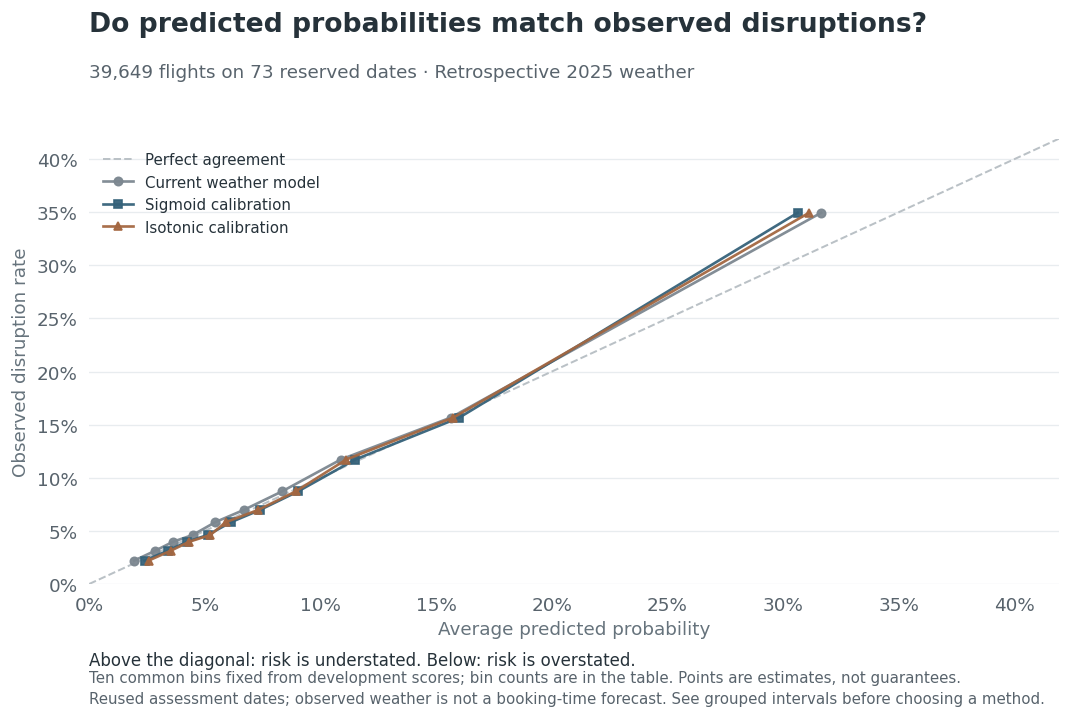

,method,bin,n,predicted,observed,gap_observed_minus_predicted
0,raw,0,3455,0.01944,0.02200,0.00256
1,raw,1,3905,0.02849,0.03124,0.00276
2,raw,2,3918,0.03631,0.03982,0.00351
3,raw,3,4038,0.04470,0.04606,0.00136
4,raw,4,3997,0.05460,0.05829,0.00369
5,raw,5,3977,0.06679,0.06965,0.00286
6,raw,6,4166,0.08336,0.08713,0.00377
7,raw,7,4036,0.10881,0.11720,0.00839
8,raw,8,4046,0.15636,0.15670,0.00033
9,raw,9,4111,0.31649,0.34955,0.03306


A lower Brier score is better overall probability accuracy; calibration also needs the reliability curve, grouped uncertainty and subgroup checks.


In [ ]:
from matplotlib.ticker import PercentFormatter
cal_colors={'raw':'#7C8790','sigmoid':'#35627A','isotonic':'#A46741'}
cal_labels={'raw':'Current weather model','sigmoid':'Sigmoid calibration','isotonic':'Isotonic calibration'}
fig,ax=plt.subplots(figsize=(9.4,6.4),facecolor='white')
fig.subplots_adjust(left=.11,right=.97,top=.80,bottom=.22)
fig.text(.11,.94,'Do predicted probabilities match observed disruptions?',fontsize=16,weight='bold',color='#26323A')
fig.text(.11,.88,f'{len(wt_test_idx):,} flights on {cal_dates.nunique()} reserved dates · Retrospective 2025 weather',fontsize=11,color='#58636C')
limit=min(1.,max(cal_bins.predicted.max(),cal_bins.observed.max())*1.2)
ax.plot([0,limit],[0,limit],ls='--',color='#BAC1C6',lw=1.2,label='Perfect agreement')
for method in cal_methods:
    b=cal_bins[cal_bins.method.eq(method)]
    ax.plot(b.predicted,b.observed,marker={'raw':'o','sigmoid':'s','isotonic':'^'}[method],markersize=5,
            lw=1.6,color=cal_colors[method],label=cal_labels[method],alpha=.95)
ax.set(xlim=(0,limit),ylim=(0,limit),xlabel='Average predicted probability',ylabel='Observed disruption rate')
ax.xaxis.set_major_formatter(PercentFormatter(1,decimals=0));ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
ax.grid(axis='y',color='#E8ECEF',lw=.8);ax.set_axisbelow(True)
for spine in ['top','right']:ax.spines[spine].set_visible(False)
for spine in ['left','bottom']:ax.spines[spine].set_color('#CDD4D9')
ax.tick_params(colors='#58636C',length=0,pad=7);ax.legend(frameon=False,loc='upper left',fontsize=9)
fig.text(.11,.115,'Above the diagonal: risk is understated. Below: risk is overstated.',fontsize=10,color='#26323A')
fig.text(.11,.065,'Ten common bins fixed from development scores; bin counts are in the table. Points are estimates, not guarantees.\nReused assessment dates; observed weather is not a booking-time forecast. See grouped intervals before choosing a method.',fontsize=9,color='#58636C',linespacing=1.5)
fig.savefig(CAL_DIR/'calibration_comparison.png',dpi=180,bbox_inches='tight')
fig.savefig(CAL_DIR/'calibration_comparison.svg',bbox_inches='tight')
plt.show()
display(cal_bins[['method','bin','n','predicted','observed','gap_observed_minus_predicted']].round(5))
print('A lower Brier score is better overall probability accuracy; calibration also needs the reliability curve, grouped uncertainty and subgroup checks.')


## J6 · Record the decision and keep the MVP gate explicit

Preserve the original model and source data. Export evidence, record residual risks, and save the fitted calibration maps separately. Completion of this study does not validate future forecasts or transfer from the student sample to Boston → Chicago population options.

In [ ]:
cal_check('Original raw source remains unchanged',hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==wt_raw_fingerprint)
cal_check('Original weather source remains unchanged',hashlib.sha256(pd.util.hash_pandas_object(wt_weather,index=True).values.tobytes()).hexdigest()==wt_weather_fingerprint)
cal_check('Every sigmoid optimization converged to small gradient',all(p['sigmoid_gradient_max']<1e-7 for p in cal_parameters))
cal_check('Fifteen inner fits and fifteen outer-method results complete',len(cal_nested_rows)==15 and len(cal_fold_metrics)==15)
cal_check('All assessment scores finite and bounded',all(np.isfinite(p).all() and ((p>=0)&(p<=1)).all() for p in cal_test.values()))
cal_check('Operational top-decile event counts unchanged',cal_capacity[cal_capacity.capacity.eq(.10)].events.nunique()==1)
cal_validation=pd.DataFrame(cal_checks);cal_save(cal_validation,'validation_checks');assert cal_validation.passed.all()
cal_issues=pd.DataFrame([
 ['CAL01','mitigated','Calibration-on-training predictions would be optimistic.','Nested date-grouped OOF, with station-day purging at both levels.'],
 ['CAL02','open','Assessment dates were examined before this calibration study.','Exploratory comparison; no claim of an untouched final test.'],
 ['CAL03','open','One year and observed daily weather; exact exposure/forecast availability unavailable.','Retrospective replay only; future/forecast validation still needed.'],
 ['CAL04','open','Calibration fit on smaller OOF base models may shift when applied to full-development model.','Evaluate actual final pipeline; report point changes and grouped intervals.'],
 ['CAL05','open','Many flights share disruption causes; subgroup data are limited.','Date/week bootstrap; subgroup tables descriptive, not independent confirmations.'],
 ['CAL07','resolved','First sklearn sigmoid fit emitted local BLAS RuntimeWarnings despite bounded inputs.','Archived first run; same logistic objective fitted with stable elementwise SciPy loss/gradient; verify convergence and rerun before assessment.'],
 ['CAL06','open','BOS→Chicago population transfer has not been evaluated.','No MVP risk-score activation in this study.'],
],columns=['id','status','evidence','treatment']);cal_save(cal_issues,'issue_log')
cal_decisions=pd.DataFrame([
 ['CAL-D1','Hold current weather model, target, features and evaluation rows fixed','Compare probability mapping without changing underlying flight ranking.'],
 ['CAL-D2','Use nested grouped calibration with weather-key purging','Outer assessment labels cannot influence inner base fitting or calibrators.'],
 ['CAL-D3','Select calibration by development Brier; include unchanged scores','Calibration must earn its role; assessment cannot choose the runner-up.'],
 ['CAL-D4',f'Retain {cal_recommended} for the next replay checks',cal_decision['reason']],
 ['CAL-D5','Keep MVP probability display pending route/population checks','Global sample performance does not establish performance for every route.'],
],columns=['id','decision','reason']);cal_save(cal_decisions,'decision_log')
cal_experiments=pd.DataFrame([
 ['CAL-E1','complete','Nested calibration comparison: raw, sigmoid, isotonic'],
 ['CAL-E2','complete','Final maps learned on development OOF; reserved-date comparison'],
 ['CAL-E3','complete','Paired date/week intervals, review-capacity, calibration bins and subgroup diagnostics'],
 ['CAL-E4','not run','BOS→ORD/MDW replay transfer and score-contract validation'],
 ['CAL-E5','not run','New-period/forecast-weather validation'],
],columns=['id','status','experiment']);cal_save(cal_experiments,'experiment_log')
cal_record={**cal_decision,'checks_passed':int(cal_validation.passed.sum()),'inner_base_model_fits':15,
    'development_metrics':cal_dev.drop(columns='preference').to_dict('records'),
    'assessment_metrics':cal_assessment.to_dict('records'),'grouped_intervals':cal_ci.to_dict('records'),
    'environment':{'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},
    'execution':'sequential local notebook kernel; results saved to existing Colab, not a new Colab runtime execution',
    'original_weather_model_modified':False}
(CAL_DIR/'study_record.json').write_text(json.dumps(cal_record,indent=2))
joblib.dump({'base_model':wt_models[wt_selected],'calibration_maps':cal_maps,'selected':cal_selected,
    'recommended':cal_recommended,'features':wt_categories+wt_schedule_numeric+wt_variant_weather['both'],
    'protocol':cal_protocol,'decision':cal_decision,'development_indices':wt_dev_idx,'assessment_indices':wt_test_idx,
    'nested_oof_predictions':cal_oof,'assessment_predictions':cal_test},CAL_DIR/'internal_calibration_checkpoint.joblib')
# Aggregate evidence only; internal checkpoints and row-level predictions are excluded.
with zipfile.ZipFile(CAL_DIR/'calibration_evidence.zip','w',zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(CAL_DIR.iterdir()):
        if path.suffix in ['.csv','.json','.png','.svg']:archive.write(path,arcname=path.name)
display(cal_decisions);display(cal_issues)
print(f'{int(cal_validation.passed.sum())} acceptance checks passed. Recommended mapping: {cal_recommended}.')
print('Calibration study complete. No MVP scores enabled; review the walkthrough below before the next gate.')


,id,decision,reason
0,CAL-D1,"Hold current weather model, target, features a...",Compare probability mapping without changing u...
1,CAL-D2,Use nested grouped calibration with weather-ke...,Outer assessment labels cannot influence inner...
2,CAL-D3,Select calibration by development Brier; inclu...,Calibration must earn its role; assessment can...
3,CAL-D4,Retain raw for the next replay checks,Calibration has not passed every frozen gate; ...
4,CAL-D5,Keep MVP probability display pending route/pop...,Global sample performance does not establish p...


,id,status,evidence,treatment
0,CAL01,mitigated,Calibration-on-training predictions would be o...,"Nested date-grouped OOF, with station-day purg..."
1,CAL02,open,Assessment dates were examined before this cal...,Exploratory comparison; no claim of an untouch...
2,CAL03,open,One year and observed daily weather; exact exp...,Retrospective replay only; future/forecast val...
3,CAL04,open,Calibration fit on smaller OOF base models may...,Evaluate actual final pipeline; report point c...
4,CAL05,open,Many flights share disruption causes; subgroup...,Date/week bootstrap; subgroup tables descripti...
5,CAL07,resolved,First sklearn sigmoid fit emitted local BLAS R...,Archived first run; same logistic objective fi...
6,CAL06,open,BOS→Chicago population transfer has not been e...,No MVP risk-score activation in this study.


76 acceptance checks passed. Recommended mapping: raw.
Calibration study complete. No MVP scores enabled; review the walkthrough below before the next gate.


### Calibration results · Step-by-step walkthrough

**1. What did we test?** We kept the selected schedule + origin/destination weather boosting model unchanged. Sigmoid and isotonic learn a mapping from its score to the observed disruption outcome. They receive no extra flight/weather predictors. The target is still cancellation, diversion, or arrival at least 60 minutes late.

**2. How did we keep the evaluation honest?** There are 144,457 development flights and 39,649 assessment flights. Five outer folds evaluate calibration; three inner folds within each outer training pool learn it from out-of-fold scores. Dates are randomly grouped within months, and shared weather station-days are purged at both levels. All 15 final inner fits pass the separation checks. Model/feature settings were fixed before this comparison. Their original selection is not itself nested here, and the assessment dates are previously examined data: this is exploratory evidence.

**3. Which method won?** The unchanged model had the lowest pooled development Brier and was selected before this assessment comparison. Lower Brier/log loss is better; neither is an accuracy percentage.

| Method | Development Brier ↓ | Assessment Brier ↓ | Assessment log loss ↓ | Mean assessment probability |
|---|---:|---:|---:|---:|
| Current weather model | 0.078905 | 0.079168 | 0.281303 | 9.34% |
| Sigmoid calibration | 0.078979 | 0.079330 | 0.281612 | 9.77% |
| Isotonic calibration | 0.079025 | 0.079411 | 0.282707 | 9.76% |

The actual assessment disruption rate is **9.98%** (3,957 of 39,649). Both calibration methods move the average probability closer to this rate, **but worsen overall probability accuracy**. Matching the overall average does not establish calibration across the risk range.

**4. What happened to high-risk flights?** The highest-scored 3,965 flights contain 1,405 disruptions: **35.44%** observed. Their average predictions are **32.08% unchanged**, **31.03% sigmoid**, and **31.54% isotonic**. Both maps lower probabilities in this group and increase the existing understatement.

The final sigmoid intercept is -0.111345, with slope 0.917086 on log-odds. This fitted mapping raises many smaller scores and lowers larger scores. That explains how the overall mean improves while the high-risk group and Brier score get worse; it is a description of these outputs, not a causal claim.

**5. Are the differences supported beyond a point estimate?** Positive Brier improvement below would favor calibration. Every interval is negative for this assessment sample, under both date and week resampling.

| Method | Resampling unit | Brier improvement vs current | 97.5% paired interval |
|---|---|---:|---:|
| Sigmoid calibration | date | -0.0001612 | [-0.0003264, -0.0000120] |
| Isotonic calibration | date | -0.0002430 | [-0.0004023, -0.0000963] |
| Sigmoid calibration | week blocks | -0.0001612 | [-0.0003203, -0.0000188] |
| Isotonic calibration | week blocks | -0.0002430 | [-0.0003930, -0.0001060] |

These are small absolute differences. The intervals allow for two calibration additions within each grouping, condition on fitted models, and exclude retraining/selection uncertainty. They support retaining the original probabilities in this experiment; they do not establish universal superiority on future data.

**6. Does calibration improve which flights we review?** No. Sigmoid keeps assessment AP at 0.323 and ROC AUC at 0.751, identical to the original model. Isotonic creates ties (AP 0.315, ROC AUC 0.751). Using the original score to break those ties preserves the same operational review order: all three capture 35.51% of disruptions when reviewing 10% of flights. Pooled development ranking metrics may differ even for sigmoid because different outer folds have different fitted calibration maps.

**7. Decision for the MVP:** **retain the current weather model’s original probabilities**; do not add either calibration layer. This is a useful negative experiment, not a reason to force an adjustment. Its remaining understatement is explicitly documented, so do not call the probabilities perfectly calibrated or guaranteed individual-flight risks.

**Next gate update:** Appendix K now completes BOS→ORD/MDW population scoring, weather/feature parity, technical audit and model-choice documentation. It retains calibration/stability limitations. The private interface remains pending. This study does not activate MVP scores. Observed daily weather keeps the scope retrospective; future booking forecasts remain unvalidated.

**Reproducibility:** 76 final acceptance checks pass. One initial sigmoid run emitted local matrix-gradient RuntimeWarnings; it was archived and replaced with the same logistic objective evaluated using stable elementwise operations. The first-fold scores agree within 5×10⁻¹⁰; all final sigmoid fits pass convergence/gradient checks without warnings. Fifteen final inner fits were validated, with three earlier inner fits repeated for this numerical correction before calibration assessment. Raw sources and the original weather model are unchanged. J6 exports aggregate evidence and retains internal fitted artifacts separately. These results were executed sequentially in a local kernel and saved into this notebook.


# Appendix K · Validate Boston → Chicago replay and explain model choices

**Client question:** can our existing weather model score the actual recorded BOS→ORD/MDW options reliably enough for an explicitly historical demo? We evaluate data integrity, predictive performance, probability calibration and ranking among options from the same search separately.

The model stays fixed: Appendix I gradient boosting with schedule and both-endpoint observed daily weather; Appendix J rejected additional calibration. No risk points, financial assumptions, route-specific tuning or new model selection are added here.

Run K1 → K7 sequentially after I and J. Saved outputs are from sequential local notebook execution, written to this Colab. K6 is the model-choice ledger: purpose, predictors, hyperparameters, metric comparisons and defensible presentation wording. The three main business charts remain unchanged.

## K1 · Freeze validation before looking at route results

We evaluate all source-population flights on the original reserved dates. The student sample overlaps that population; report additional flights separately, never append them as independent observations. The default date is still the earliest reserved November date, chosen without looking at outcomes.

**Metric versus parameter:** Brier, log loss, average precision and AUC measure performance. Learning rate, tree depth/leaves and regularization are model settings. The ledger records both and makes clear which metric supported a choice.

A global model can separate storm days from calm days yet fail to rank flights on the same day. We therefore add a within-search check using exact date and destination airport. Its result governs the wording we may use for sorting flight options.

In [ ]:
# Prerequisites: original setup/Drive/preparation, Appendix I and completed calibration study J.
import json,hashlib,joblib,zipfile,warnings
from pathlib import Path
RP_DIR=Path(os.environ.get('CHART_CHAMP_REPLAY_DIR',str(OUTPUT_DIR/'replay_validation')))
RP_DIR.mkdir(parents=True,exist_ok=True)
rp_checks=[]
def rp_check(name,passed,detail=''):
    rp_checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
    assert passed,f'{name}: {detail}'
def rp_save(frame,name):frame.to_csv(RP_DIR/f'{name}.csv',index=False)
rp_check('All source files content-verified',inventory.status.eq('VERIFIED').all())
rp_check('Frozen weather model retained',wt_selected=='boosting_both')
rp_check('No calibration layer adopted',cal_recommended=='raw')
rp_check('Original development indices reproduced',hashlib.sha256(wt_dev_idx.tobytes()).hexdigest()==wt_protocol['index_hashes']['development'])
rp_check('Exactly 73 reserved dates',wt_date_assignment.partition.eq('assessment').sum()==73)
rp_protocol={
 'scope':'BOS to ORD/MDW, all recorded population flights on the original reserved 2025 dates; selected source carriers, not live tickets',
 'target':'cancellation OR diversion OR arrival delay >=60 minutes',
 'selection':'No new model selection/tuning. Carry original boosting_both probabilities; retain baseline, boosting_schedule and logistic_both as fixed comparators.',
 'extraction':'Re-extract route catalog from all 12 checksum-verified monthly files; reconcile overlap with student sample, never append it as new data.',
 'features':'Exactly the trained schedule and both-endpoint observed-weather feature contract; outcomes removed before feature preparation.',
 'leakage_gate':'No replay flight key, flight date or origin/destination station-day may occur in model training; fail before scoring if any overlap.',
 'same_rows':'All four models use identical valid replay rows and original weather-study training rows.',
 'comparators':'Reuse fitted models if present; otherwise refit frozen configurations and require exact reproduction of saved global assessment probabilities.',
 'primary_evaluation':'Full eligible reserved-date population catalog; no test-set tuning or date cherry-picking.',
 'secondary_evaluation':'Additional flights absent from the 200000-row sample; distinguish expanded coverage from independent replication (same dates/weather).',
 'metrics':'Brier primary; log loss, AP, ROC AUC, mean forecast/observed frequency; date/week paired Brier intervals.',
 'replay_intervals':'5000 paired cluster bootstrap draws seed 64, three fixed comparator contrasts, 98.33% intervals within each grouping; conditional on fitted models.',
 'global_intervals':'All eight Appendix I alternatives vs fixed selected model, 99.375% Bonferroni date/week intervals; exploratory reused assessment.',
 'search_ranking':'Within exact departure date + destination airport, pair-weighted AUC among groups with both classes; 95% date bootstrap. Also top ceil(10% * options) per search group; report realized review fraction and random-review expectation.',
 'calibration':'Five bins fixed from global development OOF quintiles; display sample sizes and date-bootstrap event-rate intervals. Mean probability bias with date/week intervals. No calibration refit.',
 'support':'Training route/carrier counts, unseen categories, unknown encoded categories, missingness and out-of-training-range weather; never add these as risk points.',
 'engineering_acceptance':'Valid dates/keys, no train overlap, unchanged raw data, exact overlap feature/score reconciliation, finite probabilities, no outcomes in scoring input, output IDs unique.',
 'predictive_screen':'Current model must beat training-prevalence Brier on full catalog and additional-not-in-sample flights; full-catalog paired date/week lower bounds vs baseline must be positive. Otherwise no evidence-based probability-display recommendation.',
 'ranking_screen':'Within-search AUC date-bootstrap lower bound >0.5. Failure means no claim that sorting improves same-date options; global discrimination alone is insufficient.',
 'decision':'Report engineering, prediction, within-search ranking and calibration separately; no arbitrary tolerance or financial assumption. Do not automatically activate UI or switch to a comparator after seeing results.',
 'default_demo_date':'earliest reserved November date, fixed before outcomes/scores',
 'limitations':['observed daily weather is retrospective, not forecast or exact-hour exposure','assessment dates already explored; route outcomes now add coverage but not new temporal independence','limited local sample and correlated flights; uncertainty excludes retraining/model selection','within-search associations are not causal switching or savings estimates'],
}
(RP_DIR/'protocol.json').write_text(json.dumps(rp_protocol,indent=2))
print('Replay protocol frozen. No model fitting, scoring or new route-outcome inspection yet.')
print('Separate checks: data integrity, prediction accuracy, same-search ranking, probability calibration and model-choice evidence.')


Replay protocol frozen. No model fitting, scoring or new route-outcome inspection yet.
Separate checks: data integrity, prediction accuracy, same-search ranking, probability calibration and model-choice evidence.


## K2 · Reconcile the actual replay catalog

Read the 12 verified monthly files in chunks and retain BOS→ORD/MDW. Track the source file and original data-row number for every flight. Audit unique keys, frozen dates and sample overlap. Keep realized outcomes in a separate table before preparing features.

In [ ]:
rp_columns=flight_key+['CRS_ARR_TIME','CRS_ELAPSED_TIME','DISTANCE','ARR_DELAY','CANCELLED','DIVERTED']
rp_parts=[];rp_source_rows=[]
for path in monthly_paths:
    # Original Drive loader already checks the full source manifest; record its source hash here.
    count=0;selected=0
    for chunk in pd.read_csv(path,usecols=rp_columns,chunksize=250000):
        take=chunk[chunk.ORIGIN.eq('BOS')&chunk.DEST.isin(['ORD','MDW'])].copy()
        take['source_file']=path.name;take['source_data_row']=np.flatnonzero(chunk.ORIGIN.eq('BOS')&chunk.DEST.isin(['ORD','MDW']))+count+1
        rp_parts.append(take);count+=len(chunk);selected+=len(take)
    rp_source_rows.append({'file':path.name,'population_rows':count,'route_rows':selected,'manifest_sha256':manifest[path.name]['sha256'] if isinstance(manifest[path.name],dict) else manifest[path.name]})
    print(path.name,'route records extracted:',selected,flush=True)
rp_catalog=pd.concat(rp_parts,ignore_index=True)
rp_catalog['date']=pd.to_datetime(rp_catalog.FL_DATE,errors='raise')
rp_catalog=rp_catalog.merge(wt_date_assignment[['date','partition']],on='date',validate='many_to_one',how='left')
rp_check('Route catalog has unique flight keys',not rp_catalog.duplicated(flight_key).any())
rp_check('All catalog dates have a frozen partition',rp_catalog.partition.notna().all())
rp_check('Original complete route extraction reproduced',len(rp_catalog)==8594)
rp_reserved=rp_catalog[rp_catalog.partition.eq('assessment')].copy().sort_values(flight_key).reset_index(drop=True)
rp_reserved['replay_id']=['|'.join(map(str,row)) for row in rp_reserved[flight_key].itertuples(index=False,name=None)]
rp_check('Reserved catalog counts reproduce',len(rp_reserved)==1711 and rp_reserved.date.nunique()==73)
rp_check('Replay IDs unique',rp_reserved.replay_id.is_unique)
rp_check('Outcomes complete with structural arrival nulls',rp_reserved.CANCELLED.isin([0,1]).all() and rp_reserved.DIVERTED.isin([0,1]).all() and
    rp_reserved.ARR_DELAY.isna().eq(rp_reserved.CANCELLED.eq(1)|rp_reserved.DIVERTED.eq(1)).all())
# Outcome table is kept separate. No target or actual outcome enters feature construction.
rp_outcomes=rp_reserved[['replay_id','ARR_DELAY','CANCELLED','DIVERTED']].copy()
rp_outcomes['major_disruption']=(rp_outcomes.CANCELLED.eq(1)|rp_outcomes.DIVERTED.eq(1)|rp_outcomes.ARR_DELAY.ge(60)).astype(int)
rp_schedule_columns=['replay_id']+flight_key+['CRS_ARR_TIME','CRS_ELAPSED_TIME','DISTANCE','source_file','source_data_row']
rp_schedule=rp_reserved[rp_schedule_columns].copy()
rp_sample_keys=raw[flight_key].copy();rp_sample_keys['sample_row']=np.arange(len(raw))
rp_membership=rp_reserved[['replay_id']+flight_key].merge(rp_sample_keys,on=flight_key,how='left',validate='one_to_one')
rp_overlap=rp_membership.sample_row.notna()
rp_check('Sample-overlap flights are assessment, not training',set(rp_membership.loc[rp_overlap,'sample_row'].astype(int)).issubset(set(wt_test_idx)))
rp_overlap_rows=rp_membership.loc[rp_overlap,'sample_row'].astype(int).to_numpy()
for column in ['ARR_DELAY','CANCELLED','DIVERTED','CRS_ARR_TIME','CRS_ELAPSED_TIME','DISTANCE']:
    a=rp_reserved.loc[rp_overlap,column].to_numpy();b=raw.iloc[rp_overlap_rows][column].to_numpy()
    rp_check(f'Sample/population overlap values agree: {column}',np.allclose(a,b,equal_nan=True,rtol=0,atol=0))
rp_default=rp_reserved.loc[rp_reserved.date.dt.month.eq(11),'date'].min()
rp_check('Default replay date remains calendar-selected',rp_default==pd.Timestamp('2025-11-04'))
rp_source_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(rp_reserved,index=True).values.tobytes()).hexdigest()
rp_save(pd.DataFrame(rp_source_rows),'source_extraction_audit')
rp_save(rp_reserved.groupby(['date','DEST']).size().rename('flights').reset_index(),'catalog_coverage')
rp_save(rp_membership,'sample_membership')
print(f'Reserved catalog: {len(rp_reserved):,} flights on {rp_reserved.date.nunique()} dates; {int(rp_overlap.sum())} also in the student sample and {int((~rp_overlap).sum()):,} additional flights.')
print('Additional flights are on the same reserved dates and weather contexts, not an independent temporal test.')
print('Default date:',rp_default.date(),'; options:',int(rp_reserved.date.eq(rp_default).sum()))


2025_01.csv route records extracted: 558


2025_02.csv route records extracted: 532


2025_03.csv route records extracted: 637


2025_04.csv route records extracted: 633


2025_05.csv route records extracted: 747


2025_06.csv route records extracted: 826


... (3 outputs left out)

2025_10.csv route records extracted: 834


2025_11.csv route records extracted: 730


2025_12.csv route records extracted: 646


Reserved catalog: 1,711 flights on 73 dates; 58 also in the student sample and 1,653 additional flights.
Additional flights are on the same reserved dates and weather contexts, not an independent temporal test.
Default date: 2025-11-04 ; options: 22


## K3 · Validate weather dates, feature parity and training support

Derive scheduled departure/arrival local dates with the same timezone rules as the trained model, then join one daily weather record per endpoint. Compare every overlapping sample flight’s entire feature vector with the original study. No replay date, flight key or either endpoint’s station-day may occur in model training.

Training route/carrier counts and missing/out-of-range measurements describe coverage. They are not separate probability adjustments, and sparse support is not proof that a prediction is correct or incorrect.

In [ ]:
def rp_prepare_features(schedule):
    allowed=set(rp_schedule_columns)
    assert set(schedule.columns)==allowed,'Scoring accepts the explicit schedule-only input contract.'
    frame=schedule.copy(deep=True);frame['date']=pd.to_datetime(frame.FL_DATE,errors='raise')
    frame['MONTH']=frame.date.dt.month;frame['DAY_OF_WEEK']=frame.date.dt.dayofweek+1
    for column,prefix in [('CRS_DEP_TIME','departure'),('CRS_ARR_TIME','arrival')]:
        value=pd.to_numeric(frame[column],errors='raise')
        assert value.notna().all() and ((value.between(0,2359)&value.mod(100).lt(60)&value.mod(1).eq(0))|value.eq(2400)).all()
        minutes=((value//100)*60+value%100).where(value.ne(2400),0)
        frame[prefix+'_minutes']=minutes;frame[prefix+'_midnight_2400']=value.eq(2400)
        frame[prefix+'_sin']=np.sin(2*np.pi*minutes/1440);frame[prefix+'_cos']=np.cos(2*np.pi*minutes/1440)
    frame['year_sin']=np.sin(2*np.pi*(frame.date.dt.dayofyear-1)/365)
    frame['year_cos']=np.cos(2*np.pi*(frame.date.dt.dayofyear-1)/365)
    frame['origin_tz']=frame.ORIGIN.map(wt_tz);frame['destination_tz']=frame.DEST.map(wt_tz)
    assert frame[['origin_tz','destination_tz']].notna().all().all()
    frame['scheduled_departure_local']=frame.date+pd.to_timedelta(frame.departure_minutes,unit='m')+pd.to_timedelta(frame.departure_midnight_2400.astype(int),unit='D')
    frame['scheduled_departure_utc']=pd.Series(pd.NaT,index=frame.index,dtype='datetime64[ns, UTC]')
    for zone,idx in frame.groupby('origin_tz').groups.items():
        frame.loc[idx,'scheduled_departure_utc']=frame.loc[idx,'scheduled_departure_local'].dt.tz_localize(zone,ambiguous='NaT',nonexistent='NaT').dt.tz_convert('UTC')
    frame['scheduled_arrival_utc']=frame.scheduled_departure_utc+pd.to_timedelta(frame.CRS_ELAPSED_TIME,unit='m')
    frame['scheduled_arrival_local']=pd.NaT
    for zone,idx in frame.groupby('destination_tz').groups.items():
        frame.loc[idx,'scheduled_arrival_local']=frame.loc[idx,'scheduled_arrival_utc'].dt.tz_convert(zone).dt.tz_localize(None)
    frame['origin_weather_date']=frame.scheduled_departure_local.dt.normalize();frame['destination_weather_date']=frame.scheduled_arrival_local.dt.normalize()
    derived=frame.scheduled_arrival_local.dt.hour*60+frame.scheduled_arrival_local.dt.minute
    frame['clock_difference_minutes']=((derived-frame.arrival_minutes+720)%1440)-720
    frame['schedule_join_valid']=frame.scheduled_departure_utc.notna()&frame.CRS_ELAPSED_TIME.gt(0)&frame.clock_difference_minutes.eq(0)
    for endpoint,airport,date_col in [('origin','ORIGIN','origin_weather_date'),('destination','DEST','destination_weather_date')]:
        renamed=wt_weather_work[wt_join_columns].rename(columns={c:f'{endpoint}_{c}' for c in wt_join_columns})
        frame=frame.merge(renamed,left_on=[airport,date_col],right_on=[f'{endpoint}_airport_code',f'{endpoint}_date'],how='left',validate='many_to_one',sort=False)
        frame[f'{endpoint}_weather_key']=frame[airport].map(wt_station)+'|'+frame[date_col].dt.strftime('%Y-%m-%d')
    assert frame.replay_id.tolist()==schedule.replay_id.tolist()
    return frame
rp=rp_prepare_features(rp_schedule)
rp_check('All reserved schedules reconcile before scoring',rp.schedule_join_valid.all())
rp_check('Both weather records matched',rp[['origin_station_id','destination_station_id']].notna().all().all())
rp_keys=set(rp[wt_key_columns].to_numpy().ravel())
rp_check('No training flight date in replay',not set(rp.date)&set(wt.iloc[wt_dev_idx].date))
rp_check('No training flight key in replay',not set(map(tuple,rp[flight_key].to_numpy()))&set(map(tuple,wt.iloc[wt_dev_idx][flight_key].to_numpy())))
rp_check('No training station-day in expanded replay',not rp_keys&wt_key_set(wt_dev_idx))
rp_X=rp[wt_X.columns].copy();rp_X[wt_categories]=rp_X[wt_categories].astype(str)
rp_check('Feature schema equals fitted pipeline input',rp_X.columns.tolist()==list(wt_models[wt_selected].feature_names_in_))
rp_check('No outcomes in scoring features',not set(rp_X.columns)&wt_forbidden)
rp_check('Overlap feature matrix exactly reproduces training-study preparation',
    rp_X.loc[rp_overlap].reset_index(drop=True).equals(wt_X.iloc[rp_overlap_rows].reset_index(drop=True)))
rp_unknown=[]
for field in wt_categories:
    unknown=~rp_X[field].isin(wt_X.iloc[wt_dev_idx][field].unique())
    rp_unknown.append({'feature':field,'unknown_rows':int(unknown.sum())})
rp_check('All replay category values observed during training',all(x['unknown_rows']==0 for x in rp_unknown))
rp_encoded=wt_models[wt_selected].named_steps['preprocess'].named_transformers_['categories'].transform(rp_X[wt_categories])
rp_check('Encoded categories are recognized',np.isfinite(rp_encoded).all())
rp_numeric_support=[]
for field in wt_schedule_numeric+wt_variant_weather['both']:
    train=wt_X.iloc[wt_dev_idx][field];score=rp_X[field]
    outside=score.notna()&((score<train.min())|(score>train.max()))
    rp_numeric_support.append({'feature':field,'training_nonmissing':int(train.notna().sum()),'training_min':train.min(),'training_max':train.max(),
        'replay_missing':int(score.isna().sum()),'replay_missing_fraction':score.isna().mean(),'replay_outside_training_range':int(outside.sum()),
        'replay_min':score.min(),'replay_max':score.max()})
rp_support=wt.iloc[wt_dev_idx].groupby(['ORIGIN','DEST','OP_UNIQUE_CARRIER']).size().rename('training_route_carrier_n').reset_index()
rp=rp.merge(rp_support,on=['ORIGIN','DEST','OP_UNIQUE_CARRIER'],how='left',validate='many_to_one',sort=False)
rp.training_route_carrier_n=rp.training_route_carrier_n.fillna(0).astype(int)
rp_check('Route/carrier support merge preserves order',rp.replay_id.tolist()==rp_schedule.replay_id.tolist())
rp_save(pd.DataFrame(rp_unknown),'category_support');rp_save(pd.DataFrame(rp_numeric_support),'numeric_support')
rp_save(rp[['ORIGIN','DEST','OP_UNIQUE_CARRIER','training_route_carrier_n']].drop_duplicates(),'route_carrier_support')
rp_weather_coverage=[]
for endpoint in ['origin','destination']:
 for field in wt_inputs:
    rp_weather_coverage.append({'endpoint':endpoint,'field':field,'n':len(rp),'missing':int(rp[f'{endpoint}_{field}'].isna().sum()),'reported_fraction':rp[f'{endpoint}_{field}'].notna().mean()})
rp_save(pd.DataFrame(rp_weather_coverage),'weather_coverage')
display(rp[['DEST','OP_UNIQUE_CARRIER','training_route_carrier_n']].drop_duplicates())
print('Clock, weather joins, training separation and exact overlap-feature checks passed.')
print('Training support counts and missing/range flags describe coverage; none are extra risk points.')


,DEST,OP_UNIQUE_CARRIER,training_route_carrier_n
0,ORD,AA,26
2,ORD,B6,17
4,ORD,MQ,16
5,ORD,UA,51
11,MDW,WN,26
14,ORD,YX,18
232,ORD,DL,28


Clock, weather joins, training separation and exact overlap-feature checks passed.
Training support counts and missing/range flags describe coverage; none are extra risk points.


## K4 · Score with frozen models and reconcile the outputs

Reuse the original selected model. Fixed schedule-only boosting and both-weather logistic regression provide comparators; any necessary refit must reproduce the original global assessment scores before scoring the route. Baseline probability is the original development event rate.

Check the selected model’s predictions against sample-overlap scores and verify that row order and batch size cannot change them. Export model scores and weather provenance separately from the realized outcomes. No UI is activated by this cell.

In [ ]:
rp_models={wt_selected:wt_models[wt_selected]};rp_candidates=['baseline','boosting_schedule','logistic_both','boosting_both']
rp_predictions={};rp_refit_rows=[]
for candidate in rp_candidates:
    if candidate=='baseline':
        rp_predictions[candidate]=np.full(len(rp),wt_y[wt_dev_idx].mean());continue
    if candidate not in wt_models:
        fitted,check_pred=wt_fit_predict(candidate,wt_dev_idx,wt_test_idx)
        rp_check(f'{candidate}: fixed refit reproduces original assessment scores',np.allclose(check_pred,wt_predictions[candidate],atol=1e-12,rtol=0))
        rp_models[candidate]=fitted;rp_refit_rows.append({'candidate':candidate,'action':'frozen refit; original assessment probabilities reproduced','maximum_difference':float(np.abs(check_pred-wt_predictions[candidate]).max())})
    else:
        rp_models[candidate]=wt_models[candidate];rp_refit_rows.append({'candidate':candidate,'action':'reuse original fitted model','maximum_difference':0.})
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning)
        probability=rp_models[candidate].predict_proba(rp_X)[:,1]
    rp_check(f'{candidate}: replay probabilities finite and bounded',np.isfinite(probability).all() and ((probability>=0)&(probability<=1)).all())
    rp_predictions[candidate]=probability
    lookup=pd.Series(wt_predictions[candidate],index=wt_test_idx)
    rp_check(f'{candidate}: sample-overlap scores exactly reproduce',np.allclose(probability[rp_overlap],lookup.loc[rp_overlap_rows].to_numpy(),rtol=0,atol=1e-12))
# Predictions cannot depend on row order, batch size or outcome fields.
rp_order=np.random.default_rng(64).permutation(len(rp))
with threadpool_limits(limits=2):
    shuffled=rp_models[wt_selected].predict_proba(rp_X.iloc[rp_order])[:,1]
    batched=np.concatenate([rp_models[wt_selected].predict_proba(rp_X.iloc[start:start+257])[:,1] for start in range(0,len(rp),257)])
rp_check('Scores invariant to row order',np.allclose(shuffled,rp_predictions[wt_selected][rp_order],atol=1e-14,rtol=0))
rp_check('Scores invariant to batch size',np.allclose(batched,rp_predictions[wt_selected],atol=1e-14,rtol=0))
rp_save(pd.DataFrame(rp_refit_rows),'model_reuse_audit')
rp_score_table=rp[['replay_id','date','ORIGIN','DEST','OP_UNIQUE_CARRIER','OP_CARRIER_FL_NUM','CRS_DEP_TIME','CRS_ARR_TIME',
    'scheduled_departure_local','scheduled_arrival_local','origin_tz','destination_tz','source_file','source_data_row',
    'origin_weather_date','destination_weather_date','origin_station_id','destination_station_id','origin_station_distance_km','destination_station_distance_km','training_route_carrier_n']].copy()
rp_score_table['risk_probability']=rp_predictions[wt_selected]
rp_score_table['model']='boosting_both';rp_score_table['calibration']='none; sigmoid/isotonic not adopted'
rp_score_table['mode']='historical observed-weather replay';rp_score_table['in_student_sample']=rp_overlap.to_numpy()
rp_score_table['weather_missing_measurements']=rp[wt_variant_weather['both']].isna().sum(axis=1)
for name in wt_variant_weather['both']:rp_score_table[name]=rp[name]
rp_check('Risk export excludes actual outcomes',not set(['ARR_DELAY','CANCELLED','DIVERTED','major_disruption'])&set(rp_score_table.columns))
rp_save(rp_score_table,'replay_scores_private');rp_save(rp_outcomes,'outcomes_reveal_separate')
print(f'{len(rp):,} original weather-model scores created. No classifier retuning or probability correction.')
print('Feature and score reconciliation passed for every overlapping student-sample flight. UI remains inactive.')


1,711 original weather-model scores created. No classifier retuning or probability correction.
Feature and score reconciliation passed for every overlapping student-sample flight. UI remains inactive.


## K5 · Assess probability accuracy and same-search ranking

Reveal outcomes only for evaluation. Compare all models on identical replay rows, then report additional-not-in-sample flights separately. Lower Brier/log loss is better; AP/AUC assess ranking. Paired date/week intervals respect shared disruption contexts, although they omit training and model-selection uncertainty.

**Within-search AUC:** among pairs with different outcomes on the same date and destination, how often does the disrupted flight receive the higher score? Only groups with both outcomes are informative; report their coverage. AUC=0.5 is chance ordering. The top-review diagnostic selects `ceil(10% × options)` within each search, so its actual review fraction can exceed 10%; the table reports that fraction.

**Calibration:** five common probability bins come from development scores, not route outcomes. Show counts and uncertainty. Matching the overall event rate or beating a baseline does not establish precise individual probabilities. No correction is fitted to this assessment.

In [ ]:
# Outcome reveal occurs here for evaluation only, after score generation and integrity gates.
rp_y=rp_outcomes.set_index('replay_id').loc[rp.replay_id,'major_disruption'].to_numpy(dtype=int)
rp_dates=rp.date.reset_index(drop=True)
def rp_metrics(y,p):
    return {'n':len(y),'events':int(y.sum()),'event_rate':float(y.mean()),'mean_prediction':float(p.mean()),
        'Brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
        'AP':average_precision_score(y,p) if y.sum()>0 else np.nan,'ROC_AUC':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan}
def rp_group_interval(values,groups,alpha=.05,weights=None):
    weights=np.ones(len(values)) if weights is None else np.asarray(weights)
    blocks=pd.DataFrame({'group':np.asarray(groups),'total':np.asarray(values)*weights,'weight':weights}).groupby('group').agg(total=('total','sum'),weight=('weight','sum'))
    blocks=blocks[blocks.weight>0]
    assert len(blocks)>1
    draws=np.random.default_rng(64).integers(0,len(blocks),size=(5000,len(blocks)))
    samples=blocks.total.to_numpy()[draws].sum(1)/blocks.weight.to_numpy()[draws].sum(1)
    lo,hi=np.quantile(samples,[alpha/2,1-alpha/2])
    return {'groups':len(blocks),'estimate':float(np.sum(np.asarray(values)*weights)/weights.sum()),'lower':float(lo),'upper':float(hi)}
rp_cohorts={'full reserved catalog':np.ones(len(rp),dtype=bool),'additional not in student sample':~rp_overlap.to_numpy(),'overlap with student sample':rp_overlap.to_numpy()}
rp_metric_rows=[]
for scope,mask in rp_cohorts.items():
 for candidate,p in rp_predictions.items():rp_metric_rows.append({'cohort':scope,'candidate':candidate,**rp_metrics(rp_y[mask],p[mask])})
rp_metric_table=pd.DataFrame(rp_metric_rows);rp_save(rp_metric_table,'replay_metrics')
rp_ci_rows=[]
for candidate in ['baseline','boosting_schedule','logistic_both']:
    delta=(rp_y-rp_predictions[candidate])**2-(rp_y-rp_predictions[wt_selected])**2
    for unit,groups in [('date',rp_dates),('calendar_week',rp_dates-pd.to_timedelta(rp_dates.dt.dayofweek,unit='D'))]:
        interval=rp_group_interval(delta,groups,alpha=.05/3)
        rp_ci_rows.append({'selected':wt_selected,'comparator':candidate,'unit':unit,'interval_level':1-.05/3,**interval})
rp_ci=pd.DataFrame(rp_ci_rows);rp_save(rp_ci,'replay_paired_brier_intervals')
# Explicitly paired global evidence supports the model-choice ledger, not new tuning.
rp_global_ci=[];global_y=wt_y[wt_test_idx];global_dates=wt.iloc[wt_test_idx].date.reset_index(drop=True)
for comparator,p in wt_predictions.items():
 if comparator==wt_selected:continue
 delta=(global_y-p)**2-(global_y-wt_predictions[wt_selected])**2
 for unit,groups in [('date',global_dates),('calendar_week',global_dates-pd.to_timedelta(global_dates.dt.dayofweek,unit='D'))]:
    rp_global_ci.append({'selected':wt_selected,'comparator':comparator,'unit':unit,'interval_level':1-.05/8,
                         **rp_group_interval(delta,groups,alpha=.05/8)})
rp_global_ci=pd.DataFrame(rp_global_ci);rp_save(rp_global_ci,'global_model_choice_intervals')
rp_subgroups=[]
for field in ['DEST','OP_UNIQUE_CARRIER','MONTH']:
 for value,indices in rp.groupby(field).groups.items():
    indices=np.asarray(indices)
    for candidate,p in rp_predictions.items():rp_subgroups.append({'field':field,'value':value,'candidate':candidate,**rp_metrics(rp_y[indices],p[indices])})
rp_save(pd.DataFrame(rp_subgroups),'replay_subgroups')
# Five fixed bins: no route-outcome-driven boundaries or calibration changes.
rp_bin_edges=np.r_[-np.inf,np.quantile(wt_oof[wt_selected][wt_dev_idx],[.2,.4,.6,.8]),np.inf]
rp_bins=np.searchsorted(rp_bin_edges[1:-1],rp_predictions[wt_selected],side='right')
rp_calibration=[]
for bin_id in range(5):
 mask=rp_bins==bin_id
 if not mask.any():continue
 interval=rp_group_interval(rp_y[mask],rp_dates[mask])
 rp_calibration.append({'bin':bin_id+1,'n':int(mask.sum()),'events':int(rp_y[mask].sum()),'mean_probability':float(rp_predictions[wt_selected][mask].mean()),
    'observed_rate':float(rp_y[mask].mean()),'dates':interval['groups'],'observed_lower_95':interval['lower'],'observed_upper_95':interval['upper']})
rp_calibration=pd.DataFrame(rp_calibration);rp_save(rp_calibration,'replay_calibration_bins')
rp_bias=[]
for unit,groups in [('date',rp_dates),('calendar_week',rp_dates-pd.to_timedelta(rp_dates.dt.dayofweek,unit='D'))]:
 rp_bias.append({'unit':unit,'meaning':'observed minus predicted, positive means underprediction',**rp_group_interval(rp_y-rp_predictions[wt_selected],groups)})
rp_save(pd.DataFrame(rp_bias),'replay_mean_probability_bias')
# Conditional discrimination: fixed travel date AND destination airport, not cross-date weather sorting.
rp_search_rows=[];rp_review_rows=[];rp_ties=np.random.default_rng(64).random(len(rp))
for (date,dest),indices in rp.groupby(['date','DEST']).groups.items():
 indices=np.asarray(indices);y=rp_y[indices];pairs=int(y.sum()*(len(y)-y.sum()))
 for candidate,p in rp_predictions.items():
    auc=roc_auc_score(y,p[indices]) if pairs else np.nan
    rp_search_rows.append({'date':date,'DEST':dest,'candidate':candidate,'n':len(y),'events':int(y.sum()),'positive_negative_pairs':pairs,'within_search_AUC':auc})
    n=int(np.ceil(.1*len(y)))
    if candidate=='baseline':events=float(n*y.mean());meaning='random-review expectation within search'
    else:
        order=np.lexsort((rp_ties[indices],-p[indices]));events=int(y[order[:n]].sum());meaning='observed ranked-review events'
    rp_review_rows.append({'date':date,'DEST':dest,'candidate':candidate,'options':len(y),'reviewed':n,'events':events,'all_events':int(y.sum()),'meaning':meaning})
rp_search=pd.DataFrame(rp_search_rows);rp_save(rp_search,'within_search_details')
rp_search_summary=[]
for candidate in rp_candidates:
 z=rp_search[rp_search.candidate.eq(candidate)];v=z[z.positive_negative_pairs.gt(0)]
 interval=rp_group_interval(v.within_search_AUC,v.date,weights=v.positive_negative_pairs)
 rp_search_summary.append({'candidate':candidate,'all_searches':len(z),'informative_searches':len(v),'informative_dates':v.date.nunique(),
    'flights_in_informative_searches':int(v.n.sum()),'positive_negative_pairs':int(v.positive_negative_pairs.sum()),**interval})
rp_search_summary=pd.DataFrame(rp_search_summary);rp_save(rp_search_summary,'within_search_ranking')
rp_review=pd.DataFrame(rp_review_rows).groupby('candidate').agg(options=('options','sum'),reviewed=('reviewed','sum'),events=('events','sum'),all_events=('all_events','sum')).reset_index()
rp_review['actual_review_fraction']=rp_review.reviewed/rp_review.options;rp_review['precision']=rp_review.events/rp_review.reviewed;rp_review['recall']=rp_review.events/rp_review.all_events
rp_save(rp_review,'within_search_review_capacity')
rp_full=rp_metric_table[rp_metric_table.cohort.eq('full reserved catalog')].set_index('candidate')
rp_additional=rp_metric_table[rp_metric_table.cohort.eq('additional not in student sample')].set_index('candidate')
rp_predictive_pass=bool(rp_full.loc[wt_selected,'Brier']<rp_full.loc['baseline','Brier'] and rp_additional.loc[wt_selected,'Brier']<rp_additional.loc['baseline','Brier'] and rp_ci[rp_ci.comparator.eq('baseline')].lower.gt(0).all())
rp_search_pass=bool(rp_search_summary.set_index('candidate').loc[wt_selected,'lower']>.5)
rp_decision={'engineering_checks_passed_so_far':all(c['passed'] for c in rp_checks),
 'predictive_screen_passed':rp_predictive_pass,'within_search_ranking_screen_passed':rp_search_pass,
 'model_selection_unchanged':'boosting_both, original probabilities','probability_calibration':'assessed with bins and bias; no equivalence tolerance or claim of perfect calibration',
 'demo_recommendation':'eligible for a clearly labeled historical model-estimate prototype after reviewing residual risks' if rp_predictive_pass and rp_search_pass else 'do not present risk-sorted options as validated recommendations; investigate failed predictive/ranking gates',
 'interface_built':False,'ui_scores_enabled':False,'scope':'retrospective, previously explored dates; not future/live validity'}
(RP_DIR/'decision.json').write_text(json.dumps(rp_decision,indent=2))
display(rp_full[['n','events','Brier','log_loss','AP','ROC_AUC','mean_prediction','event_rate']].round(6))
display(rp_ci.round(6));display(rp_search_summary.round(5));display(rp_calibration.round(5))
print('Predictive gate:',rp_predictive_pass,'| Within-search ranking gate:',rp_search_pass)
print(rp_decision['demo_recommendation'])


,n,events,Brier,log_loss,AP,ROC_AUC,mean_prediction,event_rate
candidate,,,,,,,,
baseline,1711,246,0.125408,0.423462,0.143776,0.500000,0.095779,0.143776
boosting_schedule,1711,246,0.114758,0.377681,0.312346,0.726560,0.106471,0.143776
logistic_both,1711,246,0.109241,0.362014,0.382230,0.743542,0.135183,0.143776
boosting_both,1711,246,0.103073,0.341411,0.455594,0.789671,0.115198,0.143776


,selected,comparator,unit,interval_level,groups,estimate,lower,upper
0,boosting_both,baseline,date,0.983333,73,0.022335,0.009010,0.037643
1,boosting_both,baseline,calendar_week,0.983333,42,0.022335,0.009994,0.037078
2,boosting_both,boosting_schedule,date,0.983333,73,0.011686,0.001162,0.022764
3,boosting_both,boosting_schedule,calendar_week,0.983333,42,0.011686,0.001274,0.022887
4,boosting_both,logistic_both,date,0.983333,73,0.006169,0.000972,0.011603
5,boosting_both,logistic_both,calendar_week,0.983333,42,0.006169,0.001038,0.011133


,candidate,all_searches,informative_searches,informative_dates,flights_in_informative_searches,positive_negative_pairs,groups,estimate,lower,upper
0,baseline,146,70,55,1178,3260,55,0.50000,0.50000,0.50000
1,boosting_schedule,146,70,55,1178,3260,55,0.79233,0.73761,0.83817
2,logistic_both,146,70,55,1178,3260,55,0.78804,0.73124,0.83810
3,boosting_both,146,70,55,1178,3260,55,0.79985,0.74294,0.84883


,bin,n,events,mean_probability,observed_rate,dates,observed_lower_95,observed_upper_95
0,1,291,4,0.02263,0.01375,47,0.00305,0.02920
1,2,265,20,0.04052,0.07547,60,0.04330,0.11111
2,3,297,20,0.06082,0.06734,67,0.03416,0.10527
3,4,330,24,0.09709,0.07273,62,0.02469,0.12845
4,5,528,178,0.24560,0.33712,52,0.25842,0.41852


Predictive gate: True | Within-search ranking gate: True
eligible for a clearly labeled historical model-estimate prototype after reviewing residual risks


## K6 · Technical audit and model decision ledger

First inspect overfitting gaps, shuffled-label controls, training-date resample stability, missing-weather stress, invalid-input rejection and forward-quarter performance. The audit uses fixed settings and never selects a replacement from assessment results. Its scope includes all three current learned comparators; historical/unsupervised/calibration studies retain their earlier validation evidence.

Training-label permutations should remove learnable signal, but three repetitions are a diagnostic, not a formal permutation test. Training-date resamples show sensitivity; they are not per-flight confidence intervals. Forward-quarter fits use past observations only, but the fixed settings were previously chosen using full-year development data and test-day weather is observed in hindsight. These are retrospective stress checks, not prospective validation.

Use comparisons from the same cohort and split. Do not compare Appendix F and I scores as if only weather changed, or compare the older Q4 forest score directly with the random-date study. The original schedule study’s boosting-versus-logistic interval included zero; the unsupervised additions improved some point estimates but did not pass their uncertainty screen.

The ledger below distinguishes measured superiority, development selection, inconclusive evidence, historical benchmarks and ideas not yet fitted. No model is added merely to make the project appear more complex.

In [ ]:
# Source-backed snapshots from the executed F/G/I/J studies and legacy C; not new estimates.
rp_evidence=json.loads('{\n  "schedule_dev": [\n    {\n      "candidate": "baseline",\n      "family": "Baseline",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0968261312566923,\n      "Brier": 0.0874781614917661,\n      "log_loss": 0.3182096900193218,\n      "AP": 0.0921073754224034,\n      "ROC_AUC": 0.4779015079003639,\n      "fold_Brier_SD": 0.0063206012259175\n    },\n    {\n      "candidate": "logistic_C0.1",\n      "family": "Logistic regression",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0966836532362254,\n      "Brier": 0.0843585921168024,\n      "log_loss": 0.3024163449910896,\n      "AP": 0.18262895686097,\n      "ROC_AUC": 0.6667206344883144,\n      "fold_Brier_SD": 0.0057676589082338\n    },\n    {\n      "candidate": "logistic_C1",\n      "family": "Logistic regression",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.096706171803182,\n      "Brier": 0.0845307707208675,\n      "log_loss": 0.3031896011037044,\n      "AP": 0.1795116565567217,\n      "ROC_AUC": 0.6650298474196087,\n      "fold_Brier_SD": 0.0057087889651356\n    },\n    {\n      "candidate": "boost_leaves15",\n      "family": "Gradient boosting",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0928288446911621,\n      "Brier": 0.0842051008623194,\n      "log_loss": 0.3010505346442054,\n      "AP": 0.1905986338901072,\n      "ROC_AUC": 0.6792310404525427,\n      "fold_Brier_SD": 0.0056515388819653\n    },\n    {\n      "candidate": "boost_leaves31",\n      "family": "Gradient boosting",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0911289357822428,\n      "Brier": 0.0845844956642298,\n      "log_loss": 0.3034158904498685,\n      "AP": 0.1900190410009311,\n      "ROC_AUC": 0.6749400487185309,\n      "fold_Brier_SD": 0.0059034809751501\n    }\n  ],\n  "schedule_test": [\n    {\n      "family": "Baseline",\n      "candidate": "baseline",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0968256937948238,\n      "Brier": 0.0898677195922203,\n      "log_loss": 0.3247458064501072,\n      "AP": 0.0998234552332913,\n      "ROC_AUC": 0.5\n    },\n    {\n      "family": "Logistic regression",\n      "candidate": "logistic_C0.1",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0962372979084911,\n      "Brier": 0.0853403265255078,\n      "log_loss": 0.3034669800787044,\n      "AP": 0.2139219119321737,\n      "ROC_AUC": 0.6872477046192235\n    },\n    {\n      "family": "Gradient boosting",\n      "candidate": "boost_leaves15",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0907197493648212,\n      "Brier": 0.0846152456217518,\n      "log_loss": 0.299417361704179,\n      "AP": 0.2259484628179114,\n      "ROC_AUC": 0.707728601424449\n    }\n  ],\n  "schedule_intervals": [\n    {\n      "candidate": "logistic_C0.1",\n      "comparator": "baseline",\n      "resampling_unit": "date",\n      "groups": 73,\n      "Brier_improvement": 0.0045273930667125,\n      "lower_95": 0.0024320688824983,\n      "upper_95": 0.0070248844426138\n    },\n    {\n      "candidate": "boost_leaves15",\n      "comparator": "baseline",\n      "resampling_unit": "date",\n      "groups": 73,\n      "Brier_improvement": 0.0052524739704684,\n      "lower_95": 0.0030560071038474,\n      "upper_95": 0.0078050203375605\n    },\n    {\n      "candidate": "boost_leaves15",\n      "comparator": "logistic_C0.1",\n      "resampling_unit": "date",\n      "groups": 73,\n      "Brier_improvement": 0.0007250809037559,\n      "lower_95": -0.0002990682888011,\n      "upper_95": 0.0018108326559328\n    },\n    {\n      "candidate": "logistic_C0.1",\n      "comparator": "baseline",\n      "resampling_unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 0.0045273930667125,\n      "lower_95": 0.002356149486768,\n      "upper_95": 0.007113552911048\n    },\n    {\n      "candidate": "boost_leaves15",\n      "comparator": "baseline",\n      "resampling_unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 0.0052524739704684,\n      "lower_95": 0.002970109731111,\n      "upper_95": 0.007873865905495\n    },\n    {\n      "candidate": "boost_leaves15",\n      "comparator": "logistic_C0.1",\n      "resampling_unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 0.0007250809037559,\n      "lower_95": -0.000275977124271,\n      "upper_95": 0.0017905265313629\n    }\n  ],\n  "schedule_protocol": {\n    "seed": 64,\n    "target": "cancelled OR diverted OR arrival delay >=60",\n    "selection": "pooled out-of-fold Brier on five grouped development folds",\n    "candidates": {\n      "baseline": {\n        "family": "Baseline"\n      },\n      "logistic_C0.1": {\n        "family": "Logistic regression",\n        "C": 0.1\n      },\n      "logistic_C1": {\n        "family": "Logistic regression",\n        "C": 1.0\n      },\n      "boost_leaves15": {\n        "family": "Gradient boosting",\n        "leaves": 15\n      },\n      "boost_leaves31": {\n        "family": "Gradient boosting",\n        "leaves": 31\n      }\n    },\n    "boosting_fixed": {\n      "max_iter": 150,\n      "learning_rate": 0.08,\n      "min_samples_leaf": 100,\n      "l2_regularization": 10,\n      "early_stopping": false\n    },\n    "assessment_use": "one frozen comparison; no assessment-driven tuning or recalibration",\n    "robustness_fixed_candidates": [\n      "baseline",\n      "logistic_C1",\n      "boost_leaves31"\n    ],\n    "robustness_design": "whole-week random holdout and expanding quarter benchmarks; settings fixed before primary fitting",\n    "capacities": [\n      0.05,\n      0.1,\n      0.2\n    ],\n    "capacity_meaning": "ranking diagnostics, not an approved operational policy",\n    "weather_features": []\n  },\n  "temporal_sensitivity": [\n    {\n      "design": "whole_week_random",\n      "candidate": "baseline",\n      "train_n": 147384,\n      "assessment_dates": 96,\n      "n": 52616,\n      "events": 5483,\n      "event_rate": 0.1042078455222745,\n      "mean_prediction": 0.0949967432014329,\n      "Brier": 0.0934334148598453,\n      "log_loss": 0.334711217440871,\n      "AP": 0.1042078455222745,\n      "ROC_AUC": 0.5\n    },\n    {\n      "design": "whole_week_random",\n      "candidate": "logistic_C1",\n      "train_n": 147384,\n      "assessment_dates": 96,\n      "n": 52616,\n      "events": 5483,\n      "event_rate": 0.1042078455222745,\n      "mean_prediction": 0.0991818519818684,\n      "Brier": 0.0893871307167701,\n      "log_loss": 0.3150789956136777,\n      "AP": 0.2012538006086087,\n      "ROC_AUC": 0.6796703809881939\n    },\n    {\n      "design": "whole_week_random",\n      "candidate": "boost_leaves31",\n      "train_n": 147384,\n      "assessment_dates": 96,\n      "n": 52616,\n      "events": 5483,\n      "event_rate": 0.1042078455222745,\n      "mean_prediction": 0.101657108910234,\n      "Brier": 0.0902671372837073,\n      "log_loss": 0.3172769770490024,\n      "AP": 0.1987672433821774,\n      "ROC_AUC": 0.6829774784985592\n    },\n    {\n      "design": "forward_Q2",\n      "candidate": "baseline",\n      "train_n": 46810,\n      "assessment_dates": 91,\n      "n": 51251,\n      "events": 5279,\n      "event_rate": 0.1030028682367173,\n      "mean_prediction": 0.0884212775048066,\n      "Brier": 0.0926059001599997,\n      "log_loss": 0.3328897424434701,\n      "AP": 0.1030028682367173,\n      "ROC_AUC": 0.5\n    },\n    {\n      "design": "forward_Q2",\n      "candidate": "logistic_C1",\n      "train_n": 46810,\n      "assessment_dates": 91,\n      "n": 51251,\n      "events": 5279,\n      "event_rate": 0.1030028682367173,\n      "mean_prediction": 0.4442780277311934,\n      "Brier": 0.2522552981034763,\n      "log_loss": 0.7113333197527058,\n      "AP": 0.180436866216257,\n      "ROC_AUC": 0.6233053197077701\n    },\n    {\n      "design": "forward_Q2",\n      "candidate": "boost_leaves31",\n      "train_n": 46810,\n      "assessment_dates": 91,\n      "n": 51251,\n      "events": 5279,\n      "event_rate": 0.1030028682367173,\n      "mean_prediction": 0.0863443027849404,\n      "Brier": 0.0941577204596788,\n      "log_loss": 0.3420176334921406,\n      "AP": 0.1547121796658077,\n      "ROC_AUC": 0.6211927829201389\n    },\n    {\n      "design": "forward_Q3",\n      "candidate": "baseline",\n      "train_n": 98061,\n      "assessment_dates": 92,\n      "n": 51058,\n      "events": 5281,\n      "event_rate": 0.1034313917505581,\n      "mean_prediction": 0.0960422594099591,\n      "Brier": 0.0927879382278476,\n      "log_loss": 0.3328652591531355,\n      "AP": 0.1034313917505581,\n      "ROC_AUC": 0.5\n    },\n    {\n      "design": "forward_Q3",\n      "candidate": "logistic_C1",\n      "train_n": 98061,\n      "assessment_dates": 92,\n      "n": 51058,\n      "events": 5281,\n      "event_rate": 0.1034313917505581,\n      "mean_prediction": 0.263503871354498,\n      "Brier": 0.1305132571096332,\n      "log_loss": 0.4248409840625469,\n      "AP": 0.132553315213573,\n      "ROC_AUC": 0.5922602933975922\n    },\n    {\n      "design": "forward_Q3",\n      "candidate": "boost_leaves31",\n      "train_n": 98061,\n      "assessment_dates": 92,\n      "n": 51058,\n      "events": 5281,\n      "event_rate": 0.1034313917505581,\n      "mean_prediction": 0.0696644486420491,\n      "Brier": 0.0895854718605693,\n      "log_loss": 0.323983055124908,\n      "AP": 0.2115247482822522,\n      "ROC_AUC": 0.6773397597353482\n    },\n    {\n      "design": "forward_Q4",\n      "candidate": "baseline",\n      "train_n": 149119,\n      "assessment_dates": 92,\n      "n": 50881,\n      "events": 4785,\n      "event_rate": 0.0940429629920795,\n      "mean_prediction": 0.0985722811982376,\n      "Brier": 0.0852193988271625,\n      "log_loss": 0.3119103412731249,\n      "AP": 0.0940429629920795,\n      "ROC_AUC": 0.5\n    },\n    {\n      "design": "forward_Q4",\n      "candidate": "logistic_C1",\n      "train_n": 149119,\n      "assessment_dates": 92,\n      "n": 50881,\n      "events": 4785,\n      "event_rate": 0.0940429629920795,\n      "mean_prediction": 0.1382189833253731,\n      "Brier": 0.0876304495416471,\n      "log_loss": 0.3156201331594025,\n      "AP": 0.1431476945389871,\n      "ROC_AUC": 0.6276684939376892\n    },\n    {\n      "design": "forward_Q4",\n      "candidate": "boost_leaves31",\n      "train_n": 149119,\n      "assessment_dates": 92,\n      "n": 50881,\n      "events": 4785,\n      "event_rate": 0.0940429629920795,\n      "mean_prediction": 0.0761326031178674,\n      "Brier": 0.0853375959813742,\n      "log_loss": 0.3136619415243957,\n      "AP": 0.1369419231369731,\n      "ROC_AUC": 0.6202538104113826\n    }\n  ],\n  "support_dev": [\n    {\n      "variant": "schedule_only",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0928288446911621,\n      "Brier": 0.0842051008623194,\n      "log_loss": 0.3010505346442054,\n      "AP": 0.1905986338901072,\n      "ROC_AUC": 0.6792310404525427,\n      "Brier_improvement": 0.0\n    },\n    {\n      "variant": "cluster_distances",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.092535454587562,\n      "Brier": 0.084165802867977,\n      "log_loss": 0.30097387331239,\n      "AP": 0.190770391194913,\n      "ROC_AUC": 0.6788539293175668,\n      "Brier_improvement": 3.929799434236603e-05\n    },\n    {\n      "variant": "anomaly_score",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0928349782743041,\n      "Brier": 0.0842233013647125,\n      "log_loss": 0.3011265476063006,\n      "AP": 0.1902476185637643,\n      "ROC_AUC": 0.679062251622991,\n      "Brier_improvement": -1.8200502393136975e-05\n    },\n    {\n      "variant": "both",\n      "n": 160350,\n      "events": 15526,\n      "event_rate": 0.0968256937948238,\n      "mean_prediction": 0.0926500642002089,\n      "Brier": 0.0841700547391966,\n      "log_loss": 0.3010879948526017,\n      "AP": 0.1906652966233029,\n      "ROC_AUC": 0.6781549220503434,\n      "Brier_improvement": 3.5046123122786654e-05\n    }\n  ],\n  "support_test": [\n    {\n      "variant": "schedule_only",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0907197493648212,\n      "Brier": 0.0846152456217518,\n      "log_loss": 0.299417361704179,\n      "AP": 0.2259484628179114,\n      "ROC_AUC": 0.707728601424449,\n      "Brier_improvement": 0.0\n    },\n    {\n      "variant": "cluster_distances",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0909311639720514,\n      "Brier": 0.084223376477563,\n      "log_loss": 0.2979963639978717,\n      "AP": 0.2334865983265668,\n      "ROC_AUC": 0.7111402927250758,\n      "Brier_improvement": 0.0003918691441887\n    },\n    {\n      "variant": "anomaly_score",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0908133821679059,\n      "Brier": 0.0845301447202323,\n      "log_loss": 0.2991034291940356,\n      "AP": 0.2275627949591512,\n      "ROC_AUC": 0.7085937314626621,\n      "Brier_improvement": 8.510090151955807e-05\n    },\n    {\n      "variant": "both",\n      "n": 39650,\n      "events": 3958,\n      "event_rate": 0.0998234552332913,\n      "mean_prediction": 0.0908861751498967,\n      "Brier": 0.0842332960297868,\n      "log_loss": 0.2980310637113538,\n      "AP": 0.2333012366954508,\n      "ROC_AUC": 0.7110780426632504,\n      "Brier_improvement": 0.000381949591965\n    }\n  ],\n  "support_intervals": [\n    {\n      "variant": "cluster_distances",\n      "unit": "date",\n      "groups": 73,\n      "Brier_improvement": 0.0003918691441887,\n      "lower_98_33": -8.230261246587424e-05,\n      "upper_98_33": 0.0008537444738354\n    },\n    {\n      "variant": "anomaly_score",\n      "unit": "date",\n      "groups": 73,\n      "Brier_improvement": 8.510090151955711e-05,\n      "lower_98_33": -3.207681711182734e-07,\n      "upper_98_33": 0.0001894637200008\n    },\n    {\n      "variant": "both",\n      "unit": "date",\n      "groups": 73,\n      "Brier_improvement": 0.000381949591965,\n      "lower_98_33": -9.483414995699732e-05,\n      "upper_98_33": 0.0008431489308287\n    },\n    {\n      "variant": "cluster_distances",\n      "unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 0.0003918691441887,\n      "lower_98_33": -0.0001412584551805,\n      "upper_98_33": 0.0008791435231464\n    },\n    {\n      "variant": "anomaly_score",\n      "unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 8.510090151955711e-05,\n      "lower_98_33": -1.0033621916636928e-05,\n      "upper_98_33": 0.0002013295987996\n    },\n    {\n      "variant": "both",\n      "unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": 0.000381949591965,\n      "lower_98_33": -0.0001515388605868,\n      "upper_98_33": 0.0008659459585058\n    }\n  ],\n  "support_stability": [\n    {\n      "bootstrap_refit": 1,\n      "cluster_ARI": 0.3205387352865656,\n      "anomaly_rank_Spearman": 0.7806893326837953\n    },\n    {\n      "bootstrap_refit": 2,\n      "cluster_ARI": 0.2905262332033906,\n      "anomaly_rank_Spearman": 0.8531922645116703\n    },\n    {\n      "bootstrap_refit": 3,\n      "cluster_ARI": 0.3927019573835256,\n      "anomaly_rank_Spearman": 0.8344932695735839\n    }\n  ],\n  "support_protocol": {\n    "purpose": "incremental value of target-free schedule representations",\n    "cluster_k": 8,\n    "cluster_initialization": "random, 10 restarts",\n    "isolation_trees": 200,\n    "seed": 64,\n    "variants": [\n      "schedule_only",\n      "cluster_distances",\n      "anomaly_score",\n      "both"\n    ],\n    "selection": "development pooled Brier, then guarded paired assessment screen",\n    "assessment": "reused after baseline results; exploratory, not fresh confirmation",\n    "interval_level": 0.9833333333333333,\n    "weather_used": false,\n    "adoption": "positive development improvement AND positive lower bound under date and week blocks; provisional only"\n  },\n  "weather_dev": [\n    {\n      "candidate": "baseline",\n      "family": "Baseline",\n      "variant": "schedule",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0954631266294458,\n      "Brier": 0.0866423377549785,\n      "AP": 0.0910120360431027,\n      "ROC_AUC": 0.4781165352607801,\n      "log_loss": 0.3159204434308615\n    },\n    {\n      "candidate": "logistic_schedule",\n      "family": "logistic",\n      "variant": "schedule",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0957834176962133,\n      "Brier": 0.0836141300752719,\n      "AP": 0.1806355176249198,\n      "ROC_AUC": 0.6651867113698842,\n      "log_loss": 0.3005348868953946\n    },\n    {\n      "candidate": "logistic_origin",\n      "family": "logistic",\n      "variant": "origin",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0955053841269524,\n      "Brier": 0.0817121191852018,\n      "AP": 0.22340010681643,\n      "ROC_AUC": 0.6930602675649256,\n      "log_loss": 0.2931572370312155\n    },\n    {\n      "candidate": "logistic_destination",\n      "family": "logistic",\n      "variant": "destination",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0954655833734106,\n      "Brier": 0.08216030962643,\n      "AP": 0.2126344849791772,\n      "ROC_AUC": 0.6872703089439951,\n      "log_loss": 0.294953431566776\n    },\n    {\n      "candidate": "logistic_both",\n      "family": "logistic",\n      "variant": "both",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0953141060777629,\n      "Brier": 0.0805304197391481,\n      "AP": 0.2452968684171395,\n      "ROC_AUC": 0.7087245231702668,\n      "log_loss": 0.2887596945179816\n    },\n    {\n      "candidate": "boosting_schedule",\n      "family": "boosting",\n      "variant": "schedule",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0923405437592625,\n      "Brier": 0.0836653532599206,\n      "AP": 0.1856908032687703,\n      "ROC_AUC": 0.6756033987168891,\n      "log_loss": 0.3000314325504382\n    },\n    {\n      "candidate": "boosting_origin",\n      "family": "boosting",\n      "variant": "origin",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0913346518140373,\n      "Brier": 0.0805981876920635,\n      "AP": 0.2424911307033322,\n      "ROC_AUC": 0.7095601114877133,\n      "log_loss": 0.2888859225569249\n    },\n    {\n      "candidate": "boosting_destination",\n      "family": "boosting",\n      "variant": "destination",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0921256013319003,\n      "Brier": 0.081474668382877,\n      "AP": 0.2263347914897712,\n      "ROC_AUC": 0.7024957081228889,\n      "log_loss": 0.291707490677376\n    },\n    {\n      "candidate": "boosting_both",\n      "family": "boosting",\n      "variant": "both",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0914786984514113,\n      "Brier": 0.0789048728913637,\n      "AP": 0.2717473501548521,\n      "ROC_AUC": 0.7292044569074854,\n      "log_loss": 0.2823427566831588\n    }\n  ],\n  "weather_test": [\n    {\n      "candidate": "baseline",\n      "family": "Baseline",\n      "variant": "schedule",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0957793668704181,\n      "Brier": 0.0898567331113769,\n      "AP": 0.0998007515952483,\n      "ROC_AUC": 0.5,\n      "log_loss": 0.3247371782177921\n    },\n    {\n      "candidate": "logistic_schedule",\n      "family": "logistic",\n      "variant": "schedule",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0956522964388468,\n      "Brier": 0.0854733700373555,\n      "AP": 0.2105712801906078,\n      "ROC_AUC": 0.6849766617270364,\n      "log_loss": 0.3040722239243677\n    },\n    {\n      "candidate": "logistic_origin",\n      "family": "logistic",\n      "variant": "origin",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0966307822066923,\n      "Brier": 0.0832072428775829,\n      "AP": 0.2540392852157497,\n      "ROC_AUC": 0.7135867600690387,\n      "log_loss": 0.2955180324125595\n    },\n    {\n      "candidate": "logistic_destination",\n      "family": "logistic",\n      "variant": "destination",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0960489473953955,\n      "Brier": 0.0841348314672105,\n      "AP": 0.2351174708130399,\n      "ROC_AUC": 0.705667229452012,\n      "log_loss": 0.298583186874956\n    },\n    {\n      "candidate": "logistic_both",\n      "family": "logistic",\n      "variant": "both",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0968615512604279,\n      "Brier": 0.0822058435670333,\n      "AP": 0.2701308983277823,\n      "ROC_AUC": 0.7275593485624391,\n      "log_loss": 0.2914445697048936\n    },\n    {\n      "candidate": "boosting_schedule",\n      "family": "boosting",\n      "variant": "schedule",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0903288053004639,\n      "Brier": 0.0847252996960486,\n      "AP": 0.2255583850576615,\n      "ROC_AUC": 0.7013669458728853,\n      "log_loss": 0.3006012937378436\n    },\n    {\n      "candidate": "boosting_origin",\n      "family": "boosting",\n      "variant": "origin",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0927559745589234,\n      "Brier": 0.0810590311271529,\n      "AP": 0.2943787119303296,\n      "ROC_AUC": 0.7360247421633961,\n      "log_loss": 0.2876757985346295\n    },\n    {\n      "candidate": "boosting_destination",\n      "family": "boosting",\n      "variant": "destination",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0916546194103366,\n      "Brier": 0.0819493552689212,\n      "AP": 0.2801960012366394,\n      "ROC_AUC": 0.7287010025769853,\n      "log_loss": 0.2906957790811267\n    },\n    {\n      "candidate": "boosting_both",\n      "family": "boosting",\n      "variant": "both",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0934495332593479,\n      "Brier": 0.0791684726771763,\n      "AP": 0.3232767797704968,\n      "ROC_AUC": 0.7512605035114821,\n      "log_loss": 0.2813034536794214\n    }\n  ],\n  "weather_week": [\n    {\n      "candidate": "baseline",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.0944872009369248,\n      "Brier": 0.0934510934724544,\n      "AP": 0.1042177491399137,\n      "ROC_AUC": 0.5,\n      "log_loss": 0.3347898388334326\n    },\n    {\n      "candidate": "logistic_schedule",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.0996974494739797,\n      "Brier": 0.0890783106708783,\n      "AP": 0.2076747000504886,\n      "ROC_AUC": 0.6843368089506637,\n      "log_loss": 0.31372619244567\n    },\n    {\n      "candidate": "logistic_origin",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1007252081202533,\n      "Brier": 0.0873447622549851,\n      "AP": 0.2448375876169439,\n      "ROC_AUC": 0.7079211255059659,\n      "log_loss": 0.3071527523940797\n    },\n    {\n      "candidate": "logistic_destination",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1004177904287343,\n      "Brier": 0.0875151710300576,\n      "AP": 0.2390682304340798,\n      "ROC_AUC": 0.7034494328900986,\n      "log_loss": 0.3080776679077637\n    },\n    {\n      "candidate": "logistic_both",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1010670695669128,\n      "Brier": 0.0860863980901926,\n      "AP": 0.266571643165266,\n      "ROC_AUC": 0.7221432765765748,\n      "log_loss": 0.3026448809161831\n    },\n    {\n      "candidate": "boosting_schedule",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1046932655178262,\n      "Brier": 0.0903231141866293,\n      "AP": 0.1939308411471541,\n      "ROC_AUC": 0.6772482370393909,\n      "log_loss": 0.3175533152835428\n    },\n    {\n      "candidate": "boosting_origin",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1024896598737476,\n      "Brier": 0.0856520342845088,\n      "AP": 0.2733564603072064,\n      "ROC_AUC": 0.7179121463471313,\n      "log_loss": 0.3021978115737537\n    },\n    {\n      "candidate": "boosting_destination",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1011132394675781,\n      "Brier": 0.0870019621269811,\n      "AP": 0.250282944307254,\n      "ROC_AUC": 0.7087392686544323,\n      "log_loss": 0.3062402954806846\n    },\n    {\n      "candidate": "boosting_both",\n      "train_n": 143448,\n      "purged_training_rows": 3932,\n      "n": 52611,\n      "events": 5483,\n      "event_rate": 0.1042177491399137,\n      "mean_prediction": 0.1011336419095542,\n      "Brier": 0.0839615654788207,\n      "AP": 0.300183043805292,\n      "ROC_AUC": 0.7356698102494421,\n      "log_loss": 0.2959163618730585\n    }\n  ],\n  "weather_protocol": {\n    "target": "cancelled OR diverted OR arrival delay >=60 minutes",\n    "prediction_context": "retrospective observed-weather replay; not booking-time forecasting",\n    "seed": 64,\n    "primary_split": "original month-stratified random whole dates; purge training rows sharing any origin/destination station-day with assessment",\n    "cv": "five original development date folds; purge shared station-days within every fold",\n    "model_families": {\n      "prevalence": {},\n      "logistic": {\n        "C": 0.1,\n        "max_iter": 2000\n      },\n      "boosting": {\n        "leaves": 15,\n        "iterations": 150,\n        "learning_rate": 0.08,\n        "min_samples_leaf": 100,\n        "l2": 10,\n        "early_stopping": false\n      }\n    },\n    "weather_variants": [\n      "schedule",\n      "origin",\n      "destination",\n      "both"\n    ],\n    "weather_measurements": [\n      "min_temp_f",\n      "max_temp_f",\n      "precip_in",\n      "snowfall_in",\n      "snow_depth_in",\n      "precip_trace_flag",\n      "snow_trace_flag"\n    ],\n    "average_temperature": "omitted; derived min/max midpoint",\n    "preprocessing": "training-only category encoding, numeric median imputation plus missing indicators; logistic scaling",\n    "selection": "pooled development Brier; no assessment tuning",\n    "incremental_screen": "development Brier improvement over family schedule comparator and positive paired date/week lower bounds; six additions, Bonferroni intervals",\n    "assessment": "reuses previously explored 2025 dates; new paired research experiment, not untouched validation",\n    "week_sensitivity": "corrected whole-week split; same fixed model configurations and weather-key purge; compare each with its own paired comparator",\n    "index_hashes": {\n      "development": "9b6ede0ae41d01306860953bd67fd3f7d0a23b44c2b57a9b7c28c1c8c9a53eee",\n      "assessment": "8c67b319204bb2dfea35eee4868b682cc0eb522c6844bc86b21c0db20035d59b"\n    },\n    "weather_added_to_active_score": false\n  },\n  "calibration_dev": [\n    {\n      "method": "raw",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0914786984514113,\n      "Brier": 0.0789048728913637,\n      "AP": 0.2717473501548521,\n      "ROC_AUC": 0.7292044569074854,\n      "log_loss": 0.2823427566831588,\n      "preference": 0\n    },\n    {\n      "method": "sigmoid",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0971867368973701,\n      "Brier": 0.0789787420752372,\n      "AP": 0.2704844825601546,\n      "ROC_AUC": 0.7288210525609403,\n      "log_loss": 0.282288103323873,\n      "preference": 1\n    },\n    {\n      "method": "isotonic",\n      "n": 144457,\n      "events": 13836,\n      "event_rate": 0.0957793668704181,\n      "mean_prediction": 0.0970188183345624,\n      "Brier": 0.0790251890688227,\n      "AP": 0.2668085021664795,\n      "ROC_AUC": 0.7279780182149833,\n      "log_loss": 0.2825158366956066,\n      "preference": 2\n    }\n  ],\n  "calibration_test": [\n    {\n      "method": "raw",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0934495332593479,\n      "Brier": 0.0791684726771763,\n      "AP": 0.3232767797704968,\n      "ROC_AUC": 0.7512605035114821,\n      "log_loss": 0.2813034536794214\n    },\n    {\n      "method": "sigmoid",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0977134534880507,\n      "Brier": 0.079329702510206,\n      "AP": 0.3232767797704968,\n      "ROC_AUC": 0.7512605035114821,\n      "log_loss": 0.2816123987133074\n    },\n    {\n      "method": "isotonic",\n      "n": 39649,\n      "events": 3957,\n      "event_rate": 0.0998007515952483,\n      "mean_prediction": 0.0976356829577022,\n      "Brier": 0.0794114425685984,\n      "AP": 0.3153784470482856,\n      "ROC_AUC": 0.7511392006261641,\n      "log_loss": 0.2827073010833541\n    }\n  ],\n  "calibration_intervals": [\n    {\n      "method": "sigmoid",\n      "unit": "date",\n      "groups": 73,\n      "Brier_improvement": -0.0001612298330296,\n      "lower_97_5": -0.0003264242261223,\n      "upper_97_5": -1.1983341868393527e-05\n    },\n    {\n      "method": "isotonic",\n      "unit": "date",\n      "groups": 73,\n      "Brier_improvement": -0.000242969891422,\n      "lower_97_5": -0.0004022991397076,\n      "upper_97_5": -9.63227151378788e-05\n    },\n    {\n      "method": "sigmoid",\n      "unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": -0.0001612298330296,\n      "lower_97_5": -0.0003202873634063,\n      "upper_97_5": -1.879697755179189e-05\n    },\n    {\n      "method": "isotonic",\n      "unit": "calendar_week",\n      "groups": 42,\n      "Brier_improvement": -0.000242969891422,\n      "lower_97_5": -0.000392953350163,\n      "upper_97_5": -0.0001059981162487\n    }\n  ],\n  "legacy": [\n    {\n      "model": "logistic_schedule",\n      "split": "September_selection",\n      "n": 16071,\n      "event_rate": 0.0601704934353805,\n      "brier": 0.057870138360437,\n      "average_precision": 0.1140427184659451,\n      "roc_auc": 0.6650684177431512,\n      "log_loss": 0.2293076972702867\n    },\n    {\n      "model": "logistic_cyclical",\n      "split": "September_selection",\n      "n": 16071,\n      "event_rate": 0.0601704934353805,\n      "brier": 0.0605975860959855,\n      "average_precision": 0.1149038893365374,\n      "roc_auc": 0.6665636009499939,\n      "log_loss": 0.2400713912862572\n    },\n    {\n      "model": "forest_schedule",\n      "split": "September_selection",\n      "n": 16071,\n      "event_rate": 0.0601704934353805,\n      "brier": 0.0572712588578449,\n      "average_precision": 0.1057288998093365,\n      "roc_auc": 0.6629237904338948,\n      "log_loss": 0.2313494563744689\n    },\n    {\n      "model": "prevalence_baseline",\n      "split": "September_selection",\n      "n": 16071,\n      "event_rate": 0.0601704934353805,\n      "brier": 0.0584024792787972,\n      "average_precision": 0.0601704934353805,\n      "roc_auc": 0.5,\n      "log_loss": 0.2390259379388308\n    },\n    {\n      "model": "forest_schedule",\n      "split": "Q4_retrospective",\n      "n": 50881,\n      "event_rate": 0.0940429629920795,\n      "brier": 0.0837425176100114,\n      "average_precision": 0.150155827863987,\n      "roc_auc": 0.6337938574061239,\n      "log_loss": 0.3037524611859999\n    },\n    {\n      "model": "prevalence_baseline",\n      "split": "Q4_retrospective",\n      "n": 50881,\n      "event_rate": 0.0940429629920795,\n      "brier": 0.0852829346458415,\n      "average_precision": 0.0940429629920795,\n      "roc_auc": 0.5,\n      "log_loss": 0.3122597942290491\n    }\n  ],\n  "source_manifest": [\n    {\n      "name": "schedule_dev",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/development_summary.csv",\n      "sha256": "0ffd9cf445d83b2c1fbb8d37fa63867656432d19085b698370c8b03834ace463"\n    },\n    {\n      "name": "schedule_test",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/assessment_metrics.csv",\n      "sha256": "550e3605ecabb6cedbf378f1943f6bd94f1e63c02c3a7b07f1502b4c95c018d0"\n    },\n    {\n      "name": "schedule_intervals",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/paired_brier_intervals.csv",\n      "sha256": "857b1b005aeb722b2f7994a679bbd828389fa5397a09c7ef89b673fa7c3a9bf1"\n    },\n    {\n      "name": "schedule_protocol",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/protocol.json",\n      "sha256": "8014a34fd0eacdac042183935e9e19d2dbd57f43a1741db153af9ae446d5315a"\n    },\n    {\n      "name": "temporal_sensitivity",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/validation_design_benchmarks.csv",\n      "sha256": "885ae7a9125f866342ca78cee4f6905188594fbc0c1ac53ee9e877bbfcfe6cf8"\n    },\n    {\n      "name": "support_dev",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/unsupervised_support/development_metrics.csv",\n      "sha256": "661022b5c7c0ceb84aeb33f306121de623c5c552bc553861d0da648a3ceedbd2"\n    },\n    {\n      "name": "support_test",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/unsupervised_support/assessment_metrics.csv",\n      "sha256": "b9f6d0dc63319414e5a13efc6b9e79ed2a4255e33a19214f5908265aa1643992"\n    },\n    {\n      "name": "support_intervals",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/unsupervised_support/paired_intervals.csv",\n      "sha256": "9587703a69b45f592cab36087b33ba48bac4cc81033009c4d9627596fc04f3ac"\n    },\n    {\n      "name": "support_stability",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/unsupervised_support/stability.csv",\n      "sha256": "f9d5a9e291063970e1992485598f0d8f0c203ee65623ad2dceb2abdbff86e6c5"\n    },\n    {\n      "name": "support_protocol",\n      "source": "analysis/ml_extension_2026-11-06/classification/outputs/unsupervised_support/protocol.json",\n      "sha256": "7dcd993ddac6cfe1466e82daa976f4cd3a9a6e61d0a2a70e2cb2f049bebc3269"\n    },\n    {\n      "name": "weather_dev",\n      "source": "analysis/weather_extension_2026-11-06/outputs/development_metrics.csv",\n      "sha256": "1d1f33f9e0c6a969dbbeb5ba947208a25e3b1484f72770cfe096a1dd7e830a46"\n    },\n    {\n      "name": "weather_test",\n      "source": "analysis/weather_extension_2026-11-06/outputs/assessment_metrics.csv",\n      "sha256": "739cc52b5de2d698b8a71867af372aaf6792c49ec4b859fb4a557e4c8ff51adb"\n    },\n    {\n      "name": "weather_week",\n      "source": "analysis/weather_extension_2026-11-06/outputs/whole_week_metrics.csv",\n      "sha256": "f2d70354140efa6d9b777031793988b415351af095d641f5718b3e5a71a79f6a"\n    },\n    {\n      "name": "weather_protocol",\n      "source": "analysis/weather_extension_2026-11-06/outputs/protocol.json",\n      "sha256": "c22652df5cb322fc415485082dbafc4db73775fed2dfefd6c70bba3f90d40e68"\n    },\n    {\n      "name": "calibration_dev",\n      "source": "analysis/calibration_2026-11-06/outputs/development_metrics.csv",\n      "sha256": "f17d44bef51f17c5f9cd32ce89ea3a30b057d4db72c407716b34f49fee5e2a1c"\n    },\n    {\n      "name": "calibration_test",\n      "source": "analysis/calibration_2026-11-06/outputs/assessment_metrics.csv",\n      "sha256": "b053e6f9ea88df48d8fb2a823f585899469bee54ca859752cf675a222c0d2773"\n    },\n    {\n      "name": "calibration_intervals",\n      "source": "analysis/calibration_2026-11-06/outputs/paired_brier_intervals.csv",\n      "sha256": "337912652dcec8336949873d3fb7c27895ee935f78fbd441190dd0e38b66b559"\n    },\n    {\n      "name": "legacy",\n      "source": "analysis/validated/model_metrics.csv",\n      "sha256": "146880b04ed0a3d8f4ff6171347885ce4008436c8061ce40929ed33a75673957"\n    }\n  ]\n}')
# Post-selection technical audit requested by the user. Tests do not tune or replace the model.
from scipy.stats import spearmanr
from sklearn.exceptions import ConvergenceWarning
rp_audit_protocol={
 'timing':'Frozen after primary route comparison, before these new robustness fits; exploratory diagnostics, not independent confirmation.',
 'models':['baseline','boosting_schedule','logistic_both','boosting_both'],
 'overfit':'Same fixed models: in-sample development fit, original development OOF, global reserved-date assessment and route population. Gaps descriptive; training and OOF involve different fit sizes.',
 'negative_control':'Three fixed training-label permutations (seeds 910,911,912) for each of three learned classifiers. Evaluate true global assessment labels; preserve train prevalence. Near-chance is expected, not required to be exactly 0.5; no formal permutation p-value from three draws.',
 'training_stability':'Three development whole-date bootstrap refits per classifier (seeds 810,811,812), with original settings. Score route flights; Spearman, mean/p95 absolute probability difference and same-search lowest-score agreement. Diagnostic, not per-flight confidence intervals.',
 'missing_weather':'Origin, destination or both endpoints set missing in a copy of route predictors. Report finite outputs and changed accuracy/scores. Stress scenarios are not new observations or approved fallback behavior.',
 'input_contract':'Reject extra outcome column, duplicate identity, invalid HHMM, unknown airport/carrier, nonpositive distance, unreserved date and mismatched arrival clock before scoring. Allow expected partial weather nulls.',
 'temporal':'Forward Q2/Q3/Q4: train only prior eligible dates, purge shared station-days, fixed candidates/settings, evaluate next quarter. Calendar coverage/unknown months reported. Settings were chosen using full-year development; this is retrospective temporal stress, not nested prospective validation. Test-day observed weather is still hindsight.',
 'software_gate':'Treat RuntimeWarning and ConvergenceWarning as errors in new fits; finite bounded scores and valid class/indices required.',
 'no_new_selection':True,
}
(RP_DIR/'technical_audit_protocol.json').write_text(json.dumps(rp_audit_protocol,indent=2))
def rp_fixed_fit(candidate,indices,targets=None):
    y=wt_y[indices] if targets is None else np.asarray(targets)
    assert len(y)==len(indices) and set(np.unique(y))=={0,1}
    model=wt_make_model(candidate)
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning);warnings.simplefilter('error',ConvergenceWarning)
        model.fit(wt_X.iloc[indices],y)
    return model

def rp_predict(model,X):
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning)
        p=model.predict_proba(X)[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return p

# 1. Training optimism and true held-out performance are kept separate.
rp_generalization=[]
for candidate in rp_candidates:
    train_p=np.full(len(wt_dev_idx),wt_y[wt_dev_idx].mean()) if candidate=='baseline' else rp_predict(rp_models[candidate],wt_X.iloc[wt_dev_idx])
    for split,y,p in [('in-sample full development fit',wt_y[wt_dev_idx],train_p),
                      ('original development OOF',wt_y[wt_dev_idx],wt_oof[candidate][wt_dev_idx]),
                      ('global reserved-date assessment',wt_y[wt_test_idx],wt_predictions[candidate]),
                      ('route reserved-date population',rp_y,rp_predictions[candidate])]:
        rp_generalization.append({'candidate':candidate,'split':split,**rp_metrics(y,p)})
rp_generalization=pd.DataFrame(rp_generalization);rp_save(rp_generalization,'generalization_metrics')
rp_gap=rp_generalization.pivot(index='candidate',columns='split',values='Brier')
rp_gap['OOF_minus_training_Brier']=rp_gap['original development OOF']-rp_gap['in-sample full development fit']
rp_save(rp_gap.reset_index(),'training_optimism')
print('Training/OOF/assessment generalization audit complete.',flush=True)

# 2. Negative controls: shuffle only training targets; evaluation labels remain untouched.
rp_null=[]
for candidate in rp_candidates:
 if candidate=='baseline':continue
 for seed in [910,911,912]:
    shuffled=np.random.default_rng(seed).permutation(wt_y[wt_dev_idx])
    rp_check(f'Negative control {candidate}/{seed}: prevalence preserved',int(shuffled.sum())==int(wt_y[wt_dev_idx].sum()))
    model=rp_fixed_fit(candidate,wt_dev_idx,shuffled);p=rp_predict(model,wt_X.iloc[wt_test_idx])
    rp_null.append({'candidate':candidate,'seed':seed,**rp_metrics(wt_y[wt_test_idx],p)})
 print(candidate,'three shuffled-label fits complete.',flush=True)
rp_null=pd.DataFrame(rp_null);rp_save(rp_null,'shuffled_label_controls')

# 3. Training-date bootstrap sensitivity. Three fits describe sensitivity, not a confidence distribution.
rp_stability=[];rp_stability_predictions={}
rp_dev_dates_unique=np.sort(wt.iloc[wt_dev_idx].date.unique())
rp_date_to_rows={date:wt_dev_idx[wt.iloc[wt_dev_idx].date.eq(date).to_numpy()] for date in rp_dev_dates_unique}
rp_search_indices=[np.asarray(ix) for ix in rp.groupby(['date','DEST']).groups.values()]
for candidate in rp_candidates:
 if candidate=='baseline':continue
 orig=rp_predictions[candidate];replicas=[]
 for seed in [810,811,812]:
    dates=np.random.default_rng(seed).choice(rp_dev_dates_unique,size=len(rp_dev_dates_unique),replace=True)
    indices=np.concatenate([rp_date_to_rows[date] for date in dates])
    rp_check(f'Date bootstrap {candidate}/{seed}: no assessment contamination',set(indices).issubset(set(wt_dev_idx)) and not wt_key_set(indices)&rp_keys)
    rp_check(f'Date bootstrap {candidate}/{seed}: all months',wt.iloc[indices].MONTH.nunique()==12)
    model=rp_fixed_fit(candidate,indices);p=rp_predict(model,rp_X);replicas.append(p)
    diff=np.abs(p-orig)
    agree=np.mean([np.lexsort((rp_ties[ix],orig[ix]))[0]==np.lexsort((rp_ties[ix],p[ix]))[0] for ix in rp_search_indices])
    rp_stability.append({'candidate':candidate,'seed':seed,'unique_training_dates':len(np.unique(dates)),'training_rows_with_replacement':len(indices),
        'Spearman_vs_original':float(spearmanr(orig,p).statistic),'mean_absolute_probability_change':float(diff.mean()),
        'p95_absolute_probability_change':float(np.quantile(diff,.95)),'lowest_score_option_agreement':float(agree),**rp_metrics(rp_y,p)})
 rp_stability_predictions[candidate]=np.vstack(replicas)
 print(candidate,'three date-bootstrap fits complete.',flush=True)
rp_stability=pd.DataFrame(rp_stability);rp_save(rp_stability,'training_resample_stability')

# 4. Missing-weather sensitivity: labels and schedules unchanged; this is a diagnostic intervention on inputs.
rp_missing_stress=[]
for scenario,fields in [('origin weather unavailable',wt_variant_weather['origin']),('destination weather unavailable',wt_variant_weather['destination']),('both endpoints unavailable',wt_variant_weather['both'])]:
    altered=rp_X.copy();altered[fields]=np.nan
    for candidate in ['logistic_both','boosting_both']:
        p=rp_predict(rp_models[candidate],altered);diff=np.abs(p-rp_predictions[candidate])
        rp_missing_stress.append({'scenario':scenario,'candidate':candidate,'mean_absolute_change':float(diff.mean()),'p95_absolute_change':float(np.quantile(diff,.95)),**rp_metrics(rp_y,p)})
rp_missing_stress=pd.DataFrame(rp_missing_stress);rp_save(rp_missing_stress,'missing_weather_stress')

# 5. Invalid-input tests for the restricted replay scoring contract, before probability generation.
def rp_checked_predict(schedule):
    assert set(schedule.columns)==set(rp_schedule_columns),'Unexpected or missing fields'
    assert schedule.replay_id.is_unique and not schedule.duplicated(flight_key).any(),'Duplicate flight'
    assert schedule.ORIGIN.eq('BOS').all() and schedule.DEST.isin(['ORD','MDW']).all(),'Unsupported route'
    assert pd.to_datetime(schedule.FL_DATE).isin(rp_dates).all(),'Not a reserved replay date'
    assert schedule.DISTANCE.gt(0).all() and schedule.CRS_ELAPSED_TIME.gt(0).all(),'Nonpositive distance or duration'
    frame=rp_prepare_features(schedule)
    assert frame.schedule_join_valid.all(),'Unreconciled clock'
    assert frame[['origin_station_id','destination_station_id']].notna().all().all(),'Unmatched weather station-day'
    X=frame[wt_X.columns].copy();X[wt_categories]=X[wt_categories].astype(str)
    assert all(X[c].isin(wt_X.iloc[wt_dev_idx][c].unique()).all() for c in wt_categories),'Unseen category'
    return rp_predict(rp_models[wt_selected],X)
rp_check('Restricted inference wrapper reproduces all cached scores',np.allclose(rp_checked_predict(rp_schedule),rp_predictions[wt_selected],rtol=0,atol=1e-14))
rp_invalid_cases={}
a=rp_schedule.iloc[:2].copy();a['ARR_DELAY']=0;rp_invalid_cases['extra outcome field']=a
rp_invalid_cases['duplicate flight identity']=pd.concat([rp_schedule.iloc[[0]],rp_schedule.iloc[[0]]],ignore_index=True)
for name,field,value in [('invalid HHMM','CRS_DEP_TIME',2360),('unknown airport','DEST','ZZZ'),('unknown carrier','OP_UNIQUE_CARRIER','ZZ_TEST'),('negative distance','DISTANCE',-1),('unreserved date','FL_DATE','2026-01-01')]:
 a=rp_schedule.iloc[:2].copy();a.loc[a.index[0],field]=value;rp_invalid_cases[name]=a
a=rp_schedule.iloc[:2].copy();a.loc[a.index[0],'CRS_ELAPSED_TIME']+=1;rp_invalid_cases['arrival clock disagreement']=a
rp_invalid_results=[]
for name,frame in rp_invalid_cases.items():
    try:rp_checked_predict(frame);rejected=False;message='Unexpectedly accepted'
    except (AssertionError,ValueError,KeyError) as e:rejected=True;message=str(e)
    rp_check(f'Invalid input rejected: {name}',rejected)
    rp_invalid_results.append({'case':name,'expected':'reject before scoring','rejected':rejected,'reason':message})
rp_save(pd.DataFrame(rp_invalid_results),'invalid_input_tests')
print('Missing-weather stress and eight invalid-input tests complete.',flush=True)

# 6. Temporal robustness: frozen settings; actual fitting uses earlier dates only.
rp_temporal=[];rp_temporal_sampling=[]
for quarter in [2,3,4]:
    start=pd.Timestamp(2025,1+3*(quarter-1),1);end=start+pd.offsets.QuarterBegin(startingMonth=1)
    before=np.flatnonzero(wt_eligible&wt.date.lt(start).to_numpy())
    test=np.flatnonzero(wt_eligible&wt.date.ge(start).to_numpy()&wt.date.lt(end).to_numpy())
    train,purged=wt_purge(before,test)
    rp_check(f'Forward Q{quarter}: past-only dates and no weather-key overlap',wt.iloc[train].date.max()<wt.iloc[test].date.min() and not wt_key_set(train)&wt_key_set(test))
    rp_check(f'Forward Q{quarter}: complete next-quarter dates',wt.iloc[test].date.nunique()==(end-start).days)
    sampling={'quarter':quarter,'training_rows':len(train),'purged_training_rows':purged,'assessment_rows':len(test),
        'training_start':str(wt.iloc[train].date.min().date()),'training_end':str(wt.iloc[train].date.max().date()),
        'assessment_start':str(start.date()),'assessment_end_exclusive':str(end.date()),
        'unseen_month_rows':int((~wt_X.iloc[test].MONTH.isin(wt_X.iloc[train].MONTH.unique())).sum())}
    rp_temporal_sampling.append(sampling)
    for candidate in rp_candidates:
        if candidate=='baseline':p=np.full(len(test),wt_y[train].mean())
        else:p=rp_predict(rp_fixed_fit(candidate,train),wt_X.iloc[test])
        rp_temporal.append({'quarter':quarter,'candidate':candidate,**rp_metrics(wt_y[test],p)})
    print('Forward quarter',quarter,'complete; all fits used earlier dates only.',flush=True)
rp_temporal=pd.DataFrame(rp_temporal);rp_save(rp_temporal,'weather_forward_quarter_metrics');rp_save(pd.DataFrame(rp_temporal_sampling),'weather_forward_quarter_sampling')

# Residual-risk diagnostics inform disclosure; no outcome-driven threshold or replacement model.
rp_audit_summary={
 'final_new_fit_counts':{'shuffled_label':9,'date_bootstrap':9,'forward_quarter':9},
 'engineering_checks_all_passed':all(c['passed'] for c in rp_checks),
 'global_train_to_OOF_Brier_gap':rp_gap['OOF_minus_training_Brier'].to_dict(),
 'null_control_AUC_range':{c:[float(g.ROC_AUC.min()),float(g.ROC_AUC.max())] for c,g in rp_null.groupby('candidate')},
 'stability':rp_stability.groupby('candidate')[['Spearman_vs_original','mean_absolute_probability_change','p95_absolute_probability_change','lowest_score_option_agreement']].agg(['min','max']).to_dict(orient='index'),
 'within_year_temporal_metrics':rp_temporal.to_dict('records'),
 'interpretation':'Training optimism, resampling variation and temporal weaknesses must be reported; passing software checks does not certify every prediction.',
 'tests_not_available':['future-year data','archived booking-time forecasts/schedules','independent external cohort','true causal impact or economic utility','flight-specific uncertainty guarantees'],
}
# Convert tuple column labels from the stability summary into plain strings for portable JSON.
rp_audit_summary['stability']={candidate:{' / '.join(key):value for key,value in fields.items()} for candidate,fields in rp_audit_summary['stability'].items()}
(RP_DIR/'technical_audit_summary.json').write_text(json.dumps(rp_audit_summary,indent=2))
rp_temporal_pivot=rp_temporal.pivot(index='quarter',columns='candidate',values='Brier')
rp_decision['technical_audit_complete']=True
rp_decision['future_booking_forecast_validated']=False
rp_decision['temporal_stress_candidate_beats_baseline_quarters']=int((rp_temporal_pivot[wt_selected]<rp_temporal_pivot['baseline']).sum())
rp_decision['training_resample_uncertainty']='Three diagnostic whole-date resamples; not a calibrated per-flight interval or robust exact-choice guarantee.'
(RP_DIR/'decision.json').write_text(json.dumps(rp_decision,indent=2))
display(rp_gap.round(6));display(rp_null.groupby('candidate')[['Brier','ROC_AUC','AP']].agg(['min','max']).round(5))
display(rp_stability[['candidate','seed','Spearman_vs_original','p95_absolute_probability_change','lowest_score_option_agreement']].round(4))
display(rp_temporal_pivot.round(6))
print('Technical audit completed without changing any chosen model or risk score.')

(RP_DIR/'model_evidence_snapshot.json').write_text(json.dumps(rp_evidence,indent=2,allow_nan=False))
rp_ledger=[]
def rp_register(study,candidate,kind,purpose,predictors,parameters,status,reason,development=None,assessment=None):
    rp_ledger.append({'study':study,'candidate':candidate,'kind':kind,'purpose':purpose,'predictors':predictors,
        'hyperparameters':json.dumps(parameters,sort_keys=True),'status':status,'reason':reason,
        'development_Brier':None if development is None else development.get('Brier'),
        'assessment_Brier':None if assessment is None else assessment.get('Brier'),
        'assessment_AP':None if assessment is None else assessment.get('AP'),
        'assessment_ROC_AUC':None if assessment is None else assessment.get('ROC_AUC'),
        'assessment_n':None if assessment is None else assessment.get('n')})
schedule_dev=pd.DataFrame(rp_evidence['schedule_dev']).set_index('candidate');schedule_test=pd.DataFrame(rp_evidence['schedule_test']).set_index('candidate')
for c,row in schedule_dev.iterrows():
    config=rp_evidence['schedule_protocol']['candidates'][c].copy()
    if c.startswith('boost'):config.update(rp_evidence['schedule_protocol']['boosting_fixed'])
    if c=='baseline':reason='Constant development prevalence tests whether individual-flight information adds predictive value.';status='reference comparator'
    elif c=='logistic_C0.1':reason=f'Chosen logistic setting: development Brier {row.Brier:.6f} versus C=1 {schedule_dev.loc["logistic_C1","Brier"]:.6f}.';status='simple benchmark retained'
    elif c=='logistic_C1':reason='Higher development Brier than C=0.1; retained in fixed temporal sensitivity, not selected primary logistic.';status='not selected'
    elif c=='boost_leaves15':reason=f'Chosen tree setting: development Brier {row.Brier:.6f} versus 31 leaves {schedule_dev.loc["boost_leaves31","Brier"]:.6f}. Schedule-only superiority over logistic was not established by paired intervals.';status='selected schedule-stage settings'
    else:reason='Higher development Brier than 15 leaves; retained in fixed temporal sensitivity.';status='not selected'
    rp_register('F: schedule-only date study',c,row.family,'Predict disruption; establish schedule baseline','13 schedule/calendar predictors; no weather',config,status,reason,row.to_dict(),schedule_test.loc[c].to_dict() if c in schedule_test.index else None)
weather_dev=pd.DataFrame(rp_evidence['weather_dev']).set_index('candidate');weather_test=pd.DataFrame(rp_evidence['weather_test']).set_index('candidate')
for c,row in weather_dev.iterrows():
    if c=='baseline':parameters={};kind='prevalence baseline';status='reference comparator';reason='Constant development prevalence on the SAME weather-eligible/purged training cohort.'
    else:
        kind='logistic regression' if c.startswith('logistic') else 'histogram gradient boosting'
        parameters=wt_protocol['model_families']['logistic' if c.startswith('logistic') else 'boosting']
        status='current risk model' if c==wt_selected else 'comparison model; not active'
        reason='Lowest pooled development Brier among the nine fixed candidates; original probabilities retained after calibration study.' if c==wt_selected else f'Higher development Brier than {wt_selected}; paired global assessment comparisons are separately recorded, with reused-data limits.'
    rp_register('I: weather-purged paired study',c,kind,'Predict disruption; isolate incremental weather information',
        '13 schedule/calendar fields + '+str(len(wt_variant_weather[row.variant]))+' endpoint weather fields',parameters,status,reason,row.to_dict(),weather_test.loc[c].to_dict())
support_dev=pd.DataFrame(rp_evidence['support_dev']).set_index('variant');support_test=pd.DataFrame(rp_evidence['support_test']).set_index('variant')
for variant in ['cluster_distances','anomaly_score','both']:
    name={'cluster_distances':'MiniBatch K-means distances + schedule boosting','anomaly_score':'Isolation Forest score + schedule boosting','both':'K-means + Isolation Forest + schedule boosting'}[variant]
    reason='Point assessment Brier improves, but both adjusted date/week intervals include zero; incremental value not established.'
    if variant=='anomaly_score':reason+=' Development Brier also worsens.'
    rp_register('G: schedule-only support',variant,name,'Test whether target-free representations add useful signal',
        'Target-free schedule cycles/log-distance; learned cluster distances or anomaly score added inside folds',rp_evidence['support_protocol'],
        'diagnostics only; excluded from risk probability',reason,support_dev.loc[variant].to_dict(),support_test.loc[variant].to_dict())
cal_dev=pd.DataFrame(rp_evidence['calibration_dev']).set_index('method');cal_test=pd.DataFrame(rp_evidence['calibration_test']).set_index('method')
for method in ['raw','sigmoid','isotonic']:
    reason='Lowest nested-development Brier; calibration alternatives worsen assessment Brier and log loss.' if method=='raw' else 'Higher nested-development Brier and assessment Brier/log loss; adjusted paired date/week improvement intervals are negative.'
    rp_register('J: calibration of fixed weather model',method,'probability mapping','Assess probability scale without adding flight predictors',
        'One input: raw weather-model probability (log-odds for sigmoid)',{'mapping':method,'label_smoothing':False,'fit_data':'development OOF only'},
        'retained identity mapping' if method=='raw' else 'not adopted',reason,cal_dev.loc[method].to_dict(),cal_test.loc[method].to_dict())
legacy=pd.DataFrame(rp_evidence['legacy'])
for name in legacy.model.unique():
    sel=legacy[legacy.model.eq(name)&legacy.split.eq('September_selection')].iloc[0]
    test=legacy[legacy.model.eq(name)&legacy.split.eq('Q4_retrospective')]
    params={'trees':100,'max_depth':12,'min_samples_leaf':50,'seed':64} if name=='forest_schedule' else {'C':1,'max_iter':700} if name.startswith('logistic') else {}
    rp_register('C: older chronological benchmark',name,'random forest' if name=='forest_schedule' else 'logistic regression' if name.startswith('logistic') else 'prevalence baseline',
        'Historical January-August training / September selection / Q4 retrospective check','Recorded schedule; annual cycles only in logistic_cyclical',params,
        'historical benchmark; not the current scoring model','Different dates/features/cohort. Do not claim the current model beat this forest using cross-study scores.',
        {'Brier':sel.brier},{'Brier':test.iloc[0].brier,'AP':test.iloc[0].average_precision,'ROC_AUC':test.iloc[0].roc_auc,'n':int(test.iloc[0].n)} if len(test) else None)
for candidate,purpose in [('weather-context clusters/anomalies','Possible additional weather representation'),('conditional delay quantile regression','Predict delay quantiles among non-cancelled, non-diverted arrivals'),('airport-profile clustering','Describe portfolio profiles'),('ensembles/stacking','Combine complementary validated predictions')]:
    rp_register('planned only',candidate,'not fitted',purpose,'Not implemented',{},'not used','Conditional on a clear business need and leakage-safe incremental validation; no performance claim.')
rp_ledger=pd.DataFrame(rp_ledger);rp_save(rp_ledger,'model_decision_ledger')
# Add an evidence-backed claim table for the team to use without overstatement.
rp_claims=[]
def claim(subject,wording,limit):rp_claims.append({'subject':subject,'supported_wording':wording,'boundary':limit})
claim('Hyperparameters',f'We chose 15 boosting leaves over 31 because grouped development Brier was {schedule_dev.loc["boost_leaves15","Brier"]:.6f} versus {schedule_dev.loc["boost_leaves31","Brier"]:.6f}.', 'A comparison of two settings, not proof of globally optimal hyperparameters.')
claim('Logistic regularization',f'We used C=0.1 for logistic benchmarks because development Brier was {schedule_dev.loc["logistic_C0.1","Brier"]:.6f}, below C=1 at {schedule_dev.loc["logistic_C1","Brier"]:.6f}.','Selection used development folds, not final assessment.')
claim('Current weather model',f'Both-weather boosting had the lowest development Brier ({weather_dev.loc[wt_selected,"Brier"]:.6f}) among nine fixed candidates. On the same global assessment flights its Brier was {weather_test.loc[wt_selected,"Brier"]:.6f}.','Previously explored within-2025 dates and observed weather; not live forecast validation.')
for comparator,label in [('baseline','constant prevalence'),('logistic_both','both-weather logistic regression'),('boosting_schedule','schedule-only boosting'),('boosting_origin','origin-only boosting'),('boosting_destination','destination-only boosting')]:
    intervals=rp_global_ci[rp_global_ci.comparator.eq(comparator)];supported=intervals.lower.gt(0).all()
    claim('Global comparison: '+label,f'Both-weather boosting Brier was {weather_test.loc[wt_selected,"Brier"]:.6f} versus {weather_test.loc[comparator,"Brier"]:.6f} for {label}. '+('Both adjusted date/week intervals favor boosting_both.' if supported else 'Adjusted grouped intervals do not establish superiority in both groupings.'),'Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect.')
claim('Unsupervised models',f'K-means distances improved point Brier from {support_test.loc["schedule_only","Brier"]:.6f} to {support_test.loc["cluster_distances","Brier"]:.6f}, but adjusted date/week intervals included zero. We kept unsupervised methods as diagnostics.', 'Do not say every unsupervised model performed worse; no incremental benefit was established. These tests used schedule features, not weather regimes.')
claim('Calibration',f'We kept original probabilities: assessment Brier {cal_test.loc["raw","Brier"]:.6f}, versus sigmoid {cal_test.loc["sigmoid","Brier"]:.6f} and isotonic {cal_test.loc["isotonic","Brier"]:.6f}; both also worsened development Brier and assessment log loss.','Original probabilities still have calibration error; calibration testing is not proof of perfect calibration.')
claim('Route validation',f'On {len(rp):,} reserved-date BOS→Chicago flights, current-model Brier was {rp_full.loc[wt_selected,"Brier"]:.6f}, baseline {rp_full.loc["baseline","Brier"]:.6f}; the predeclared predictive screen '+('passed.' if rp_predictive_pass else 'did not pass.'),'Additional population coverage on reused dates, not independent future validation.')
rk=rp_search_summary.set_index('candidate').loc[wt_selected]
claim('Same-search ranking',f'Within-date/destination pair-weighted AUC was {rk.estimate:.3f}, with date-bootstrap interval [{rk.lower:.3f}, {rk.upper:.3f}]; the ranking screen '+('passed.' if rp_search_pass else 'did not pass.'),'Only searches with both outcomes contribute; no causal benefit of booking a different flight.')
rp_claims=pd.DataFrame(rp_claims);rp_save(rp_claims,'presentation_claims')
rp_comparison=weather_dev[['Brier']].rename(columns={'Brier':'development_Brier'}).join(weather_test[['Brier','AP','ROC_AUC']].rename(columns={'Brier':'assessment_Brier'})).reset_index()
display(rp_comparison.round(6))
with pd.option_context('display.max_colwidth',None):display(rp_claims)
print('Full model/configuration ledger exported:',len(rp_ledger),'entries, including historical and unfitted methods.')


Training/OOF/assessment generalization audit complete.


boosting_schedule three shuffled-label fits complete.


logistic_both three shuffled-label fits complete.


boosting_both three shuffled-label fits complete.


boosting_schedule three date-bootstrap fits complete.


logistic_both three date-bootstrap fits complete.


... (9 outputs left out)

Technical audit completed without changing any chosen model or risk score.


,candidate,development_Brier,assessment_Brier,AP,ROC_AUC
0,baseline,0.086642,0.089857,0.099801,0.500000
1,logistic_schedule,0.083614,0.085473,0.210571,0.684977
2,logistic_origin,0.081712,0.083207,0.254039,0.713587
3,logistic_destination,0.082160,0.084135,0.235117,0.705667
4,logistic_both,0.080530,0.082206,0.270131,0.727559
5,boosting_schedule,0.083665,0.084725,0.225558,0.701367
6,boosting_origin,0.080598,0.081059,0.294379,0.736025
7,boosting_destination,0.081475,0.081949,0.280196,0.728701
8,boosting_both,0.078905,0.079168,0.323277,0.751261


,subject,supported_wording,boundary
0,Hyperparameters,We chose 15 boosting leaves over 31 because grouped development Brier was 0.084205 versus 0.084584.,"A comparison of two settings, not proof of globally optimal hyperparameters."
1,Logistic regularization,"We used C=0.1 for logistic benchmarks because development Brier was 0.084359, below C=1 at 0.084531.","Selection used development folds, not final assessment."
2,Current weather model,Both-weather boosting had the lowest development Brier (0.078905) among nine fixed candidates. On the same global assessment flights its Brier was 0.079168.,Previously explored within-2025 dates and observed weather; not live forecast validation.
3,Global comparison: constant prevalence,Both-weather boosting Brier was 0.079168 versus 0.089857 for constant prevalence. Both adjusted date/week intervals favor boosting_both.,"Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect."
4,Global comparison: both-weather logistic regression,Both-weather boosting Brier was 0.079168 versus 0.082206 for both-weather logistic regression. Both adjusted date/week intervals favor boosting_both.,"Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect."
5,Global comparison: schedule-only boosting,Both-weather boosting Brier was 0.079168 versus 0.084725 for schedule-only boosting. Both adjusted date/week intervals favor boosting_both.,"Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect."
6,Global comparison: origin-only boosting,Both-weather boosting Brier was 0.079168 versus 0.081059 for origin-only boosting. Both adjusted date/week intervals favor boosting_both.,"Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect."
7,Global comparison: destination-only boosting,Both-weather boosting Brier was 0.079168 versus 0.081949 for destination-only boosting. Both adjusted date/week intervals favor boosting_both.,"Matched weather-study cohort only; conditional exploratory uncertainty, no causal effect."
8,Unsupervised models,"K-means distances improved point Brier from 0.084615 to 0.084223, but adjusted date/week intervals included zero. We kept unsupervised methods as diagnostics.","Do not say every unsupervised model performed worse; no incremental benefit was established. These tests used schedule features, not weather regimes."
9,Calibration,"We kept original probabilities: assessment Brier 0.079168, versus sigmoid 0.079330 and isotonic 0.079411; both also worsened development Brier and assessment log loss.",Original probabilities still have calibration error; calibration testing is not proof of perfect calibration.


Full model/configuration ledger exported: 28 entries, including historical and unfitted methods.


## K7 · Investigate failures and record the risk-model status

Investigate the logistic temporal failure with one fixed calendar-feature ablation (MONTH and annual sine/cosine removed together). This is a post-hoc diagnostic, not a new primary model-selection contest. Test complete-endpoint weather-outage rejection and show disruption components captured/missed by the fixed review policy.

Keep engineering checks separate from empirical performance screens: software can be correct while predictions fail to generalize. Save source/model lineage, exact feature lists, missing-value rules, intended use, prohibited claims and residual risks. A historical model estimate is not a forecast, guaranteed outcome or causal benefit of changing flights.

In [ ]:
# Focused investigation of the observed logistic temporal failure; not a replacement-model search.
rp_calendar_protocol={'trigger':'Forward logistic_both had large probability error in Q2/Q3.',
 'fixed_contrast':'Remove MONTH, year_sin and year_cos together; retain all other schedule/weather inputs, C=0.1 and all temporal rows/purges.',
 'purpose':'Test the calendar feature bundle as one possible source of seasonal extrapolation error.',
 'selection':'Post-hoc diagnostic, no primary model selection or live readiness claim.'}
(RP_DIR/'calendar_diagnostic_protocol.json').write_text(json.dumps(rp_calendar_protocol,indent=2))
rp_calendar_rows=[]
for quarter in [2,3,4]:
 start=pd.Timestamp(2025,1+3*(quarter-1),1);end=start+pd.offsets.QuarterBegin(startingMonth=1)
 before=np.flatnonzero(wt_eligible&wt.date.lt(start).to_numpy());test=np.flatnonzero(wt_eligible&wt.date.ge(start).to_numpy()&wt.date.lt(end).to_numpy())
 train,_=wt_purge(before,test);model=wt_make_model('logistic_both')
 model.named_steps['preprocess'].transformers=[(name,transformer,[c for c in columns if c not in ['MONTH','year_sin','year_cos']]) for name,transformer,columns in model.named_steps['preprocess'].transformers]
 with threadpool_limits(limits=2),warnings.catch_warnings():
    warnings.simplefilter('error',RuntimeWarning);warnings.simplefilter('error',ConvergenceWarning)
    model.fit(wt_X.iloc[train],wt_y[train])
 p=rp_predict(model,wt_X.iloc[test]);rp_calendar_rows.append({'quarter':quarter,'candidate':'logistic_both_without_annual_calendar',**rp_metrics(wt_y[test],p)})
 rp_check(f'Calendar diagnostic Q{quarter}: correct restricted features',all(c not in ['MONTH','year_sin','year_cos'] for _,_,cols in model.named_steps['preprocess'].transformers for c in cols))
rp_calendar=pd.DataFrame(rp_calendar_rows);rp_save(rp_calendar,'calendar_feature_diagnostic')
# Audit report update; no diagnostic model is used for replay scores.
new_rows=[]
for row in rp_calendar.to_dict('records'):
 new_rows.append({'study':'K: post-hoc calendar diagnostic','candidate':row['candidate']+f"_Q{row['quarter']}",'kind':'logistic regression',
  'purpose':'Investigate forward-quarter extrapolation failure','predictors':'24 schedule + both-weather inputs; MONTH and annual sine/cosine omitted',
  'hyperparameters':json.dumps({'C':.1,'max_iter':2000,'split':'past-only quarter stress'}),'status':'diagnostic only; not selected as primary risk model',
  'reason':'Single calendar-feature ablation after seeing temporal failure; hold other settings and cohorts fixed. No independent model-selection claim.',
  'development_Brier':None,'assessment_Brier':row['Brier'],'assessment_AP':row['AP'],'assessment_ROC_AUC':row['ROC_AUC'],'assessment_n':row['n']})
rp_ledger=pd.DataFrame.from_records(rp_ledger[~rp_ledger.study.eq('K: post-hoc calendar diagnostic')].to_dict('records')+new_rows);rp_save(rp_ledger,'model_decision_ledger')

# Fail-closed display-data guard: loss of an entire endpoint's weather cannot silently yield a low risk score.
def rp_validate_display_payload(payload):
 assert payload.replay_id.is_unique and payload.risk_probability.notna().all() and payload.risk_probability.between(0,1).all()
 for endpoint in ['origin','destination']:
    assert payload[f'{endpoint}_station_id'].notna().all(),'Unmatched weather record'
    assert payload[[f'{endpoint}_{name}' for name in wt_inputs]].notna().any(axis=1).all(),'All weather information unavailable at an endpoint'
 return True
rp_check('Complete replay score payload accepted',rp_validate_display_payload(rp_score_table))
rp_outage_rows=[]
for endpoint in ['origin','destination']:
 broken=rp_score_table.iloc[:2].copy();broken[[f'{endpoint}_{name}' for name in wt_inputs]]=np.nan
 try:rp_validate_display_payload(broken);rejected=False
 except AssertionError:rejected=True
 rp_check(f'Weather outage display guard: {endpoint}',rejected)
 rp_outage_rows.append({'test':f'all {endpoint} weather missing','expected':'withhold probability display','passed':rejected})
rp_save(pd.DataFrame(rp_outage_rows),'weather_outage_display_tests')

# Review workload and misses are operational diagnostics, not probability 'classification errors'.
rp_review_mask=np.zeros(len(rp),dtype=bool)
for ix in rp_search_indices:
 count=int(np.ceil(.1*len(ix)));rank=np.lexsort((rp_ties[ix],-rp_predictions[wt_selected][ix]));rp_review_mask[ix[rank[:count]]]=True
rp_o=rp_outcomes.set_index('replay_id').loc[rp.replay_id]
rp_types={'cancellation':rp_o.CANCELLED.eq(1).to_numpy(),'diversion':rp_o.DIVERTED.eq(1).to_numpy(),
          'ordinary arrival >=60 min late':(rp_o.CANCELLED.eq(0)&rp_o.DIVERTED.eq(0)&rp_o.ARR_DELAY.ge(60)).to_numpy()}
rp_check('Outcome components are exclusive and reconcile',np.array_equal(sum(mask.astype(int) for mask in rp_types.values()),rp_y))
rp_event_review=[]
for event,mask in rp_types.items():
 total=int(mask.sum());captured=int((mask&rp_review_mask).sum())
 rp_event_review.append({'event':event,'total':total,'flagged_for_review':captured,'outside_review':total-captured,'review_recall':captured/total if total else None})
rp_save(pd.DataFrame(rp_event_review),'review_outcome_components')
rp_workload={'reviewed':int(rp_review_mask.sum()),'reviewed_with_disruption':int(rp_y[rp_review_mask].sum()),'reviewed_without_disruption':int((1-rp_y[rp_review_mask]).sum()),
 'disruptions_outside_review':int(rp_y[~rp_review_mask].sum()),'meaning':'Fixed ceil(10% per date/destination) review policy is diagnostic; a non-event does not by itself prove a probability was wrong.'}
(RP_DIR/'review_workload.json').write_text(json.dumps(rp_workload,indent=2))
# Complete the residual-risk record before packaging a prototype score contract.
rp_decision['display_weather_outage_rule']='Withhold probability if all weather inputs at either endpoint are missing; no unvalidated fallback.'
rp_decision['calendar_feature_diagnostic']='One post-hoc ablation recorded; no change to selected risk model.'
rp_decision['individual_score_precision']='Training resamples show material probability/rank variation; do not imply exact per-flight odds or a uniquely best flight.'
(RP_DIR/'decision.json').write_text(json.dumps(rp_decision,indent=2))
new_claims=[]
for q in [2,3,4]:
 original=rp_temporal[(rp_temporal.quarter==q)&rp_temporal.candidate.eq('logistic_both')].iloc[0]
 ablation=rp_calendar[rp_calendar.quarter==q].iloc[0]
 new_claims.append({'subject':f'Calendar diagnostic Q{q}','supported_wording':f'Removing the annual calendar feature bundle changed logistic Brier from {original.Brier:.6f} to {ablation.Brier:.6f} on identical future-quarter rows.',
  'boundary':'Post-hoc diagnostic; keep this separate from primary model selection and future forecasting claims.'})
rp_claims=pd.DataFrame.from_records(rp_claims[~rp_claims.subject.str.startswith('Calendar diagnostic')].to_dict('records')+new_claims);rp_save(rp_claims,'presentation_claims')
display(rp_calendar[['quarter','Brier','log_loss','mean_prediction','event_rate']].round(6));display(pd.DataFrame(rp_event_review));print(rp_workload)
print('Calendar failure investigated; complete-endpoint weather-outage guards pass; original risk scores unchanged.')

rp_check('Original raw source unchanged',hashlib.sha256(pd.util.hash_pandas_object(raw,index=True).values.tobytes()).hexdigest()==wt_raw_fingerprint)
rp_check('Original weather source unchanged',hashlib.sha256(pd.util.hash_pandas_object(wt_weather,index=True).values.tobytes()).hexdigest()==wt_weather_fingerprint)
rp_check('Extracted replay source remains unchanged',hashlib.sha256(pd.util.hash_pandas_object(rp_reserved,index=True).values.tobytes()).hexdigest()==rp_source_fingerprint)
rp_check('Every score has one source lineage and separate outcome',rp_score_table.replay_id.is_unique and rp_outcomes.replay_id.is_unique and set(rp_score_table.replay_id)==set(rp_outcomes.replay_id))
rp_check('No unexpected preprocessing rows',len(rp_X)==len(rp_reserved)==len(rp_score_table))
rp_check('Evidence ledger matches frozen weather metrics',np.isclose(weather_test.loc[wt_selected,'Brier'],brier_score_loss(wt_y[wt_test_idx],wt_predictions[wt_selected]),atol=1e-14,rtol=0))
rp_check('Default date and counts unchanged',rp_default==pd.Timestamp('2025-11-04') and int(rp.date.eq(rp_default).sum())==22)
rp_validation=pd.DataFrame(rp_checks).drop_duplicates('check',keep='last').reset_index(drop=True);assert rp_validation.passed.all();rp_save(rp_validation,'validation_checks')
rp_issue_log=pd.DataFrame([
 ['RP01','open','Observed daily weather is available after the flight day; not an as-of booking forecast.','Historical replay label on every score; future/live use unsupported.'],
 ['RP02','open','Additional population flights share previously explored reserved dates/weather.','Expanded route coverage, not independent temporal validation.'],
 ['RP03','open','Route/carrier support is sparse in the training sample; missing weather fields persist.','Expose actual support and missingness; no invented confidence points or zero-filled snowfall.'],
 ['RP04','assessed','Probability scale may overstate/understate risk in parts of the route sample.','Report fixed-bin rates, date/week bias intervals and calibration limitations; no assessment-driven correction.'],
 ['RP05','assessed','Global AUC can hide weak ranking among same-date options.','Dedicated conditional AUC and coverage; retain negative results if its gate fails.'],
 ['RP07','assessed','Boosting training Brier is better than out-of-fold Brier; resampled scores and exact options vary.','Report training optimism and bootstrap sensitivity; no claim of zero overfitting or a uniquely best flight.'],
 ['RP08','investigated','Logistic forward-quarter probabilities failed in Q2/Q3.','Single fixed calendar ablation performed; report as post-hoc diagnostic, not new primary selection.'],
 ['RP09','mitigated','Complete weather outages can silently lower predicted risk.','Withhold display if either endpoint has no reported weather inputs; two explicit outage tests.'],
 ['RP06','open','Data contain scheduled flights and outcomes, not fares, seat availability, itinerary or meeting recovery.','No live-ticket, cheapest-flight, causal switching or financial-benefit claims.'],
],columns=['id','status','evidence','treatment']);rp_save(rp_issue_log,'issue_log')
rp_decisions=pd.DataFrame([
 ['RP-D1','Keep globally development-selected model fixed','Do not choose a new winner or tune using route assessment.'],
 ['RP-D2','Separate actual outcomes from the score payload','Permit an honest historical replay with optional outcome reveal.'],
 ['RP-D3','Use paired comparisons only within each study','F/G, I/J, chronological C and route K have different cohorts.'],
 ['RP-D4',rp_decision['demo_recommendation'],'Predictive and same-search ranking screens are recorded separately from software checks.'],
 ['RP-D5','Do not add unsupported probability components','K-means/Isolation Forest additions and calibration layers did not pass their original screens.'],
],columns=['id','decision','reason']);rp_save(rp_decisions,'decision_log')
rp_save(pd.DataFrame([
 ['RP-E1','complete','Re-extract reserved-date population route catalog, audit weather/feature parity and no training overlap'],
 ['RP-E2','complete','Frozen scoring and global/route paired comparisons, calibration and within-search ranking'],
 ['RP-E3','complete','Source-backed model decision ledger and intended-use contract'],
 ['RP-E6','complete','Overfitting gaps, 9 shuffled-label fits, 9 date-bootstrap fits, missing-weather stress, invalid-input checks, 9 forward-quarter fits and 3 calendar diagnostics'],
 ['RP-E4','not run','Private MVP interface and display-contract validation'],
 ['RP-E5','not run','New-period/forecast-feature validation and any conditional useful model extension'],
],columns=['id','status','experiment']),'experiment_log')
rp_model_card={
 'name':'Chart Champ retrospective weather disruption model','version':'weather_boosting_both_original_v1',
 'algorithm':'sklearn HistGradientBoostingClassifier, binary log-loss training objective',
 'selection_metric':'pooled purged development-fold Brier; risk model itself not reselected on route',
 'hyperparameters':wt_protocol['model_families']['boosting'],
 'exact_estimator_parameters':rp_models[wt_selected].named_steps['classifier'].get_params(deep=False),
 'categorical_features':wt_categories,'numeric_schedule_features':wt_schedule_numeric,'observed_weather_features':wt_variant_weather['both'],
 'feature_count':len(wt_X.columns),'feature_exclusions':sorted(wt_forbidden),
 'preprocessing':{'categorical':'Training-only OrdinalEncoder; unknown→NaN; max_categories=128. Known infrequent categories may be grouped.','numeric':'Training-only median imputation, missing indicators, retain empty features.','trace':'Y→1, reported nontrace→0; trace remains missing if its measurement missing.','average_temperature':'Excluded derived min/max midpoint.'},
 'training':{'source':'200000-row 2025 student sample, 9 scheduled date conflicts excluded; shared station-days purged','rows':len(wt_dev_idx),'dates':int(wt.iloc[wt_dev_idx].date.nunique()),'events':int(wt_y[wt_dev_idx].sum()),'development_index_sha256':wt_protocol['index_hashes']['development'],'seed':64,'class_weighting':'none','resampling':'no over/undersampling'},
 'calibration':'Original probabilities; nested sigmoid/isotonic tests did not earn inclusion.',
 'unsupervised_components':'None in risk score. Schedule K-means/Isolation Forest tested and excluded; weather-context variants unrun.',
 'outcome_definition':rp_protocol['target'],'unit':'one scheduled flight leg','score_range':[0,1],
 'intended_use':'Private, explicitly labeled 2025 BOS→ORD/MDW historical replay with observed weather, evidence and coverage shown.',
 'prohibited_claims':['live ticket availability or price','forecast known at booking','causal savings or benefit from switching','guaranteed or perfectly calibrated per-flight risk','universal superiority across routes or future years','unsupervised anomaly score equals disruption probability'],
 'validation_status':rp_decision,'global_assessment_metrics':rp_evidence['weather_test'],'route_assessment_metrics':rp_metric_table.to_dict('records'),
 'technical_audit':rp_audit_summary,
 'calendar_diagnostic':rp_calendar.to_dict('records'),
 'uncertainty':'Date/week clusters; conditional on fitted models, no per-flight confidence interval or training/selection uncertainty.',
 'source_lineage':{'weather_sha256':hashlib.sha256(wt_weather_path.read_bytes()).hexdigest(),'airport_reference_sha256':hashlib.sha256(wt_airport_path.read_bytes()).hexdigest(),'monthly_manifest':rp_source_rows},
 'software':{'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__},
 'monitoring_for_future_use':'Before future/live use, obtain as-of schedule/forecast features and new-period evaluation; then monitor event frequency, calibration, route support and missingness.'}
# Package frozen model and feature contract separately from outcomes. Never unpickle untrusted artifacts.
joblib.dump({'model':rp_models[wt_selected],'model_card':rp_model_card,'features':list(wt_X.columns),'development_indices':wt_dev_idx,
    'source_protocol':wt_protocol,'calibration':'identity'},RP_DIR/'internal_replay_model.joblib')
rp_model_card['model_artifact_sha256']=hashlib.sha256((RP_DIR/'internal_replay_model.joblib').read_bytes()).hexdigest()
(RP_DIR/'model_card.json').write_text(json.dumps(rp_model_card,indent=2,default=str))
rp_score_table['model_artifact_sha256']=rp_model_card['model_artifact_sha256'];rp_save(rp_score_table,'replay_scores_private')
rp_contract={
 'version':'1','mode':'historical_replay','default_date':str(rp_default.date()),'catalog_date_rule':rp_protocol['default_demo_date'],
 'destinations':['ORD','MDW'],'primary_key':'replay_id','risk_field':'risk_probability','risk_label':'Estimated disruption probability · historical replay',
 'display_precision':'One decimal percent; preserve full numerical values internally; rounding is not uncertainty.',
 'show':['operating carrier/flight number','origin/destination airport','scheduled local times and timezones','weather observation dates/station/distance/missingness','training route/carrier support','model version and limitations'],
 'keep_separate':'Actual outcomes are only in outcomes_reveal_separate.csv; never input to scoring or initial search ranking.',
 'weather_outage_policy':rp_decision['display_weather_outage_rule'],
 'individual_score_precision':rp_decision['individual_score_precision'],
 'no_risk_bands':'No high/medium/low cutoffs or price/savings field has been validated or invented.',
 'source_rows':len(rp_score_table),'model_artifact_sha256':rp_model_card['model_artifact_sha256'],
 'engineering_checks_passed':bool(rp_validation.passed.all()),'predictive_screen_passed':rp_predictive_pass,'within_search_ranking_screen_passed':rp_search_pass,
 'interface_implemented':False,'ui_scores_enabled':False}
(RP_DIR/'score_contract.json').write_text(json.dumps(rp_contract,indent=2))
rp_record={**rp_decision,'validation_checks_passed':int(rp_validation.passed.sum()),'catalog_rows':len(rp_catalog),'reserved_rows':len(rp),
 'reserved_dates':int(rp.date.nunique()),'sample_overlap_rows':int(rp_overlap.sum()),'additional_population_rows':int((~rp_overlap).sum()),
 'default_date':str(rp_default.date()),'default_options':int(rp.date.eq(rp_default).sum()),'ledger_entries':len(rp_ledger),
 'technical_audit_complete':True,'new_robustness_fit_counts':{'negative_controls':9,'training_date_bootstraps':9,'forward_quarters':9,'calendar_diagnostic':3},
 'primary_metrics':rp_full.reset_index().to_dict('records'),'within_search':rp_search_summary.to_dict('records'),
 'executed':'sequential local notebook kernel; verified outputs saved to existing Colab identity',
 'raw_sources_and_original_model_unchanged':True}
(RP_DIR/'study_record.json').write_text(json.dumps(rp_record,indent=2))
# Only aggregate evidence in the ZIP; row-level scores, memberships and outcomes remain separate private artifacts.
rp_private={'replay_scores_private.csv','outcomes_reveal_separate.csv','sample_membership.csv','within_search_details.csv'}
with zipfile.ZipFile(RP_DIR/'replay_validation_evidence.zip','w',zipfile.ZIP_DEFLATED) as archive:
 for path in sorted(RP_DIR.iterdir()):
    if path.suffix in ['.csv','.json'] and path.name not in rp_private:archive.write(path,arcname=path.name)
display(rp_decisions);display(rp_issue_log)
print(f'{int(rp_validation.passed.sum())} engineering/lineage checks passed; predictive screen={rp_predictive_pass}; within-search ranking screen={rp_search_pass}.')
print('Model card, decision ledger, presentation claims and score contract saved. UI still not built or enabled.')


,quarter,Brier,log_loss,mean_prediction,event_rate
0,2,0.089830,0.321373,0.068151,0.103005
1,3,0.086674,0.304290,0.105632,0.103416
2,4,0.079584,0.288509,0.089161,0.094050


,event,total,flagged_for_review,outside_review,review_recall
0,cancellation,44,14,30,0.318182
1,diversion,6,1,5,0.166667
2,ordinary arrival >=60 min late,196,58,138,0.295918


{'reviewed': 253, 'reviewed_with_disruption': 73, 'reviewed_without_disruption': 180, 'disruptions_outside_review': 173, 'meaning': 'Fixed ceil(10% per date/destination) review policy is diagnostic; a non-event does not by itself prove a probability was wrong.'}
Calendar failure investigated; complete-endpoint weather-outage guards pass; original risk scores unchanged.


,id,decision,reason
0,RP-D1,Keep globally development-selected model fixed,Do not choose a new winner or tune using route...
1,RP-D2,Separate actual outcomes from the score payload,Permit an honest historical replay with option...
2,RP-D3,Use paired comparisons only within each study,"F/G, I/J, chronological C and route K have dif..."
3,RP-D4,eligible for a clearly labeled historical mode...,Predictive and same-search ranking screens are...
4,RP-D5,Do not add unsupported probability components,K-means/Isolation Forest additions and calibra...


,id,status,evidence,treatment
0,RP01,open,Observed daily weather is available after the ...,Historical replay label on every score; future...
1,RP02,open,Additional population flights share previously...,"Expanded route coverage, not independent tempo..."
2,RP03,open,Route/carrier support is sparse in the trainin...,Expose actual support and missingness; no inve...
3,RP04,assessed,Probability scale may overstate/understate ris...,"Report fixed-bin rates, date/week bias interva..."
4,RP05,assessed,Global AUC can hide weak ranking among same-da...,Dedicated conditional AUC and coverage; retain...
5,RP07,assessed,Boosting training Brier is better than out-of-...,Report training optimism and bootstrap sensiti...
6,RP08,investigated,Logistic forward-quarter probabilities failed ...,Single fixed calendar ablation performed; repo...
7,RP09,mitigated,Complete weather outages can silently lower pr...,Withhold display if either endpoint has no rep...
8,RP06,open,"Data contain scheduled flights and outcomes, n...","No live-ticket, cheapest-flight, causal switch..."


97 engineering/lineage checks passed; predictive screen=True; within-search ranking screen=True.
Model card, decision ledger, presentation claims and score contract saved. UI still not built or enabled.


### Replay validation and technical audit · What we can defend

**1. What data did we validate?** Re-extraction reproduces 8,594 BOS→ORD/MDW flights in the source population. The reserved-date catalog contains **1,711 flights on 73 dates**, including **58 sample-overlap flights** and **1,653 additional flights**. Those additional flights broaden route coverage but share previously explored dates/weather; they are not an independent future test. Default demo date remains **2025-11-04**, with **22 options**, selected by the original calendar rule.

**2. Did the scoring pipeline reconcile?** Yes. All scheduled clocks and both endpoint weather joins reconcile; no replay flight key, date or station-day occurs in training. Every overlapping sample flight reproduces its original entire feature vector and model score. Row order/batch size do not change scores, and outcomes stay separate from prediction inputs. All 97 final engineering/lineage checks pass, including eight invalid-input cases and two complete-endpoint weather-outage display guards. This verifies implementation and data separation, not the correctness of every probability.

**3. Does the model transfer to these routes?** On the same 1,711 replay flights, there are 246 disruptions (14.38%).

| Model | Brier ↓ | Log loss ↓ | Average precision ↑ | ROC AUC ↑ |
|---|---:|---:|---:|---:|
| Constant prevalence | 0.125408 | 0.423462 | 0.144 | 0.500 |
| Schedule-only boosting | 0.114758 | 0.377681 | 0.312 | 0.727 |
| Both-weather logistic | 0.109241 | 0.362014 | 0.382 | 0.744 |
| Both-weather boosting (retained) | 0.103073 | 0.341411 | 0.456 | 0.790 |

Both-weather boosting improves Brier over each fixed comparator; the 98.33% paired date/week intervals are positive for all three contrasts. Its Brier on the **additional-not-in-sample** flights is 0.104067, versus baseline 0.126552. No route outcome was used to tune or replace the original model. Global study and route Brier scores are different populations and should not be compared as if they were the same task.

**4. Does it rank options within a user’s search?** The within-date/destination pair-weighted AUC is **0.800**, with date-bootstrap interval **[0.743, 0.849]**. This uses 70 of 146 searches that contain both disrupted and non-disrupted flights (55 dates, 3,260 outcome-discordant pairs). Other searches cannot evaluate that ordering. The result supports useful historical ranking, not a guaranteed best flight or causal benefit from switching.

Selecting `ceil(10% × options)` per search actually reviews 253 flights, **14.79%** of the catalog. It captures 73 of 246 disruptions (29.67%), versus 33.6 expected with random review within each search. There are 180 reviewed flights without disruption and 173 disruptions outside review. This is a workload diagnostic, not an optimized booking policy; a non-event does not prove its predicted probability was wrong.

**5. Are the percentages precisely calibrated?** No such claim is supported. Average prediction is **11.52%**, compared with **14.38%** observed. The highest fixed probability bin contains 528 flights: 24.56% predicted versus 33.71% observed. Its event-rate interval is [25.84%, 41.85%]. The overall bias interval crosses zero because date-to-date variation is substantial; that is not evidence of equivalence or perfect calibration. Keep original probabilities because the development-only calibration experiment did not justify an adjustment; do not fit a new correction to these route outcomes.

**6. What did the overfitting and robustness checks show?**

| Check | Actual finding | Implication |
|---|---|---|
| Training optimism | Brier 0.068907 on training vs 0.078905 OOF; global assessment 0.079168 | In-sample performance is optimistic. OOF and reserved-date results are close, but do not claim zero overfitting. |
| Shuffled training labels | Selected-model AUC 0.486–0.512 across three controls | Signal disappears approximately as expected. This is a negative-control diagnostic, not an exhaustive leakage proof or a formal permutation p-value. |
| Training-date resamples | Spearman 0.909–0.937; p95 absolute score changes 10.3–12.0 percentage points | Broad ordering persists, but individual probabilities vary materially. Three repetitions do not give per-flight confidence intervals. |
| Exact lowest-score option | Agreement 63.0%–91.1% across resamples | Avoid claiming a uniquely best flight; show options and preserve human review. |
| Missing-weather stress | Full endpoint removal changes scores and worsens probability accuracy | Display guard withholds the weather-model score if either endpoint has no reported weather inputs. Expected partial nulls remain supported. |
| Scope/coverage | 182 route flights in training; carrier-route counts 16–51; BOS snow depth missing throughout replay | The model learns globally and local support is limited. Unknown snow depth is not zero; preserve coverage disclosures. |

**7. Did it survive temporal checks, and why did logistic fail?** These fits use only earlier dates, with weather-key purging, to score the next quarter. However, fixed settings were previously chosen using full-year development data and test-day weather is observed in hindsight; these are retrospective stress checks, not untouched prospective validation.

| Quarter | Baseline Brier | Current weather boosting | Original weather logistic | Logistic without annual calendar bundle |
|---|---:|---:|---:|---:|
| Q2 | 0.092609 | 0.089274 | 0.231442 | 0.089830 |
| Q3 | 0.092776 | 0.083385 | 0.110535 | 0.086674 |
| Q4 | 0.085225 | 0.078566 | 0.080419 | 0.079584 |

Current weather boosting has lower Brier than the baseline in all three quarters. The logistic model extrapolates poorly in Q2/Q3. Removing `MONTH`, `year_sin`, and `year_cos` together sharply reduces its error on the identical rows, supporting the calendar bundle as a contributor to that failure. This one post-hoc diagnostic is documented separately; it does not replace primary development selection or prove that logistic regression is generally unsuitable. No new-period forecast data were available.

**8. How do we explain the model choice on stage?**

> We chose gradient boosting with schedule and both airports’ observed weather because it had the lowest grouped-development Brier among our fixed candidates. On the same global assessment flights, its Brier was 0.07917, versus 0.08221 for weather logistic and 0.08473 for schedule-only boosting. Paired grouped comparisons supported those differences. We tested calibration and unsupervised additions, and retained only components that earned inclusion. This is a historical replay; probabilities retain calibration and stability limitations.

K6/K7 export a **31-entry model/configuration ledger** and a claim table with the exact evidence and boundaries for each comparison. This includes the older forest benchmark, schedule hyperparameter choices, nine weather candidates, three unsupervised representations, calibration, calendar diagnostics and unfitted ideas. Do not say K-means performed worse on every metric: its point Brier improved, but the incremental-value interval included zero.

**Decision and next step:** engineering, predictive and same-search ranking screens pass for a **clearly labeled historical model-estimate prototype**. The private cached scores, separate outcome-reveal file, model artifact, model card and score contract are ready. The interface is not built or activated. Build the private replay interface next with weather coverage, uncertainty wording and source/score reconciliation; no live-ticket, fare, causal-savings or future-forecast claim is supported.

**Execution evidence:** 30 final robustness fits (9 shuffled-label, 9 training-date bootstrap, 9 forward-quarter and 3 calendar diagnostics), plus frozen comparator refits verified against saved predictions. One pandas record-concatenation FutureWarning was fixed without changing metrics; the final records section was rerun (3 diagnostic fits repeated), with no final warning/error output. Original raw data, selected model and all prior notebook code/output objects are preserved. Results were executed sequentially in a local kernel and saved here, not freshly executed in your Colab runtime.


## Appendix L · Do flight archetypes improve the disruption estimate?

**Purpose:** test useful unsupervised structure, not add models for appearance. K-means discovers schedule similarity without carrier or outcomes. Estimating cluster/route disruption rates afterward is supervised probability estimation. Compare those estimates and a boosting model with cluster distances against our current model.

**Scope:** our existing notebook and verified data only. The proposed six winter archetypes and quoted rates are not verified. Our 2025 snow frequencies are not prior booking-time climatology, so this experiment uses schedule features only. Six clusters are a predeclared design choice. The MVP changes only if incremental value passes the specified gates.

In [ ]:
# Prerequisites: existing prepared/joined data, purged folds and Appendix I models.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.base import clone
import joblib, warnings
AK_DIR=Path(os.environ.get('CHART_CHAMP_ARCHETYPE_DIR',str(OUTPUT_DIR/'archetype_study')))
AK_DIR.mkdir(parents=True,exist_ok=True)
ak_checks=[]
def ak_check(name,ok,detail=''):
    ak_checks.append({'check':name,'passed':bool(ok),'detail':str(detail)})
    assert ok, name+': '+str(detail)
def ak_save(frame,name):frame.to_csv(AK_DIR/(name+'.csv'),index=False)
ak_check('Verified existing notebook sources only',inventory.status.eq('VERIFIED').all())
ak_check('Original weather comparator and folds present',wt_selected=='boosting_both' and len(wt_folds)==5)
ak_check('Original partition hashes retained',hashlib.sha256(wt_dev_idx.tobytes()).hexdigest()==wt_protocol['index_hashes']['development'] and hashlib.sha256(wt_test_idx.tobytes()).hexdigest()==wt_protocol['index_hashes']['assessment'])
ak_protocol={
 'source_scope':'Only existing Drive notebook and its verified flight/weather data. No external climatology and no quoted rates imported.',
 'question':'Do six schedule archetypes, their label-estimated rates or route-shrunk rates improve the existing historical weather disruption estimate?',
 'history_availability':'Primary random-date route rates may use later development dates; retrospective only. Q4 stress uses prior flight dates, but booking snapshots and publication lags are unavailable.',
 'cluster_features':['departure-clock sine/cosine','month sine/cosine','weekday sine/cosine','log1p distance','log1p scheduled duration'],
 'excluded_from_clustering':['carrier','airport identity','actual weather','2025 full-year snow shares','outcomes','actual flight operations'],
 'missing_climatology':'Existing 2025 snowfall frequencies are hindsight, not validated pre-booking climatology. This is a schedule-only six-cluster test, not a reproduction of the quoted winter archetypes.',
 'kmeans':{'k':6,'reason':'User-proposed fixed design; six is not an empirically discovered optimal count','init':'random','n_init':10,'seed':64,'max_iter':300},
 'transforms':'Log distance/duration and cyclic clocks/calendars; scaler and KMeans fit on each training fold only.',
 'rate_models':'Cluster rate = training-cluster events / n. Route-only = (route events + alpha * training prevalence)/(route n + alpha). Cluster-route = (route events + alpha * training-cluster rate)/(route n + alpha). Unseen route falls back to its prior. Rate fitting is supervised although grouping is unsupervised.',
 'shrinkage_grid':[10,50,200,1000],
 'shrinkage_selection':'Nested three-fold month-stratified whole-date CV inside each outer training partition, purging weather-key overlap; Brier selection. Final alpha selected with same five development folds. No test outcomes in rate estimation.',
 'candidates':['cluster_rate','route_rate','cluster_route','weather_cluster'],
 'weather_cluster':'Add six centroid distances to the unchanged weather boosting configuration; no outcome-derived rate feature.',
 'primary_design':'Same five purged development folds and original 73 reserved assessment dates as weather study. All comparisons use the same eligible rows.',
 'metrics':'Brier primary; log loss, AP, ROC AUC, mean probability/bias; train vs OOF; date and calendar-week bootstrap Brier differences.',
 'uncertainty':'5000 paired block draws seed64; four new candidate contrasts vs original weather model, 98.75% intervals. Conditional on fitted models, exploratory reused assessment.',
 'temporal':'Separate Jan-Sep fit -> Oct-Dec stress with same settings; alpha chosen by expanding Q2/Q3 validation within Jan-Sep. No seasonal re-estimation using Q4 labels. Previously explored months, not fresh validation.',
 'stability':'Three KMeans seeds; adjusted Rand agreement on held-out schedules, cluster size, sample silhouette. Does not prove six natural customer types.',
 'adoption':'Require positive development Brier improvement and positive lower date/week assessment bounds, no log-loss deterioration, then route transfer/ranking checks before changing MVP. A failed global gate keeps the current MVP unchanged.',
 'optional_airport_anomaly':'Deferred: airport outcome profiles need train-only construction; unusual airport-days are diagnostics, not automatically errors or grounds to remove genuine disruptions.',
 'quoted_claims':'6.7%, 8.2%, 8.4%, 11.0%, 11.8%, 14.5%, 29% snowfall and 10-to-17% drift are unverified and not used.',
}
(AK_DIR/'protocol.json').write_text(json.dumps(ak_protocol,indent=2))
ak_raw_cols=['CRS_DEP_TIME','MONTH','DAY_OF_WEEK','DISTANCE','CRS_ELAPSED_TIME']
ak_check('Clustering source excludes outcomes and carrier',not set(ak_raw_cols)&wt_forbidden and 'OP_UNIQUE_CARRIER' not in ak_raw_cols)
ak_z=pd.DataFrame(index=wt.index)
for label,phase,period in [('departure',wt.departure_minutes,1440),('month',wt.MONTH-1,12),('weekday',wt.DAY_OF_WEEK-1,7)]:
    ak_z[label+'_sin']=np.sin(2*np.pi*phase/period);ak_z[label+'_cos']=np.cos(2*np.pi*phase/period)
ak_z['log_distance']=np.log1p(wt.DISTANCE);ak_z['log_duration']=np.log1p(wt.CRS_ELAPSED_TIME)
ak_check('Cluster features finite and schedule fields positive',np.isfinite(ak_z.to_numpy()).all() and wt.DISTANCE.gt(0).all() and wt.CRS_ELAPSED_TIME.gt(0).all())
ak_routes=(wt.ORIGIN.astype(str)+'>'+wt.DEST.astype(str)).to_numpy()
ak_names=['cluster_rate','route_rate','cluster_route','weather_cluster'];ak_alphas=ak_protocol['shrinkage_grid']
ak_reference_oof=wt_oof['boosting_both'][wt_dev_idx].copy()
ak_done=[];ak_oof={name:np.full(len(wt),np.nan) for name in ak_names};ak_fit_log=[];ak_alpha_scores=[]
print('Protocol frozen. Six clusters are a design choice, not a finding; snow climatology is unavailable in this notebook.')
print('The current MVP probability is unchanged. No quoted archetype percentages are used.')


Protocol frozen. Six clusters are a design choice, not a finding; snow climatology is unavailable in this notebook.
The current MVP probability is unchanged. No quoted archetype percentages are used.


### L2 · Fit everything inside training partitions

Clock/calendar features use sine/cosine so adjacent times remain adjacent; distance and duration use log transforms before training-only scaling. No airline or airport identity enters K-means. The separate route-rate model uses the directed route. Shrinkage strength is chosen inside each outer training partition; validation outcomes never estimate their own probability. The augmented boosting model gets six target-free centroid distances, not label-derived rates.

The next five cells run the existing purged development folds one at a time.

**Availability boundary:** the primary month-stratified random-date study is retrospective: a route rate may use development dates later than a scored flight. It is not an as-of-booking history feature. The separate Q4 stress uses prior Jan–Sep outcomes; booking timestamps and source-publication lags are not available. Recorded schedule fields are booking-time proxies, not verified purchase-time snapshots.

In [ ]:
def ak_representation(indices,seed=64):
    scaler=StandardScaler().fit(ak_z.iloc[indices])
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning)
        km=KMeans(n_clusters=6,init='random',n_init=10,max_iter=300,random_state=seed).fit(scaler.transform(ak_z.iloc[indices]))
    ak_check('KMeans converged before iteration limit',km.n_iter_<300,str(seed))
    return scaler,km

def ak_distances(rep,indices):
    scaler,km=rep;z=scaler.transform(ak_z.iloc[indices])
    # Explicit Euclidean distances avoid the earlier platform-specific matmul warnings.
    d=np.sqrt(((z[:,None,:]-km.cluster_centers_[None,:,:])**2).sum(axis=2))
    assert np.isfinite(d).all()
    return d

def ak_rate_predictions(train,valid,rep,alpha=100,targets=None):
    y=wt_y[train] if targets is None else targets
    tr=ak_distances(rep,train).argmin(axis=1);va=ak_distances(rep,valid).argmin(axis=1)
    counts=np.bincount(tr,minlength=6);events=np.bincount(tr,weights=y,minlength=6)
    rates=np.divide(events,counts,out=np.full(6,y.mean()),where=counts>0)
    stats=pd.DataFrame({'route':ak_routes[train],'y':y}).groupby('route').y.agg(['size','sum'])
    n=pd.Series(ak_routes[valid]).map(stats['size']).fillna(0).to_numpy()
    e=pd.Series(ak_routes[valid]).map(stats['sum']).fillna(0).to_numpy()
    return {'cluster_rate':rates[va],'route_rate':(e+alpha*y.mean())/(n+alpha),'cluster_route':(e+alpha*rates[va])/(n+alpha)},rates,counts,events

def ak_inner_splits(train):
    days=wt.iloc[train][['date','MONTH']].drop_duplicates().sort_values('date').reset_index(drop=True)
    splits=[]
    for _,v in StratifiedKFold(n_splits=3,shuffle=True,random_state=64).split(days,days.MONTH):
        mask=wt.iloc[train].date.isin(days.iloc[v].date).to_numpy();val=train[mask];fit,_=wt_purge(train[~mask],val)
        assert not set(wt.iloc[fit].date)&set(wt.iloc[val].date)
        splits.append((fit,val))
    return splits

def ak_choose_alpha(splits,label):
    loss={name:{a:[0.,0] for a in ak_alphas} for name in ['route_rate','cluster_route']}
    for fit,val in splits:
        rep=ak_representation(fit)
        for a in ak_alphas:
            preds,_,_,_=ak_rate_predictions(fit,val,rep,a)
            for name in loss:
                loss[name][a][0]+=float(((wt_y[val]-preds[name])**2).sum());loss[name][a][1]+=len(val)
    chosen={}
    for name in loss:
        chosen[name]=min(ak_alphas,key=lambda a:loss[name][a][0]/loss[name][a][1])
        for a,(s,n) in loss[name].items():ak_alpha_scores.append({'selection':label,'candidate':name,'alpha':a,'n':n,'Brier':s/n,'selected':a==chosen[name]})
    return chosen

def ak_augmented_fit(train,rep,targets=None):
    model=wt_make_model('boosting_both');distcols=[f'archetype_distance_{i}' for i in range(6)]
    transformers=model.named_steps['preprocess'].transformers
    transformers[1]=(transformers[1][0],transformers[1][1],list(transformers[1][2])+distcols)
    X=wt_X.iloc[train].copy();X[distcols]=ak_distances(rep,train)
    with threadpool_limits(limits=2),warnings.catch_warnings():
        warnings.simplefilter('error',RuntimeWarning);warnings.simplefilter('error',ConvergenceWarning)
        model.fit(X,wt_y[train] if targets is None else targets)
    return model

def ak_augmented_predict(model,rep,indices):
    X=wt_X.iloc[indices].copy();X[[f'archetype_distance_{i}' for i in range(6)]]=ak_distances(rep,indices)
    with threadpool_limits(limits=2):p=model.predict_proba(X)[:,1]
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return p

def ak_run_fold(fold):
    assert ak_done==list(range(fold)), 'Run the folds sequentially.'
    train,val=wt_folds[fold]
    ak_check(f'Outer {fold+1}: no dates/weather overlap',not set(wt.iloc[train].date)&set(wt.iloc[val].date) and not wt_key_set(train)&wt_key_set(val))
    alpha=ak_choose_alpha(ak_inner_splits(train),f'outer_{fold+1}')
    rep=ak_representation(train);preds,_,_,_=ak_rate_predictions(train,val,rep,alpha['cluster_route'])
    route,_,_,_=ak_rate_predictions(train,val,rep,alpha['route_rate']);preds['route_rate']=route['route_rate']
    model=ak_augmented_fit(train,rep);preds['weather_cluster']=ak_augmented_predict(model,rep,val)
    for name,p in preds.items():ak_oof[name][val]=p
    ak_fit_log.append({'fold':fold+1,'train_n':len(train),'validation_n':len(val),'route_alpha':alpha['route_rate'],'cluster_route_alpha':alpha['cluster_route']})
    ak_done.append(fold)
    ak_save(pd.DataFrame(ak_fit_log),'outer_folds');ak_save(pd.DataFrame(ak_alpha_scores),'shrinkage_selection')
    print('Fold',fold+1,'complete:',len(train),'training /',len(val),'validation rows; nested alpha',alpha)
    display(pd.DataFrame([{'candidate':name,**wt_metrics(wt_y[val],p)} for name,p in preds.items()]).round(6))


In [ ]:
ak_run_fold(0)


Fold 1 complete: 105795 training / 29099 validation rows; nested alpha {'route_rate': 50, 'cluster_route': 200}


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,29099,2849,0.097907,0.095429,0.087223,0.128234,0.597147,0.314571
1,route_rate,29099,2849,0.097907,0.094397,0.087776,0.123633,0.576612,0.317359
2,cluster_route,29099,2849,0.097907,0.095569,0.086983,0.149828,0.623336,0.313137
3,weather_cluster,29099,2849,0.097907,0.093582,0.079561,0.287939,0.737415,0.283385


In [ ]:
ak_run_fold(1)


Fold 2 complete: 107152 training / 27623 validation rows; nested alpha {'route_rate': 50, 'cluster_route': 50}


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,27623,2338,0.08464,0.098718,0.077272,0.102313,0.570169,0.288311
1,route_rate,27623,2338,0.08464,0.099423,0.077365,0.106613,0.567957,0.289022
2,cluster_route,27623,2338,0.08464,0.099306,0.076947,0.122442,0.596565,0.286650
3,weather_cluster,27623,2338,0.08464,0.098412,0.071638,0.255158,0.726719,0.261467


In [ ]:
ak_run_fold(2)


Fold 3 complete: 105044 training / 30339 validation rows; nested alpha {'route_rate': 50, 'cluster_route': 50}


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,30339,3154,0.103959,0.092984,0.092565,0.127575,0.570348,0.331029
1,route_rate,30339,3154,0.103959,0.093875,0.092757,0.127630,0.569090,0.331621
2,cluster_route,30339,3154,0.103959,0.093842,0.092182,0.141918,0.599738,0.328518
3,weather_cluster,30339,3154,0.103959,0.090353,0.085359,0.274636,0.723654,0.301979


In [ ]:
ak_run_fold(3)


Fold 4 complete: 105925 training / 28410 validation rows; nested alpha {'route_rate': 50, 'cluster_route': 50}


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,28410,2918,0.10271,0.095146,0.091276,0.127710,0.575423,0.326459
1,route_rate,28410,2918,0.10271,0.095384,0.091744,0.126717,0.569768,0.328849
2,cluster_route,28410,2918,0.10271,0.095463,0.091009,0.144281,0.608552,0.324888
3,weather_cluster,28410,2918,0.10271,0.089124,0.083253,0.297565,0.733542,0.294936


In [ ]:
ak_run_fold(4)


Fold 5 complete: 105658 training / 28986 validation rows; nested alpha {'route_rate': 50, 'cluster_route': 50}


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,28986,2577,0.088905,0.096786,0.080282,0.113043,0.583355,0.295861
1,route_rate,28986,2577,0.088905,0.097976,0.080590,0.113568,0.578886,0.297422
2,cluster_route,28986,2577,0.088905,0.097589,0.079963,0.130473,0.616382,0.293888
3,weather_cluster,28986,2577,0.088905,0.086661,0.074166,0.256729,0.731568,0.268190


### L3 · Freeze selection before assessment

Compare pooled development Brier; choose the final shrinkage strength using development folds only.

In [ ]:
ak_check('All five sequential development folds finished',ak_done==list(range(5)))
for name in ak_names:ak_check(name+' OOF complete and bounded',np.isfinite(ak_oof[name][wt_dev_idx]).all() and ((ak_oof[name][wt_dev_idx]>=0)&(ak_oof[name][wt_dev_idx]<=1)).all())
ak_dev_rows=[{'candidate':c,**wt_metrics(wt_y[wt_dev_idx],wt_oof[c][wt_dev_idx])} for c in ['baseline','boosting_schedule','boosting_both']]
ak_dev_rows += [{'candidate':c,**wt_metrics(wt_y[wt_dev_idx],ak_oof[c][wt_dev_idx])} for c in ak_names]
ak_development=pd.DataFrame(ak_dev_rows)
ak_development['Brier_improvement_vs_weather']=float(ak_development.set_index('candidate').loc['boosting_both','Brier'])-ak_development.Brier
ak_save(ak_development,'development_metrics')
ak_final_alpha=ak_choose_alpha(wt_folds,'full_development')
ak_save(pd.DataFrame(ak_alpha_scores),'shrinkage_selection')
ak_selection={'alphas':ak_final_alpha,'best_new_development_candidate':ak_development[ak_development.candidate.isin(ak_names)].sort_values('Brier').iloc[0].candidate,'selection_uses_assessment':False,'mvp_change':False}
(AK_DIR/'selection.json').write_text(json.dumps(ak_selection,indent=2))
display(ak_development.round(6));print('Final shrinkage strength selected using development only:',ak_final_alpha)
print('Selection frozen; the next cell evaluates original reserved dates without tuning.')


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss,Brier_improvement_vs_weather
0,baseline,144457,13836,0.095779,0.095463,0.086642,0.091012,0.478117,0.315920,-0.007737
1,boosting_schedule,144457,13836,0.095779,0.092341,0.083665,0.185691,0.675603,0.300031,-0.004760
2,boosting_both,144457,13836,0.095779,0.091479,0.078905,0.271747,0.729204,0.282343,0.000000
3,cluster_rate,144457,13836,0.095779,0.095761,0.085847,0.117478,0.574072,0.311590,-0.006942
4,route_rate,144457,13836,0.095779,0.096161,0.086170,0.118681,0.569847,0.313195,-0.007265
5,cluster_route,144457,13836,0.095779,0.096305,0.085539,0.135151,0.606721,0.309751,-0.006634
6,weather_cluster,144457,13836,0.095779,0.091562,0.078907,0.272094,0.729478,0.282322,-0.000002


Final shrinkage strength selected using development only: {'route_rate': 50, 'cluster_route': 50}
Selection frozen; the next cell evaluates original reserved dates without tuning.


### L4 · Evaluate probabilities, not just cluster differences

All methods predict the same 39,649 reserved-date flights. Positive paired improvement means lower Brier than the current weather model. Date and week intervals account for shared disruptions; four candidate comparisons use adjusted intervals. Empirical profiles explain what clusters contain without inventing archetype names.

In [ ]:
# Train once on the exact original weather-study development rows.
ak_rep=ak_representation(wt_dev_idx)
ak_p,ak_rates,ak_counts,ak_events=ak_rate_predictions(wt_dev_idx,wt_test_idx,ak_rep,ak_final_alpha['cluster_route'])
ak_route_p,_,_,_=ak_rate_predictions(wt_dev_idx,wt_test_idx,ak_rep,ak_final_alpha['route_rate']);ak_p['route_rate']=ak_route_p['route_rate']
ak_model=ak_augmented_fit(wt_dev_idx,ak_rep)
ak_p['weather_cluster']=ak_augmented_predict(ak_model,ak_rep,wt_test_idx)
with threadpool_limits(limits=2):ak_current=wt_models['boosting_both'].predict_proba(wt_X.iloc[wt_test_idx])[:,1]
ak_check('Current model reproduces saved assessment probabilities',np.allclose(ak_current,wt_predictions['boosting_both'],atol=1e-12,rtol=0))
ak_assessment=pd.DataFrame([{'candidate':c,**wt_metrics(wt_y[wt_test_idx],wt_predictions[c])} for c in ['baseline','boosting_schedule','boosting_both']]+[{'candidate':c,**wt_metrics(wt_y[wt_test_idx],p)} for c,p in ak_p.items()])
ak_save(ak_assessment,'assessment_metrics')
ak_losses={c:(wt_y[wt_test_idx]-p)**2 for c,p in ak_p.items()};ak_current_loss=(wt_y[wt_test_idx]-ak_current)**2
ak_intervals=[]
for unit,g in [('date',wt.iloc[wt_test_idx].date),('calendar_week',wt.iloc[wt_test_idx].date.dt.to_period('W-SUN'))]:
    groups=pd.DataFrame({'group':g.to_numpy(),'n':1,**{c:ak_current_loss-loss for c,loss in ak_losses.items()}}).groupby('group').sum()
    draw=np.random.default_rng(64).integers(0,len(groups),size=(5000,len(groups)));den=groups.n.to_numpy()[draw].sum(axis=1)
    for c in ak_names:
        boot=groups[c].to_numpy()[draw].sum(axis=1)/den;lo,hi=np.quantile(boot,[.00625,.99375])
        ak_intervals.append({'candidate':c,'comparator':'boosting_both','unit':unit,'groups':len(groups),'Brier_improvement':float((ak_current_loss-ak_losses[c]).mean()),'lower_98_75':lo,'upper_98_75':hi})
ak_intervals=pd.DataFrame(ak_intervals);ak_save(ak_intervals,'paired_brier_intervals')
ak_adoption=[];ak_current_ll=float(ak_assessment.set_index('candidate').loc['boosting_both','log_loss'])
for c in ak_names:
    dev_gain=float(ak_development.set_index('candidate').loc[c,'Brier_improvement_vs_weather'])
    bounds=ak_intervals[ak_intervals.candidate.eq(c)].lower_98_75
    ll=float(ak_assessment.set_index('candidate').loc[c,'log_loss'])
    passed=dev_gain>0 and bounds.gt(0).all() and ll<=ak_current_ll
    ak_adoption.append({'candidate':c,'development_improvement':dev_gain,'positive_date_and_week_lower_bounds':bool(bounds.gt(0).all()),'no_log_loss_deterioration':ll<=ak_current_ll,'global_gate_passed':bool(passed)})
ak_adoption=pd.DataFrame(ak_adoption);ak_save(ak_adoption,'adoption_screen')
# Show empirical cluster profiles without imposing the quoted archetype labels.
ak_profiles=[]
for partition,indices in [('training',wt_dev_idx),('assessment',wt_test_idx)]:
    ids=ak_distances(ak_rep,indices).argmin(axis=1)
    for c in range(6):
        ix=indices[ids==c];f=wt.iloc[ix]
        ak_profiles.append({'partition':partition,'cluster':c,'n':len(ix),'dates':f.date.nunique(),'events':int(wt_y[ix].sum()),'disruption_rate':wt_y[ix].mean(),'mean_departure_hour':f.departure_minutes.mean()/60,'evening_15_to_20_share':f.departure_hour.between(15,20).mean(),'mean_distance_miles':f.DISTANCE.mean(),'mean_scheduled_minutes':f.CRS_ELAPSED_TIME.mean(),'winter_DecJanFeb_share':f.MONTH.isin([12,1,2]).mean(),'training_assigned_probability':ak_rates[c]})
ak_profiles=pd.DataFrame(ak_profiles);ak_save(ak_profiles,'cluster_profiles')
ak_train_p,_,_,_=ak_rate_predictions(wt_dev_idx,wt_dev_idx,ak_rep,ak_final_alpha['cluster_route'])
ak_route_train,_,_,_=ak_rate_predictions(wt_dev_idx,wt_dev_idx,ak_rep,ak_final_alpha['route_rate']);ak_train_p['route_rate']=ak_route_train['route_rate']
ak_train_p['weather_cluster']=ak_augmented_predict(ak_model,ak_rep,wt_dev_idx)
ak_generalization=pd.DataFrame([{'candidate':c,'training_Brier':wt_metrics(wt_y[wt_dev_idx],ak_train_p[c])['Brier'],'OOF_Brier':float(ak_development.set_index('candidate').loc[c,'Brier']),'assessment_Brier':float(ak_assessment.set_index('candidate').loc[c,'Brier'])} for c in ak_names])
ak_generalization['OOF_minus_training']=ak_generalization.OOF_Brier-ak_generalization.training_Brier
ak_save(ak_generalization,'generalization')
joblib.dump({'representation':ak_rep,'augmented_model':ak_model,'alpha':ak_final_alpha,'oof':ak_oof,'assessment_predictions':ak_p,'development_indices':wt_dev_idx,'assessment_indices':wt_test_idx,'protocol':ak_protocol},AK_DIR/'internal_archetype_checkpoint.joblib',compress=3)
display(ak_assessment.round(6));display(ak_intervals.round(6));display(ak_adoption);display(ak_profiles.round(4))
print('Global gate results saved. Cluster differences alone do not establish better probabilities. No MVP scores changed.')


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,baseline,39649,3957,0.099801,0.095779,0.089857,0.099801,0.500000,0.324737
1,boosting_schedule,39649,3957,0.099801,0.090329,0.084725,0.225558,0.701367,0.300601
2,boosting_both,39649,3957,0.099801,0.093450,0.079168,0.323277,0.751261,0.281303
3,cluster_rate,39649,3957,0.099801,0.096017,0.088688,0.131264,0.597502,0.318496
4,route_rate,39649,3957,0.099801,0.096855,0.089145,0.130261,0.582379,0.320857
5,cluster_route,39649,3957,0.099801,0.096948,0.088394,0.150996,0.619530,0.316851
6,weather_cluster,39649,3957,0.099801,0.093606,0.079097,0.324685,0.752552,0.280925


,candidate,comparator,unit,groups,Brier_improvement,lower_98_75,upper_98_75
0,cluster_rate,boosting_both,date,73,-0.009520,-0.014046,-0.005674
1,route_rate,boosting_both,date,73,-0.009976,-0.014663,-0.006009
2,cluster_route,boosting_both,date,73,-0.009225,-0.013644,-0.005479
3,weather_cluster,boosting_both,date,73,0.000071,-0.000230,0.000403
4,cluster_rate,boosting_both,calendar_week,42,-0.009520,-0.014279,-0.005680
5,route_rate,boosting_both,calendar_week,42,-0.009976,-0.014920,-0.006011
6,cluster_route,boosting_both,calendar_week,42,-0.009225,-0.013849,-0.005486
7,weather_cluster,boosting_both,calendar_week,42,0.000071,-0.000212,0.000424


,candidate,development_improvement,positive_date_and_week_lower_bounds,no_log_loss_deterioration,global_gate_passed
0,cluster_rate,-0.006942,False,False,False
1,route_rate,-0.007265,False,False,False
2,cluster_route,-0.006634,False,False,False
3,weather_cluster,-0.000002,False,True,False


,partition,cluster,n,dates,events,disruption_rate,mean_departure_hour,evening_15_to_20_share,mean_distance_miles,mean_scheduled_minutes,winter_DecJanFeb_share,training_assigned_probability
0,training,0,22613,292,3059,0.1353,18.8033,0.8332,1327.9095,208.9685,0.2333,0.1353
1,training,1,24410,292,3354,0.1374,19.2584,0.7939,390.8217,93.5867,0.2329,0.1374
2,training,2,25723,175,1920,0.0746,10.8048,0.1128,373.6237,91.8109,0.2536,0.0746
3,training,3,23655,124,2048,0.0866,10.5315,0.1040,1169.0681,188.6479,0.2472,0.0866
4,training,4,25162,168,1658,0.0659,10.3776,0.0850,1268.6606,200.7954,0.2712,0.0659
5,training,5,22894,117,1797,0.0785,10.9577,0.1460,460.8924,102.3337,0.1931,0.0785
6,assessment,0,6477,73,943,0.1456,18.8010,0.8271,1333.4473,209.4409,0.2288,0.1353
7,assessment,1,6535,73,1000,0.1530,19.2989,0.7865,386.1096,93.1767,0.2164,0.1374
8,assessment,2,5531,34,425,0.0768,10.7762,0.1181,378.2886,92.2877,0.1461,0.0746
9,assessment,3,6399,32,530,0.0828,10.3912,0.0849,1192.8609,191.3394,0.1866,0.0866


Global gate results saved. Cluster differences alone do not establish better probabilities. No MVP scores changed.


### L5 · Challenge overfitting, temporal drift and stability

Compare training, out-of-fold and assessment error. Fit January–September and assess October–December separately; do not use Q4 outcomes to revise probabilities. Check different clustering seeds and a shuffled-label control. Legitimate disruption days remain in the assessment.

In [ ]:
# Past-only temporal stress: tune shrinkage in Q2/Q3, then freeze for Q4.
ak_temporal_splits=[]
for q in [2,3,4]:
    start=pd.Timestamp(2025,1+3*(q-1),1);end=start+pd.offsets.QuarterBegin(startingMonth=1)
    before=np.flatnonzero(wt_eligible&wt.date.lt(start).to_numpy());test=np.flatnonzero(wt_eligible&wt.date.ge(start).to_numpy()&wt.date.lt(end).to_numpy())
    train,purged=wt_purge(before,test)
    ak_check(f'Q{q} temporal fit uses earlier dates and no weather overlap',wt.iloc[train].date.max()<wt.iloc[test].date.min() and not wt_key_set(train)&wt_key_set(test))
    ak_temporal_splits.append((train,test))
ak_temporal_alpha=ak_choose_alpha(ak_temporal_splits[:2],'JanSep_forward_selection')
ak_save(pd.DataFrame(ak_alpha_scores),'shrinkage_selection')
ak_qtrain,ak_qtest=ak_temporal_splits[2];ak_qrep=ak_representation(ak_qtrain)
ak_qp,ak_qrates,_,_=ak_rate_predictions(ak_qtrain,ak_qtest,ak_qrep,ak_temporal_alpha['cluster_route'])
ak_qr,_,_,_=ak_rate_predictions(ak_qtrain,ak_qtest,ak_qrep,ak_temporal_alpha['route_rate']);ak_qp['route_rate']=ak_qr['route_rate']
ak_qmodel=ak_augmented_fit(ak_qtrain,ak_qrep);ak_qp['weather_cluster']=ak_augmented_predict(ak_qmodel,ak_qrep,ak_qtest)
for c in ['boosting_schedule','boosting_both']:
    model,p=wt_fit_predict(c,ak_qtrain,ak_qtest);ak_qp[c]=p
ak_qp['baseline']=np.full(len(ak_qtest),wt_y[ak_qtrain].mean())
ak_temporal=pd.DataFrame([{'candidate':c,'train_n':len(ak_qtrain),'test_n':len(ak_qtest),**wt_metrics(wt_y[ak_qtest],p)} for c,p in ak_qp.items()]);ak_save(ak_temporal,'Q4_temporal_metrics')
ak_temporal_profiles=[]
for split,ix in [('JanSep_training',ak_qtrain),('OctDec_assessment',ak_qtest)]:
    ids=ak_distances(ak_qrep,ix).argmin(axis=1)
    for c in range(6):
        group=ix[ids==c]
        ak_temporal_profiles.append({'partition':split,'cluster':c,'n':len(group),'events':int(wt_y[group].sum()),'observed_rate':wt_y[group].mean(),'assigned_training_rate':ak_qrates[c]})
ak_save(pd.DataFrame(ak_temporal_profiles),'temporal_cluster_profiles')
# Different random starts: report instability without selecting a better test seed.
ak_ids=ak_distances(ak_rep,wt_test_idx).argmin(axis=1);ak_stability=[]
for seed in [65,66,67]:
    rep=ak_representation(wt_dev_idx,seed);ids=ak_distances(rep,wt_test_idx).argmin(axis=1)
    p,_,_,_=ak_rate_predictions(wt_dev_idx,wt_test_idx,rep,ak_final_alpha['cluster_route'])
    ak_stability.append({'seed':seed,'assessment_adjusted_Rand':adjusted_rand_score(ak_ids,ids),'cluster_rate_Brier':wt_metrics(wt_y[wt_test_idx],p['cluster_rate'])['Brier'],'mean_cluster_probability_change':np.abs(p['cluster_rate']-ak_p['cluster_rate']).mean()})
ak_save(pd.DataFrame(ak_stability),'cluster_seed_stability')
ak_rng=np.random.default_rng(64);ak_sample=ak_rng.choice(wt_dev_idx,min(2000,len(wt_dev_idx)),replace=False)
from scipy.spatial.distance import cdist
ak_silhouette_labels=ak_distances(ak_rep,ak_sample).argmin(axis=1)
ak_scaled_sample=ak_rep[0].transform(ak_z.iloc[ak_sample])
with warnings.catch_warnings():
    warnings.simplefilter('error',RuntimeWarning)
    ak_sample_distances=cdist(ak_scaled_sample,ak_scaled_sample,metric='euclidean')
    ak_check('Silhouette distances finite symmetric and zero diagonal',np.isfinite(ak_sample_distances).all() and np.allclose(ak_sample_distances,ak_sample_distances.T) and np.diag(ak_sample_distances).max()==0)
    ak_silhouette=silhouette_score(ak_sample_distances,ak_silhouette_labels,metric='precomputed')
# A negative control; one label permutation is diagnostic, not a formal hypothesis test.
ak_shuffled=np.random.default_rng(916).permutation(wt_y[wt_dev_idx]);ak_null_model=ak_augmented_fit(wt_dev_idx,ak_rep,ak_shuffled)
ak_null=ak_augmented_predict(ak_null_model,ak_rep,wt_test_idx)
ak_null_rates,_,_,_=ak_rate_predictions(wt_dev_idx,wt_test_idx,ak_rep,ak_final_alpha['cluster_route'],ak_shuffled)
ak_null_metrics=pd.DataFrame([{'candidate':'weather_cluster',**wt_metrics(wt_y[wt_test_idx],ak_null)}]+[{'candidate':c,**wt_metrics(wt_y[wt_test_idx],p)} for c,p in ak_null_rates.items()]);ak_save(ak_null_metrics,'shuffled_label_control')
ak_check('Frozen baseline OOF unchanged',np.array_equal(ak_reference_oof,wt_oof['boosting_both'][wt_dev_idx]))
ak_check('Master raw source preserved',wt[raw.columns].equals(raw))
ak_check('Six fitted groups populated',len(np.unique(ak_distances(ak_rep,wt_dev_idx).argmin(axis=1)))==6)
print('Training-sample silhouette for the fixed k=6 design:',round(ak_silhouette,4),'(not an optimal-k certificate).')
display(ak_temporal.round(6));display(pd.DataFrame(ak_stability).round(6));display(ak_generalization.round(6));display(ak_null_metrics.round(6))
print('Q4 outcomes did not refit cluster rates or choose alpha. Seasonality is a stress result, not a post-test correction.')


Training-sample silhouette for the fixed k=6 design: 0.1222 (not an optimal-k certificate).


,candidate,train_n,test_n,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,cluster_rate,149103,50877,50877,4785,0.09405,0.101591,0.085191,0.106493,0.544236,0.311635
1,route_rate,149103,50877,50877,4785,0.09405,0.099346,0.084981,0.113389,0.562454,0.310384
2,cluster_route,149103,50877,50877,4785,0.09405,0.101435,0.084818,0.118921,0.570419,0.309614
3,weather_cluster,149103,50877,50877,4785,0.09405,0.075628,0.078553,0.262811,0.710457,0.284575
4,boosting_schedule,149103,50877,50877,4785,0.09405,0.076120,0.084366,0.144555,0.632061,0.308035
5,boosting_both,149103,50877,50877,4785,0.09405,0.076188,0.078566,0.261390,0.710749,0.284514
6,baseline,149103,50877,50877,4785,0.09405,0.098569,0.085225,0.094050,0.500000,0.311927


,seed,assessment_adjusted_Rand,cluster_rate_Brier,mean_cluster_probability_change
0,65,0.626050,0.088672,0.005578
1,66,0.734992,0.088717,0.004565
2,67,0.880044,0.088672,0.002493


,candidate,training_Brier,OOF_Brier,assessment_Brier,OOF_minus_training
0,cluster_rate,0.085772,0.085847,0.088688,0.000074
1,route_rate,0.084227,0.086170,0.089145,0.001943
2,cluster_route,0.083650,0.085539,0.088394,0.001889
3,weather_cluster,0.068835,0.078907,0.079097,0.010072


,candidate,n,events,event_rate,mean_prediction,Brier,AP,ROC_AUC,log_loss
0,weather_cluster,39649,3957,0.099801,0.095739,0.090468,0.099104,0.493321,0.328538
1,cluster_rate,39649,3957,0.099801,0.095816,0.089898,0.084499,0.405663,0.324975
2,route_rate,39649,3957,0.099801,0.095695,0.090266,0.100163,0.496226,0.327252
3,cluster_route,39649,3957,0.099801,0.095707,0.090287,0.099722,0.494493,0.327380


Q4 outcomes did not refit cluster rates or choose alpha. Seasonality is a stress result, not a post-test correction.


### L6 · Decide and record the evidence

One comparison figure shows whether each candidate improves Brier beyond the current weather model. Separate method roles: K-means forms groups; label rates estimate probability; supervised boosting combines predictors. Negative results are useful and stay in the model ledger. Airport clustering and anomaly detection remain conditional, with no automatic risk points or removal of disruption days.

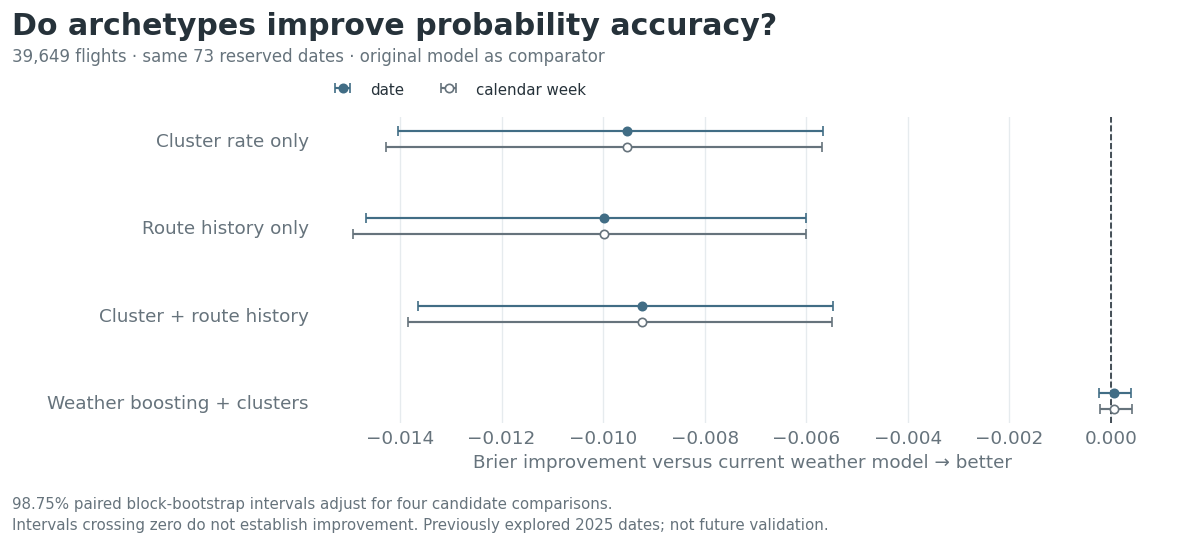

No new candidate passed the predefined global incremental-value gate.
Existing MVP score unchanged. No quoted rate, external data, forced winter label or airport-adaptation claim was added.
Read the model decision ledger for the purpose, development result and assessment result of each model.


In [ ]:
# One concise comparison figure; detailed profiles/tests stay in this appendix.
ak_labels={'cluster_rate':'Cluster rate only','route_rate':'Route history only','cluster_route':'Cluster + route history','weather_cluster':'Weather boosting + clusters'}
fig,ax=plt.subplots(figsize=(10.5,5.2));fig.subplots_adjust(left=.28,right=.96,bottom=.29,top=.78)
for j,c in enumerate(ak_names):
    for unit,offset,filled in [('date',-.09,True),('calendar_week',.09,False)]:
        row=ak_intervals[ak_intervals.candidate.eq(c)&ak_intervals.unit.eq(unit)].iloc[0]
        ax.errorbar(row.Brier_improvement,j+offset,xerr=np.array([[row.Brier_improvement-row.lower_98_75],[row.upper_98_75-row.Brier_improvement]]),fmt='o',color=BLUE if filled else MUTED,mfc=BLUE if filled else 'white',markersize=5,capsize=3,linewidth=1.3,label=unit.replace('_',' ') if j==0 else None)
ax.axvline(0,color=INK,linewidth=1,linestyle='--');ax.set_yticks(range(4),[ak_labels[c] for c in ak_names]);ax.invert_yaxis()
ax.grid(axis='x',color=GRID);ax.tick_params(length=0);ax.set_xlabel('Brier improvement versus current weather model → better')
ax.legend(frameon=False,loc='upper left',bbox_to_anchor=(0,1.16),ncol=2,fontsize=9)
fig.text(.04,.95,'Do archetypes improve probability accuracy?',fontsize=18,weight='bold',color=INK,va='top')
fig.text(.04,.87,f'{len(wt_test_idx):,} flights · same 73 reserved dates · original model as comparator',fontsize=10,color=MUTED)
fig.text(.04,.12,'98.75% paired block-bootstrap intervals adjust for four candidate comparisons.\nIntervals crossing zero do not establish improvement. Previously explored 2025 dates; not future validation.',fontsize=9,color=MUTED,linespacing=1.5)
for ext in ['png','svg']:fig.savefig(AK_DIR/f'archetype_comparison.{ext}',dpi=180)
plt.show();plt.close(fig)
ak_passed=ak_adoption.loc[ak_adoption.global_gate_passed,'candidate'].tolist()
ak_decision={'global_gate_passed_candidates':ak_passed,'active_model':'boosting_both, original probabilities','active_mvp_changed':False,
 'reason':'No new candidate passed the predefined global incremental-value gate.' if not ak_passed else 'Global gate passed; route-specific transfer/ranking validation still required before adoption.',
 'scope':'Schedule-only six-cluster extension using existing notebook data; proposed snow-climatology archetypes not reproduced.',
 'route_transfer_new_candidates':'Not run because global gate failed.' if not ak_passed else 'Required next gate.',
 'quoted_rates_used':False,'fit_uses_carrier_or_outcomes_in_clustering':False,'label_rates_are_supervised':True,
 'fresh_external_validation':False,'optimal_number_of_clusters_claimed':False,
 'airport_archetypes':'Deferred. Outcome-profile clustering is retrospective explanatory segmentation unless outcome aggregation is training-only.',
 'airport_day_isolation_forest':'Deferred. Anomalous days must remain in primary risk/performance evaluation; flag and sensitivity-check them, do not delete genuine disruptions.',
 'climatology_limitation':'Only observed 2025 weather exists in the current notebook. Annual or monthly full-year snow shares cannot be represented as pre-booking historical normals.'}
(AK_DIR/'decision.json').write_text(json.dumps(ak_decision,indent=2))
ak_unique_checks=pd.DataFrame(ak_checks).drop_duplicates().reset_index(drop=True)
ak_save(ak_unique_checks,'validation_checks')
ak_save(pd.DataFrame(ak_alpha_scores).drop_duplicates(),'shrinkage_selection')
ak_save(pd.DataFrame([
 {'id':'AK-D1','decision':'Use existing notebook data only','reason':'Latest user instruction; no external climatology'},
 {'id':'AK-D2','decision':'Use cyclic schedule inputs and six fixed clusters','reason':'Avoid clock wrap-around; k=6 is an explicit design, not discovered optimal k'},
 {'id':'AK-D3','decision':'Nest supervised rate/shrinkage estimation inside training folds','reason':'No self-target or assessment-outcome contamination'},
 {'id':'AK-D4','decision':ak_decision['reason'],'reason':'Development Brier, paired date/week uncertainty and log loss gate'},
 {'id':'AK-D5','decision':'Preserve all legitimate disruption days','reason':'Removing extreme outcomes would bias risk assessment'},
]),'decision_log')
ak_save(pd.DataFrame([
 {'id':'AK-I1','status':'not verified','issue':'Quoted six archetype rates and snow shares lack reproducible evidence in current notebook','treatment':'No quoted number or winter label is used'},
 {'id':'AK-I2','status':'retained limitation','issue':'No prior multi-year/as-of-booking snow climatology','treatment':'Snow-share features excluded; do not claim exact requested winter archetypes reproduced'},
 {'id':'AK-I3','status':'retained limitation','issue':'Repeatedly explored 2025 assessment, observed daily weather and previously selected comparator settings','treatment':'Exploratory incremental study and temporal stress only; no fresh/live validation claim'},
 {'id':'AK-I5','status':'resolved','issue':'Silhouette Euclidean matrix calculation emitted platform RuntimeWarnings','treatment':'Explicit scipy cdist distances with finite/symmetry/diagonal checks; robustness cell rerun; no candidate or probability changes'},
 {'id':'AK-I4','status':'retained limitation','issue':'Stable cluster ordering does not establish calibrated probabilities or a useful exact-flight ranking','treatment':'Evaluate predictive metrics and uncertainty; no causal adaptation claim'},
]),'issue_log')
ak_save(pd.DataFrame([
 {'id':'AK-E1','experiment':'Six-cluster rate; route-only control; route-cluster shrinkage; weather model + distances','design':'Five purged outer folds, nested three-fold alpha selection; identical assessment rows','evidence':'development_metrics.csv; assessment_metrics.csv; paired_brier_intervals.csv'},
 {'id':'AK-E2','experiment':'January-September to October-December stress','design':'Past-only fit; alpha selected with prior Q2/Q3 validation','evidence':'Q4_temporal_metrics.csv; temporal_cluster_profiles.csv'},
 {'id':'AK-E3','experiment':'Overfitting, clustering seed variation, shuffled labels','design':'Training/OOF/test errors, three seeds, one negative-control permutation','evidence':'generalization.csv; cluster_seed_stability.csv; shuffled_label_control.csv'},
]),'experiment_log')
ak_model_ledger=ak_assessment.merge(ak_development[['candidate','Brier']].rename(columns={'Brier':'development_Brier'}),on='candidate')
ak_model_ledger['role']=ak_model_ledger.candidate.map({'baseline':'prevalence control','boosting_schedule':'existing schedule comparator','boosting_both':'retained MVP classifier','cluster_rate':'unsupervised partition + supervised frequency estimate','route_rate':'supervised history-only control','cluster_route':'unsupervised partition + supervised regularized history','weather_cluster':'supervised weather model with target-free cluster distances'})
ak_model_ledger['selected_for_mvp']=ak_model_ledger.candidate.eq('boosting_both');ak_save(ak_model_ledger,'model_decision_ledger')
ak_record={'protocol':ak_protocol,'decision':ak_decision,'technical_checks_passed':int(ak_unique_checks.passed.sum()),'technical_checks_failed':int((~ak_unique_checks.passed).sum()),'development_rows':len(wt_dev_idx),'assessment_rows':len(wt_test_idx),'silhouette_training_sample':ak_silhouette,'original_notebook_sources_preserved':True,'model_retrained_for_comparison_only':True,'software':{'python':sys.version.split()[0],'sklearn':sklearn.__version__,'numpy':np.__version__,'pandas':pd.__version__}}
(AK_DIR/'study_record.json').write_text(json.dumps(ak_record,indent=2))
print(ak_decision['reason']);print('Existing MVP score unchanged. No quoted rate, external data, forced winter label or airport-adaptation claim was added.')
print('Read the model decision ledger for the purpose, development result and assessment result of each model.')


### Interpretation and MVP decision

**Retain the original both-weather gradient boosting probabilities.** This six-cluster experiment does not establish an improvement in the disruption estimate. The result is specific to our schedule-only design, not a claim that every clustering method is unhelpful.

| Method | Development OOF Brier | Same-date assessment Brier | Role / decision |
| --- | ---: | ---: | --- |
| Current weather boosting | 0.078905 | 0.079168 | Retained |
| Cluster rate only | 0.085847 | 0.088688 | Descriptive groups; worse probability accuracy |
| Route-only rate control | 0.086170 | 0.089145 | History-only benchmark; worse accuracy |
| Cluster + route shrinkage | 0.085539 | 0.088394 | Worse than current model |
| Weather boosting + centroid distances | 0.078907 | 0.079097 | Tiny assessment gain, not established |

Lower Brier is better. All assessment entries use **39,649 identical flights**, with clustering, preprocessing and rate fitting excluded from their outcomes. Route shrinkage was selected inside training CV; it is not a manually invented probability blend.

**Why the small gain is insufficient:** boosting + clusters was slightly worse in development. Its assessment Brier improvement was 0.000071, with a 98.75% date-block interval of [-0.000230, 0.000403]; the week interval also crosses zero. We do not switch models using a favorable test point estimate after a failed development gate.

**Overfitting and drift:** augmented boosting training Brier was 0.068835 versus OOF 0.078907; training accuracy alone overstates generalization. On the separate Jan–Sep → Q4 stress, current weather boosting Brier was 0.078566, clusters + route 0.084818, and weather boosting + clusters 0.078553. The augmented Q4 model slightly improves Brier but slightly worsens log loss (0.284575 vs 0.284514). These are previously explored periods, not fresh prospective validation.

**Cluster stability:** adjusted Rand agreement across three alternative seeds ranges from 0.626 to 0.880; six immutable natural flight types are not established. The Jan–Sep highest-rate cluster is not the Q4 highest-rate cluster in this schedule-only fit. A single shuffled-label diagnostic is recorded; it is not a formal permutation test. No legitimate disruption days were removed.

**Business use:** clusters can summarize schedule patterns, but the current evidence does not justify turning their average rates into the MVP score or claiming that they improve that score. New candidates were not transferred into the Boston → Chicago catalog after failing the global gate. The existing route-validated model/cache is unchanged.

**Honest Q&A wording:** “We tested unsupervised schedule archetypes using training-only clustering, then estimated their disruption rates with training labels. They did not demonstrate a reliable improvement over our supervised weather model, so we retained the stronger model.”

**Data boundary:** only this notebook's verified sources were used. No quoted archetype percentage or snow-climatology figure was adopted. Full-year 2025 snow frequencies are retrospective. The primary random-date route rates can use later development dates; only the Q4 stress is past-only by flight date, and booking snapshots/publication lags are still unobserved. Airport risk-profile clusters and airport-day anomaly flags remain optional diagnostics, not unvalidated risk-score components or justification to discard real disruptions.

27 distinct technical checks passed. Statistical adoption gates are separate: all four proposed additions/replacements failed the predeclared global gate. A platform warning in the silhouette distance calculation was resolved with explicit, checked Euclidean distances; archived diagnostic history is retained.
